# ET 261400 · Sequência completa do artigo, do dado ao resultado

**Trabalho:** Fatores técnicos da via na suscetibilidade a descarrilamentos ferroviários: aprendizado de máquina e modelos de linguagem sobre dados abertos.
**Autor:** Fábio Lucien David Maciel (IME, Mestrado em Engenharia de Transportes). **Disciplina:** ET 261400, 2026.2.

Este notebook executa, em ordem e do zero, todos os cálculos que sustentam o short paper. Cada passo traz a especificação, os gates declarados antes do código, o código e o resultado. Ao final, uma tabela reúne todos os gates e as tabelas e figuras do artigo.

## Como executar no Colab

1. Envie o arquivo `et261400_colab.zip` pelo painel de arquivos do Colab (ícone de pasta, à esquerda), ou deixe-o no Google Drive em `MyDrive/ET261400/colab/et261400_colab.zip`.
2. Menu Ambiente de execução → Executar tudo. Tempo esperado: de 120 a 150 minutos no Colab (o passo 10, com os cinco modelos em 30 sorteios, leva cerca de 30).

O pacote traz só dados públicos já processados: células de 1 km das 13 malhas (Declarações de Rede de 2025 e eixo da malha, ANTT), descarrilamentos do RAAF de 2011 a 2025 (ANTT), posição das células no mapa, narrativas da base americana (FRA, Form 54) e os rótulos gravados dos modelos de linguagem. Não há chave de API neste notebook.

## A sequência

| Passo | Notebook de origem | O que faz | Onde entra no artigo |
|---|---|---|---|
| 1 | `15_previsao_malha_em_operacao` | primeira versão do modelo com histórico de acidentes e teste do gradient boosting | Métodos, seção 2.2 (escolha da regressão logística) |
| 2 | `16_acerto_malha_existente` | blocos de 5 anos, ano a ano e teste de vazamento com rótulos embaralhados | Métodos, seção 2.3 (teste de vazamento, 0,49) |
| 3 | `17_grade_de_janelas` | 310 cenários de janelas de calibração e conferência | registro; substituído no artigo pelo passo 21 |
| 4 | `18_taxa_de_acerto_protocolo` | protocolo principal (origem móvel, 3 anos), alarmes falsos, grupos de critérios, resolução e base americana | Tabela 2 e seção 3.3 |
| 5 | `19_sensibilidade_operacao` | com e sem os trechos de tráfego interrompido | seção 3.3 (0,81 com os trechos interrompidos) |
| 6 | `20_por_malha_baixa_operacao` | resultado por malha e sem as malhas de poucos eventos | seção 3.3 (cinco malhas, 0,69) |
| 7 | `21_validacao_temporal_desenhos` | cinco desenhos de validação temporal da literatura, 185 avaliações | Figura 1 e seção 3.2 |
| 8 | `22_artigo_tabelas_figuras` | partição 2011-2020 contra 2021-2025, mapa, taxas por fator e kappa do modelo de linguagem | Figura 2, Tabela 3 e seção 3.3 |
| 9 | `23_teste_geral_periodo_inteiro` | teste geral: todos os acidentes de 2011 a 2025, sem recorte de tempo, com trechos inteiros fora do ajuste | Tabela 2 (intervalos do teste espacial) |
| 10 | `24_testes_finais_modelos` | modelos da aula 6 no mesmo protocolo, matriz de confusão, hiperparâmetros, malha nunca vista e vazamento | Tabela 2 e seção 3.1 |
| 11 | `25_decomposicao_criterios_ear` | decomposição do ganho dos critérios do EAR: pesos aprendidos, AMV e medida contínua | seção 3.1 (medida contínua) |
| 12 | `26_testes_da_revisao` | testes pedidos pela revisão: anos e trechos fora ao mesmo tempo, calibração (Brier) e modelo de linguagem na mesma cobertura do TF-IDF | seções 3.3 e 3.4, Tabelas 1 e 2 |
| 13 | `27_parametros_ear_aferidos` | novos parâmetros do EAR: faixas da FNS e da FICO aferidas com o risco relativo no Brasil e o bloco descarrilado nos EUA, recalibração aninhada | seção 3.2, Figura 1 e Tabela 1 |
| 14 | `28_auditoria_sorteios` | auditoria dos 30 sorteios: integridade da partição, estabilidade, permutação de rótulos e nulo que preserva o agrupamento espacial | nota da Tabela 1 e seção 2.3 |
| 15 | `29_fatores_dentro_das_malhas` | fatores da Declaração de Rede dentro das malhas: classes e regra declaradas antes, Mantel-Haenszel, placebo, Holm e conciliação com o artigo | seção 3.1 |
| 16 | `30_ear_v3_ferrovia_nova` | multiplicadores do EAR e teste como ferrovia nova (cada malha inteira fora), com limites reescolhidos sem a malha testada | seção 3.2 |
| 17 | `31_monte_carlo_posicao` | Monte Carlo do erro de posição (seis cenários), SIMEX e conferência do artefato de pátio | seção 3.2 e Conclusões |

A preparação dos dados (ingestão do RAAF, matriz das Declarações de Rede, curvatura do eixo, células de 1 km e classificação das narrativas pelos modelos de linguagem) está nos notebooks 01 a 14 do repositório; este notebook parte dos arquivos que eles gravam em `data/processed`.

**Declaração de uso de IA (regra da disciplina, três partes).** Ferramentas: Claude (Anthropic), usado pelo autor como assistente de programação a partir das especificações FOCUS registradas neste notebook, e Gemini do Colab quando indicado. Parte do trabalho: geração do código de cada passo e revisão do texto das células. Responsável pelo conteúdo: o autor, que definiu o problema, as fontes, as especificações, os gates e a verificação, e executou o notebook do zero antes de reportar qualquer número.

In [1]:
# === Passo 0: localizar o pacote de dados (Colab) ===
import os, sys, zipfile, time, datetime as dt
T0_GERAL = time.time()
if os.path.exists("/content") and not os.environ.get("ET261400_BASE"):
    if not os.path.exists("/content/et261400_colab.zip") and not os.path.exists("/content/ET261400/data"):
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        origem = "/content/drive/MyDrive/ET261400/colab/et261400_colab.zip"
        assert os.path.exists(origem), "Envie et261400_colab.zip pelo painel de arquivos ou coloque-o em MyDrive/ET261400/colab/"
        import shutil; shutil.copy(origem, "/content/et261400_colab.zip")
    if os.path.exists("/content/et261400_colab.zip"): zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # sempre a versão do pacote enviado
print("início:", dt.datetime.now().isoformat(timespec="seconds"))

início: 2026-11-22T23:40:12


---
# Passo 1 · (notebook 15) Malha em operação: treinar com o passado e prever os anos seguintes

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Foco definido pelo autor (16/11).** O uso principal é a malha existente: com o que se sabe até um ano T (atributos da via e histórico de acidentes), apontar os quilômetros que terão descarrilamento por via nos anos seguintes, inclusive os que ainda não tiveram nenhum.

**Desenho (declarado antes dos resultados).** Janela móvel, sem olhar o futuro: para cada ano de corte T de 2016 a 2022, o modelo é ajustado com o histórico até T−3 para explicar os descarrilamentos de T−2 a T, e depois aplicado com o histórico até T para prever T+1 a T+3. São sete cortes; nenhum dado do período previsto entra no ajuste nem nos atributos. Métricas na malha inteira e também só nos quilômetros que nunca tinham tido descarrilamento por via até T.

**Métodos comparados em todos os cortes.** Regra do EAR (sem ajuste); histórico do próprio quilômetro; histórico do quilômetro, da vizinhança, da linha e da malha (logística); atributos da via sem histórico (modelo M2); atributos mais histórico (logística e gradient boosting, hiperparâmetros fixos).

**Gates.** 2.681 descarrilamentos por via entre 2011 e 2025; janelas de ajuste e de teste disjuntas em todos os cortes; nenhum atributo usa ano posterior a T.

**Onde entra no artigo:** Métodos, seção 2.2 (escolha da regressão logística).

In [2]:
# ---- Passo 1 · notebook 15_previsao_malha_em_operacao ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [3]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
SEED, H = 42, 3
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv")
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]
gate("descarrilamentos por via nas células", len(EV), 2681, source="notebook 11"); gate_between("anos dos eventos", float(EV["ano"].min()), 2011, 2011, source="recorte 2011 a 2025"); gate_between("último ano dos eventos", float(EV["ano"].max()), 2025, 2025, source="recorte 2011 a 2025")
display(EV.groupby("ano").size().to_frame("descarrilamentos por via").T)
idx = pd.Series(np.arange(len(C)), index=C["cel_id"])
def contagem(ev, a0, a1):
    v = np.zeros(len(C)); s = ev[(ev["ano"] >= a0) & (ev["ano"] <= a1)].groupby("cel_id").size(); v[idx[s.index].values] = s.values; return v
DIST = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)]
CURV = ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM + DIST + CURV: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(df, num, cat):
    X = df[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    return pd.concat([X, pd.get_dummies(df[cat], dtype=float)], axis=1).values
X0 = design(C, DIST + CURV + NUM, CAT); LN = C["len_km"].values; fer = np.asarray(C["ferrovia"], dtype=object); LIN = np.asarray(C["ferrovia"] + "|" + C["linha"].astype(str), dtype=object); SEG = np.asarray(C["seg_id"].astype(str), dtype=object); KM = ((C["km_a"] + C["km_b"]) / 2).values
ri, ci = [], []
for l in np.unique(LIN):
    i = np.where(LIN == l)[0]; k = KM[i]; M = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(len(C), len(C))); nviz = np.asarray(W.sum(1)).ravel()
def historico(T):
    """Atributos de histórico com dados de 2011 até o ano T, por ano de observação (comparáveis entre cortes)."""
    assert T <= 2025; n = T - 2010; hv = contagem(EV, 2011, T); ha = contagem(E, 2011, T); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEG)["b"].transform("mean").values, d.groupby(LIN)["b"].transform("mean").values, d.groupby(fer)["b"].transform("mean").values, d.groupby(fer)["hv"].transform("mean").values / n]), b
def cls16(d): return np.select([d <= 300, d <= 600, d <= 1200, d <= 1800], [4, 3, 2, 1], 0)
def rcls16(r_): return np.select([r_ < 500, r_ < 1200, r_ < 2300], [3, 2, 1], 0)
B2 = (0.5 * cls16(C["dmin_patio"].fillna(1e9)) / 4 + 0.5 * rcls16(C["rmin_geo"].fillna(1e6)) / 3).astype(float)
def auc(yy, s, m=None):
    if m is not None: yy, s = yy[m], s[m]
    n1 = yy.sum(); n0_ = len(yy) - n1; return float((rankdata(s)[yy == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0_)) if n1 >= 5 and n0_ >= 5 else np.nan
def auc_dentro(s, yy, m=None):
    a, w = [], []
    for f in np.unique(fer):
        i = (fer == f) if m is None else ((fer == f) & m)
        if yy[i].sum() >= 5 and yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w)) if a else np.nan
def captura(s, evv, p=0.20):
    o = np.lexsort((np.random.default_rng(SEED).random(len(s)), -s)); cum = np.cumsum(LN[o]) / LN.sum(); return float(evv[o][cum <= p].sum() / evv.sum())
def lr(Xtr, ytr, Xte):
    st = StandardScaler().fit(Xtr); return LogisticRegression(C=0.5, max_iter=3000).fit(st.transform(Xtr), ytr).predict_proba(st.transform(Xte))[:, 1]
def gbm(Xtr, ytr, Xte): return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, early_stopping=False, random_state=SEED).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
log_ia("15.1 dados e histórico", "Claude", "FOCUS: histórico por ano de observação até T; vizinhança de 20 km na mesma linha; nada posterior a T", "historico(T), W", "4 gates de contagem e de período")

[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via nas células: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11
[PASS] anos dos eventos: obtido 2011.0, faixa [2011, 2011] | recorte 2011 a 2025
[PASS] último ano dos eventos: obtido 2025.0, faixa [2025, 2025] | recorte 2011 a 2025


ano,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
descarrilamentos por via,324,291,246,214,261,165,185,166,183,128,152,120,112,77,57


In [4]:
L = []
for T in range(2016, 2023):
    tr_a0, tr_a1, te_a0, te_a1 = T - H + 1, T, T + 1, T + H; assert tr_a1 < te_a0 and te_a1 <= 2025
    Htr, _ = historico(T - H); Hte, ja = historico(T); ytr = (contagem(EV, tr_a0, tr_a1) > 0).astype(int); cte = contagem(EV, te_a0, te_a1); yte = (cte > 0).astype(int); novo = ja == 0
    S = {"Regra do EAR (sem ajuste)": B2, "Histórico do próprio km": Hte[:, 0], "Histórico (km, vizinhança, linha, malha)": lr(Htr, ytr, Hte), "Atributos da via, sem histórico (M2)": lr(X0, ytr, X0),
         "Atributos + histórico (logística)": lr(np.column_stack([X0, Htr]), ytr, np.column_stack([X0, Hte])), "Atributos + histórico (gradient boosting)": gbm(np.column_stack([X0, Htr]), ytr, np.column_stack([X0, Hte]))}
    for nome, s in S.items():
        L.append(dict(corte=T, ajuste=f"{tr_a0} a {tr_a1}", previsto=f"{te_a0} a {te_a1}", metodo=nome, atingidas=int(yte.sum()), atingidas_sem_acidente_antes=int(yte[novo].sum()), auc_malha_inteira=auc(yte, s), auc_dentro=auc_dentro(s, yte), captura20=captura(s, cte), auc_km_sem_acidente_antes=auc(yte, s, novo), auc_dentro_km_sem_acidente_antes=auc_dentro(s, yte, novo)))
    print(T, "ok", flush=True)
R_ = pd.DataFrame(L); R_.to_csv(f"{TAB}/15_previsao_por_corte.csv", index=False)
gate("cortes avaliados", int(R_["corte"].nunique()), 7, source="desenho: T de 2016 a 2022")
res = R_.groupby("metodo", sort=False)[["auc_malha_inteira", "auc_dentro", "captura20", "auc_km_sem_acidente_antes", "auc_dentro_km_sem_acidente_antes"]].agg(["mean", "min", "max"]).round(3); display(res); res.to_csv(f"{TAB}/15_previsao_resumo.csv")
c1 = R_.drop_duplicates("corte"); print("por corte: células atingidas no período previsto e, delas, quantas não tinham acidente antes:"); display(c1[["corte", "previsto", "atingidas", "atingidas_sem_acidente_antes"]].T)
display(R_.pivot(index="corte", columns="metodo", values="auc_malha_inteira").round(3))
log_ia("15.2 janela móvel", "Claude", "FOCUS: sete cortes; ajuste no passado, previsão dos 3 anos seguintes; métricas na malha inteira e nos km sem acidente anterior", "15_previsao_*.csv", "gate de número de cortes; asserções de janelas disjuntas")
exportar_registros("15")

2016 ok


2017 ok


2018 ok


2019 ok


2020 ok


2021 ok


... (3 outputs left out)

por corte: células atingidas no período previsto e, delas, quantas não tinham acidente antes:


,0,6,12,18,24,30,36
corte,2016,2017,2018,2019,2020,2021,2022
previsto,2017 a 2019,2018 a 2020,2019 a 2021,2020 a 2022,2021 a 2023,2022 a 2024,2023 a 2025
atingidas,504,450,434,373,365,295,236
atingidas_sem_acidente_antes,409,354,337,282,259,193,152


metodo,Atributos + histórico (gradient boosting),Atributos + histórico (logística),"Atributos da via, sem histórico (M2)","Histórico (km, vizinhança, linha, malha)",Histórico do próprio km,Regra do EAR (sem ajuste)
corte,,,,,,
2016,0.765,0.766,0.746,0.745,0.566,0.599
2017,0.755,0.758,0.741,0.732,0.575,0.579
2018,0.771,0.775,0.751,0.758,0.577,0.584
2019,0.770,0.798,0.764,0.787,0.584,0.565
2020,0.804,0.828,0.799,0.805,0.606,0.570
2021,0.826,0.825,0.800,0.807,0.632,0.570
2022,0.840,0.828,0.805,0.799,0.635,0.569


gates: 5/5 PASS | registros de IA: 2 | exportados em /home/claude/results/tables


---
### Limites

Os atributos da via são os da Declaração de Rede de 2025 em todos os cortes. O registro do RAAF mudou de arquivo em dezembro de 2020, o que pode alterar a cobertura entre períodos; a AUC, por ser de ordenação, é pouco sensível ao nível geral. O histórico só existe em malha em operação; para ferrovia nova vale o cenário B do notebook 14.

In [5]:
print("Passo 1 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 1 concluído em 0.3 min


---
# Passo 2 · (notebook 16) Malha existente: o EAR calibrado acerta onde houve descarrilamento?

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Pergunta fixada pelo autor (16/11).** O estudo é sobre a malha existente. A nota de cada quilômetro usa **somente atributos da via** (critérios do EAR e atributos declarados), como se o trecho fosse novo: o histórico de acidentes do quilômetro **não entra** como atributo. Os acidentes reais servem para duas coisas, em momentos separados: calibrar os pesos em um período e **conferir o acerto** em outro período.

**Desenho (declarado antes dos resultados).**

1. Blocos de cinco anos (2011 a 2015, 2016 a 2020, 2021 a 2025): calibrar em um bloco e conferir em cada um dos outros, para frente e para trás (seis pares).
2. Ano a ano: calibrar com todos os anos anteriores e conferir no ano seguinte (para frente); calibrar com todos os anos posteriores e conferir no ano anterior (para trás).
3. Em cada caso, duas conferências: (a) nos mesmos quilômetros, em outro período; (b) em quilômetros que ficaram fora da calibração (trechos inteiros sorteados em cinco grupos), em outro período. A conferência (b) é a mais exigente: nem o local nem o período foram vistos.

**Métodos sob o mesmo protocolo.** Regra do EAR por faixas (sem calibração); critérios do EAR em medida contínua (logística); critérios mais atributos declarados da via (logística, o modelo do trabalho); os mesmos atributos com gradient boosting. Hiperparâmetros fixos, iguais aos dos notebooks 11 e 14.

**Leitura da AUC como acerto.** Sorteando um quilômetro que teve descarrilamento no período conferido e um que não teve, a AUC é a fração das vezes em que o modelo deu nota maior ao que teve. Vale 0,50 para o acaso e 1,00 para o acerto total.

**Gates.** 2.681 descarrilamentos por via; os três blocos somam 2.681; períodos de calibração e de conferência disjuntos; teste de vazamento com rótulos embaralhados (média de 20 embaralhamentos) entre 0,45 e 0,55.

**Onde entra no artigo:** Métodos, seção 2.3 (teste de vazamento, 0,49).

In [6]:
# ---- Passo 2 · notebook 16_acerto_malha_existente ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [7]:
import warnings; warnings.filterwarnings("ignore")
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv")
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]
gate("descarrilamentos por via nas células", len(EV), 2681, source="notebook 11")
idx = pd.Series(np.arange(len(C)), index=C["cel_id"])
def contagem(a0, a1):
    v = np.zeros(len(C)); s = EV[(EV["ano"] >= a0) & (EV["ano"] <= a1)].groupby("cel_id").size(); v[idx[s.index].values] = s.values; return v
BLOCOS = [(2011, 2015), (2016, 2020), (2021, 2025)]
gate("soma dos três blocos", int(sum(contagem(a, b).sum() for a, b in BLOCOS)), 2681, source="partição do período")
DIST = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)]
CURV = ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM + DIST + CURV: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(df, num, cat):
    X = df[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    return (pd.concat([X, pd.get_dummies(df[cat], dtype=float)], axis=1) if cat else X).values
X_ear = design(C, DIST + CURV, []); X_full = design(C, DIST + CURV + NUM, CAT)
LN = C["len_km"].values; fer = np.asarray(C["ferrovia"], dtype=object); SEGC = pd.factorize(C["seg_id"].astype(str))[0]; NSEG = SEGC.max() + 1
def cls16(d): return np.select([d <= 300, d <= 600, d <= 1200, d <= 1800], [4, 3, 2, 1], 0)
def rcls16(r_): return np.select([r_ < 500, r_ < 1200, r_ < 2300], [3, 2, 1], 0)
B2 = (0.5 * cls16(C["dmin_patio"].fillna(1e9)) / 4 + 0.5 * rcls16(C["rmin_geo"].fillna(1e6)) / 3).astype(float)
def auc(yy, s, m=None):
    if m is not None: yy, s = yy[m], s[m]
    n1 = yy.sum(); n0_ = len(yy) - n1; return float((rankdata(s)[yy == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0_)) if n1 >= 5 and n0_ >= 5 else np.nan
def auc_dentro(s, yy):
    a, w = [], []
    for f in np.unique(fer):
        i = fer == f
        if yy[i].sum() >= 5 and yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w)) if a else np.nan
def captura(s, evv, p=0.20):
    o = np.lexsort((np.random.default_rng(SEED).random(len(s)), -s)); cum = np.cumsum(LN[o]) / LN.sum(); return float(evv[o][cum <= p].sum() / evv.sum())
def lr(Xtr, ytr, Xte):
    st = StandardScaler().fit(Xtr); return LogisticRegression(C=0.5, max_iter=3000).fit(st.transform(Xtr), ytr).predict_proba(st.transform(Xte))[:, 1]
def gbm(Xtr, ytr, Xte): return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, early_stopping=False, random_state=SEED).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
MET = {"Critérios do EAR em medida contínua": (X_ear, lr), "EAR calibrado: critérios + atributos da via (logística)": (X_full, lr), "Critérios + atributos da via (gradient boosting)": (X_full, gbm)}
def avaliar(cal, conf, tag, sorteios=1, metodos=MET, embaralhar=None):
    """cal e conf: (ano inicial, ano final). Devolve linhas para as duas conferências: mesmos km e km fora da calibração."""
    assert cal[1] < conf[0] or conf[1] < cal[0], "períodos sobrepostos"
    ycal = (contagem(*cal) > 0).astype(int); cconf = contagem(*conf); yconf = (cconf > 0).astype(int); novo = ycal == 0; L = []
    if embaralhar is not None: ycal = np.random.default_rng(1000 + embaralhar).permutation(ycal)
    base = dict(cenario=tag, calibra=f"{cal[0]} a {cal[1]}", confere=f"{conf[0]} a {conf[1]}", sentido="para frente" if cal[1] < conf[0] else "para trás", km_com_acidente_no_conferido=int(yconf.sum()), deles_sem_acidente_na_calibracao=int(yconf[novo].sum()))
    def linha(nome, conferencia, s): return dict(base, metodo=nome, conferencia=conferencia, auc=auc(yconf, s), auc_dentro=auc_dentro(s, yconf), captura20=captura(s, cconf), auc_km_sem_acidente_na_calibracao=auc(yconf, s, novo))
    for conferencia in ("mesmos km, outro período", "km fora da calibração, outro período"): L.append(linha("Regra do EAR por faixas (sem calibração)", conferencia, B2))
    for nome, (X, f) in metodos.items():
        L.append(linha(nome, "mesmos km, outro período", f(X, ycal, X)))
        for r in range(sorteios):
            fold = np.random.default_rng(SEED + r).permutation(NSEG)[SEGC] % 5; s = np.zeros(len(C))
            for k in range(5): te = fold == k; s[te] = f(X[~te], ycal[~te], X[te])
            L.append(dict(linha(nome, "km fora da calibração, outro período", s), sorteio=r))
    return L
log_ia("16.1 dados e funções", "Claude", "FOCUS: só atributos da via; acidentes calibram em um período e conferem em outro; conferência em km fora da calibração por grupos de trecho", "avaliar(cal, conf)", "3 gates de contagem")

[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via nas células: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11
[PASS] soma dos três blocos: obtido 2681, esperado 2681 (tol +/-0.0) | partição do período


In [8]:
# 1. Blocos de cinco anos: seis pares, para frente e para trás
L = []
for i, a in enumerate(BLOCOS):
    for j, b in enumerate(BLOCOS):
        if i != j: L += avaliar(a, b, "blocos de 5 anos", sorteios=3); print(a, "->", b, "ok", flush=True)
R1 = pd.DataFrame(L)
gate("pares de blocos avaliados", int(R1[["calibra", "confere"]].drop_duplicates().shape[0]), 6, source="desenho")
LRM = {"EAR calibrado: critérios + atributos da via (logística)": MET["EAR calibrado: critérios + atributos da via (logística)"]}
vz = pd.concat([pd.DataFrame(avaliar(BLOCOS[0], BLOCOS[2], "vazamento", metodos=LRM, embaralhar=k)) for k in range(20)])
vzm = vz[(vz.metodo.str.startswith("EAR calibrado")) & (vz.conferencia.str.startswith("km fora"))]["auc"]; print("vazamento: média", round(vzm.mean(), 3), "| mínimo", round(vzm.min(), 3), "| máximo", round(vzm.max(), 3))
# Restrição acrescentada à especificação em 16/11 (gate loop): na primeira execução o gate usou um único embaralhamento e falhou (0,447, faixa 0,45 a 0,55).
# Com rótulos embaralhados o ajuste devolve uma direção aleatória num espaço de atributos com forte estrutura espacial (a malha), que se correlaciona com a resposta para cima ou para baixo por acaso.
# O teste correto é a média de vários embaralhamentos; a tolerância não mudou.
gate_between("teste de vazamento (média de 20 embaralhamentos), AUC em km fora da calibração", float(vzm.mean()), 0.45, 0.55, source="acaso")
COLS = ["auc", "auc_dentro", "captura20", "auc_km_sem_acidente_na_calibracao"]
r1 = R1.groupby(["conferencia", "metodo"], sort=False)[COLS].agg(["mean", "min", "max"]).round(3); display(r1)
display(R1[R1.metodo.str.startswith("EAR calibrado")].groupby(["conferencia", "calibra", "confere", "sentido"], sort=False)[["auc", "auc_dentro", "captura20", "km_com_acidente_no_conferido", "deles_sem_acidente_na_calibracao"]].mean().round(3))
log_ia("16.2 blocos de 5 anos", "Claude", "FOCUS: seis pares; três sorteios de grupos de trecho", "R1", "gate de pares; teste de vazamento")

(2011, 2015) -> (2016, 2020) ok


(2011, 2015) -> (2021, 2025) ok


(2016, 2020) -> (2011, 2015) ok


(2016, 2020) -> (2021, 2025) ok


(2021, 2025) -> (2011, 2015) ok


(2021, 2025) -> (2016, 2020) ok


[PASS] pares de blocos avaliados: obtido 6, esperado 6 (tol +/-0.0) | desenho


vazamento: média 0.488 | mínimo 0.409 | máximo 0.621
[PASS] teste de vazamento (média de 20 embaralhamentos), AUC em km fora da calibração: obtido 0.4876121228608512, faixa [0.45, 0.55] | acaso


auc  \
                                                                                          mean   
conferencia                          metodo                                                      
mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.584   
km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.584   
mesmos km, outro período             Critérios do EAR em medida contínua                 0.630   
km fora da calibração, outro período Critérios do EAR em medida contínua                 0.625   
mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.738   
km fora da calibração, outro período EAR calibrado: critérios + atributos da via (lo...  0.731   
mesmos km, outro período             Critérios + atributos da via (gradient boosting)    0.755   
km fora da calibração, outro período Critérios + atributos da via (gradient boosting)    0.729   

                                                                                                \
                                                                                           min   
conferencia                          metodo                                                      
mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.567   
km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.567   
mesmos km, outro período             Critérios do EAR em medida contínua                 0.609   
km fora da calibração, outro período Critérios do EAR em medida contínua                 0.598   
mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.700   
km fora da calibração, outro período EAR calibrado: critérios + atributos da via (lo...  0.695   
mesmos km, outro período             Critérios + atributos da via (gradient boosting)    0.704   
km fora da calibração, outro período Critérios + atributos da via (gradient boosting)    0.679   

                                                                                                \
                                                                                           max   
conferencia                          metodo                                                      
mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.596   
km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.596   
mesmos km, outro período             Critérios do EAR em medida contínua                 0.660   
km fora da calibração, outro período Critérios do EAR em medida contínua                 0.656   
mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.801   
km fora da calibração, outro período EAR calibrado: critérios + atributos da via (lo...  0.788   
mesmos km, outro período             Critérios + atributos da via (gradient boosting)    0.823   
km fora da calibração, outro período Critérios + atributos da via (gradient boosting)    0.800   

                                                                                        auc_dentro  \
                                                                                              mean   
conferencia                          metodo                                                          
mesmos km, outro período             Regra do EAR por faixas (sem calibração)                0.583   
km fora da calibração, outro período Regra do EAR por faixas (sem calibração)                0.583   
mesmos km, outro período             Critérios do EAR em medida contínua                     0.643   
km fora da calibração, outro período Critérios do EAR em medida contínua                     0.642   
mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...      0.657   
km fora da calibração, outro período E

,,,,auc,auc_dentro,captura20,km_com_acidente_no_conferido,deles_sem_acidente_na_calibracao
conferencia,calibra,confere,sentido,,,,,
"mesmos km, outro período",2011 a 2015,2016 a 2020,para frente,0.720,0.662,0.472,760.0,641.0
"km fora da calibração, outro período",2011 a 2015,2016 a 2020,para frente,0.718,0.650,0.456,760.0,641.0
"mesmos km, outro período",2011 a 2015,2021 a 2025,para frente,0.742,0.640,0.519,482.0,397.0
"km fora da calibração, outro período",2011 a 2015,2021 a 2025,para frente,0.740,0.630,0.519,482.0,397.0
"mesmos km, outro período",2016 a 2020,2011 a 2015,para trás,0.731,0.663,0.509,1141.0,1022.0
"km fora da calibração, outro período",2016 a 2020,2011 a 2015,para trás,0.722,0.649,0.493,1141.0,1022.0
"mesmos km, outro período",2016 a 2020,2021 a 2025,para frente,0.801,0.690,0.631,482.0,412.0
"km fora da calibração, outro período",2016 a 2020,2021 a 2025,para frente,0.786,0.670,0.590,482.0,412.0
"mesmos km, outro período",2021 a 2025,2011 a 2015,para trás,0.700,0.625,0.416,1141.0,1056.0


In [9]:
# 2. Ano a ano: para frente (anos anteriores -> ano seguinte) e para trás (anos posteriores -> ano anterior)
L = []
for T in range(2016, 2026): L += avaliar((2011, T - 1), (T, T), "ano a ano"); print("frente", T, flush=True)
for T in range(2011, 2021): L += avaliar((T + 1, 2025), (T, T), "ano a ano"); print("trás", T, flush=True)
R2 = pd.DataFrame(L); gate("conferências ano a ano", int(R2[["calibra", "confere"]].drop_duplicates().shape[0]), 20, source="desenho: 10 para frente e 10 para trás")
r2 = R2.groupby(["conferencia", "sentido", "metodo"], sort=False)[COLS].agg(["mean", "min", "max"]).round(3); display(r2)
display(R2[R2.metodo.str.startswith("EAR calibrado")].pivot_table(index=["sentido", "confere"], columns="conferencia", values="auc", sort=False).round(3))
R = pd.concat([R1, R2], ignore_index=True); R.to_csv(f"{TAB}/16_acerto_por_conferencia.csv", index=False)
res = R.groupby(["cenario", "conferencia", "metodo"], sort=False)[COLS].agg(["mean", "min", "max"]).round(3); res.to_csv(f"{TAB}/16_acerto_resumo.csv"); display(res)
log_ia("16.3 ano a ano", "Claude", "FOCUS: 20 conferências anuais, duas direções", "16_acerto_*.csv", "gate de número de conferências")

frente 2016


frente 2017


frente 2018


frente 2019


frente 2020


frente 2021


... (14 outputs left out)

[PASS] conferências ano a ano: obtido 20, esperado 20 (tol +/-0.0) | desenho: 10 para frente e 10 para trás


auc  \
                                                                                                      mean   
conferencia                          sentido     metodo                                                      
mesmos km, outro período             para frente Regra do EAR por faixas (sem calibração)            0.581   
km fora da calibração, outro período para frente Regra do EAR por faixas (sem calibração)            0.581   
mesmos km, outro período             para frente Critérios do EAR em medida contínua                 0.633   
km fora da calibração, outro período para frente Critérios do EAR em medida contínua                 0.625   
mesmos km, outro período             para frente EAR calibrado: critérios + atributos da via (lo...  0.755   
km fora da calibração, outro período para frente EAR calibrado: critérios + atributos da via (lo...  0.748   
mesmos km, outro período             para frente Critérios + atributos da via (gradient boosting)    0.788   
km fora da calibração, outro período para frente Critérios + atributos da via (gradient boosting)    0.749   
mesmos km, outro período             para trás   Regra do EAR por faixas (sem calibração)            0.592   
km fora da calibração, outro período para trás   Regra do EAR por faixas (sem calibração)            0.592   
mesmos km, outro período             para trás   Critérios do EAR em medida contínua                 0.645   
km fora da calibração, outro período para trás   Critérios do EAR em medida contínua                 0.637   
mesmos km, outro período             para trás   EAR calibrado: critérios + atributos da via (lo...  0.744   
km fora da calibração, outro período para trás   EAR calibrado: critérios + atributos da via (lo...  0.733   
mesmos km, outro período             para trás   Critérios + atributos da via (gradient boosting)    0.770   
km fora da calibração, outro período para trás   Critérios + atributos da via (gradient boosting)    0.742   

                                                                                                            \
                                                                                                       min   
conferencia                          sentido     metodo                                                      
mesmos km, outro período             para frente Regra do EAR por faixas (sem calibração)            0.559   
km fora da calibração, outro período para frente Regra do EAR por faixas (sem calibração)            0.559   
mesmos km, outro período             para frente Critérios do EAR em medida contínua                 0.586   
km fora da calibração, outro período para frente Critérios do EAR em medida contínua                 0.588   
mesmos km, outro período             para frente EAR calibrado: critérios + atributos da via (lo...  0.697   
km fora da calibração, outro período para frente EAR calibrado: critérios + atributos da via (lo...  0.698   
mesmos km, outro período             para frente Critérios + atributos da via (gradient boosting)    0.729   
km fora da calibração, outro período para frente Critérios + atributos da via (gradient boosting)    0.700   
mesmos km, outro período             para trás   Regra do EAR por faixas (sem calibração)            0.554   
km fora da calibração, outro período para trás   Regra do EAR por faixas (sem calibração)            0.554   
mesmos km, outro período             para trás   Critérios do EAR em medida contínua                 0.567   
km fora da calibração, outro período para trás   Critérios do EAR em medida contínua                 0.561   
mesmos km, outro período             para trás   EAR calibrado: critérios + atributos da via (lo...  0.707   
km fora da calibração, outro período para trás   EAR calibrado: critérios + atributos da via (lo...  0.696   
mesmos km, outro período             para trás   Critérios + atributos da via (gradient boosting)    0.731   
km fora da calibração, outro per

conferencia              mesmos km, outro período  \
sentido     confere                                 
para frente 2016 a 2016                     0.703   
            2017 a 2017                     0.751   
            2018 a 2018                     0.697   
            2019 a 2019                     0.732   
            2020 a 2020                     0.750   
            2021 a 2021                     0.755   
            2022 a 2022                     0.803   
            2023 a 2023                     0.800   
            2024 a 2024                     0.756   
            2025 a 2025                     0.807   
para trás   2016 a 2016                     0.762   
            2017 a 2017                     0.749   
            2018 a 2018                     0.720   
            2019 a 2019                     0.707   
            2020 a 2020                     0.768   
            2011 a 2011                     0.744   
            2012 a 2012                     0.745   
            2013 a 2013                     0.746   
            2014 a 2014                     0.766   
            2015 a 2015                     0.736   

conferencia              km fora da calibração, outro período  
sentido     confere                                            
para frente 2016 a 2016                                 0.703  
            2017 a 2017                                 0.744  
            2018 a 2018                                 0.698  
            2019 a 2019                                 0.726  
            2020 a 2020                                 0.745  
            2021 a 2021                                 0.742  
            2022 a 2022                                 0.786  
            2023 a 2023                                 0.790  
            2024 a 2024                                 0.750  
            2025 a 2025                                 0.800  
para trás   2016 a 2016                                 0.754  
            2017 a 2017                                 0.741  
            2018 a 2018                                 0.708  
            2019 a 2019                                 0.696  
            2020 a 2020                                 0.743  
            2011 a 2011                                 0.734  
            2012 a 2012                                 0.736  
            2013 a 2013                                 0.738  
            2014 a 2014                                 0.755  
            2015 a 2015                                 0.727

auc  \
                                                                                                           mean   
cenario          conferencia                          metodo                                                      
blocos de 5 anos mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.584   
                 km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.584   
                 mesmos km, outro período             Critérios do EAR em medida contínua                 0.630   
                 km fora da calibração, outro período Critérios do EAR em medida contínua                 0.625   
                 mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.738   
                 km fora da calibração, outro período EAR calibrado: critérios + atributos da via (lo...  0.731   
                 mesmos km, outro período             Critérios + atributos da via (gradient boosting)    0.755   
                 km fora da calibração, outro período Critérios + atributos da via (gradient boosting)    0.729   
ano a ano        mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.587   
                 km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.587   
                 mesmos km, outro período             Critérios do EAR em medida contínua                 0.639   
                 km fora da calibração, outro período Critérios do EAR em medida contínua                 0.631   
                 mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.750   
                 km fora da calibração, outro período EAR calibrado: critérios + atributos da via (lo...  0.741   
                 mesmos km, outro período             Critérios + atributos da via (gradient boosting)    0.779   
                 km fora da calibração, outro período Critérios + atributos da via (gradient boosting)    0.745   

                                                                                                                 \
                                                                                                            min   
cenario          conferencia                          metodo                                                      
blocos de 5 anos mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.567   
                 km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.567   
                 mesmos km, outro período             Critérios do EAR em medida contínua                 0.609   
                 km fora da calibração, outro período Critérios do EAR em medida contínua                 0.598   
                 mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.700   
                 km fora da calibração, outro período EAR calibrado: critérios + atributos da via (lo...  0.695   
                 mesmos km, outro período             Critérios + atributos da via (gradient boosting)    0.704   
                 km fora da calibração, outro período Critérios + atributos da via (gradient boosting)    0.679   
ano a ano        mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.554   
                 km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.554   
                 mesmos km, outro período             Critérios do EAR em medida contínua                 0.567   
                 km fora da calibração, outro período Critérios do EAR em medida contínua                 0.561   
                 mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.697   
                 km fora da calibração, outro período EAR calibrado: critérios + a

In [10]:
# 3. Figura: acerto (AUC) em cada conferência, regra por faixas versus EAR calibrado
import matplotlib.pyplot as plt
INK, ACC, GR = "#1F2933", "#C8102E", "#8A929C"
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for a, conf, tit in [(ax[0], "mesmos km, outro período", "Mesmos km, outro período"), (ax[1], "km fora da calibração, outro período", "Km fora da calibração, outro período")]:
    d = R2[R2.conferencia == conf]; d = d[d.sentido == "para frente"]
    for nome, cor, ls in [("Regra do EAR por faixas (sem calibração)", INK, "--"), ("EAR calibrado: critérios + atributos da via (logística)", ACC, "-")]:
        g = d[d.metodo == nome].groupby("confere", sort=False)["auc"].mean(); a.plot([int(x[:4]) for x in g.index], g.values, ls, color=cor, lw=2.2, marker="o", label=nome.split(":")[0].replace(" (sem calibração)", ""))
    a.axhline(0.5, color=GR, lw=1, ls=":"); a.set_title(tit, fontsize=13, loc="left"); a.set_xlabel("Ano conferido (calibração com os anos anteriores)", fontsize=11); a.set_ylim(0.45, 0.9); a.tick_params(labelsize=11)
    for sp in ("top", "right"): a.spines[sp].set_visible(False)
ax[0].set_ylabel("AUC na malha inteira (0,50 = acaso)", fontsize=11); ax[0].legend(frameon=False, fontsize=11, loc="upper left")
fig.suptitle("Acerto ano a ano na malha existente, somente com atributos da via", fontsize=14, x=0.01, ha="left"); fig.tight_layout(); fig.savefig(f"{FIG}/16_acerto_ano_a_ano.png", dpi=200); plt.show()
exportar_registros("16")

gates: 6/6 PASS | registros de IA: 3 | exportados em /home/claude/results/tables


---
### Limites

Os atributos da via são os da Declaração de Rede de 2025 em todos os períodos. Na conferência nos mesmos quilômetros, o padrão espacial dos acidentes persiste entre períodos e parte do acerto vem dessa persistência; por isso a conferência em quilômetros fora da calibração é reportada ao lado. O registro do RAAF mudou de arquivo em dezembro de 2020. Em anos isolados o número de quilômetros com descarrilamento é pequeno e a AUC oscila mais.

In [11]:
print("Passo 2 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 2 concluído em 7.3 min


---
# Passo 3 · (notebook 17) Malha existente: grade de janelas de calibração e de conferência

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Pedido do autor (16/11).** Varrer janelas de 1, 2, 5 e 10 anos, do início, do meio e do fim do período, para frente e para trás, e ver em que cenário o EAR calibrado identifica melhor os quilômetros que tiveram descarrilamento por via. Sempre na malha existente, onde o acidente real permite conferir.

**Desenho (declarado antes dos resultados).**

1. Janelas adjacentes: calibração de 1, 2, 5 ou 10 anos; conferência de 1, 2 ou 5 anos imediatamente depois (para frente) ou imediatamente antes (para trás); todas as posições possíveis entre 2011 e 2025.
2. Todos os anos disponíveis: calibração com todos os anos anteriores (mínimo de 3) e conferência nos 1, 2 ou 5 anos seguintes; e o espelho para trás.
3. Com defasagem: calibração com todos os anos anteriores e conferência em um único ano, 3 ou 5 anos depois do fim da calibração; e o espelho para trás.

Em todos: nota só com atributos da via (regressão logística do notebook 16, hiperparâmetros fixos); duas conferências (mesmos km; km fora da calibração, por grupos de trecho); regra do EAR por faixas como baseline na mesma conferência. Todos os cenários são reportados; o melhor cenário é descrito, não escolhido como resultado principal.

**Gates.** 2.681 descarrilamentos por via; janelas disjuntas em todos os cenários; teste de vazamento pela média de 20 embaralhamentos entre 0,45 e 0,55.

**Onde entra no artigo:** registro; substituído no artigo pelo passo 21.

In [12]:
# ---- Passo 3 · notebook 17_grade_de_janelas ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [13]:
import warnings; warnings.filterwarnings("ignore")
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from joblib import Parallel, delayed
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv")
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]
gate("descarrilamentos por via nas células", len(EV), 2681, source="notebook 11")
idx = pd.Series(np.arange(len(C)), index=C["cel_id"]); ANOS = list(range(2011, 2026))
CA = np.zeros((len(ANOS), len(C)))
for k, a in enumerate(ANOS):
    s = EV[EV["ano"] == a].groupby("cel_id").size(); CA[k, idx[s.index].values] = s.values
gate("soma da matriz ano x célula", int(CA.sum()), 2681, source="partição por ano")
def contagem(a0, a1): return CA[a0 - 2011:a1 - 2011 + 1].sum(0)
DIST = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)]
CURV = ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM + DIST + CURV: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(df, num, cat):
    X = df[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    return pd.concat([X, pd.get_dummies(df[cat], dtype=float)], axis=1).values
X = StandardScaler().fit_transform(design(C, DIST + CURV + NUM, CAT))  # padronização só usa atributos, nunca a resposta
LN = C["len_km"].values; fer = np.asarray(C["ferrovia"], dtype=object); FERC = pd.factorize(C["ferrovia"])[0]; SEGC = pd.factorize(C["seg_id"].astype(str))[0]; NSEG = SEGC.max() + 1
FOLD = np.random.default_rng(SEED).permutation(NSEG)[SEGC] % 5; DES = np.random.default_rng(SEED).random(len(C))
def cls16(d): return np.select([d <= 300, d <= 600, d <= 1200, d <= 1800], [4, 3, 2, 1], 0)
def rcls16(r_): return np.select([r_ < 500, r_ < 1200, r_ < 2300], [3, 2, 1], 0)
B2 = (0.5 * cls16(C["dmin_patio"].fillna(1e9)) / 4 + 0.5 * rcls16(C["rmin_geo"].fillna(1e6)) / 3).astype(float)
def auc(yy, s):
    n1 = yy.sum(); n0_ = len(yy) - n1; return float((rankdata(s)[yy == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0_)) if n1 >= 5 and n0_ >= 5 else np.nan
def auc_dentro(s, yy):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f
        if yy[i].sum() >= 5 and yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w)) if a else np.nan
def captura(s, evv, p=0.20):
    o = np.lexsort((DES, -s)); cum = np.cumsum(LN[o]) / LN.sum(); return float(evv[o][cum <= p].sum() / evv.sum())
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
def cenario(tipo, cal, conf, embaralhar=None):
    assert cal[1] < conf[0] or conf[1] < cal[0], "janelas sobrepostas"
    ycal = (contagem(*cal) > 0).astype(int); cconf = contagem(*conf); yconf = (cconf > 0).astype(int)
    if ycal.sum() < 20 or yconf.sum() < 20: return []
    if embaralhar is not None: ycal = np.random.default_rng(1000 + embaralhar).permutation(ycal)
    base = dict(tipo=tipo, cal_ini=cal[0], cal_fim=cal[1], conf_ini=conf[0], conf_fim=conf[1], anos_calibracao=cal[1] - cal[0] + 1, anos_conferencia=conf[1] - conf[0] + 1, sentido="para frente" if cal[1] < conf[0] else "para trás",
                defasagem=(conf[0] - cal[1] - 1) if cal[1] < conf[0] else (cal[0] - conf[1] - 1), km_com_acidente_calibracao=int(ycal.sum()), km_com_acidente_conferido=int(yconf.sum()))
    def linha(nome, conferencia, s): return dict(base, metodo=nome, conferencia=conferencia, auc=auc(yconf, s), auc_dentro=auc_dentro(s, yconf), captura20=captura(s, cconf))
    s1 = lr(X, ycal, X); s2 = np.zeros(len(C))
    for k in range(5): te = FOLD == k; s2[te] = lr(X[~te], ycal[~te], X[te])
    return [linha("Regra do EAR por faixas", "mesmos km", B2), linha("Regra do EAR por faixas", "km fora da calibração", B2), linha("EAR calibrado (atributos da via)", "mesmos km", s1), linha("EAR calibrado (atributos da via)", "km fora da calibração", s2)]
J = []
for L_ in (1, 2, 5, 10):
    for M_ in (1, 2, 5):
        for a in range(2011, 2026 - L_ - M_ + 1): J.append(("janelas adjacentes", (a, a + L_ - 1), (a + L_, a + L_ + M_ - 1)))
        for a in range(2011 + M_, 2026 - L_ + 1): J.append(("janelas adjacentes", (a, a + L_ - 1), (a - M_, a - 1)))
for M_ in (1, 2, 5):
    for T in range(2014, 2026 - M_ + 1): J.append(("todos os anos disponíveis", (2011, T - 1), (T, T + M_ - 1)))
    for T in range(2010 + M_, 2023): J.append(("todos os anos disponíveis", (T + 1, 2025), (T - M_ + 1, T)))
for g in (3, 5):
    for T in range(2014, 2026 - g + 1): J.append(("com defasagem", (2011, T - 1), (T + g - 1, T + g - 1)))
    for T in range(2010 + g, 2023): J.append(("com defasagem", (T + 1, 2025), (T - g + 1, T - g + 1)))
print("cenários declarados:", len(J)); gate_between("número de cenários", float(len(J)), 250, 400, source="desenho")
log_ia("17.1 grade declarada", "Claude", "FOCUS: grade de janelas adjacentes, todos os anos e defasagem; para frente e para trás; só atributos da via", "lista J", "3 gates de contagem; gate do número de cenários")

[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via nas células: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11
[PASS] soma da matriz ano x célula: obtido 2681, esperado 2681 (tol +/-0.0) | partição por ano
cenários declarados: 310
[PASS] número de cenários: obtido 310.0, faixa [250, 400] | desenho


In [14]:
import time; t0 = time.time()
OUT = Parallel(n_jobs=2, batch_size=4)(delayed(cenario)(*j) for j in J); R = pd.DataFrame([l for o in OUT for l in o]); print("minutos:", round((time.time() - t0) / 60, 1), "| linhas:", len(R), "| cenários avaliados:", len(R) // 4)
R.to_csv(f"{TAB}/17_grade_por_cenario.csv", index=False)
vz = [cenario("vazamento", (2011, 2015), (2021, 2025), embaralhar=k) for k in range(20)]; vzm = pd.Series([l["auc"] for o in vz for l in o if l["metodo"].startswith("EAR calibrado") and l["conferencia"] == "km fora da calibração"])
print("vazamento: média", round(vzm.mean(), 3), "| mínimo", round(vzm.min(), 3), "| máximo", round(vzm.max(), 3)); gate_between("teste de vazamento (média de 20 embaralhamentos)", float(vzm.mean()), 0.45, 0.55, source="acaso")
M = ["auc", "auc_dentro", "captura20"]
print("== Geral: todos os cenários =="); g0 = R.groupby(["metodo", "conferencia"], sort=False)[M].agg(["mean", "min", "max"]).round(3); display(g0)
print("== Por tipo e sentido =="); g1 = R.groupby(["tipo", "sentido", "metodo", "conferencia"], sort=False)[M].mean().round(3); g1["n"] = R.groupby(["tipo", "sentido", "metodo", "conferencia"], sort=False).size(); display(g1)
A = R[(R.tipo == "janelas adjacentes") & (R.metodo.str.startswith("EAR calibrado"))]
print("== Janelas adjacentes: AUC por anos de calibração (linhas) e de conferência (colunas) ==")
for conf in ("mesmos km", "km fora da calibração"):
    for sen in ("para frente", "para trás"): print(conf, "|", sen); display(A[(A.conferencia == conf) & (A.sentido == sen)].pivot_table(index="anos_calibracao", columns="anos_conferencia", values="auc").round(3))
print("== AUC por ano final da janela conferida (para frente, km fora da calibração) =="); display(R[(R.sentido == "para frente") & (R.conferencia == "km fora da calibração")].pivot_table(index="conf_fim", columns="metodo", values="auc").round(3))
res = R.groupby(["tipo", "sentido", "anos_calibracao", "anos_conferencia", "defasagem", "metodo", "conferencia"], sort=False)[M].agg(["mean", "min", "max", "count"]).round(3); res.to_csv(f"{TAB}/17_grade_resumo.csv")
gan = R.pivot_table(index=["tipo", "cal_ini", "cal_fim", "conf_ini", "conf_fim", "conferencia"], columns="metodo", values="auc"); d = gan["EAR calibrado (atributos da via)"] - gan["Regra do EAR por faixas"]
print("EAR calibrado acima da regra por faixas em", int((d > 0).sum()), "de", len(d), "comparações; diferença média", round(d.mean(), 3), "| mínima", round(d.min(), 3), "| máxima", round(d.max(), 3))
top = R[R.metodo.str.startswith("EAR calibrado") & (R.conferencia == "km fora da calibração")].sort_values("auc", ascending=False); print("== Dez melhores e dez piores cenários (km fora da calibração) =="); display(top.head(10)[["tipo", "cal_ini", "cal_fim", "conf_ini", "conf_fim", "km_com_acidente_conferido", "auc", "auc_dentro", "captura20"]]); display(top.tail(10)[["tipo", "cal_ini", "cal_fim", "conf_ini", "conf_fim", "km_com_acidente_conferido", "auc", "auc_dentro", "captura20"]])
log_ia("17.2 grade executada", "Claude", "FOCUS: todos os cenários reportados; melhor cenário descrito, não escolhido como resultado principal", "17_grade_*.csv", "gate de vazamento por média de 20 embaralhamentos")
exportar_registros("17")

minutos: 1.1 | linhas: 1240 | cenários avaliados: 310


vazamento: média 0.48 | mínimo 0.395 | máximo 0.619
[PASS] teste de vazamento (média de 20 embaralhamentos): obtido 0.48002879246904406, faixa [0.45, 0.55] | acaso
== Geral: todos os cenários ==


auc                \
                                                         mean    min    max   
metodo                           conferencia                                  
Regra do EAR por faixas          mesmos km              0.587  0.554  0.631   
                                 km fora da calibração  0.587  0.554  0.631   
EAR calibrado (atributos da via) mesmos km              0.750  0.661  0.853   
                                 km fora da calibração  0.722  0.648  0.822   

                                                       auc_dentro         \
                                                             mean    min   
metodo                           conferencia                               
Regra do EAR por faixas          mesmos km                  0.584  0.550   
                                 km fora da calibração      0.584  0.550   
EAR calibrado (atributos da via) mesmos km                  0.671  0.616   
                                 km fora da calibração      0.626  0.519   

                                                              captura20  \
                                                          max      mean   
metodo                           conferencia                              
Regra do EAR por faixas          mesmos km              0.633     0.290   
                                 km fora da calibração  0.633     0.290   
EAR calibrado (atributos da via) mesmos km              0.717     0.530   
                                 km fora da calibração  0.684     0.481   

                                                                      
                                                          min    max  
metodo                           conferencia                          
Regra do EAR por faixas          mesmos km              0.217  0.364  
                                 km fora da calibração  0.217  0.364  
EAR calibrado (atributos da via) mesmos km              0.361  0.732  
                                 km fora da calibração  0.328  0.714

== Por tipo e sentido ==


auc  \
tipo                      sentido     metodo                           conferencia                    
janelas adjacentes        para frente Regra do EAR por faixas          mesmos km              0.584   
                                                                       km fora da calibração  0.584   
                                      EAR calibrado (atributos da via) mesmos km              0.761   
                                                                       km fora da calibração  0.731   
                          para trás   Regra do EAR por faixas          mesmos km              0.590   
                                                                       km fora da calibração  0.590   
                                      EAR calibrado (atributos da via) mesmos km              0.747   
                                                                       km fora da calibração  0.715   
todos os anos disponíveis para frente Regra do EAR por faixas          mesmos km              0.586   
                                                                       km fora da calibração  0.586   
                                      EAR calibrado (atributos da via) mesmos km              0.746   
                                                                       km fora da calibração  0.727   
                          para trás   Regra do EAR por faixas          mesmos km              0.590   
                                                                       km fora da calibração  0.590   
                                      EAR calibrado (atributos da via) mesmos km              0.744   
                                                                       km fora da calibração  0.718   
com defasagem             para frente Regra do EAR por faixas          mesmos km              0.577   
                                                                       km fora da calibração  0.577   
                                      EAR calibrado (atributos da via) mesmos km              0.743   
                                                                       km fora da calibração  0.727   
                          para trás   Regra do EAR por faixas          mesmos km              0.593   
                                                                       km fora da calibração  0.593   
                                      EAR calibrado (atributos da via) mesmos km              0.723   
                                                                       km fora da calibração  0.701   

                                                                                              auc_dentro  \
tipo                      sentido     metodo                           conferencia                         
janelas adjacentes        para frente Regra do EAR por faixas          mesmos km                   0.580   
                                                                       km fora da calibração       0.580   
                                      EAR calibrado (atributos da via) mesmos km                   0.676   
                                                                       km fora da calibração       0.626   
                          para trás   Regra do EAR por faixas          mesmos km                   0.588   
                                                                       km fora da calibração       0.588   
                                      EAR calibrado (atributos da via) mesmos km                   0.670   
                                                                       km fora da calibração       0.626   
todos os anos disponíveis para frente Regra do EAR por faixas          mesmos km                   0.582   
                                                                       km fora da calibração       0.582   
                                      EAR calibrado (atributos da via) mesmos km                   0.669   
             

== Janelas adjacentes: AUC por anos de calibração (linhas) e de conferência (colunas) ==
mesmos km | para frente


... (9 outputs left out)

EAR calibrado acima da regra por faixas em 620 de 620 comparações; diferença média 0.149 | mínima 0.05 | máxima 0.28
== Dez melhores e dez piores cenários (km fora da calibração) ==


,tipo,cal_ini,cal_fim,conf_ini,conf_fim,km_com_acidente_conferido,auc,auc_dentro,captura20
399,janelas adjacentes,2024,2025,2023,2023,111,0.821998,0.657323,0.714286
607,janelas adjacentes,2020,2024,2025,2025,55,0.797488,0.615002,0.561404
599,janelas adjacentes,2018,2022,2023,2023,111,0.797375,0.616399,0.616071
787,janelas adjacentes,2015,2024,2025,2025,55,0.796553,0.650638,0.543860
107,janelas adjacentes,2024,2024,2023,2023,111,0.793424,0.630398,0.660714
495,janelas adjacentes,2024,2025,2022,2023,225,0.792902,0.644746,0.629310
779,janelas adjacentes,2013,2022,2023,2023,111,0.790876,0.634358,0.580357
347,janelas adjacentes,2023,2024,2025,2025,55,0.788406,0.621284,0.578947
215,janelas adjacentes,2025,2025,2023,2024,183,0.788362,0.616687,0.634921
675,janelas adjacentes,2017,2021,2022,2023,225,0.787444,0.635195,0.577586


,tipo,cal_ini,cal_fim,conf_ini,conf_fim,km_com_acidente_conferido,auc,auc_dentro,captura20
199,janelas adjacentes,2021,2021,2019,2020,297,0.664945,0.586771,0.411576
1227,com defasagem,2020,2025,2015,2015,238,0.664014,0.622477,0.390805
283,janelas adjacentes,2022,2022,2017,2021,745,0.661293,0.554208,0.373464
1171,com defasagem,2022,2025,2019,2019,177,0.660479,0.618747,0.338798
195,janelas adjacentes,2020,2020,2018,2019,335,0.660406,0.580997,0.363897
143,janelas adjacentes,2018,2018,2019,2020,297,0.660230,0.595028,0.408360
1099,com defasagem,2011,2013,2016,2016,162,0.657341,0.587977,0.363636
91,janelas adjacentes,2020,2020,2019,2019,177,0.654058,0.591659,0.327869
259,janelas adjacentes,2016,2016,2011,2015,1141,0.650992,0.597164,0.394461
1179,com defasagem,2011,2013,2018,2018,165,0.648229,0.581663,0.379518


gates: 5/5 PASS | registros de IA: 2 | exportados em /home/claude/results/tables


---
### Limites

Os atributos da via são os da Declaração de Rede de 2025 em todas as janelas. Cenários com janelas curtas têm poucos quilômetros com descarrilamento e oscilam mais; foram descartados os cenários com menos de 20 quilômetros atingidos na calibração ou na conferência. Os cenários se sobrepõem no tempo e não são independentes entre si: a média resume a grade, não é um intervalo de confiança.

In [15]:
print("Passo 3 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 3 concluído em 1.2 min


---
# Passo 4 · (notebook 18) Taxa de acerto na malha existente: protocolo principal, alarmes falsos, critérios e resolução

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Pergunta do autor (16/11).** Como apurar, de forma estatisticamente defensável, a taxa de acerto do EAR calibrado na malha existente, se ela varia conforme o ano e a janela? E o que falta para aumentá-la, sem alarme falso?

**Protocolo principal (declarado antes dos resultados): origem móvel, para frente.** É o desenho de avaliação fora da amostra usado em previsão (Tashman, 2000) e a lógica dos testes de consistência entre períodos usados para comparar métodos de identificação de pontos críticos (Cheng e Washington, 2008). Para cada ano de origem T, o modelo é calibrado com os descarrilamentos de 2011 a T e conferido contra os descarrilamentos de T+1 a T+H. Horizonte principal H = 3 anos (origens de 2015 a 2022, oito conferências); sensibilidade com H = 1 e H = 5. O resultado é a média das origens, com a faixa e um intervalo de 95% por reamostragem de linhas inteiras.

**Duas medidas, porque respondem a perguntas diferentes.**

1. AUC: de cada 100 pares (um quilômetro com descarrilamento no período conferido, um sem), em quantos o quilômetro com descarrilamento recebeu a nota maior. Não depende de corte.
2. Taxa de acerto com corte de área (Chainey, Tompson e Uhlig, 2008): marcando os X% de quilômetros de maior nota, que percentual dos descarrilamentos do período conferido cai neles; e o índice de acurácia de previsão, que é essa taxa dividida por X. Reportada para X de 10, 20, 30, 40 e 50.

**Alarme falso.** Quilômetro marcado que não teve descarrilamento no horizonte. Como o evento é raro, a maior parte dos quilômetros marcados não terá evento em três anos, qualquer que seja o modelo; por isso o notebook reporta a concentração de risco (taxa nos marcados dividida pela taxa nos não marcados) e a repete só nos quilômetros que ainda não tinham descarrilamento até T.

**Métodos sob o mesmo protocolo.** Regra do EAR por faixas; Dummy da taxa da malha; critérios do EAR em medida contínua; EAR calibrado só com atributos da via; EAR calibrado mais histórico de acidentes da vizinhança, da linha e da malha (só possível em malha existente).

**Análises complementares, todas declaradas e todas reportadas.** (a) Grupos de critérios: o que cada grupo de atributos acrescenta aos critérios do EAR e o que se perde ao retirá-lo. (b) Resolução: a mesma conferência em blocos de 1, 2, 5 e 10 km, motivada pela incerteza de posição do RAAF (28% dos eventos em quilômetro inteiro). (c) Base americana (FRA): causas por tipo de via, para verificar se há critério não considerado.

**Gates.** 20.936 células; 2.681 descarrilamentos por via; janelas de calibração e de conferência disjuntas; oito origens no horizonte principal.

**Onde entra no artigo:** Tabela 2 e seção 3.3.

In [16]:
# ---- Passo 4 · notebook 18_taxa_de_acerto_protocolo ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [17]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv")
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]
gate("descarrilamentos por via nas células", len(EV), 2681, source="notebook 11")
idx = pd.Series(np.arange(len(C)), index=C["cel_id"]); N = len(C)
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E)
def cont(M_, a0, a1): return M_[a0 - 2011:a1 - 2011 + 1].sum(0)
GR = {"distância a pátio e AMV (EAR)": (["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)], []),
      "raio de curva (EAR)": (["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)], []),
      "superestrutura: trilho, dormente, fixação": (["taxa_dorm"], ["dormente", "perfil_trilho", "fixacao"]),
      "tráfego: capacidade vinculada, dias, linhas": (["cap_vinc", "dias_op"], ["sentido", "n_linhas"]),
      "carga por eixo e velocidade": (["carga_eixo_t", "vma_carregado"], []),
      "rampa e raio declarados": (["rampa_max_pct", "raio_min_m"], []),
      "sinalização e controle": ([], ["sinalizacao", "controle_circ"]),
      "bitola e gabarito": (["gab_vert_m", "gab_horiz_m"], ["bitola"])}
for num, cat in GR.values():
    for c in num: C[c] = pd.to_numeric(C[c], errors="coerce")
    for c in cat: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(grupos):
    num = [c for g in grupos for c in GR[g][0]]; cat = [c for g in grupos for c in GR[g][1]]; X = C[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    X = pd.concat([X, pd.get_dummies(C[cat], dtype=float)], axis=1) if cat else X; return StandardScaler().fit_transform(X.values)
TODOS = list(GR); EARG = TODOS[:2]; X0 = design(TODOS); XE = design(EARG)
LN = C["len_km"].values; FERC = pd.factorize(C["ferrovia"])[0]; LIN = np.asarray(C["ferrovia"] + "|" + C["linha"].astype(str), dtype=object); LINC = pd.factorize(LIN)[0]; SEG = np.asarray(C["seg_id"].astype(str), dtype=object); KM = ((C["km_a"] + C["km_b"]) / 2).values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(T):
    """Histórico com dados de 2011 até T, por ano de observação. Nada posterior a T."""
    n = T - 2010; hv = cont(CV_, 2011, T); ha = cont(CA_, 2011, T); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    H_ = np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEG)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
    return H_, b
def cls16(d): return np.select([d <= 300, d <= 600, d <= 1200, d <= 1800], [4, 3, 2, 1], 0)
def rcls16(r_): return np.select([r_ < 500, r_ < 1200, r_ < 2300], [3, 2, 1], 0)
B2 = (0.5 * cls16(C["dmin_patio"].fillna(1e9)) / 4 + 0.5 * rcls16(C["rmin_geo"].fillna(1e6)) / 3).astype(float)
def auc(yy, s):
    n1 = yy.sum(); n0_ = len(yy) - n1; return float((rankdata(s)[yy == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0_)) if n1 >= 5 and n0_ >= 5 else np.nan
def auc_dentro(s, yy, grp=FERC):
    a, w = [], []
    for f in np.unique(grp):
        i = grp == f
        if yy[i].sum() >= 5 and yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w)) if a else np.nan
DES = np.random.default_rng(SEED).random(N)
def ordem(s): return np.lexsort((DES, -s))
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
def notas(T, H):
    """Notas de cada método com dados até T; resposta conferida de T+1 a T+H."""
    assert T + H <= 2025; ycal = (cont(CV_, 2011, T) > 0).astype(int); cconf = cont(CV_, T + 1, T + H); yconf = (cconf > 0).astype(int)
    Htr, _ = historico(T - H); Hte, ja = historico(T); ytr = (cont(CV_, T - H + 1, T) > 0).astype(int); st = StandardScaler().fit(Htr)
    taxa = pd.Series(ycal).groupby(FERC).transform("mean").values
    S = {"Regra do EAR por faixas": B2, "Dummy: taxa da malha até T": taxa, "Critérios do EAR em medida contínua": lr(XE, ycal, XE), "EAR calibrado (atributos da via)": lr(X0, ycal, X0),
         "EAR calibrado + histórico de acidentes": lr(np.column_stack([X0, st.transform(Htr)]), ytr, np.column_stack([X0, st.transform(Hte)]))}
    return S, yconf, cconf, ja == 0
CORTES = (0.10, 0.20, 0.30, 0.40, 0.50)
def medidas(s, yconf, cconf, novo):
    o = ordem(s); cum = np.cumsum(LN[o]) / LN.sum(); d = dict(auc=auc(yconf, s), auc_dentro=auc_dentro(s, yconf), auc_km_sem_acidente_ate_T=auc(yconf[novo], s[novo]))
    for p in CORTES:
        m = np.zeros(N, bool); m[o[cum <= p]] = True; d[f"acerto_{int(p*100)}"] = float(cconf[m].sum() / cconf.sum()); d[f"km_atingidos_{int(p*100)}"] = float(yconf[m].sum() / yconf.sum())
        if p == 0.20:
            d["alarme_falso_20"] = float(1 - yconf[m].mean()); d["concentracao_20"] = float(yconf[m].mean() / yconf[~m].mean())
            a, b = yconf[m & novo].mean(), yconf[~m & novo].mean(); d["taxa_marcados_sem_acidente_ate_T"] = float(a); d["taxa_nao_marcados_sem_acidente_ate_T"] = float(b); d["concentracao_20_sem_acidente_ate_T"] = float(a / b)
    return d
log_ia("18.1 dados e funções", "Claude", "FOCUS: origem móvel para frente; AUC e taxa de acerto com corte de área; alarme falso e concentração de risco", "notas(T, H), medidas()", "2 gates de contagem")

[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via nas células: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


In [18]:
# 1. Protocolo principal e sensibilidade ao horizonte
L, GUARDA = [], {}
for H in (3, 1, 5):
    for T in range(2015, 2026 - H):
        if T - H < 2012: continue
        S, yconf, cconf, novo = notas(T, H); GUARDA[(H, T)] = (S, yconf, cconf, novo)
        for nome, s in S.items(): L.append(dict(horizonte=H, origem=T, calibra=f"2011 a {T}", confere=f"{T+1} a {T+H}", metodo=nome, km_com_descarrilamento=int(yconf.sum()), deles_sem_acidente_ate_T=int(yconf[novo].sum()), **medidas(s, yconf, cconf, novo)))
    print("horizonte", H, "ok", flush=True)
R = pd.DataFrame(L); R.to_csv(f"{TAB}/18_origem_movel_por_origem.csv", index=False)
gate("origens no horizonte principal (3 anos)", int(R[R.horizonte == 3]["origem"].nunique()), 8, source="desenho: T de 2015 a 2022")
P = R[R.horizonte == 3]; COL = ["auc", "auc_dentro", "auc_km_sem_acidente_ate_T", "acerto_10", "acerto_20", "acerto_30", "acerto_40", "acerto_50", "alarme_falso_20", "concentracao_20", "concentracao_20_sem_acidente_ate_T"]
print("== PROTOCOLO PRINCIPAL: horizonte de 3 anos, 8 origens =="); p1 = P.groupby("metodo", sort=False)[COL].agg(["mean", "min", "max"]).round(3); display(p1.T)
print("== Por origem (AUC na malha inteira) =="); display(P.pivot(index="confere", columns="metodo", values="auc").round(3))
print("== Sensibilidade ao horizonte (média das origens) =="); display(R.groupby(["horizonte", "metodo"], sort=False)[["auc", "auc_dentro", "acerto_20", "acerto_40", "concentracao_20"]].mean().round(3))
# intervalo de 95% por reamostragem de linhas inteiras (notas fixas; 300 reamostragens)
rng = np.random.default_rng(SEED); cel_lin = [np.where(LINC == l)[0] for l in range(LINC.max() + 1)]; B = {m: [] for m in P.metodo.unique()}; Dif = []
for b in range(300):
    ii = np.concatenate([cel_lin[l] for l in rng.integers(0, len(cel_lin), len(cel_lin))]); v = {m: [] for m in B}
    for T in range(2015, 2023):
        S, yconf, _, _ = GUARDA[(3, T)]
        for m in B: v[m].append(auc(yconf[ii], S[m][ii]))
    for m in B: B[m].append(np.nanmean(v[m]))
    Dif.append(B["EAR calibrado (atributos da via)"][-1] - B["Regra do EAR por faixas"][-1])
ic = pd.DataFrame({m: dict(media=P[P.metodo == m]["auc"].mean(), ic95_inf=np.percentile(B[m], 2.5), ic95_sup=np.percentile(B[m], 97.5)) for m in B}).T.round(3); display(ic); ic.to_csv(f"{TAB}/18_ic95_auc.csv")
print("EAR calibrado menos regra: IC 95% de", round(np.percentile(Dif, 2.5), 3), "a", round(np.percentile(Dif, 97.5), 3))
p1.to_csv(f"{TAB}/18_protocolo_principal.csv")
log_ia("18.2 protocolo principal", "Claude", "FOCUS: 8 origens, horizonte de 3 anos; sensibilidade 1 e 5 anos; IC por reamostragem de linhas", "18_origem_movel_por_origem.csv, 18_protocolo_principal.csv, 18_ic95_auc.csv", "gate de número de origens")

horizonte 3 ok


horizonte 1 ok


horizonte 5 ok


[PASS] origens no horizonte principal (3 anos): obtido 8, esperado 8 (tol +/-0.0) | desenho: T de 2015 a 2022
== PROTOCOLO PRINCIPAL: horizonte de 3 anos, 8 origens ==


metodo                                   Regra do EAR por faixas  \
auc                                mean                    0.580   
                                   min                     0.565   
                                   max                     0.600   
auc_dentro                         mean                    0.577   
                                   min                     0.560   
                                   max                     0.597   
auc_km_sem_acidente_ate_T          mean                    0.577   
                                   min                     0.564   
                                   max                     0.589   
acerto_10                          mean                    0.169   
                                   min                     0.146   
                                   max                     0.213   
acerto_20                          mean                    0.263   
                                   min                     0.230   
                                   max                     0.322   
acerto_30                          mean                    0.401   
                                   min                     0.355   
                                   max                     0.463   
acerto_40                          mean                    0.507   
                                   min                     0.460   
                                   max                     0.560   
acerto_50                          mean                    0.627   
                                   min                     0.592   
                                   max                     0.669   
alarme_falso_20                    mean                    0.975   
                                   min                     0.963   
                                   max                     0.986   
concentracao_20                    mean                    1.449   
                                   min                     1.221   
                                   max                     1.863   
concentracao_20_sem_acidente_ate_T mean                    1.429   
                                   min                     1.243   
                                   max                     1.826   

metodo                                   Dummy: taxa da malha até T  \
auc                                mean                       0.688   
                                   min                        0.602   
                                   max                        0.741   
auc_dentro                         mean                       0.500   
                                   min                        0.500   
                                   max                        0.500   
auc_km_sem_acidente_ate_T          mean                       0.685   
                                   min                        0.602   
                                   max                        0.738   
acerto_10                          mean                       0.260   
                                   min                        0.157   
                                   max                        0.325   
acerto_20                          mean                       0.357   
                                   min                        0.267   
                                   max                        0.435   
acerto_30                          mean                       0.509   
                                   min                        0.374   
                                   max                        0.588   
acerto_40                          mean                       0.657   
                                   min                        0.442   
                                   max                        0.760   
acerto_50                          mean                       0.809   
                                   min                

== Por origem (AUC na malha inteira) ==


metodo,Critérios do EAR em medida contínua,Dummy: taxa da malha até T,EAR calibrado (atributos da via),EAR calibrado + histórico de acidentes,Regra do EAR por faixas
confere,,,,,
2016 a 2018,0.651,0.602,0.714,0.748,0.600
2017 a 2019,0.660,0.644,0.726,0.766,0.599
2018 a 2020,0.634,0.655,0.722,0.758,0.579
2019 a 2021,0.638,0.684,0.740,0.775,0.584
2020 a 2022,0.623,0.731,0.761,0.798,0.565
2021 a 2023,0.631,0.741,0.779,0.828,0.570
2022 a 2024,0.633,0.728,0.789,0.825,0.570
2023 a 2025,0.620,0.721,0.786,0.828,0.569


== Sensibilidade ao horizonte (média das origens) ==


auc  auc_dentro  \
horizonte metodo                                                      
3         Regra do EAR por faixas                 0.580       0.577   
          Dummy: taxa da malha até T              0.688       0.500   
          Critérios do EAR em medida contínua     0.636       0.646   
          EAR calibrado (atributos da via)        0.752       0.665   
          EAR calibrado + histórico de acidentes  0.791       0.706   
1         Regra do EAR por faixas                 0.581       0.576   
          Dummy: taxa da malha até T              0.686       0.500   
          Critérios do EAR em medida contínua     0.633       0.643   
          EAR calibrado (atributos da via)        0.755       0.673   
          EAR calibrado + histórico de acidentes  0.780       0.698   
5         Regra do EAR por faixas                 0.574       0.573   
          Dummy: taxa da malha até T              0.711       0.500   
          Critérios do EAR em medida contínua     0.630       0.645   
          EAR calibrado (atributos da via)        0.758       0.659   
          EAR calibrado + histórico de acidentes  0.794       0.710   

                                                  acerto_20  acerto_40  \
horizonte metodo                                                         
3         Regra do EAR por faixas                     0.263      0.507   
          Dummy: taxa da malha até T                  0.357      0.657   
          Critérios do EAR em medida contínua         0.356      0.587   
          EAR calibrado (atributos da via)            0.537      0.759   
          EAR calibrado + histórico de acidentes      0.604      0.821   
1         Regra do EAR por faixas                     0.272      0.512   
          Dummy: taxa da malha até T                  0.350      0.660   
          Critérios do EAR em medida contínua         0.361      0.585   
          EAR calibrado (atributos da via)            0.544      0.766   
          EAR calibrado + histórico de acidentes      0.595      0.800   
5         Regra do EAR por faixas                     0.245      0.486   
          Dummy: taxa da malha até T                  0.389      0.704   
          Critérios do EAR em medida contínua         0.342      0.569   
          EAR calibrado (atributos da via)            0.549      0.763   
          EAR calibrado + histórico de acidentes      0.605      0.840   

                                                  concentracao_20  
horizonte metodo                                                   
3         Regra do EAR por faixas                           1.449  
          Dummy: taxa da malha até T                        2.206  
          Critérios do EAR em medida contínua               2.219  
          EAR calibrado (atributos da via)                  4.622  
          EAR calibrado + histórico de acidentes            6.047  
1         Regra do EAR por faixas                           1.526  
          Dummy: taxa da malha até T                        2.203  
          Critérios do EAR em medida contínua               2.297  
          EAR calibrado (atributos da via)                  4.942  
          EAR calibrado + histórico de acidentes            6.135  
5         Regra do EAR por faixas                           1.341  
          Dummy: taxa da malha até T                        2.443  
          Critérios do EAR em medida contínua               2.090  
          EAR calibrado (atributos da via)                  4.650  
          EAR calibrado + histórico de acidentes            6.007

,media,ic95_inf,ic95_sup
Regra do EAR por faixas,0.580,0.546,0.623
Dummy: taxa da malha até T,0.688,0.594,0.762
Critérios do EAR em medida contínua,0.636,0.586,0.697
EAR calibrado (atributos da via),0.752,0.686,0.798
EAR calibrado + histórico de acidentes,0.791,0.738,0.826


EAR calibrado menos regra: IC 95% de 0.094 a 0.235


In [19]:
# 2. Grupos de critérios: o que cada um acrescenta aos critérios do EAR e o que se perde ao retirá-lo (horizonte de 3 anos, 8 origens)
def roda(grupos):
    Xg = design(grupos); a, d = [], []
    for T in range(2015, 2023):
        ycal = (cont(CV_, 2011, T) > 0).astype(int); yconf = (cont(CV_, T + 1, T + 3) > 0).astype(int); s = lr(Xg, ycal, Xg); a.append(auc(yconf, s)); d.append(auc_dentro(s, yconf))
    return float(np.mean(a)), float(np.mean(d))
L = [dict(configuracao="só critérios do EAR (pátio e AMV, raio)", **dict(zip(("auc", "auc_dentro"), roda(EARG)))), dict(configuracao="todos os grupos", **dict(zip(("auc", "auc_dentro"), roda(TODOS))))]
for g in TODOS[2:]: L.append(dict(configuracao="critérios do EAR + " + g, **dict(zip(("auc", "auc_dentro"), roda(EARG + [g])))))
for g in TODOS: L.append(dict(configuracao="todos menos " + g, **dict(zip(("auc", "auc_dentro"), roda([x for x in TODOS if x != g])))))
G = pd.DataFrame(L).round(3); G.to_csv(f"{TAB}/18_grupos_de_criterios.csv", index=False); display(G)
log_ia("18.3 grupos de critérios", "Claude", "FOCUS: acréscimo e retirada de um grupo por vez, mesmo protocolo", "18_grupos_de_criterios.csv", "comparação com a linha 'todos os grupos' da seção 1")

,configuracao,auc,auc_dentro
0,"só critérios do EAR (pátio e AMV, raio)",0.636,0.646
1,todos os grupos,0.752,0.665
2,"critérios do EAR + superestrutura: trilho, dor...",0.712,0.659
3,critérios do EAR + tráfego: capacidade vincula...,0.662,0.649
4,critérios do EAR + carga por eixo e velocidade,0.707,0.638
5,critérios do EAR + rampa e raio declarados,0.669,0.647
6,critérios do EAR + sinalização e controle,0.691,0.646
7,critérios do EAR + bitola e gabarito,0.739,0.660
8,todos menos distância a pátio e AMV (EAR),0.736,0.652
9,todos menos raio de curva (EAR),0.744,0.646


In [20]:
# 3. Resolução: a mesma conferência em blocos de 1, 2, 5 e 10 km (horizonte de 3 anos, 8 origens)
pos = pd.Series(KM).groupby(LINC).rank(method="first").values.astype(int) - 1; L = []
for r in (1, 2, 5, 10):
    blk = pd.factorize(pd.Series(LINC).astype(str) + "_" + pd.Series(pos // r).astype(str))[0]; fb = pd.Series(FERC).groupby(blk).first().values
    for T in range(2015, 2023):
        S, yconf, _, _ = GUARDA[(3, T)]; yb = pd.Series(yconf).groupby(blk).max().values
        for m, s in S.items():
            sb = pd.Series(s).groupby(blk).max().values if m.startswith(("Regra", "Dummy")) else 1 - np.exp(pd.Series(np.log1p(-np.clip(s, 0, 1 - 1e-9))).groupby(blk).sum().values)
            L.append(dict(bloco_km=r, origem=T, metodo=m, blocos=len(yb), blocos_com_descarrilamento=int(yb.sum()), auc=auc(yb, sb), auc_dentro=auc_dentro(sb, yb, fb)))
RS = pd.DataFrame(L); RS.to_csv(f"{TAB}/18_resolucao.csv", index=False); display(RS.groupby(["bloco_km", "metodo"], sort=False)[["blocos", "blocos_com_descarrilamento", "auc", "auc_dentro"]].mean().round(3))
log_ia("18.4 resolução", "Claude", "FOCUS: agregação das notas por bloco (probabilidade de ao menos um evento); regra e Dummy pelo máximo", "18_resolucao.csv", "bloco de 1 km reproduz a seção 1")

blocos  \
bloco_km metodo                                            
1        Regra do EAR por faixas                 20936.0   
         Dummy: taxa da malha até T              20936.0   
         Critérios do EAR em medida contínua     20936.0   
         EAR calibrado (atributos da via)        20936.0   
         EAR calibrado + histórico de acidentes  20936.0   
2        Regra do EAR por faixas                 10504.0   
         Dummy: taxa da malha até T              10504.0   
         Critérios do EAR em medida contínua     10504.0   
         EAR calibrado (atributos da via)        10504.0   
         EAR calibrado + histórico de acidentes  10504.0   
5        Regra do EAR por faixas                  4244.0   
         Dummy: taxa da malha até T               4244.0   
         Critérios do EAR em medida contínua      4244.0   
         EAR calibrado (atributos da via)         4244.0   
         EAR calibrado + histórico de acidentes   4244.0   
10       Regra do EAR por faixas                  2159.0   
         Dummy: taxa da malha até T               2159.0   
         Critérios do EAR em medida contínua      2159.0   
         EAR calibrado (atributos da via)         2159.0   
         EAR calibrado + histórico de acidentes   2159.0   

                                                 blocos_com_descarrilamento  \
bloco_km metodo                                                               
1        Regra do EAR por faixas                                    393.625   
         Dummy: taxa da malha até T                                 393.625   
         Critérios do EAR em medida contínua                        393.625   
         EAR calibrado (atributos da via)                           393.625   
         EAR calibrado + histórico de acidentes                     393.625   
2        Regra do EAR por faixas                                    374.125   
         Dummy: taxa da malha até T                                 374.125   
         Critérios do EAR em medida contínua                        374.125   
         EAR calibrado (atributos da via)                           374.125   
         EAR calibrado + histórico de acidentes                     374.125   
5        Regra do EAR por faixas                                    337.625   
         Dummy: taxa da malha até T                                 337.625   
         Critérios do EAR em medida contínua                        337.625   
         EAR calibrado (atributos da via)                           337.625   
         EAR calibrado + histórico de acidentes                     337.625   
10       Regra do EAR por faixas                                    296.125   
         Dummy: taxa da malha até T                                 296.125   
         Critérios do EAR em medida contínua                        296.125   
         EAR calibrado (atributos da via)                           296.125   
         EAR calibrado + histórico de acidentes                     296.125   

                                                   auc  auc_dentro  
bloco_km metodo                                                     
1        Regra do EAR por faixas                 0.580       0.577  
         Dummy: taxa da malha até T              0.688       0.500  
         Critérios do EAR em medida contínua     0.636       0.646  
         EAR calibrado (atributos da via)        0.752       0.665  
         EAR calibrado + histórico de acidentes  0.791       0.706  
2        Regra do EAR por faixas                 0.571       0.573  
         Dummy: taxa da malha até T              0.686       0.500  
         Critérios do EAR em medida contínua     0.640       0.650  
         EAR calibrado (atributos da via)        0.749       0.663  
         EAR calibrado + histórico de acidentes  0.788       0.703  
5        Regra do EAR por faixas                 0.551       0.566  
         Dummy: taxa da malha até T              0.689       0.500  
         Critérios do EA

In [21]:
# 4. Base americana (FRA, descarrilamentos por via de 2006 a 2026): causas por tipo de via, para checar critérios
F_ = pd.read_csv(f"{PROC}/fra_desc_via_2006_2026.csv"); print("narrativas:", len(F_))
t = pd.crosstab(F_["Track Type"].fillna("NA"), F_["familia"]); t["total"] = t.sum(1); t = t.sort_values("total", ascending=False); display(t); display((t.div(t["total"], axis=0) * 100).round(1))
display((F_["Primary Accident Cause"].value_counts().head(15) / len(F_) * 100).round(1).to_frame("% dos descarrilamentos por via"))
t.to_csv(f"{TAB}/18_fra_tipo_de_via_por_familia.csv"); F_["Primary Accident Cause"].value_counts().head(25).to_csv(f"{TAB}/18_fra_causas_mais_frequentes.csv")
log_ia("18.5 base americana", "Claude", "FOCUS: tabela descritiva; sem modelo", "18_fra_*.csv", "total de narrativas confere com o notebook 04")
exportar_registros("18")

narrativas: 11360


familia,F1 geometria e bitola,"F3 trilho, juntas e fixações",F4 AMV e aparelhos,"F5 plataforma, lastro e drenagem",F6 obras de arte e outros,total
Track Type,,,,,,
Yard,1830,2138,1421,155,123,5667
Main,1262,1388,311,264,62,3287
Industry,996,463,376,74,31,1940
Siding,204,137,72,23,3,439
NA,8,5,13,1,0,27


familia,F1 geometria e bitola,"F3 trilho, juntas e fixações",F4 AMV e aparelhos,"F5 plataforma, lastro e drenagem",F6 obras de arte e outros,total
Track Type,,,,,,
Yard,32.3,37.7,25.1,2.7,2.2,100.0
Main,38.4,42.2,9.5,8.0,1.9,100.0
Industry,51.3,23.9,19.4,3.8,1.6,100.0
Siding,46.5,31.2,16.4,5.2,0.7,100.0
NA,29.6,18.5,48.1,3.7,0.0,100.0


,% dos descarrilamentos por via
Primary Accident Cause,
Wide gage (due to defective or missing crossties),17.4
Broken Rail - Detail fracture from shelling or head check [Desc.Changed-Refer to Current/Prev.Guide,7.6
Switch point worn or broken,7.3
Broken Rail - Transverse/compound fissure [Desc.Changed-Refer to Current/Prev.Guides],6.1
Wide gage (due to defective or missing spikes or other rail fasteners),4.7
Broken Rail - Vertical split head [Desc.Changed-Refer to Current/Prev.Guides],4.2
Track alignment irregular (buckled/sunkink),3.7
Roadbed settled or soft,3.5
Broken Rail - Head and web separation (outside joint bar limits) [Desc.Changed-Refer to Current/Pre,3.5


gates: 3/3 PASS | registros de IA: 5 | exportados em /home/claude/results/tables


---
### Referências do protocolo (situação da verificação em 16/11/2026)

Chainey, S., Tompson, L., & Uhlig, S. (2008). The utility of hotspot mapping for predicting spatial patterns of crime. *Security Journal, 21*(1). Texto lido (definição da taxa de acerto e do índice de acurácia de previsão; desenho com várias janelas de passado e de futuro). Páginas: a confirmar.

Cheng, W., & Washington, S. (2008). New criteria for evaluating methods of identifying hot spots. *Transportation Research Record, 2083*, 76–85. https://doi.org/10.3141/2083-09. Resumo lido.

Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: an analysis and review. *International Journal of Forecasting, 16*(4), 437–450. Registro bibliográfico confirmado; resumo a ler antes de citar no artigo.

### Limites

Os atributos da via são os da Declaração de Rede de 2025 em todas as origens. As origens se sobrepõem no tempo e não são independentes; o intervalo por reamostragem de linhas trata a dependência espacial, não a temporal. O alarme falso em horizonte de três anos superestima o erro real, porque um quilômetro marcado pode vir a ter descarrilamento depois do horizonte.

In [22]:
print("Passo 4 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 4 concluído em 0.6 min


---
# Passo 5 · (notebook 19) Trechos não operacionais: estão fora? E quanto o resultado depende disso?

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Pergunta do autor (16/11, 1h48).** A análise exclui os trechos não operacionais, como na dissertação? A proporção em relação à malha tem de ser calculada sobre a malha em operação.

**Resposta (declarada antes de rodar a sensibilidade).** Sim: desde o notebook 11 ficam fora as células cujo campo de sentido de tráfego da Declaração de Rede de 2025 é "Interrompido" ou "Interrompido/Desativado". Este notebook confere a contagem e repete o protocolo do notebook 18 (origem móvel, horizonte de 3 anos, oito conferências) em três universos: A, o atual; B, o atual sem as células de capacidade vinculada igual a zero; C, todas as células, inclusive as de tráfego interrompido.

**Gates.** 9.119 células interrompidas excluídas; 20.936 em operação; o universo A reproduz a AUC de 0,752 do notebook 18 (tolerância de 0,002).

**Onde entra no artigo:** seção 3.3 (0,81 com os trechos interrompidos).

In [23]:
# ---- Passo 5 · notebook 19_sensibilidade_operacao ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [24]:
import warnings; warnings.filterwarnings("ignore")
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
C0=pd.read_csv(f"{PROC}/11_celulas_1km.csv",low_memory=False); E=pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E['ano']=E['ano'].astype(int); EV0=E[E['via']]
NUM=["dmin_patio","dmin_amv","frac_zona_patio"]+[f"f16p{j}" for j in range(5)]+[f"f16a{j}" for j in range(5)]+["rmin_geo"]+[f"fr_lt{l}" for l in (300,400,500,600,800)]+["rampa_max_pct","carga_eixo_t","taxa_dorm","gab_vert_m","gab_horiz_m","cap_vinc","dias_op","raio_min_m","vma_carregado"]
CAT=["dormente","perfil_trilho","fixacao","sinalizacao","controle_circ","bitola","sentido","n_linhas"]
def auc(y,s):
    n1=y.sum(); n0=len(y)-n1; return float((rankdata(s)[y==1].sum()-n1*(n1+1)/2)/(n1*n0))
def roda(C, nome):
    C=C.sort_values(["ferrovia","linha","km_a"]).reset_index(drop=True).copy(); N=len(C); idx=pd.Series(np.arange(N),index=C["cel_id"]); EV=EV0[EV0.cel_id.isin(C.cel_id)]
    M=np.zeros((15,N))
    for k in range(15):
        s=EV[EV.ano==2011+k].groupby("cel_id").size(); M[k,idx[s.index].values]=s.values
    for c in NUM: C[c]=pd.to_numeric(C[c],errors="coerce")
    for c in CAT: C[c]=C[c].astype(str).str.strip().replace({"nan":"NA","":"NA"})
    X=C[NUM].copy(); med=X.median().fillna(0.0)
    for c in NUM: X[c+"_na"]=X[c].isna().astype(float); X[c]=X[c].fillna(med[c])
    X=StandardScaler().fit_transform(pd.concat([X,pd.get_dummies(C[CAT],dtype=float)],axis=1).values)
    cl=np.select([C.dmin_patio.fillna(1e9)<=300,C.dmin_patio.fillna(1e9)<=600,C.dmin_patio.fillna(1e9)<=1200,C.dmin_patio.fillna(1e9)<=1800],[4,3,2,1],0); rc=np.select([C.rmin_geo.fillna(1e6)<500,C.rmin_geo.fillna(1e6)<1200,C.rmin_geo.fillna(1e6)<2300],[3,2,1],0); B2=0.5*cl/4+0.5*rc/3
    F=pd.factorize(C.ferrovia)[0]; LN=C.len_km.values; DES=np.random.default_rng(42).random(N); R=[]
    for T in range(2015,2023):
        ycal=(M[:T-2010].sum(0)>0).astype(int); cc=M[T-2010:T-2010+3].sum(0); y=(cc>0).astype(int)
        S={"regra":B2,"dummy malha":pd.Series(ycal).groupby(F).transform("mean").values,"EAR calibrado":LogisticRegression(C=0.5,max_iter=3000).fit(X,ycal).predict_proba(X)[:,1]}
        for m,s in S.items():
            a,w=[],[]
            for f in np.unique(F):
                i=F==f
                if 5<=y[i].sum()<i.sum(): a.append(auc(y[i],s[i])); w.append(y[i].sum())
            o=np.lexsort((DES,-s)); cum=np.cumsum(LN[o])/LN.sum(); d=dict(universo=nome,metodo=m,T=T,auc=auc(y,s),auc_dentro=np.average(a,weights=w),atingidos=int(y.sum()))
            for p in (0.2,0.4,0.5): d[f"acerto_{int(p*100)}"]=cc[o[cum<=p]].sum()/cc.sum()
            R.append(d)
    R=pd.DataFrame(R); g=R.groupby(["universo","metodo"],sort=False)[["auc","auc_dentro","acerto_20","acerto_40","acerto_50","atingidos"]].mean().round(3); g["celulas"]=N; g["eventos_via"]=len(EV); return g
op=~C0["sentido"].astype(str).str.contains("Interromp"); cv=pd.to_numeric(C0["cap_vinc"],errors="coerce").fillna(0)
out=pd.concat([roda(C0[op],"A: em operação pela Declaração de Rede (análise atual)"),roda(C0[op&(cv>0)],"B: em operação e com capacidade vinculada maior que zero"),roda(C0,"C: todas as células, inclusive tráfego interrompido")])
display(out); out.to_csv(f"{TAB}/19_sensibilidade_operacao.csv")
n_int=int((~op).sum()); gate("células com tráfego interrompido excluídas", n_int, 9119, source="Declaração de Rede 2025, campo sentido"); gate("células em operação", int(op.sum()), 20936, source="notebook 11")
gate("universo A reproduz o notebook 18 (AUC do EAR calibrado)", round(float(out.loc[("A: em operação pela Declaração de Rede (análise atual)", "EAR calibrado"), "auc"]), 3), 0.752, tol=0.002, source="notebook 18")
log_ia("19 sensibilidade ao filtro de operação", "Claude", "FOCUS: mesmo protocolo do notebook 18 em três universos; nada mais muda", "19_sensibilidade_operacao.csv", "3 gates")
exportar_registros("19")

auc  \
universo                                           metodo                 
A: em operação pela Declaração de Rede (análise... regra          0.580   
                                                   dummy malha    0.688   
                                                   EAR calibrado  0.752   
B: em operação e com capacidade vinculada maior... regra          0.579   
                                                   dummy malha    0.666   
                                                   EAR calibrado  0.752   
C: todas as células, inclusive tráfego interrom... regra          0.592   
                                                   dummy malha    0.609   
                                                   EAR calibrado  0.807   

                                                                  auc_dentro  \
universo                                           metodo                      
A: em operação pela Declaração de Rede (análise... regra               0.577   
                                                   dummy malha         0.500   
                                                   EAR calibrado       0.665   
B: em operação e com capacidade vinculada maior... regra               0.573   
                                                   dummy malha         0.500   
                                                   EAR calibrado       0.659   
C: todas as células, inclusive tráfego interrom... regra               0.594   
                                                   dummy malha         0.500   
                                                   EAR calibrado       0.769   

                                                                  acerto_20  \
universo                                           metodo                     
A: em operação pela Declaração de Rede (análise... regra              0.263   
                                                   dummy malha        0.357   
                                                   EAR calibrado      0.537   
B: em operação e com capacidade vinculada maior... regra              0.252   
                                                   dummy malha        0.337   
                                                   EAR calibrado      0.546   
C: todas as células, inclusive tráfego interrom... regra              0.304   
                                                   dummy malha        0.256   
                                                   EAR calibrado      0.612   

                                                                  acerto_40  \
universo                                           metodo                     
A: em operação pela Declaração de Rede (análise... regra              0.507   
                                                   dummy malha        0.657   
                                                   EAR calibrado      0.759   
B: em operação e com capacidade vinculada maior... regra              0.497   
                                                   dummy malha        0.576   
                                                   EAR calibrado      0.756   
C: todas as células, inclusive tráfego interrom... regra              0.536   
                                                   dummy malha        0.553   
                                                   EAR calibrado      0.876   

                                                                  acerto_50  \
universo                                           metodo                     
A: em operação pela Declaração de Rede (análise... regra              0.627   
                                                   dummy malha        0.809   
                                                   EAR calibrado      0.858   
B: em operação e com capacidade vinculada maior... regra              0.611   
                                                   dummy malha        0.730   
                                                   EAR calibrado    

[PASS] células com tráfego interrompido excluídas: obtido 9119, esperado 9119 (tol +/-0.0) | Declaração de Rede 2025, campo sentido
[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] universo A reproduz o notebook 18 (AUC do EAR calibrado): obtido 0.752, esperado 0.752 (tol +/-0.002) | notebook 18
gates: 3/3 PASS | registros de IA: 1 | exportados em /home/claude/results/tables


---
### Leitura

Manter os trechos sem operação aumenta a AUC porque o modelo aprende que linha parada não tem descarrilamento, o que não é informação sobre a via. Por isso eles ficam fora. A exclusão segue o retrato de 2025: trechos interrompidos hoje podem ter operado em anos anteriores, e os descarrilamentos por via ocorridos neles saem junto.

In [25]:
print("Passo 5 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 5 concluído em 0.1 min


---
# Passo 6 · (notebook 20) Por malha: a medida dentro de cada malha faz sentido? Malhas de baixa operação contaminam?

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Perguntas do autor (16/11, 2h12).** A apuração dentro de cada malha faz sentido? Há malha de baixa operação ou de poucos eventos (por exemplo, a FTC) contaminando o resultado? Falta acrescentar algum atributo?

**Desenho (declarado antes dos resultados).** Mesmo protocolo do notebook 18 (origem móvel, calibração de 2011 a T, conferência de T+1 a T+3, T de 2015 a 2022). (1) AUC por malha, para cada método, com o número de quilômetros atingidos e a mediana de trens por dia. (2) Sensibilidade: retirar as malhas com menos de 50 quilômetros atingidos em 15 anos; manter só as cinco com mais de 200; retirar o quartil de células de menor capacidade vinculada; retirar a FTC. (3) Dois acréscimos avaliados no mesmo protocolo: os atributos ainda não usados que existem na matriz (velocidade do trem vazio, trem-quilômetro por ano, distância média a pátio, produto perigoso) e, como referência, a superfície por especialistas da dissertação (S_esp), que não usa o inventário.

**Gates.** 20.936 células; 2.681 descarrilamentos por via; o universo completo reproduz a AUC de 0,752 do notebook 18.

**Onde entra no artigo:** seção 3.3 (cinco malhas, 0,69).

In [26]:
# ---- Passo 6 · notebook 20_por_malha_baixa_operacao ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [27]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv", low_memory=False)
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]; gate("descarrilamentos por via", len(EV), 2681, source="notebook 11")
N = len(C); idx = pd.Series(np.arange(N), index=C["cel_id"])
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E)
def cont(M_, a0, a1): return M_[a0 - 2011:a1 - 2011 + 1].sum(0)
NUM = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)] + ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)] + ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
EXTRA_NUM, EXTRA_CAT = ["vma_vazio", "tremkm_ano", "dmed_patio"], ["produto_perigoso"]
for c in NUM + EXTRA_NUM + ["S_esp"]: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT + EXTRA_CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(df, num, cat):
    X = df[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    return StandardScaler().fit_transform(pd.concat([X, pd.get_dummies(df[cat], dtype=float)], axis=1).values)
X0 = design(C, NUM, CAT); X1 = design(C, NUM + EXTRA_NUM, CAT + EXTRA_CAT)
FER = np.asarray(C["ferrovia"], dtype=object); FERC = pd.factorize(C["ferrovia"])[0]; LINC = pd.factorize(C["ferrovia"] + "|" + C["linha"].astype(str))[0]; SEG = np.asarray(C["seg_id"].astype(str), dtype=object); KM = ((C["km_a"] + C["km_b"]) / 2).values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(T):
    n = T - 2010; hv = cont(CV_, 2011, T); ha = cont(CA_, 2011, T); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEG)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
cl = np.select([C.dmin_patio.fillna(1e9) <= 300, C.dmin_patio.fillna(1e9) <= 600, C.dmin_patio.fillna(1e9) <= 1200, C.dmin_patio.fillna(1e9) <= 1800], [4, 3, 2, 1], 0); rc = np.select([C.rmin_geo.fillna(1e6) < 500, C.rmin_geo.fillna(1e6) < 1200, C.rmin_geo.fillna(1e6) < 2300], [3, 2, 1], 0); B2 = 0.5 * cl / 4 + 0.5 * rc / 3
def auc(y, s):
    n1 = y.sum(); n0 = len(y) - n1; return float((rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)) if n1 >= 5 and n0 >= 5 else np.nan
def auc_dentro(s, y, m=None):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = (FERC == f) if m is None else ((FERC == f) & m)
        if 5 <= y[i].sum() < i.sum(): a.append(auc(y[i], s[i])); w.append(y[i].sum())
    return float(np.average(a, weights=w)) if a else np.nan
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
NOT = {}
for T in range(2015, 2023):
    ycal = (cont(CV_, 2011, T) > 0).astype(int); y = (cont(CV_, T + 1, T + 3) > 0).astype(int); Htr = historico(T - 3); Hte = historico(T); ytr = (cont(CV_, T - 2, T) > 0).astype(int); st = StandardScaler().fit(Htr)
    NOT[T] = (y, {"Regra do EAR por faixas": B2, "Superfície por especialistas da dissertação (S_esp)": C["S_esp"].fillna(C["S_esp"].median()).values, "EAR calibrado (atributos da via)": lr(X0, ycal, X0), "EAR calibrado + atributos extras": lr(X1, ycal, X1),
                  "EAR calibrado + histórico de acidentes": lr(np.column_stack([X0, st.transform(Htr)]), ytr, np.column_stack([X0, st.transform(Hte)]))})
MET = list(NOT[2015][1])
# 1. Por malha
L = []
tot = (cont(CV_, 2011, 2025) > 0).astype(int)
for f in np.unique(FER):
    i = FER == f; d = dict(malha=f, celulas=int(i.sum()), km_com_descarrilamento_2011_2025=int(tot[i].sum()), descarrilamentos=int(cont(CV_, 2011, 2025)[i].sum()), taxa_pct=round(100 * tot[i].mean(), 1), trens_dia_mediana=float(np.nanmedian(C.loc[i, "cap_vinc"])), celulas_sem_trem=int((C.loc[i, "cap_vinc"].fillna(0) == 0).sum()))
    for m in MET:
        v = [auc(NOT[T][0][i], NOT[T][1][m][i]) for T in NOT]; d[m] = np.nanmean(v) if np.isfinite(v).any() else np.nan; d["conferencias_validas"] = int(np.isfinite(v).sum())
    L.append(d)
PM = pd.DataFrame(L).sort_values("km_com_descarrilamento_2011_2025", ascending=False); PM.to_csv(f"{TAB}/20_por_malha.csv", index=False); display(PM.round(3))
# 2. Sensibilidade: retirar malhas de baixa operação ou de poucos eventos, e células de baixo tráfego
def resumo(m, nome):
    r = []
    for me in MET:
        a = [auc(NOT[T][0][m], NOT[T][1][me][m]) for T in NOT]; d_ = [auc_dentro(NOT[T][1][me], NOT[T][0], m) for T in NOT]; r.append(dict(universo=nome, metodo=me, celulas=int(m.sum()), auc=np.nanmean(a), auc_dentro=np.nanmean(d_)))
    return r
poucos = PM[PM.km_com_descarrilamento_2011_2025 < 50]["malha"].tolist(); q1 = float(C["cap_vinc"].quantile(0.25)); print("malhas com menos de 50 km atingidos em 15 anos:", poucos, "| 1º quartil da capacidade vinculada:", round(q1, 2), "trens por dia")
S = resumo(np.ones(N, bool), "todas as 13 malhas (análise atual)") + resumo(~np.isin(FER, poucos), "sem as malhas com menos de 50 km atingidos") + resumo(np.isin(FER, ["FCA", "FTL", "RMS", "RMP", "RMO"]), "só as cinco malhas com mais de 200 km atingidos") + resumo((C["cap_vinc"].fillna(0) > q1).values, "sem o quartil de menor capacidade vinculada") + resumo(FER != "FTC", "sem a FTC")
SS = pd.DataFrame(S); SS.to_csv(f"{TAB}/20_sensibilidade_malhas.csv", index=False); display(SS.pivot(index="universo", columns="metodo", values="auc").round(3)); display(SS.pivot(index="universo", columns="metodo", values="auc_dentro").round(3))
gate("universo completo reproduz o notebook 18 (AUC do EAR calibrado)", round(float(SS[(SS.universo.str.startswith("todas")) & (SS.metodo == "EAR calibrado (atributos da via)")]["auc"].iloc[0]), 3), 0.752, tol=0.002, source="notebook 18")
log_ia("20 por malha e baixa operação", "Claude", "FOCUS: mesmo protocolo do notebook 18; por malha; sensibilidade a malhas de poucos eventos e a baixo tráfego; atributos extras; superfície por especialistas", "20_por_malha.csv, 20_sensibilidade_malhas.csv", "3 gates")
exportar_registros("20")


[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


,malha,celulas,km_com_descarrilamento_2011_2025,descarrilamentos,taxa_pct,trens_dia_mediana,celulas_sem_trem,Regra do EAR por faixas,conferencias_validas,Superfície por especialistas da dissertação (S_esp),EAR calibrado (atributos da via),EAR calibrado + atributos extras,EAR calibrado + histórico de acidentes
3,FCA,5178,688,853,13.3,2.19,301,0.582,8,0.559,0.659,0.654,0.679
6,FTL,1831,459,640,25.1,2.00,0,0.526,8,0.691,0.703,0.705,0.764
12,RMS,4354,383,450,8.8,0.52,1878,0.619,8,0.597,0.674,0.683,0.705
11,RMP,1179,212,276,18.0,16.62,98,0.653,8,0.615,0.685,0.693,0.737
10,RMO,1603,210,257,13.1,0.36,318,0.544,7,0.460,0.563,0.568,0.656
9,RMN,597,42,50,7.0,9.58,0,0.484,4,0.422,0.455,0.464,0.604
2,EFVM,870,36,50,4.1,17.91,0,0.647,5,0.561,0.581,0.592,0.643
0,EFC,975,35,43,3.6,29.32,0,0.599,3,0.565,0.621,0.629,0.559
7,MRS,1673,25,25,1.5,17.94,11,0.501,2,0.334,0.723,0.722,0.535
4,FNSTN,726,19,21,2.6,3.26,0,0.737,3,0.723,0.755,0.752,0.463


malhas com menos de 50 km atingidos em 15 anos: ['RMN', 'EFVM', 'EFC', 'MRS', 'FNSTN', 'FTC', 'EFPO', 'RMC'] | 1º quartil da capacidade vinculada: 0.62 trens por dia


metodo,EAR calibrado (atributos da via),EAR calibrado + atributos extras,EAR calibrado + histórico de acidentes,Regra do EAR por faixas,Superfície por especialistas da dissertação (S_esp)
universo,,,,,
sem a FTC,0.753,0.752,0.792,0.579,0.695
sem as malhas com menos de 50 km atingidos,0.693,0.691,0.741,0.573,0.612
sem o quartil de menor capacidade vinculada,0.745,0.743,0.788,0.574,0.715
só as cinco malhas com mais de 200 km atingidos,0.693,0.691,0.741,0.573,0.612
todas as 13 malhas (análise atual),0.752,0.752,0.791,0.580,0.695


metodo,EAR calibrado (atributos da via),EAR calibrado + atributos extras,EAR calibrado + histórico de acidentes,Regra do EAR por faixas,Superfície por especialistas da dissertação (S_esp)
universo,,,,,
sem a FTC,0.665,0.666,0.706,0.577,0.589
sem as malhas com menos de 50 km atingidos,0.668,0.669,0.711,0.576,0.590
sem o quartil de menor capacidade vinculada,0.653,0.649,0.688,0.574,0.592
só as cinco malhas com mais de 200 km atingidos,0.668,0.669,0.711,0.576,0.590
todas as 13 malhas (análise atual),0.665,0.666,0.706,0.577,0.589


[PASS] universo completo reproduz o notebook 18 (AUC do EAR calibrado): obtido 0.752, esperado 0.752 (tol +/-0.002) | notebook 18
gates: 3/3 PASS | registros de IA: 1 | exportados em /home/claude/results/tables


---
### Limites

Em malhas com poucos quilômetros atingidos a AUC por malha oscila muito e algumas conferências não são calculáveis (menos de cinco quilômetros atingidos no horizonte). A superfície por especialistas foi construída na dissertação por segmento e é aqui lida por célula.

In [28]:
print("Passo 6 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 6 concluído em 0.1 min


---
# Passo 7 · (notebook 21) Validação temporal: cinco desenhos da literatura, para frente, para trás e em blocos

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Pedido do autor (18/11).** Não ficar só no teste de três em três anos: testar ano a ano, cinco para frente, cinco para trás, um período contra o outro, e dizer com base em que metodologia publicada cada teste é feito.

**De onde vem cada desenho (declarado antes dos resultados).**

| Desenho | O que faz | Base na literatura |
|---|---|---|
| D1 · origem móvel, janela expansiva | calibra com 2011 até o ano T e confere em T+1 até T+H, para H de 1 a 5 anos; repete para todo T com pelo menos 4 anos de calibração | Tashman (2000): avaliação fora da amostra com origem móvel, recalibração a cada origem e vários períodos de teste |
| D2 · origem móvel, janela fixa | o mesmo, calibrando só com os últimos 3, 5 ou 7 anos | Tashman (2000): janela fixa contra janela expansiva |
| D3 · espelho para trás | calibra com os anos posteriores e confere os anteriores | robustez; não é previsão. Cerqueira, Torgo e Mozetič (2020) recomendam, para séries não estacionárias, os métodos que respeitam a ordem do tempo; por isso D1 é o principal e D3 só confere a estabilidade |
| D4 · validação cruzada em blocos | divide 2011 a 2025 em blocos contíguos de 5, 3 ou 1 ano; cada bloco é conferido com o modelo calibrado em todos os outros | Bergmeir e Benítez (2012); Roberts et al. (2017) |
| D5 · um ano de fora, com lacuna | como o D4 de 1 ano, retirando também o ano anterior e o posterior ao conferido | Bergmeir e Benítez (2012), variante que afasta os vizinhos dependentes |

**Por que avaliar em vários períodos, e não em um só.** Na avaliação de métodos de identificação de pontos críticos, os critérios clássicos comparam dois períodos consecutivos (Cheng e Washington, 2008; Montella, 2010); Guo, Wu e Lord (2020) mostram que isso ignora a instabilidade temporal dos acidentes e propõem critérios sobre vários períodos. A leitura do resultado como taxa de predição, com pesos calibrados no passado e conferidos no futuro, é a de Chung e Fabbri (2003).

**Por que três anos como horizonte principal.** A orientação de triagem de rede da Federal Highway Administration usa a média dos três a cinco anos mais recentes de acidentes; três anos é o menor horizonte dessa faixa e o que deixa mais origens. Os horizontes de 1 a 5 anos são todos reportados.

**Regras.** Nota só com atributos da via (regressão logística do notebook 18, hiperparâmetros fixos); no D1 também o modelo com histórico de acidentes. Todas as avaliações são reportadas; nenhuma é escolhida como resultado principal depois de vista. Avaliações com menos de 20 quilômetros atingidos na calibração ou na conferência são descartadas.

**Gates.** 20.936 células; 2.681 descarrilamentos por via; soma da matriz ano por célula igual a 2.681; D1 com H = 3 e origens de 2015 a 2022 reproduz o notebook 18 (0,752 sem histórico e 0,791 com histórico, tolerância de 0,002).

**Onde entra no artigo:** Figura 1 e seção 3.2.

In [29]:
# ---- Passo 7 · notebook 21_validacao_temporal_desenhos ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [30]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from joblib import Parallel, delayed
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv", low_memory=False)
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]; gate("descarrilamentos por via", len(EV), 2681, source="notebook 11")
N = len(C); idx = pd.Series(np.arange(N), index=C["cel_id"].values)
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E); gate("soma da matriz ano x célula", int(CV_.sum()), 2681, source="partição por ano")
ANOS = np.arange(2011, 2026)
def conta(M_, anos): return M_[np.isin(ANOS, anos)].sum(0)
NUM = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)] + ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)] + ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
Xn = C[NUM].copy(); med = Xn.median().fillna(0.0)
for c in NUM: Xn[c + "_na"] = Xn[c].isna().astype(float); Xn[c] = Xn[c].fillna(med[c])
X0 = StandardScaler().fit_transform(pd.concat([Xn, pd.get_dummies(C[CAT], dtype=float)], axis=1).values.astype(float))   # padronização só usa atributos, nunca a resposta
FERC = pd.factorize(C["ferrovia"])[0]; LINC = pd.factorize(C["ferrovia"].astype(str) + "|" + C["linha"].astype(str))[0]; SEGC = pd.factorize(C["seg_id"].astype(str))[0]; KM = ((C["km_a"] + C["km_b"]) / 2).values; LN = C["len_km"].values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(anos):
    """Histórico de acidentes com os anos informados (todos anteriores ao período conferido), por ano de observação."""
    n = max(len(anos), 1); hv = conta(CV_, anos); ha = conta(CA_, anos); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEGC)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
dp = C["dmin_patio"].fillna(1e9).values; rg = C["rmin_geo"].fillna(1e6).values
B2 = 0.5 * np.select([dp <= 300, dp <= 600, dp <= 1200, dp <= 1800], [4, 3, 2, 1], 0) / 4 + 0.5 * np.select([rg < 500, rg < 1200, rg < 2300], [3, 2, 1], 0) / 3
def auc(y, s):
    n1 = y.sum(); n0 = len(y) - n1; return float((rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)) if n1 >= 5 and n0 >= 5 else np.nan
def auc_dentro(s, y):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f
        if 5 <= y[i].sum() < i.sum(): a.append(auc(y[i], s[i])); w.append(y[i].sum())
    return float(np.average(a, weights=w)) if a else np.nan
DES = np.random.default_rng(SEED).random(N)
def classe_muito_alta(s, c):
    """Fração dos descarrilamentos conferidos que cai no quintil superior da nota (classe muito alta, cinco classes por quantis da extensão)."""
    o = np.lexsort((DES, -s)); cum = np.cumsum(LN[o]) / LN.sum(); return float(c[o[cum <= 0.20]].sum() / c.sum())
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
def avalia(desenho, cal, conf, com_historico=False, rotulo=""):
    """cal e conf: listas de anos, disjuntas. Devolve uma linha por método."""
    cal, conf = sorted(cal), sorted(conf); assert not set(cal) & set(conf), "janelas sobrepostas"
    ycal = (conta(CV_, cal) > 0).astype(int); cc = conta(CV_, conf); y = (cc > 0).astype(int)
    if ycal.sum() < 20 or y.sum() < 20: return []
    sentido = "para frente" if max(cal) < min(conf) else ("para trás" if min(cal) > max(conf) else "blocos (passado e futuro)")
    base = dict(desenho=desenho, rotulo=rotulo, calibra=f"{min(cal)}-{max(cal)}" + ("" if len(cal) == max(cal) - min(cal) + 1 else " (com lacuna)"), confere=f"{min(conf)}-{max(conf)}", anos_calibracao=len(cal), horizonte=len(conf), sentido=sentido, conf_ini=min(conf), conf_fim=max(conf), km_calibracao=int(ycal.sum()), km_conferidos=int(y.sum()))
    S = {"Regra do EAR por faixas": B2, "Dummy: taxa da malha": pd.Series(ycal).groupby(FERC).transform("mean").values, "EAR calibrado (atributos da via)": lr(X0, ycal, X0)}
    if com_historico and sentido == "para frente":
        H = len(conf); cal_h = [a for a in cal if a <= max(cal) - H]
        if len(cal_h) >= 2:
            alvo = [a for a in cal if a > max(cal) - H]; Htr = historico(cal_h); Hte = historico(cal); st = StandardScaler().fit(Htr); ytr = (conta(CV_, alvo) > 0).astype(int)
            if ytr.sum() >= 20: S["EAR calibrado + histórico de acidentes"] = lr(np.column_stack([X0, st.transform(Htr)]), ytr, np.column_stack([X0, st.transform(Hte)]))
    return [dict(base, metodo=m, auc=auc(y, s), auc_dentro=auc_dentro(s, y), classe_muito_alta=classe_muito_alta(s, cc)) for m, s in S.items()], (desenho, rotulo, tuple(cal), tuple(conf), y, S)
J = []
# D1: origem móvel, janela expansiva, para frente (Tashman, 2000); horizontes de 1 a 5 anos; mínimo de 4 anos de calibração
for H in (1, 2, 3, 4, 5):
    for T in range(2014, 2026 - H): J.append(("D1 origem móvel, janela expansiva", list(range(2011, T + 1)), list(range(T + 1, T + H + 1)), True, f"H={H}"))
# D2: origem móvel, janela fixa de 3, 5 e 7 anos, para frente
for Wd in (3, 5, 7):
    for H in (1, 3, 5):
        for T in range(2010 + Wd, 2026 - H): J.append(("D2 origem móvel, janela fixa", list(range(T - Wd + 1, T + 1)), list(range(T + 1, T + H + 1)), False, f"W={Wd}, H={H}"))
# D3: espelho para trás do D1 (robustez; não é previsão)
for H in (1, 3, 5):
    for T in range(2010 + H, 2023): J.append(("D3 espelho para trás", list(range(T + 1, 2026)), list(range(T - H + 1, T + 1)), False, f"H={H}"))
# D4: validação cruzada em blocos contíguos (Bergmeir e Benítez, 2012; Roberts et al., 2017): calibra em todos os outros blocos
for K, tam in ((3, 5), (5, 3), (15, 1)):
    for b in range(K):
        conf = list(range(2011 + b * tam, 2011 + (b + 1) * tam)); J.append(("D4 validação cruzada em blocos", [a for a in ANOS if a not in conf], conf, False, f"K={K} blocos de {tam} ano(s)"))
# D5: deixar um ano de fora com lacuna de um ano de cada lado (variante h-bloco: retira os vizinhos imediatos do ano conferido)
for a0 in ANOS: J.append(("D5 um ano de fora, com lacuna", [a for a in ANOS if abs(a - a0) > 1], [int(a0)], False, "lacuna de 1 ano"))
print("avaliações declaradas:", len(J)); gate_between("número de avaliações declaradas", float(len(J)), 150, 260, source="desenho")

log_ia("21.1 desenhos declarados", "Claude", "FOCUS: cinco desenhos de validação temporal com referência; só atributos da via, mais histórico no D1", "lista J", "3 gates de contagem; gate do número de avaliações")

[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11
[PASS] soma da matriz ano x célula: obtido 2681, esperado 2681 (tol +/-0.0) | partição por ano


avaliações declaradas: 185
[PASS] número de avaliações declaradas: obtido 185.0, faixa [150, 260] | desenho


In [31]:
import time; t0 = time.time()
OUT = Parallel(n_jobs=2, batch_size=2)(delayed(avalia)(*j) for j in J); OUT = [o for o in OUT if o]
R = pd.DataFrame([l for o in OUT for l in o[0]]); GUARDA = [o[1] for o in OUT]; print("minutos:", round((time.time() - t0) / 60, 1), "| avaliações válidas:", len(OUT), "| linhas:", len(R))
R.to_csv(f"{TAB}/21_validacao_temporal_por_avaliacao.csv", index=False)
MET = ["Regra do EAR por faixas", "Dummy: taxa da malha", "EAR calibrado (atributos da via)", "EAR calibrado + histórico de acidentes"]
g = R.groupby(["desenho", "rotulo", "metodo"], sort=False)[["auc", "auc_dentro", "classe_muito_alta"]].agg(["mean", "min", "max"]); g[("n", "")] = R.groupby(["desenho", "rotulo", "metodo"], sort=False).size(); g = g.round(3); g.to_csv(f"{TAB}/21_validacao_temporal_resumo.csv")
res = R.pivot_table(index=["desenho", "rotulo"], columns="metodo", values="auc", aggfunc="mean", sort=False)[[m for m in MET if m in R.metodo.unique()]].round(3); res["n"] = R[R.metodo == MET[0]].groupby(["desenho", "rotulo"], sort=False).size(); display(res)
print("== AUC dentro da malha =="); display(R.pivot_table(index=["desenho", "rotulo"], columns="metodo", values="auc_dentro", aggfunc="mean", sort=False)[[m for m in MET if m in R.metodo.unique()]].round(3))
print("== Por desenho (todas as configurações) =="); d = R.groupby(["desenho", "metodo"], sort=False)["auc"].agg(["mean", "min", "max", "count"]).round(3); display(d); d.to_csv(f"{TAB}/21_validacao_temporal_por_desenho.csv")
# reprodução do notebook 18: D1, H=3, origens de 2015 a 2022
p = R[(R.desenho.str.startswith("D1")) & (R.rotulo == "H=3") & (R.conf_ini >= 2016) & (R.metodo == "EAR calibrado (atributos da via)")]["auc"].mean(); gate("D1 com H=3 e origens de 2015 a 2022 reproduz o notebook 18", round(float(p), 3), 0.752, tol=0.002, source="notebook 18")
p = R[(R.desenho.str.startswith("D1")) & (R.rotulo == "H=3") & (R.conf_ini >= 2016) & (R.metodo == "EAR calibrado + histórico de acidentes")]["auc"].mean(); gate("idem, com histórico", round(float(p), 3), 0.791, tol=0.002, source="notebook 18")
pv = R.pivot_table(index=["desenho", "rotulo", "calibra", "confere"], columns="metodo", values="auc"); dif = pv["EAR calibrado (atributos da via)"] - pv["Regra do EAR por faixas"]
print("EAR calibrado acima da regra em", int((dif > 0).sum()), "de", int(dif.notna().sum()), "avaliações; diferença média", round(dif.mean(), 3), "| mínima", round(dif.min(), 3), "| máxima", round(dif.max(), 3))
# intervalo de 95% da média por desenho, por reamostragem de linhas inteiras (notas fixas; 300 reamostragens)
rng = np.random.default_rng(SEED); cel_lin = [np.where(LINC == l)[0] for l in range(LINC.max() + 1)]; amostras = [np.concatenate([cel_lin[l] for l in rng.integers(0, len(cel_lin), len(cel_lin))]) for _ in range(300)]; L = []
for chave in dict.fromkeys((gq[0], gq[1]) for gq in GUARDA):
    itens = [gq for gq in GUARDA if (gq[0], gq[1]) == chave]
    for m in MET:
        im = [gq for gq in itens if m in gq[5]]
        if not im: continue
        bs = [np.nanmean([auc(gq[4][ii], gq[5][m][ii]) for gq in im]) for ii in amostras]; L.append(dict(desenho=chave[0], rotulo=chave[1], metodo=m, n=len(im), media=np.nanmean([auc(gq[4], gq[5][m]) for gq in im]), ic95_inf=np.nanpercentile(bs, 2.5), ic95_sup=np.nanpercentile(bs, 97.5)))
IC = pd.DataFrame(L).round(3); IC.to_csv(f"{TAB}/21_validacao_temporal_ic95.csv", index=False); display(IC[IC.metodo.str.startswith("EAR calibrado")])
log_ia("21.2 bateria executada", "Claude", "FOCUS: cinco desenhos declarados; todos reportados; IC por reamostragem de linhas", "21_validacao_temporal_*.csv", "2 gates de reprodução do notebook 18")


minutos: 0.2 | avaliações válidas: 185 | linhas: 594


metodo                                                     Regra do EAR por faixas  \
desenho                           rotulo                                             
D1 origem móvel, janela expansiva H=1                                        0.582   
                                  H=2                                        0.583   
                                  H=3                                        0.583   
                                  H=4                                        0.582   
                                  H=5                                        0.583   
D2 origem móvel, janela fixa      W=3, H=1                                   0.586   
                                  W=3, H=3                                   0.585   
                                  W=3, H=5                                   0.585   
                                  W=5, H=1                                   0.581   
                                  W=5, H=3                                   0.580   
                                  W=5, H=5                                   0.581   
                                  W=7, H=1                                   0.572   
                                  W=7, H=3                                   0.573   
                                  W=7, H=5                                   0.574   
D3 espelho para trás              H=1                                        0.588   
                                  H=3                                        0.592   
                                  H=5                                        0.594   
D4 validação cruzada em blocos    K=3 blocos de 5 ano(s)                     0.584   
                                  K=5 blocos de 3 ano(s)                     0.584   
                                  K=15 blocos de 1 ano(s)                    0.585   
D5 um ano de fora, com lacuna     lacuna de 1 ano                            0.585   

metodo                                                     Dummy: taxa da malha  \
desenho                           rotulo                                          
D1 origem móvel, janela expansiva H=1                                     0.682   
                                  H=2                                     0.682   
                                  H=3                                     0.683   
                                  H=4                                     0.685   
                                  H=5                                     0.683   
D2 origem móvel, janela fixa      W=3, H=1                                0.694   
                                  W=3, H=3                                0.689   
                                  W=3, H=5                                0.682   
                                  W=5, H=1                                0.705   
                                  W=5, H=3                                0.704   
                                  W=5, H=5                                0.699   
                                  W=7, H=1                                0.724   
                                  W=7, H=3                                0.730   
                                  W=7, H=5                                0.721   
D3 espelho para trás              H=1                                     0.682   
                                  H=3                                     0.666   
                                  H=5                                     0.657   
D4 validação cruzada em blocos    K=3 blocos de 5 ano(s)                  0.686   
                                  K=5 blocos de 3 ano(s)                  0.689   
                                  K=15 blocos de 1 ano(s)                 0.693   
D5 um ano de fora, com lacuna     lacuna de 1 ano                         0.688   

metodo                                                     EAR calibrado (atributos da via)  \
desenho         

== AUC dentro da malha ==


metodo                                                     Regra do EAR por faixas  \
desenho                           rotulo                                             
D1 origem móvel, janela expansiva H=1                                        0.577   
                                  H=2                                        0.579   
                                  H=3                                        0.580   
                                  H=4                                        0.581   
                                  H=5                                        0.582   
D2 origem móvel, janela fixa      W=3, H=1                                   0.581   
                                  W=3, H=3                                   0.582   
                                  W=3, H=5                                   0.584   
                                  W=5, H=1                                   0.576   
                                  W=5, H=3                                   0.577   
                                  W=5, H=5                                   0.580   
                                  W=7, H=1                                   0.565   
                                  W=7, H=3                                   0.570   
                                  W=7, H=5                                   0.573   
D3 espelho para trás              H=1                                        0.586   
                                  H=3                                        0.591   
                                  H=5                                        0.593   
D4 validação cruzada em blocos    K=3 blocos de 5 ano(s)                     0.583   
                                  K=5 blocos de 3 ano(s)                     0.582   
                                  K=15 blocos de 1 ano(s)                    0.581   
D5 um ano de fora, com lacuna     lacuna de 1 ano                            0.581   

metodo                                                     Dummy: taxa da malha  \
desenho                           rotulo                                          
D1 origem móvel, janela expansiva H=1                                       0.5   
                                  H=2                                       0.5   
                                  H=3                                       0.5   
                                  H=4                                       0.5   
                                  H=5                                       0.5   
D2 origem móvel, janela fixa      W=3, H=1                                  0.5   
                                  W=3, H=3                                  0.5   
                                  W=3, H=5                                  0.5   
                                  W=5, H=1                                  0.5   
                                  W=5, H=3                                  0.5   
                                  W=5, H=5                                  0.5   
                                  W=7, H=1                                  0.5   
                                  W=7, H=3                                  0.5   
                                  W=7, H=5                                  0.5   
D3 espelho para trás              H=1                                       0.5   
                                  H=3                                       0.5   
                                  H=5                                       0.5   
D4 validação cruzada em blocos    K=3 blocos de 5 ano(s)                    0.5   
                                  K=5 blocos de 3 ano(s)                    0.5   
                                  K=15 blocos de 1 ano(s)                   0.5   
D5 um ano de fora, com lacuna     lacuna de 1 ano                           0.5   

metodo                                                     EAR calibrado (atributos da via)  \
desenho         

== Por desenho (todas as configurações) ==


mean  \
desenho                           metodo                                          
D1 origem móvel, janela expansiva Regra do EAR por faixas                 0.583   
                                  Dummy: taxa da malha                    0.683   
                                  EAR calibrado (atributos da via)        0.748   
                                  EAR calibrado + histórico de acidentes  0.788   
D2 origem móvel, janela fixa      Regra do EAR por faixas                 0.581   
                                  Dummy: taxa da malha                    0.703   
                                  EAR calibrado (atributos da via)        0.765   
D3 espelho para trás              Regra do EAR por faixas                 0.591   
                                  Dummy: taxa da malha                    0.670   
                                  EAR calibrado (atributos da via)        0.742   
D4 validação cruzada em blocos    Regra do EAR por faixas                 0.584   
                                  Dummy: taxa da malha                    0.691   
                                  EAR calibrado (atributos da via)        0.758   
D5 um ano de fora, com lacuna     Regra do EAR por faixas                 0.585   
                                  Dummy: taxa da malha                    0.688   
                                  EAR calibrado (atributos da via)        0.754   

                                                                            min  \
desenho                           metodo                                          
D1 origem móvel, janela expansiva Regra do EAR por faixas                 0.559   
                                  Dummy: taxa da malha                    0.594   
                                  EAR calibrado (atributos da via)        0.697   
                                  EAR calibrado + histórico de acidentes  0.734   
D2 origem móvel, janela fixa      Regra do EAR por faixas                 0.559   
                                  Dummy: taxa da malha                    0.594   
                                  EAR calibrado (atributos da via)        0.697   
D3 espelho para trás              Regra do EAR por faixas                 0.554   
                                  Dummy: taxa da malha                    0.601   
                                  EAR calibrado (atributos da via)        0.707   
D4 validação cruzada em blocos    Regra do EAR por faixas                 0.554   
                                  Dummy: taxa da malha                    0.616   
                                  EAR calibrado (atributos da via)        0.712   
D5 um ano de fora, com lacuna     Regra do EAR por faixas                 0.554   
                                  Dummy: taxa da malha                    0.615   
                                  EAR calibrado (atributos da via)        0.709   

                                                                            max  \
desenho                           metodo                                          
D1 origem móvel, janela expansiva Regra do EAR por faixas                 0.629   
                                  Dummy: taxa da malha                    0.749   
                                  EAR calibrado (atributos da via)        0.807   
                                  EAR calibrado + histórico de acidentes  0.847   
D2 origem móvel, janela fixa      Regra do EAR por faixas                 0.631   
                                  Dummy: taxa da malha                    0.808   
                                  EAR calibrado (atributos da via)        0.843   
D3 espelho para trás              Regra do EAR por faixas                 0.631   
                                  Dummy: taxa da malha                    0.773   
                                  EAR calibrado (atributos da via)        0.803   
D4 validação cruzada em blocos    Regra do EAR por faixas                 0.631   
      

[PASS] D1 com H=3 e origens de 2015 a 2022 reproduz o notebook 18: obtido 0.752, esperado 0.752 (tol +/-0.002) | notebook 18
[PASS] idem, com histórico: obtido 0.791, esperado 0.791 (tol +/-0.002) | notebook 18
EAR calibrado acima da regra em 185 de 185 avaliações; diferença média 0.172 | mínima 0.096 | máxima 0.269


,desenho,rotulo,metodo,n,media,ic95_inf,ic95_sup
2,"D1 origem móvel, janela expansiva",H=1,EAR calibrado (atributos da via),11,0.753,0.691,0.795
3,"D1 origem móvel, janela expansiva",H=1,EAR calibrado + histórico de acidentes,11,0.781,0.734,0.814
6,"D1 origem móvel, janela expansiva",H=2,EAR calibrado (atributos da via),10,0.749,0.686,0.793
7,"D1 origem móvel, janela expansiva",H=2,EAR calibrado + histórico de acidentes,10,0.787,0.739,0.822
10,"D1 origem móvel, janela expansiva",H=3,EAR calibrado (atributos da via),9,0.749,0.686,0.793
11,"D1 origem móvel, janela expansiva",H=3,EAR calibrado + histórico de acidentes,8,0.791,0.738,0.826
14,"D1 origem móvel, janela expansiva",H=4,EAR calibrado (atributos da via),8,0.746,0.682,0.791
15,"D1 origem móvel, janela expansiva",H=4,EAR calibrado + histórico de acidentes,6,0.796,0.743,0.835
18,"D1 origem móvel, janela expansiva",H=5,EAR calibrado (atributos da via),7,0.742,0.678,0.790
19,"D1 origem móvel, janela expansiva",H=5,EAR calibrado + histórico de acidentes,4,0.794,0.739,0.835


In [32]:
# Figura 1 do artigo (rótulos em inglês, porque o artigo é em inglês)
import os, matplotlib, matplotlib.font_manager as fm                     # estilo da dissertação: Latin Modern Sans, tinta, cinzas, verde-petróleo e argila
for f_ in ("lmsans10-regular.otf", "lmsans10-bold.otf", "lmsans10-oblique.otf"):
    for d_ in (f"{BASE}/data/fonts", "/usr/share/texmf/fonts/opentype/public/lm"):
        if os.path.exists(f"{d_}/{f_}"): fm.fontManager.addfont(f"{d_}/{f_}"); break
FONTE = "Latin Modern Sans" if any(f.name == "Latin Modern Sans" for f in fm.fontManager.ttflist) else "DejaVu Sans"
matplotlib.rcParams.update({"font.family": FONTE, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#7A8089", "axes.linewidth": 0.6, "xtick.color": "#16191C", "ytick.color": "#16191C"})
import matplotlib.pyplot as plt
INK, MUTE, GRID, TEAL, CLAY, GOLD = "#16191C", "#7A8089", "#E6E8EB", "#1E6E6E", "#BD4B2C", "#8C6D1F"
COR = {"Regra do EAR por faixas": INK, "Dummy: taxa da malha": GOLD, "EAR calibrado (atributos da via)": TEAL, "EAR calibrado + histórico de acidentes": CLAY}
EN = {"Regra do EAR por faixas": "Expert rule (FICO bands)", "Dummy: taxa da malha": "Network-rate dummy", "EAR calibrado (atributos da via)": "Logistic score (track attributes)", "EAR calibrado + histórico de acidentes": "Logistic score + accident history"}
LS = {"Regra do EAR por faixas": (0, (4, 2)), "Dummy: taxa da malha": (0, (1, 1.5)), "EAR calibrado (atributos da via)": "-", "EAR calibrado + histórico de acidentes": "-"}
fig, ax = plt.subplots(1, 2, figsize=(8.4, 5.0), gridspec_kw={"width_ratios": [1.0, 1.12]})
a = ax[0]; d = R[(R.desenho.str.startswith("D1")) & (R.rotulo == "H=1")]
for m in MET:
    g = d[d.metodo == m].sort_values("conf_ini"); a.plot(g.conf_ini, g.auc, linestyle=LS[m], color=COR[m], lw=2, marker="o", ms=4.5, mec="white", mew=0.8, label=EN[m]); a.annotate(f"{g.auc.iloc[-1]:.2f}", (g.conf_ini.iloc[-1], g.auc.iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
a.axhline(0.5, color=MUTE, lw=0.8); a.text(2025.9, 0.508, "chance", fontsize=8.5, color=MUTE, ha="right")
a.set_ylim(0.33, 0.90); a.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9]); a.set_xlim(2014.6, 2026.2); a.set_xticks(range(2015, 2026, 2)); a.grid(axis="y", color=GRID, lw=0.8); a.set_axisbelow(True)
a.set_xlabel("Checked year (calibrated on all earlier years)", fontsize=10, color=INK); a.set_ylabel("AUC, all 20,936 cells", fontsize=10, color=INK); a.set_title("(a) Rolling origin, one year ahead", loc="left", fontsize=10, color=INK, fontweight="bold"); a.legend(frameon=False, fontsize=8.4, loc="lower left", ncol=1, handlelength=2.4, borderaxespad=0.2, labelspacing=0.3)
b = ax[1]; ordem = [("D1 origem móvel, janela expansiva", f"H={h}", f"Expanding, {h} yr ahead") for h in (1, 2, 3, 4, 5)] + [("D2 origem móvel, janela fixa", f"W={w}, H={h}", f"Fixed {w}-yr, {h} yr ahead") for w in (3, 5, 7) for h in (1, 3, 5)] + [("D3 espelho para trás", f"H={h}", f"Backward, {h} yr") for h in (1, 3, 5)] + [("D4 validação cruzada em blocos", "K=3 blocos de 5 ano(s)", "Blocked CV, 3 × 5 yr"), ("D4 validação cruzada em blocos", "K=5 blocos de 3 ano(s)", "Blocked CV, 5 × 3 yr"), ("D4 validação cruzada em blocos", "K=15 blocos de 1 ano(s)", "Blocked CV, 15 × 1 yr"), ("D5 um ano de fora, com lacuna", "lacuna de 1 ano", "Leave-one-year-out")]
yy = np.arange(len(ordem))[::-1]
for y_, (de, ro, lab) in zip(yy, ordem):
    for m in MET:
        v = R[(R.desenho == de) & (R.rotulo == ro) & (R.metodo == m)]["auc"]
        if len(v) == 0 or m.startswith("Dummy"): continue
        dy = 0.22 if m.endswith("histórico de acidentes") else (-0.22 if (m.startswith("EAR calibrado (") and de.startswith("D1")) else 0.0)
        b.plot([v.min(), v.max()], [y_ + dy, y_ + dy], color=COR[m], lw=1.6, alpha=0.55, solid_capstyle="round"); b.plot(v.mean(), y_ + dy, "o" if not m.startswith("Regra") else "D", color=COR[m], ms=6 if not m.startswith("Regra") else 4.5, mec="white", mew=0.8)
b.set_yticks(yy); b.set_yticklabels([o[2] for o in ordem], fontsize=8.6, color=INK); b.set_xlim(0.5, 0.9); b.grid(axis="x", color=GRID, lw=0.8); b.set_axisbelow(True); b.tick_params(axis="y", length=0)
for sep in (15.5, 6.5, 3.5): b.axhline(sep, color=GRID, lw=0.8)
b.set_xlabel("AUC: mean (marker) and range (line)", fontsize=10, color=INK); b.set_title(f"(b) All {len(OUT)} evaluations, by design", loc="left", fontsize=10, color=INK, fontweight="bold")
fig.tight_layout(w_pad=1.2); fig.savefig(f"{FIG}/21_validacao_temporal.png", dpi=300, facecolor="white"); plt.show()
exportar_registros("21")


gates: 6/6 PASS | registros de IA: 2 | exportados em /home/claude/results/tables


---
### Referências (registro conferido na Scopus em 18/11/2026, pelo acesso do IME; resumo lido)

Bergmeir, C., & Benítez, J. M. (2012). On the use of cross-validation for time series predictor evaluation. *Information Sciences, 191*, 192–213. https://doi.org/10.1016/j.ins.2011.12.028

Cerqueira, V., Torgo, L., & Mozetič, I. (2020). Evaluating time series forecasting models: An empirical study on performance estimation methods. *Machine Learning, 109*(11), 1997–2028. https://doi.org/10.1007/s10994-020-05910-7

Cheng, W., & Washington, S. (2008). New criteria for evaluating methods of identifying hot spots. *Transportation Research Record, 2083*, 76–85. https://doi.org/10.3141/2083-09

Chung, C.-J. F., & Fabbri, A. G. (2003). Validation of spatial prediction models for landslide hazard mapping. *Natural Hazards, 30*(3), 451–472. https://doi.org/10.1023/B:NHAZ.0000007172.62651.2b

Guo, X., Wu, L., & Lord, D. (2020). Generalized criteria for evaluating hotspot identification methods. *Accident Analysis & Prevention, 145*, 105684. https://doi.org/10.1016/j.aap.2020.105684

Montella, A. (2010). A comparative analysis of hotspot identification methods. *Accident Analysis & Prevention, 42*(2), 571–581. https://doi.org/10.1016/j.aap.2009.09.025

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: An analysis and review. *International Journal of Forecasting, 16*(4), 437–450. https://doi.org/10.1016/S0169-2070(00)00065-0

Federal Highway Administration. (s.d.). *Step 2. Conduct network screening*. Improving Safety on Rural Local and Tribal Roads: Safety Toolkit. https://highways.dot.gov/safety/local-rural/improving-safety-rural-local-and-tribal-roads-safety-toolkit/step-2-conduct (lida em 18/11/2026)

### Limites

Os atributos da via são os da Declaração de Rede de 2025 em todas as avaliações. As avaliações se sobrepõem no tempo e não são independentes: a média resume cada desenho e o intervalo por reamostragem de linhas trata a dependência espacial, não a temporal. No D2, as janelas mais longas só existem para origens mais recentes, o que confunde o efeito do tamanho da janela com o do período conferido. No D4 e no D5 a calibração usa anos posteriores ao conferido; servem para medir estabilidade, não para simular o uso.

In [33]:
print("Passo 7 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 7 concluído em 3.8 min


---
# Passo 8 · (notebook 22) Tabelas e figuras do short paper: partição no tempo, mapa, taxas por fator e modelo de linguagem

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Para que serve.** Gera, a partir dos dados, cada número e cada figura que entra no artigo e que ainda não tinha notebook próprio: (1) a partição no tempo usada na dissertação (calibra de 2011 a 2020, confere de 2021 a 2025; Chung e Fabbri, 2003), com o mapa da classe muito alta e a curva de taxa de predição; (2) a taxa de descarrilamentos por fator, que tinha sido calculada à mão em 16/11; (3) o kappa e a cobertura do modelo de linguagem na amostra confirmatória, recalculados dos rótulos gravados.

**Gates.** 20.936 células; 2.681 descarrilamentos por via; AUC do EAR calibrado na partição dentro da faixa já vista para janelas de 10 por 5 anos (0,70 a 0,85); 18.618 células com posição; soma dos eventos por bitola igual a 2.681; 600 narrativas na amostra B; kappa de 0,866 e cobertura de 0,652 do notebook 04b (tolerância de 0,001).

**Onde entra no artigo:** Figura 2, Tabela 3 e seção 3.3.

In [34]:
# ---- Passo 8 · notebook 22_artigo_tabelas_figuras ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [35]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import cohen_kappa_score
import matplotlib; matplotlib.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt, matplotlib.patheffects as pe
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv", low_memory=False)
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]; gate("descarrilamentos por via", len(EV), 2681, source="notebook 11")
N = len(C); idx = pd.Series(np.arange(N), index=C["cel_id"].values); ANOS = np.arange(2011, 2026)
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E)
def conta(M_, a0, a1): return M_[(ANOS >= a0) & (ANOS <= a1)].sum(0)
EARN = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)] + ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = EARN + ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(num, cat):
    X = C[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    X = pd.concat([X, pd.get_dummies(C[cat], dtype=float)], axis=1) if cat else X; return StandardScaler().fit_transform(X.values.astype(float))
X0, XE = design(NUM, CAT), design(EARN, [])
FERC = pd.factorize(C["ferrovia"])[0]; LINC = pd.factorize(C["ferrovia"].astype(str) + "|" + C["linha"].astype(str))[0]; SEGC = pd.factorize(C["seg_id"].astype(str))[0]; KM = ((C["km_a"] + C["km_b"]) / 2).values; LN = C["len_km"].values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(a0, a1):
    n = a1 - a0 + 1; hv = conta(CV_, a0, a1); ha = conta(CA_, a0, a1); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEGC)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
dp = C["dmin_patio"].fillna(1e9).values; rg = C["rmin_geo"].fillna(1e6).values
B2 = 0.5 * np.select([dp <= 300, dp <= 600, dp <= 1200, dp <= 1800], [4, 3, 2, 1], 0) / 4 + 0.5 * np.select([rg < 500, rg < 1200, rg < 2300], [3, 2, 1], 0) / 3
def auc(y, s):
    n1 = y.sum(); n0 = len(y) - n1; return float((rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
def auc_dentro(s, y):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f
        if 5 <= y[i].sum() < i.sum(): a.append(auc(y[i], s[i])); w.append(y[i].sum())
    return float(np.average(a, weights=w))
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
DES = np.random.default_rng(SEED).random(N)
log_ia("22.1 dados e funções", "Claude", "FOCUS: mesmas funções do notebook 18", "design, historico, auc", "2 gates de contagem")

# 1. Partição no tempo da dissertação (Chung e Fabbri, 2003): calibra 2011 a 2020, confere 2021 a 2025
ycal = (conta(CV_, 2011, 2020) > 0).astype(int); cc = conta(CV_, 2021, 2025); y = (cc > 0).astype(int)
Htr, Hte = historico(2011, 2015), historico(2011, 2020); st = StandardScaler().fit(Htr); ytr = (conta(CV_, 2016, 2020) > 0).astype(int)
S = {"Expert rule (bands)": B2, "Network-rate dummy": pd.Series(ycal).groupby(FERC).transform("mean").values, "EAR criteria, continuous": lr(XE, ycal, XE), "Calibrated (track attributes)": lr(X0, ycal, X0), "Calibrated + accident history": lr(np.column_stack([X0, st.transform(Htr)]), ytr, np.column_stack([X0, st.transform(Hte)]))}
def curva(s):
    o = np.lexsort((DES, -s)); return np.concatenate([[0], np.cumsum(LN[o]) / LN.sum()]), np.concatenate([[0], np.cumsum(y[o]) / y.sum()]), o   # curva em km atingidos (unidade do artigo; revisão de 22/11)
T1 = []
for m, s in S.items():
    x_, y_, o = curva(s); top = np.zeros(N, bool); top[o[(np.cumsum(LN[o]) / LN.sum()) <= 0.20]] = True
    T1.append(dict(metodo=m, auc=auc(y, s), auc_dentro=auc_dentro(s, y), classe_muito_alta=float(y[top].sum() / y.sum()), km_muito_alta_com_evento=int(y[top].sum()), classe_muito_alta_eventos=float(cc[top].sum() / cc.sum())))
T1 = pd.DataFrame(T1); display(T1.round(3)); T1.to_csv(f"{TAB}/22_particao_2011_2020_2021_2025.csv", index=False)
print("km com descarrilamento por via em 2021 a 2025:", int(y.sum()), "| eventos:", int(cc.sum()), "| km atingidos na calibração:", int(ycal.sum()))
gate_between("AUC do EAR calibrado na partição (faixa do notebook 21, janelas de 10 anos por 5)", round(T1.loc[3, "auc"], 3), 0.70, 0.85, source="notebooks 17 e 21")


[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


,metodo,auc,auc_dentro,classe_muito_alta,km_muito_alta_com_evento,classe_muito_alta_eventos
0,Expert rule (bands),0.567,0.563,0.241,116,0.241
1,Network-rate dummy,0.731,0.500,0.388,187,0.400
2,"EAR criteria, continuous",0.624,0.639,0.332,160,0.334
3,Calibrated (track attributes),0.775,0.663,0.575,277,0.589
4,Calibrated + accident history,0.829,0.732,0.672,324,0.689


km com descarrilamento por via em 2021 a 2025: 482 | eventos: 518 | km atingidos na calibração: 1782
[PASS] AUC do EAR calibrado na partição (faixa do notebook 21, janelas de 10 anos por 5): obtido 0.775, faixa [0.7, 0.85] | notebooks 17 e 21


np.True_

In [36]:
# Estilo das figuras: o mesmo da dissertação e do artigo AAP (Latin Modern Sans; tinta, cinzas, verde-petróleo e argila)
import os, matplotlib, matplotlib.font_manager as fm, json as _json
for f_ in ("lmsans10-regular.otf", "lmsans10-bold.otf", "lmsans10-oblique.otf"):
    for d_ in (f"{BASE}/data/fonts", "/usr/share/texmf/fonts/opentype/public/lm"):
        if os.path.exists(f"{d_}/{f_}"): fm.fontManager.addfont(f"{d_}/{f_}"); break
FONTE = "Latin Modern Sans" if any(f.name == "Latin Modern Sans" for f in fm.fontManager.ttflist) else "DejaVu Sans"
matplotlib.rcParams.update({"font.family": FONTE, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#7A8089", "axes.linewidth": 0.6, "xtick.color": "#16191C", "ytick.color": "#16191C"})
INK, MUTE, FAINT, GRID, TEAL, CLAY, GOLD = "#16191C", "#7A8089", "#C9CCD1", "#E6E8EB", "#1E6E6E", "#BD4B2C", "#8C6D1F"
# Figura 2 do artigo: classe muito alta calibrada em 2011-2020 e quilômetros com descarrilamento em 2021-2025 (rótulos em inglês)
from matplotlib.collections import PolyCollection, LineCollection
from matplotlib.lines import Line2D
from pyproj import Transformer
P = pd.read_csv(f"{PROC}/13_celulas_posicao.csv").set_index("cel_id").loc[C["cel_id"].values]; lon, lat = P["lon"].values, P["lat"].values; ok = np.isfinite(lon)
gate("células com posição no mapa", int(ok.sum()), 18618, source="notebook 13")
s = S["Calibrated (track attributes)"]; _, _, o = curva(s); top = np.zeros(N, bool); top[o[(np.cumsum(LN[o]) / LN.sum()) <= 0.20]] = True
TRF = Transformer.from_crs("EPSG:4674", "+proj=poly +lat_0=0 +lon_0=-54 +ellps=GRS80 +units=m +no_defs", always_xy=True)   # policônica, como na dissertação
X, Y = np.full(N, np.nan), np.full(N, np.nan); X[ok], Y[ok] = TRF.transform(lon[ok], lat[ok])
def proj(coords): xx, yy = TRF.transform(*np.asarray(coords, float).T); return np.column_stack([xx, yy])
UFG = _json.load(open(f"{PROC}/antt_uf2026.geojson"))["features"]; LIG = _json.load(open(f"{PROC}/antt_linhas2026.geojson"))["features"]
gate("estados no contorno da ANTT (UF2026)", len(UFG), 27, source="IBGE: 26 estados e o Distrito Federal")
def trechos(mask):
    # liga células consecutivas da mesma linha (ordem do km) que estão a menos de 3 km uma da outra
    segs = []; D = pd.DataFrame({"f": C["ferrovia"].values, "l": C["linha"].values, "km": C["km_a"].values, "x": X, "y": Y, "m": mask})[ok]
    for _, g in D.sort_values(["f", "l", "km"]).groupby(["f", "l"], sort=False):
        x, y_, m = g["x"].values, g["y"].values, g["m"].values
        for i in range(len(g) - 1):
            if m[i] and m[i + 1] and np.hypot(x[i + 1] - x[i], y_[i + 1] - y_[i]) < 3000: segs.append([(x[i], y_[i]), (x[i + 1], y_[i + 1])])
    return segs
fig = plt.figure(figsize=(8.4, 6.0)); a = fig.add_axes([0.0, 0.03, 0.60, 0.90]); b = fig.add_axes([0.675, 0.40, 0.315, 0.46])
a.add_collection(PolyCollection([proj(r) for f in UFG for r in f["geometry"]["coordinates"] if len(r) > 3], facecolors="#F3F4F6", edgecolors="#D5D8DC", linewidths=0.4, zorder=0))
a.add_collection(LineCollection([proj(l) for f in LIG for l in f["geometry"]["coordinates"]], colors=FAINT, linewidths=0.6, linestyles=(0, (2, 1.5)), zorder=1))
a.add_collection(LineCollection(trechos(np.ones(N, bool)), colors=MUTE, linewidths=0.75, zorder=2, capstyle="round"))
a.add_collection(LineCollection(trechos(top), colors=TEAL, linewidths=2.1, zorder=3, capstyle="round")); a.scatter(X[ok & top], Y[ok & top], s=1.6, color=TEAL, linewidths=0, zorder=3)
m1 = ok & (y == 1) & ~top; m2 = ok & (y == 1) & top
a.scatter(X[m1], Y[m1], s=11, facecolors="white", edgecolors=CLAY, linewidths=0.8, zorder=4)
a.scatter(X[m2], Y[m2], s=15, color=CLAY, edgecolors="white", linewidths=0.4, zorder=5)
POS = {"FTL": (0, 6e4), "FNSTN": (-1.9e5, -4e4), "RMN": (-1.4e5, 0), "RMC": (0, 8e4), "FCA": (1.3e5, 4e4), "EFVM": (1.4e5, 0), "MRS": (1.2e5, -5e4), "RMP": (-1.2e5, 3e4), "RMO": (-1.3e5, 7e4), "RMS": (-1.3e5, -4e4), "EFPO": (-1.5e5, 0), "FTC": (1.2e5, -3e4)}
for f in pd.unique(C["ferrovia"]):
    i = ok & (C["ferrovia"].values == f)
    if i.sum() >= 0.3 * (C["ferrovia"].values == f).sum():   # rótulo só para malhas com ao menos 30% das células posicionadas
        dx, dy = POS.get(f, (0, 6e4)); a.text(np.median(X[i]) + dx, np.median(Y[i]) + dy, f, fontsize=7.4, color=INK, ha="center", va="center", fontweight="bold", zorder=8, path_effects=[pe.withStroke(linewidth=2.4, foreground="white")])
x0, x1 = np.nanmin(X), np.nanmax(X); y0, y1 = np.nanmin(Y), np.nanmax(Y); a.set_xlim(x0 - 6.5e5, x1 + 2.0e5); a.set_ylim(y0 - 1.6e5, y1 + 1.2e5); a.set_aspect("equal"); a.axis("off")
H_ = [Line2D([], [], color=MUTE, lw=1.0, label="Network in operation (18,618 km positioned)"), Line2D([], [], color=FAINT, lw=1.0, ls=(0, (2, 1.5)), label="Other federal lines (ANTT axis)"),
      Line2D([], [], color=TEAL, lw=2.4, label="Top class (20% of track length)"), Line2D([], [], marker="o", ls="", mfc=CLAY, mec="white", mew=0.4, ms=5.4, label=f"Derailed km inside the class ({int(m2.sum())})"),
      Line2D([], [], marker="o", ls="", mfc="white", mec=CLAY, mew=0.9, ms=4.8, label=f"Derailed km outside the class ({int(m1.sum())})")]
lg = a.legend(handles=H_, loc="upper left", bbox_to_anchor=(0.0, 0.97), frameon=True, facecolor="white", edgecolor="none", framealpha=0.92, fontsize=7.4, handlelength=1.8, labelspacing=0.55, borderpad=0.6)
a.set_title("(a) Calibrated on 2011–2020, checked on 2021–2025", loc="left", fontsize=10, color=INK, fontweight="bold")
sx, sy = x1 - 5.4e5, y0 - 1.0e5; a.plot([sx, sx + 5e5], [sy, sy], color=INK, lw=1.3, solid_capstyle="butt"); a.text(sx + 2.5e5, sy + 3.5e4, "500 km", ha="center", va="bottom", fontsize=7.4, color=INK)
xn, yn = x0 - 5.6e5, y0 + 0.6e5; a.annotate("", xy=(xn, yn + 1.6e5), xytext=(xn, yn), arrowprops=dict(arrowstyle="-|>,head_width=0.3,head_length=0.6", color=INK, lw=1.1)); a.text(xn, yn + 1.75e5, "N", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=INK)
a.text(x0 - 6.4e5, y0 - 1.55e5, "Polyconic projection, SIRGAS 2000.\nBoundaries and lines: ANTT (2026)", ha="left", va="bottom", fontsize=6.2, color=MUTE, linespacing=1.3)
ROTULO = {"Expert rule (bands)": "Expert rule (FICO bands)", "Calibrated (track attributes)": "Logistic score (track attributes)", "Calibrated + accident history": "Logistic score + accident history"}
COR = {"Expert rule (bands)": INK, "Network-rate dummy": GOLD, "Calibrated (track attributes)": TEAL, "Calibrated + accident history": CLAY}; LS = {"Expert rule (bands)": (0, (4, 2)), "Network-rate dummy": (0, (1, 1.5)), "Calibrated (track attributes)": "-", "Calibrated + accident history": "-"}
for m in COR:
    x_, y_, _ = curva(S[m]); b.plot(100 * x_, 100 * y_, linestyle=LS[m], color=COR[m], lw=1.8, label=f"{ROTULO.get(m, m)}, {T1.set_index('metodo').loc[m, 'auc']:.2f}")
xc, yc, _ = curva(S["Calibrated (track attributes)"]); b.fill_between(100 * xc, 100 * xc, 100 * yc, color=TEAL, alpha=0.10, linewidth=0)
for m, dx, dy in (("Calibrated + accident history", -30, 6), ("Calibrated (track attributes)", 9, -22), ("Expert rule (bands)", 8, -12)):
    v = 100 * T1.set_index("metodo").loc[m, "classe_muito_alta"]; b.plot(20, v, "o", ms=6, color=COR[m], mec="white", mew=1.0, zorder=5); b.annotate(f"{v:.0f}%", (20, v), xytext=(dx, dy), textcoords="offset points", fontsize=8, color=INK, fontweight="bold", path_effects=[pe.withStroke(linewidth=2.6, foreground="white")], zorder=6)
b.plot([0, 100], [0, 100], color=MUTE, lw=0.8); b.axvline(20, color="#B8BEC6", lw=1.0); b.text(21.5, 97, "top class", fontsize=8.2, color=MUTE, ha="left", va="top")
b.set_xlim(0, 100); b.set_ylim(0, 100); b.grid(color=GRID, lw=0.6); b.set_axisbelow(True); b.set_xlabel("Track length, highest score first (%)", fontsize=8.6, color=INK); b.set_ylabel("Derailed km of 2021–2025 covered (%)", fontsize=8.6, color=INK)
b.legend(frameon=False, fontsize=7.4, loc="upper left", bbox_to_anchor=(-0.24, -0.2), handlelength=2.2, title="Score and AUC on 2021–2025", title_fontsize=7.6, alignment="left", borderaxespad=0.0); b.set_title("(b) Prediction-rate curve", loc="left", fontsize=10, color=INK, pad=8, fontweight="bold")
fig.savefig(f"{FIG}/22_mapa_particao_temporal.png", dpi=300, facecolor="white"); plt.show()
print("posicionadas:", int(ok.sum()), "de", N, "| km de 2021-2025 com posição:", int((ok & (y == 1)).sum()), "de", int(y.sum()))
log_ia("22.2 figura 2", "Claude", "FOCUS: mapa da classe muito alta (quintil superior) calibrada no passado contra descarrilamentos do período seguinte; curva de taxa de predição", "22_mapa_particao_temporal.png", "gate do número de células posicionadas")

# 2. Taxas por fator (descritivo; um fator por vez; associação, não causa)
C["n_ev"] = conta(CV_, 2011, 2025); C["y15"] = (C["n_ev"] > 0).astype(int)
def taxa(g, nome):
    t = C.groupby(g, observed=True).agg(km=("y15", "size"), km_atingidos=("y15", "sum"), eventos=("n_ev", "sum")).reset_index().rename(columns={g.name if hasattr(g, "name") else g: "faixa"}); t.insert(0, "fator", nome); t["pct_km_atingidos"] = (100 * t.km_atingidos / t.km).round(1); t["eventos_por_100km_ano"] = (100 * t.eventos / t.km / 15).round(2); return t
F = pd.concat([taxa(pd.cut(C["dmin_patio"], [0, 300, 600, 1200, 1800, 1e9], labels=["até 300 m", "300 a 600 m", "600 a 1.200 m", "1.200 a 1.800 m", "mais de 1.800 m"], include_lowest=True).rename("faixa"), "distância a pátio"),
               taxa(pd.cut(C["rmin_geo"], [0, 500, 1200, 2300, 1e9], labels=["menos de 500 m", "500 a 1.200 m", "1.200 a 2.300 m", "2.300 m ou mais"], include_lowest=True).rename("faixa"), "raio de curva (eixo)"),
               taxa(pd.cut(C["cap_vinc"].fillna(0), [-1, 0, 1, 5, 15, 1e9], labels=["0", "até 1", "1 a 5", "5 a 15", "mais de 15"]).rename("faixa"), "trens por dia (capacidade vinculada)"),
               taxa(C["bitola"].rename("faixa"), "bitola"), taxa(C["dormente"].rename("faixa"), "dormente"), taxa(C["perfil_trilho"].rename("faixa"), "perfil do trilho"), taxa(C["fixacao"].rename("faixa"), "fixação")], ignore_index=True)
F = F[F.km >= 300]; display(F); F.to_csv(f"{TAB}/22_taxas_por_fator.csv", index=False)
gate("soma dos eventos nas faixas de bitola", int(F[F.fator == "bitola"]["eventos"].sum()), 2681, source="total de descarrilamentos por via")
log_ia("22.3 taxas por fator", "Claude", "FOCUS: taxa por 100 km por ano, um fator por vez, só faixas com pelo menos 300 km", "22_taxas_por_fator.csv", "gate de soma por bitola")

# 3. Modelo de linguagem: kappa e cobertura na amostra confirmatória B (rótulos do notebook 04b)
L = pd.read_csv(f"{PROC}/04b_llm_rotulos_fra.csv"); B_ = L[L.amostra == "B"]; gate("narrativas da amostra B", len(B_), 600, source="notebook 04b")
cob = B_["sonnet"] != "UNDETERMINED"; k = lambda col, m: cohen_kappa_score(B_.loc[m, "oficial"], B_.loc[m, col])
LL = pd.DataFrame([dict(modelo="Claude Sonnet", cobertura=cob.mean(), kappa_onde_atribui=k("sonnet", cob), kappa_todas=k("sonnet", B_.index == B_.index)),
                   dict(modelo="Claude Haiku (nas narrativas do Sonnet)", cobertura=(B_["haiku"] != "UNDETERMINED").mean(), kappa_onde_atribui=k("haiku", cob), kappa_todas=k("haiku", B_.index == B_.index)),
                   dict(modelo="Gemini Flash (nas narrativas do Sonnet)", cobertura=(B_["gemini_flash"] != "UNDETERMINED").mean(), kappa_onde_atribui=k("gemini_flash", cob), kappa_todas=k("gemini_flash", B_.index == B_.index))]).round(3); display(LL); LL.to_csv(f"{TAB}/22_llm_amostra_B.csv", index=False)
gate("kappa do Sonnet onde atribui família", round(float(LL.loc[0, "kappa_onde_atribui"]), 3), 0.866, tol=0.001, source="notebook 04b"); gate("cobertura do Sonnet", round(float(LL.loc[0, "cobertura"]), 3), 0.652, tol=0.001, source="notebook 04b")
print("kappa Sonnet x Gemini, seis rótulos:", round(cohen_kappa_score(B_["sonnet"], B_["gemini_flash"]), 3))
log_ia("22.4 modelo de linguagem", "Claude", "FOCUS: recomputar kappa e cobertura a partir dos rótulos gravados", "22_llm_amostra_B.csv", "3 gates contra o notebook 04b")
exportar_registros("22")


[PASS] células com posição no mapa: obtido 18618, esperado 18618 (tol +/-0.0) | notebook 13


[PASS] estados no contorno da ANTT (UF2026): obtido 27, esperado 27 (tol +/-0.0) | IBGE: 26 estados e o Distrito Federal


posicionadas: 18618 de 20936 | km de 2021-2025 com posição: 457 de 482


,fator,faixa,km,km_atingidos,eventos,pct_km_atingidos,eventos_por_100km_ano
0,distância a pátio,até 300 m,2265,379,543.0,16.7,1.60
2,distância a pátio,600 a 1.200 m,2082,226,266.0,10.9,0.85
4,distância a pátio,mais de 1.800 m,16174,1489,1834.0,9.2,0.76
5,raio de curva (eixo),menos de 500 m,11572,1420,1813.0,12.3,1.04
6,raio de curva (eixo),500 a 1.200 m,5007,353,433.0,7.1,0.58
7,raio de curva (eixo),1.200 a 2.300 m,1166,77,87.0,6.6,0.50
8,raio de curva (eixo),2.300 m ou mais,3190,273,348.0,8.6,0.73
9,trens por dia (capacidade vinculada),0,2606,138,166.0,5.3,0.42
10,trens por dia (capacidade vinculada),até 1,4069,255,301.0,6.3,0.49
11,trens por dia (capacidade vinculada),1 a 5,8279,1169,1507.0,14.1,1.21


[PASS] soma dos eventos nas faixas de bitola: obtido 2681, esperado 2681 (tol +/-0.0) | total de descarrilamentos por via
[PASS] narrativas da amostra B: obtido 600, esperado 600 (tol +/-0.0) | notebook 04b


,modelo,cobertura,kappa_onde_atribui,kappa_todas
0,Claude Sonnet,0.652,0.866,0.486
1,Claude Haiku (nas narrativas do Sonnet),0.643,0.863,0.493
2,Gemini Flash (nas narrativas do Sonnet),0.642,0.846,0.492


[PASS] kappa do Sonnet onde atribui família: obtido 0.866, esperado 0.866 (tol +/-0.001) | notebook 04b
[PASS] cobertura do Sonnet: obtido 0.652, esperado 0.652 (tol +/-0.001) | notebook 04b
kappa Sonnet x Gemini, seis rótulos: 0.928
gates: 9/9 PASS | registros de IA: 4 | exportados em /home/claude/results/tables


---
### Limites

A partição única de 2011 a 2020 contra 2021 a 2025 é uma das 185 avaliações do notebook 21 e serve para o mapa; o resultado principal do artigo é a média da origem móvel. As taxas por fator olham um fator por vez e os fatores andam juntos (bitola métrica costuma ter dormente de madeira e trilho leve): mostram associação, não causa. 11% das células não têm posição no mapa (notebook 13) e não aparecem na figura, mas entram em todos os números.

In [37]:
print("Passo 8 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 8 concluído em 0.1 min


---
# Passo 9 · (notebook 23) Teste geral: todos os acidentes de 2011 a 2025, sem recorte de tempo

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Pedido do autor (18/11, 0h58).** Além dos testes por janela de tempo, fazer a conta geral: usar todo o intervalo de acidentes de uma vez e ver se a nota funciona, sem depender da escolha de um período.

**O que é o teste geral.** A resposta de cada quilômetro é ter tido ao menos um descarrilamento por via em qualquer ano de 2011 a 2025. A nota de cada quilômetro é dada por um modelo que não viu aquele trecho: a malha é dividida em cinco grupos, quatro calibram e o quinto é conferido, e isso se repete até todos serem conferidos.

**Desenhos, declarados antes dos resultados, e de onde vêm.**

| Desenho | O que fica fora do ajuste | Base na literatura |
|---|---|---|
| G1 (principal) | trechos inteiros entre pátios, 30 sorteios | validação cruzada em blocos espaciais: quilômetros vizinhos são dependentes e precisam ficar do mesmo lado da divisão (Roberts et al., 2017) |
| G2 (mais exigente) | linhas inteiras, 10 sorteios | o mesmo, com blocos maiores |
| G0 (só referência) | quilômetros sorteados ao acaso, 10 sorteios | é a divisão ao acaso da aula 6; aqui é otimista, porque o vizinho do quilômetro conferido está no ajuste (Roberts et al., 2017) |

**Como este teste se relaciona com os testes no tempo (notebook 21).** O teste geral pergunta se a nota separa os quilômetros com e sem acidente em trechos que o modelo não viu. Os testes no tempo perguntam se a nota calibrada no passado antecipa os acidentes dos anos seguintes (Tashman, 2000; Chung e Fabbri, 2003). São perguntas diferentes; a última célula põe os resultados lado a lado.

**Gates.** 20.936 células; 2.681 descarrilamentos por via; 2.123 quilômetros atingidos; regra do EAR no período inteiro 0,588; G1 reproduz o notebook 11 (EAR calibrado 0,761, critérios contínuos 0,634, Dummy da malha 0,693; tolerância de 0,005, porque o sorteio dos grupos não é o mesmo); rótulos embaralhados dão AUC entre 0,45 e 0,55.

**Onde entra no artigo:** Tabela 2 (intervalos do teste espacial).

In [38]:
# ---- Passo 9 · notebook 23_teste_geral_periodo_inteiro ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [39]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib; matplotlib.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv", low_memory=False)
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]; gate("descarrilamentos por via", len(EV), 2681, source="notebook 11")
N = len(C); idx = pd.Series(np.arange(N), index=C["cel_id"].values); ANOS = np.arange(2011, 2026)
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E)
def conta(M_, a0, a1): return M_[(ANOS >= a0) & (ANOS <= a1)].sum(0)
EARN = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)] + ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = EARN + ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(num, cat):
    X = C[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    X = pd.concat([X, pd.get_dummies(C[cat], dtype=float)], axis=1) if cat else X; return StandardScaler().fit_transform(X.values.astype(float))
X0, XE = design(NUM, CAT), design(EARN, [])
FERC = pd.factorize(C["ferrovia"])[0]; LINC = pd.factorize(C["ferrovia"].astype(str) + "|" + C["linha"].astype(str))[0]; SEGC = pd.factorize(C["seg_id"].astype(str))[0]; KM = ((C["km_a"] + C["km_b"]) / 2).values; LN = C["len_km"].values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(a0, a1):
    n = a1 - a0 + 1; hv = conta(CV_, a0, a1); ha = conta(CA_, a0, a1); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEGC)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
dp = C["dmin_patio"].fillna(1e9).values; rg = C["rmin_geo"].fillna(1e6).values
B2 = 0.5 * np.select([dp <= 300, dp <= 600, dp <= 1200, dp <= 1800], [4, 3, 2, 1], 0) / 4 + 0.5 * np.select([rg < 500, rg < 1200, rg < 2300], [3, 2, 1], 0) / 3
def auc(y, s):
    n1 = y.sum(); n0 = len(y) - n1; return float((rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
def auc_dentro(s, y):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f
        if 5 <= y[i].sum() < i.sum(): a.append(auc(y[i], s[i])); w.append(y[i].sum())
    return float(np.average(a, weights=w))
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
DES = np.random.default_rng(SEED).random(N)
DES = np.random.default_rng(SEED).random(N)
log_ia("23.1 dados e funções", "Claude", "FOCUS: mesmas funções do notebook 18", "design, auc, lr", "2 gates de contagem")

# 1. Teste geral: todos os descarrilamentos por via de 2011 a 2025, sem recorte de tempo
n15 = conta(CV_, 2011, 2025); y = (n15 > 0).astype(int); gate("quilômetros com descarrilamento por via em 2011 a 2025", int(y.sum()), 2123, source="notebook 11")
gate("regra do EAR no período inteiro (não depende de sorteio)", round(auc(y, B2), 3), 0.588, tol=0.002, source="notebook 11")
KF = 5
def folds_por(grupo, seed, k=KF):
    u = np.unique(grupo); f = dict(zip(u, np.random.default_rng(seed).permutation(len(u)) % k)); return np.array([f[g] for g in grupo])
def fora_do_ajuste(fo, yy):
    """Nota de cada célula dada por um modelo que não a viu: uma linha por método."""
    S = {m: np.zeros(N) for m in ("Dummy: taxa da malha", "Critérios do EAR em medida contínua", "EAR calibrado (atributos da via)")}
    for k in range(KF):
        te = fo == k; tr = ~te
        t = pd.Series(yy[tr]).groupby(FERC[tr]).mean(); S["Dummy: taxa da malha"][te] = pd.Series(FERC[te]).map(t).fillna(yy[tr].mean()).values
        S["Critérios do EAR em medida contínua"][te] = lr(XE[tr], yy[tr], XE[te]); S["EAR calibrado (atributos da via)"][te] = lr(X0[tr], yy[tr], X0[te])
    S["Regra do EAR por faixas"] = B2; return S
def topo(s, yy):
    o = np.lexsort((DES, -s)); top = np.zeros(N, bool); top[o[(np.cumsum(LN[o]) / LN.sum()) <= 0.20]] = True; return float(yy[top].sum() / yy.sum())
DESENHOS = [("G1 trechos entre pátios inteiros fora do ajuste", SEGC, 30), ("G2 linhas inteiras fora do ajuste", LINC, 10), ("G0 células sorteadas ao acaso (referência otimista)", np.arange(N), 10)]
L, GUARDA = [], {}
for nome, grupo, R in DESENHOS:
    for r in range(R):
        fo = folds_por(grupo, SEED + r)
        if not nome.startswith("G0"): assert all(len(set(fo[grupo == g])) == 1 for g in np.unique(grupo)[:50]), "grupo dividido entre ajuste e conferência"
        S = fora_do_ajuste(fo, y); GUARDA[(nome, r)] = S
        for m, s in S.items(): L.append(dict(desenho=nome, sorteio=r, metodo=m, auc=auc(y, s), auc_dentro=0.5 if m.startswith("Dummy") else auc_dentro(s, y), classe_muito_alta=topo(s, y)))
    print(nome, "concluído:", R, "sorteios", flush=True)
RES = pd.DataFrame(L); RES.to_csv(f"{TAB}/23_teste_geral_por_sorteio.csv", index=False)
T = RES.groupby(["desenho", "metodo"])[["auc", "auc_dentro", "classe_muito_alta"]].agg(["mean", "std"]).round(3); display(T); T.to_csv(f"{TAB}/23_teste_geral_resumo.csv")
m1 = RES[RES.desenho.str.startswith("G1")].groupby("metodo")["auc"].mean()
gate("G1, EAR calibrado: AUC (notebook 11, 30 sorteios)", round(float(m1["EAR calibrado (atributos da via)"]), 3), 0.761, tol=0.005, source="notebook 11")
gate("G1, critérios contínuos: AUC", round(float(m1["Critérios do EAR em medida contínua"]), 3), 0.634, tol=0.005, source="notebook 11")
gate("G1, Dummy da malha: AUC", round(float(m1["Dummy: taxa da malha"]), 3), 0.693, tol=0.005, source="notebook 11")
log_ia("23.2 teste geral", "Claude", "FOCUS: período inteiro; validação cruzada em blocos espaciais (trecho e linha); células ao acaso só como referência otimista", "23_teste_geral_resumo.csv", "5 gates contra o notebook 11")

# 2. Intervalo de 95% por reamostragem de linhas inteiras (G1, 10 primeiros sorteios, 300 reamostragens) e teste de vazamento
rng = np.random.default_rng(SEED); Lu = np.unique(LINC); ix = {l: np.where(LINC == l)[0] for l in Lu}; B = 300; nome1 = DESENHOS[0][0]
BOOT = {m: np.zeros(B) for m in ("Regra do EAR por faixas", "Dummy: taxa da malha", "Critérios do EAR em medida contínua", "EAR calibrado (atributos da via)")}; DIF = np.zeros(B)
for b in range(B):
    i = np.concatenate([ix[l] for l in rng.choice(Lu, len(Lu))])
    if y[i].sum() < 50: continue
    for m in BOOT: BOOT[m][b] = np.mean([auc(y[i], GUARDA[(nome1, r)][m][i]) for r in range(10)])
    DIF[b] = BOOT["EAR calibrado (atributos da via)"][b] - BOOT["Regra do EAR por faixas"][b]
IC = pd.DataFrame({m: dict(media=float(m1[m]), ic95_inf=float(np.percentile(v[v > 0], 2.5)), ic95_sup=float(np.percentile(v[v > 0], 97.5))) for m, v in BOOT.items()}).T.round(3); display(IC); IC.to_csv(f"{TAB}/23_teste_geral_ic95.csv")
print("EAR calibrado menos regra, IC 95%:", round(float(np.percentile(DIF[DIF != 0], 2.5)), 3), "a", round(float(np.percentile(DIF[DIF != 0], 97.5)), 3))
emb = []
for r in range(20):
    ye = np.random.default_rng(1000 + r).permutation(y); emb.append(auc(ye, fora_do_ajuste(folds_por(SEGC, SEED + r), ye)["EAR calibrado (atributos da via)"]))
gate_between("teste de vazamento (média de 20 embaralhamentos dos rótulos)", round(float(np.mean(emb)), 3), 0.45, 0.55, source="acaso")
log_ia("23.3 intervalo e vazamento", "Claude", "FOCUS: reamostragem de linhas inteiras; rótulos embaralhados devem dar 0,5", "23_teste_geral_ic95.csv", "gate de vazamento")

# 3. Os três modos de conferir, lado a lado: geral, ano a ano e três anos à frente
import os
linhas = [dict(conferencia="Geral: 2011 a 2025, trechos inteiros fora do ajuste (30 sorteios)", **{m: round(float(m1[m]), 3) for m in m1.index})]
if os.path.exists(f"{TAB}/21_validacao_temporal_por_avaliacao.csv"):
    V = pd.read_csv(f"{TAB}/21_validacao_temporal_por_avaliacao.csv"); V = V[V.desenho.str.startswith("D1")]
    for rot, nome in (("H=1", "No tempo: ano a ano (11 anos conferidos, 2015 a 2025)"), ("H=3", "No tempo: três anos à frente"), ("H=5", "No tempo: cinco anos à frente")):
        g = V[V.rotulo == rot].groupby("metodo")["auc"].mean(); linhas.append(dict(conferencia=nome, **{m: round(float(g[m]), 3) for m in m1.index if m in g.index}))
LADO = pd.DataFrame(linhas).set_index("conferencia"); display(LADO); LADO.to_csv(f"{TAB}/23_geral_e_no_tempo_lado_a_lado.csv")
exportar_registros("23")


[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


[PASS] quilômetros com descarrilamento por via em 2011 a 2025: obtido 2123, esperado 2123 (tol +/-0.0) | notebook 11
[PASS] regra do EAR no período inteiro (não depende de sorteio): obtido 0.588, esperado 0.588 (tol +/-0.002) | notebook 11


G1 trechos entre pátios inteiros fora do ajuste concluído: 30 sorteios


G2 linhas inteiras fora do ajuste concluído: 10 sorteios


G0 células sorteadas ao acaso (referência otimista) concluído: 10 sorteios


auc  \
                                                                                         mean   
desenho                                            metodo                                       
G0 células sorteadas ao acaso (referência otimi... Critérios do EAR em medida contínua  0.640   
                                                   Dummy: taxa da malha                 0.700   
                                                   EAR calibrado (atributos da via)     0.770   
                                                   Regra do EAR por faixas              0.588   
G1 trechos entre pátios inteiros fora do ajuste    Critérios do EAR em medida contínua  0.632   
                                                   Dummy: taxa da malha                 0.693   
                                                   EAR calibrado (atributos da via)     0.759   
                                                   Regra do EAR por faixas              0.588   
G2 linhas inteiras fora do ajuste                  Critérios do EAR em medida contínua  0.602   
                                                   Dummy: taxa da malha                 0.673   
                                                   EAR calibrado (atributos da via)     0.716   
                                                   Regra do EAR por faixas              0.588   

                                                                                               \
                                                                                          std   
desenho                                            metodo                                       
G0 células sorteadas ao acaso (referência otimi... Critérios do EAR em medida contínua  0.001   
                                                   Dummy: taxa da malha                 0.001   
                                                   EAR calibrado (atributos da via)     0.001   
                                                   Regra do EAR por faixas              0.000   
G1 trechos entre pátios inteiros fora do ajuste    Critérios do EAR em medida contínua  0.007   
                                                   Dummy: taxa da malha                 0.002   
                                                   EAR calibrado (atributos da via)     0.006   
                                                   Regra do EAR por faixas              0.000   
G2 linhas inteiras fora do ajuste                  Critérios do EAR em medida contínua  0.011   
                                                   Dummy: taxa da malha                 0.010   
                                                   EAR calibrado (atributos da via)     0.024   
                                                   Regra do EAR por faixas              0.000   

                                                                                       auc_dentro  \
                                                                                             mean   
desenho                                            metodo                                           
G0 células sorteadas ao acaso (referência otimi... Critérios do EAR em medida contínua      0.659   
                                                   Dummy: taxa da malha                     0.500   
                                                   EAR calibrado (atributos da via)         0.680   
                                                   Regra do EAR por faixas                  0.589   
G1 trechos entre pátios inteiros fora do ajuste    Critérios do EAR em medida contínua      0.655   
                                                   Dummy: taxa da malha                     0.500   
                                                   EAR calibrado (atributos da via)         0.663   
                                                   Regra do EAR por faixas                  0.589   
G2 linhas inteiras fora do ajuste                  Critérios do EAR

... (2 outputs left out)

EAR calibrado menos regra, IC 95%: 0.105 a 0.219


[PASS] teste de vazamento (média de 20 embaralhamentos dos rótulos): obtido 0.498, faixa [0.45, 0.55] | acaso


,Critérios do EAR em medida contínua,Dummy: taxa da malha,EAR calibrado (atributos da via),Regra do EAR por faixas
conferencia,,,,
"Geral: 2011 a 2025, trechos inteiros fora do ajuste (30 sorteios)",0.632,0.693,0.759,0.588
"No tempo: ano a ano (11 anos conferidos, 2015 a 2025)",NaN,0.682,0.753,0.582
No tempo: três anos à frente,NaN,0.683,0.749,0.583
No tempo: cinco anos à frente,NaN,0.683,0.742,0.583


gates: 8/8 PASS | registros de IA: 3 | exportados em /home/claude/results/tables


---
### Referência

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881 (registro conferido na Scopus em 18/11/2026; resumo lido)

### Limites

No teste geral o modelo é calibrado com acidentes de todos os anos, inclusive os mais recentes; ele mede se a nota vale para trechos não vistos, não se antecipa o futuro. Os atributos da via são os da Declaração de Rede de 2025. A AUC do país inclui a diferença entre malhas (o Dummy da malha mostra quanto); a AUC dentro da malha mede só a separação entre quilômetros da mesma malha.

In [40]:
print("Passo 9 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 9 concluído em 1.0 min


---
# Passo 10 · (notebook 24) Testes finais: modelos da aula 6, matriz de confusão, hiperparâmetros e malha nunca vista

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Por que este passo.** A avaliação do short paper da edição 2026.1 (Prof. Tiago, 15/06/2026) apontou quatro lacunas: base empírica com uma única partição e sem repetições; falta de incerteza e de teste de significância; falta de matriz de confusão; falta de busca de hiperparâmetros. Este notebook fecha essas lacunas no mesmo protocolo da dissertação (versão 4 dos resultados da fase 11, 10/11/2026).

**Protocolo, igual ao notebook 23 e à dissertação.** Resposta: ter ao menos um descarrilamento por causa de via em 2011 a 2025 (2.123 de 20.936 km). Validação: trechos inteiros entre pátios fora do ajuste, cinco grupos, 30 sorteios (sementes 42 a 71), com a nota de cada quilômetro dada por um modelo que não viu o seu trecho (Roberts et al., 2017).

**Modelos, todos com os mesmos atributos e os mesmos sorteios.** Regra do EAR como adotada; Dummy pela taxa da malha; critérios do EAR contínuos (logística); com os atributos declarados da via: regressão logística, árvore de decisão, Random Forest, gradient boosting e MLP, os modelos da aula 6. Hiperparâmetros fixados antes de rodar; a seção 3 mede quanto o resultado muda com eles.

**Medidas.** AUC no país, dentro de cada malha e dentro de cada linha; PR-AUC (Saito e Rehmsmeier, 2015), porque só 10,1% dos quilômetros são atingidos; matriz de confusão, recall, precisão e F1 na classe muito alta, os 20% da extensão de maior nota (quintil superior, classe da dissertação).

**Gates.** Contagens; regra do EAR 0,588; logística com atributos, critérios contínuos e Dummy iguais ao notebook 23 (0,759; 0,632; 0,693; tolerância 0,002, mesmos sorteios); recall da logística igual à captura do notebook 23 (0,510); gradient boosting dentro das malhas perto da dissertação (0,671; tolerância 0,02, hiperparâmetros diferentes); malha nunca vista com critérios contínuos perto da dissertação (0,643; tolerância 0,02); rótulos embaralhados entre 0,45 e 0,55.

**Onde entra no artigo:** Tabela 2 e seção 3.1.

In [41]:
# ---- Passo 10 · notebook 24_testes_finais_modelos ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [42]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib; matplotlib.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv", low_memory=False)
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]; gate("descarrilamentos por via", len(EV), 2681, source="notebook 11")
N = len(C); idx = pd.Series(np.arange(N), index=C["cel_id"].values); ANOS = np.arange(2011, 2026)
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E)
def conta(M_, a0, a1): return M_[(ANOS >= a0) & (ANOS <= a1)].sum(0)
EARN = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)] + ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = EARN + ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(num, cat):
    X = C[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    X = pd.concat([X, pd.get_dummies(C[cat], dtype=float)], axis=1) if cat else X; return StandardScaler().fit_transform(X.values.astype(float))
X0, XE = design(NUM, CAT), design(EARN, [])
FERC = pd.factorize(C["ferrovia"])[0]; LINC = pd.factorize(C["ferrovia"].astype(str) + "|" + C["linha"].astype(str))[0]; SEGC = pd.factorize(C["seg_id"].astype(str))[0]; KM = ((C["km_a"] + C["km_b"]) / 2).values; LN = C["len_km"].values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(a0, a1):
    n = a1 - a0 + 1; hv = conta(CV_, a0, a1); ha = conta(CA_, a0, a1); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEGC)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
dp = C["dmin_patio"].fillna(1e9).values; rg = C["rmin_geo"].fillna(1e6).values
B2 = 0.5 * np.select([dp <= 300, dp <= 600, dp <= 1200, dp <= 1800], [4, 3, 2, 1], 0) / 4 + 0.5 * np.select([rg < 500, rg < 1200, rg < 2300], [3, 2, 1], 0) / 3
def auc(y, s):
    n1 = y.sum(); n0 = len(y) - n1; return float((rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
def auc_dentro(s, y):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f
        if 5 <= y[i].sum() < i.sum(): a.append(auc(y[i], s[i])); w.append(y[i].sum())
    return float(np.average(a, weights=w))
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
DES = np.random.default_rng(SEED).random(N)
DES = np.random.default_rng(SEED).random(N)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import average_precision_score
log_ia("24.1 dados e funções", "Claude", "FOCUS: mesmas funções e mesma matriz do notebook 23", "design, auc, lr", "gates de contagem")

# 0. Resposta e protocolo: iguais ao notebook 23 e à dissertação (trechos inteiros entre pátios fora do ajuste, 5 grupos, 30 sorteios)
n15 = conta(CV_, 2011, 2025); y = (n15 > 0).astype(int); gate("quilômetros com descarrilamento por via em 2011 a 2025", int(y.sum()), 2123, source="notebook 11")
gate("regra do EAR no período inteiro", round(auc(y, B2), 3), 0.588, tol=0.002, source="notebook 11 e dissertação v4")
KF, R = 5, 30
def folds_por(grupo, seed, k=KF):
    u = np.unique(grupo); f = dict(zip(u, np.random.default_rng(seed).permutation(len(u)) % k)); return np.array([f[g] for g in grupo])
def auc_grupo(s, yy, G, minimo=5):
    a, w = [], []
    for g in np.unique(G):
        i = G == g
        if minimo <= yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w))
def topo(s, yy):
    o = np.lexsort((DES, -s)); top = np.zeros(N, bool); top[o[(np.cumsum(LN[o]) / LN.sum()) <= 0.20]] = True; return top
def matriz_conf(s, yy):
    t = topo(s, yy); tp = int((t & (yy == 1)).sum()); fp = int((t & (yy == 0)).sum()); fn = int((~t & (yy == 1)).sum()); tn = int((~t & (yy == 0)).sum())
    assert tp + fn == yy.sum() and tp + fp + fn + tn == N
    rec = tp / (tp + fn); pre = tp / (tp + fp); return dict(VP=tp, FP=fp, FN=fn, VN=tn, recall=rec, precisao=pre, especificidade=tn / (tn + fp), F1=2 * pre * rec / (pre + rec))

# Hiperparâmetros fixados antes de rodar (valores usuais da documentação do scikit-learn e da aula 6); a grade da seção 3 mede a sensibilidade
MODELOS = {
    "Regressão logística (atributos)": lambda s: LogisticRegression(C=0.5, max_iter=3000),
    "Árvore de decisão": lambda s: DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=s),
    "Random Forest": lambda s: RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_features="sqrt", n_jobs=-1, random_state=s),
    "Gradient boosting (HGB)": lambda s: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, early_stopping=True, validation_fraction=0.1, random_state=s),
    "MLP (32, 16)": lambda s: MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True, max_iter=300, random_state=s),
}
def notas(fo, yy, modelos=MODELOS, seed=SEED):
    S = {"Regra do EAR por faixas": B2.copy(), "Dummy: taxa da malha": np.zeros(N), "Critérios do EAR contínuos (logística)": np.zeros(N)}
    S.update({m: np.zeros(N) for m in modelos})
    for k in range(KF):
        te = fo == k; tr = ~te
        t = pd.Series(yy[tr]).groupby(FERC[tr]).mean(); S["Dummy: taxa da malha"][te] = pd.Series(FERC[te]).map(t).fillna(yy[tr].mean()).values
        S["Critérios do EAR contínuos (logística)"][te] = lr(XE[tr], yy[tr], XE[te])
        for m, f in modelos.items(): S[m][te] = f(seed).fit(X0[tr], yy[tr]).predict_proba(X0[te])[:, 1]
    return S
import time; t0 = time.time(); L, GUARDA = [], {}
for r in range(R):
    fo = folds_por(SEGC, SEED + r); S = notas(fo, y, seed=SEED + r)
    if r < 10: GUARDA[r] = S
    for m, s in S.items():
        L.append(dict(sorteio=r, metodo=m, auc=auc(y, s), auc_malha=0.5 if m.startswith("Dummy") else auc_grupo(s, y, FERC), auc_linha=auc_grupo(s, y, LINC), pr_auc=average_precision_score(y, s), **matriz_conf(s, y)))
    if r % 5 == 4: print(f"sorteio {r + 1} de {R}: {round((time.time() - t0) / 60, 1)} min", flush=True)
RES = pd.DataFrame(L); RES.to_csv(f"{TAB}/24_modelos_por_sorteio.csv", index=False)
ORDEM = ["Regra do EAR por faixas", "Dummy: taxa da malha", "Critérios do EAR contínuos (logística)"] + list(MODELOS)
COLS = ["auc", "auc_malha", "auc_linha", "pr_auc", "recall", "precisao", "F1"]
T = RES.groupby("metodo")[COLS].mean().loc[ORDEM].round(3)
T = T.join(RES.groupby("metodo")["auc"].agg(auc_min="min", auc_max="max").round(3)).join(RES.groupby("metodo")[["VP", "FP", "FN", "VN"]].mean().round(0))
display(T); T.to_csv(f"{TAB}/24_modelos_resumo.csv")
gate("logística com atributos: AUC no país igual ao notebook 23 (mesmos sorteios)", round(T.loc["Regressão logística (atributos)", "auc"], 3), 0.759, tol=0.002, source="notebook 23")
gate("critérios contínuos: AUC no país igual ao notebook 23", round(T.loc["Critérios do EAR contínuos (logística)", "auc"], 3), 0.632, tol=0.002, source="notebook 23")
gate("Dummy da malha: AUC no país igual ao notebook 23", round(T.loc["Dummy: taxa da malha", "auc"], 3), 0.693, tol=0.002, source="notebook 23")
gate("logística com atributos: recall na classe muito alta igual à captura do notebook 23", round(T.loc["Regressão logística (atributos)", "recall"], 3), 0.510, tol=0.005, source="notebook 23")
gate("gradient boosting: AUC dentro das malhas perto da dissertação (0,671; outros hiperparâmetros)", round(T.loc["Gradient boosting (HGB)", "auc_malha"], 3), 0.671, tol=0.02, source="dissertação v4, Tabela 22")
log_ia("24.2 modelos da aula 6", "Claude", "FOCUS: mesmo protocolo, mesmos sorteios, hiperparâmetros fixados antes", "24_modelos_resumo.csv", "4 gates contra o notebook 23 e 1 contra a dissertação")

# 1. Diferenças: média dos 30 sorteios, parcela de sorteios com ganho e IC 95% por reamostragem de linhas inteiras (10 sorteios, 300 reamostragens)
PARES = [("Critérios do EAR contínuos (logística)", "Regra do EAR por faixas"), ("Regressão logística (atributos)", "Regra do EAR por faixas"), ("Regressão logística (atributos)", "Critérios do EAR contínuos (logística)"),
         ("Árvore de decisão", "Regressão logística (atributos)"), ("Random Forest", "Regressão logística (atributos)"), ("Gradient boosting (HGB)", "Regressão logística (atributos)"), ("MLP (32, 16)", "Regressão logística (atributos)")]
P = RES.pivot_table(index="sorteio", columns="metodo", values=["auc", "auc_malha"])
rng = np.random.default_rng(SEED); Lu = np.unique(LINC); ix = {l: np.where(LINC == l)[0] for l in Lu}; B = 300; BOOT = []
for b in range(B):
    i = np.concatenate([ix[l] for l in rng.choice(Lu, len(Lu))])
    if y[i].sum() < 50: continue
    reg = {}
    for a, c in PARES:
        da = [auc(y[i], GUARDA[r][a][i]) - auc(y[i], GUARDA[r][c][i]) for r in range(10)]
        dm = [auc_grupo_i - auc_grupo_j for auc_grupo_i, auc_grupo_j in [(auc_grupo(GUARDA[r][a][i], y[i], FERC[i]), auc_grupo(GUARDA[r][c][i], y[i], FERC[i])) for r in range(10)]]
        reg[(a, c)] = (np.mean(da), np.mean(dm))
    BOOT.append(reg)
D = []
for a, c in PARES:
    bn = np.array([x[(a, c)][0] for x in BOOT]); bm = np.array([x[(a, c)][1] for x in BOOT])
    dn = P["auc"][a] - P["auc"][c]; dmal = P["auc_malha"][a] - P["auc_malha"][c]
    D.append(dict(comparacao=f"{a} − {c}", dif_pais=dn.mean(), ic_pais=f"{np.percentile(bn, 2.5):.3f} a {np.percentile(bn, 97.5):.3f}", sorteios_com_ganho_pais=int((dn > 0).sum()),
                  dif_malha=dmal.mean(), ic_malha=f"{np.percentile(bm, 2.5):.3f} a {np.percentile(bm, 97.5):.3f}", sorteios_com_ganho_malha=int((dmal > 0).sum())))
D = pd.DataFrame(D).round(3); display(D); D.to_csv(f"{TAB}/24_diferencas.csv", index=False)
log_ia("24.3 diferenças", "Claude", "FOCUS: IC por reamostragem de linhas inteiras, como na dissertação", "24_diferencas.csv", "IC e sorteios")

# 2. Matriz de confusão na classe muito alta (20% da extensão de maior nota), média dos 30 sorteios
MC = RES.groupby("metodo")[["VP", "FP", "FN", "VN", "recall", "precisao", "especificidade"]].agg(["mean", lambda v: np.percentile(v, 2.5), lambda v: np.percentile(v, 97.5)]).loc[ORDEM]
MC.columns = [f"{a}_{ {'mean': 'media', '<lambda_0>': 'p2_5', '<lambda_1>': 'p97_5'}[b] }" for a, b in MC.columns]; MC = MC.round(3); display(MC); MC.to_csv(f"{TAB}/24_matriz_confusao.csv")
print("taxa-base (quilômetros atingidos):", round(y.mean(), 3))

# 3. Sensibilidade aos hiperparâmetros (10 sorteios; grade declarada antes)
GRADE = [("Regressão logística (atributos)", "C", [0.01, 0.1, 0.5, 1.0, 10.0], lambda v, s: LogisticRegression(C=v, max_iter=3000)),
         ("Árvore de decisão", "max_depth", [4, 6, 10], lambda v, s: DecisionTreeClassifier(max_depth=v, min_samples_leaf=50, random_state=s)),
         ("Random Forest", "min_samples_leaf", [5, 20, 50], lambda v, s: RandomForestClassifier(n_estimators=200, min_samples_leaf=v, max_features="sqrt", n_jobs=-1, random_state=s)),
         ("Gradient boosting (HGB)", "learning_rate", [0.03, 0.05, 0.1], lambda v, s: HistGradientBoostingClassifier(max_iter=300, learning_rate=v, early_stopping=True, validation_fraction=0.1, random_state=s)),
         ("MLP (32, 16)", "alpha", [1e-4, 1e-3, 1e-2], lambda v, s: MLPClassifier(hidden_layer_sizes=(32, 16), alpha=v, early_stopping=True, max_iter=300, random_state=s))]
H = []
for m, par, vals, f in GRADE:
    for v in vals:
        for r in range(10):
            fo = folds_por(SEGC, SEED + r); s_ = np.zeros(N)
            for k in range(KF):
                te = fo == k; s_[te] = f(v, SEED + r).fit(X0[~te], y[~te]).predict_proba(X0[te])[:, 1]
            H.append(dict(modelo=m, parametro=par, valor=v, sorteio=r, auc=auc(y, s_), auc_malha=auc_grupo(s_, y, FERC)))
H = pd.DataFrame(H).groupby(["modelo", "parametro", "valor"])[["auc", "auc_malha"]].mean().round(3); display(H); H.to_csv(f"{TAB}/24_hiperparametros.csv")
log_ia("24.4 hiperparâmetros", "Claude", "FOCUS: grade pequena declarada antes; relatar toda a grade", "24_hiperparametros.csv", "faixa de variação")

# 4. Uma malha inteira fora do ajuste (transferência), AUC na própria malha deixada de fora
LM = []
for f in range(FERC.max() + 1):
    te = FERC == f
    if y[te].sum() < 5: continue
    tr = ~te; nome = C["ferrovia"].iloc[np.where(te)[0][0]]
    reg = dict(malha=nome, celulas=int(te.sum()), atingidas=int(y[te].sum()), regra=auc(y[te], B2[te]), criterios_continuos=auc(y[te], lr(XE[tr], y[tr], XE[te])), logistica_atributos=auc(y[te], lr(X0[tr], y[tr], X0[te])))
    for m in ("Random Forest", "Gradient boosting (HGB)"): reg[m] = auc(y[te], MODELOS[m](SEED).fit(X0[tr], y[tr]).predict_proba(X0[te])[:, 1])
    LM.append(reg)
LM = pd.DataFrame(LM).round(3); display(LM); LM.to_csv(f"{TAB}/24_malha_fora.csv", index=False)
pond = {c: float(np.average(LM[c], weights=LM["atingidas"])) for c in ["regra", "criterios_continuos", "logistica_atributos", "Random Forest", "Gradient boosting (HGB)"]}; print({k: round(v, 3) for k, v in pond.items()})
gate("malha nunca vista: critérios contínuos perto da dissertação (0,643)", round(pond["criterios_continuos"], 3), 0.643, tol=0.02, source="dissertação v4, seção 7")
log_ia("24.5 malha fora", "Claude", "FOCUS: cada malha com pelo menos 5 km atingidos fica fora uma vez", "24_malha_fora.csv", "1 gate contra a dissertação")

# 5. Teste de vazamento: rótulos embaralhados no melhor modelo de árvores, média de 5 embaralhamentos
emb = []
for r in range(5):
    ye = np.random.default_rng(2000 + r).permutation(y); fo = folds_por(SEGC, SEED + r); s_ = np.zeros(N)
    for k in range(KF):
        te = fo == k; s_[te] = MODELOS["Gradient boosting (HGB)"](SEED).fit(X0[~te], ye[~te]).predict_proba(X0[te])[:, 1]
    emb.append(auc(ye, s_))
gate_between("vazamento: gradient boosting com rótulos embaralhados", round(float(np.mean(emb)), 3), 0.45, 0.55, source="acaso")
exportar_registros("24")


[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


[PASS] quilômetros com descarrilamento por via em 2011 a 2025: obtido 2123, esperado 2123 (tol +/-0.0) | notebook 11
[PASS] regra do EAR no período inteiro: obtido 0.588, esperado 0.588 (tol +/-0.002) | notebook 11 e dissertação v4


sorteio 5 de 30: 1.5 min


sorteio 10 de 30: 2.8 min


sorteio 15 de 30: 4.1 min


sorteio 20 de 30: 5.5 min


... (7 outputs left out)

auc  auc_malha
modelo                          parametro        valor                    
Gradient boosting (HGB)         learning_rate    0.0300   0.776      0.669
                                                 0.0500   0.776      0.669
                                                 0.1000   0.774      0.666
MLP (32, 16)                    alpha            0.0001   0.752      0.654
                                                 0.0010   0.752      0.654
                                                 0.0100   0.752      0.654
Random Forest                   min_samples_leaf 5.0000   0.762      0.651
                                                 20.0000  0.766      0.651
                                                 50.0000  0.764      0.649
Regressão logística (atributos) C                0.0100   0.760      0.665
                                                 0.1000   0.761      0.665
                                                 0.5000   0.759      0.663
                                                 1.0000   0.759      0.663
                                                 10.0000  0.759      0.663
Árvore de decisão               max_depth        4.0000   0.720      0.594
                                                 6.0000   0.736      0.615
                                                 10.0000  0.728      0.615

,malha,celulas,atingidas,regra,criterios_continuos,logistica_atributos,Random Forest,Gradient boosting (HGB)
0,EFC,975,35,0.602,0.492,0.517,0.535,0.500
1,EFPO,247,5,0.580,0.655,0.693,0.637,0.693
2,EFVM,870,36,0.661,0.651,0.646,0.681,0.562
3,FCA,5178,688,0.607,0.606,0.609,0.648,0.564
4,FNSTN,726,19,0.667,0.676,0.771,0.803,0.761
5,FTC,164,8,0.644,0.541,0.726,0.531,0.607
6,FTL,1831,459,0.536,0.692,0.675,0.580,0.569
7,MRS,1673,25,0.673,0.717,0.631,0.696,0.685
8,RMN,597,42,0.454,0.473,0.468,0.506,0.494
9,RMO,1603,210,0.568,0.624,0.562,0.582,0.611


{'regra': 0.589, 'criterios_continuos': 0.63, 'logistica_atributos': 0.633, 'Random Forest': 0.628, 'Gradient boosting (HGB)': 0.596}
[PASS] malha nunca vista: critérios contínuos perto da dissertação (0,643): obtido 0.63, esperado 0.643 (tol +/-0.02) | dissertação v4, seção 7


[PASS] vazamento: gradient boosting com rótulos embaralhados: obtido 0.507, faixa [0.45, 0.55] | acaso
gates: 11/11 PASS | registros de IA: 5 | exportados em /home/claude/results/tables


---
### Referências

Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

### Limites

A padronização e a mediana usadas para preencher ausentes são calculadas na malha inteira, como nos notebooks anteriores e na dissertação; a resposta não entra nelas. Os atributos da via são os da Declaração de Rede de 2025. Os intervalos tratam a dependência espacial pela reamostragem de linhas inteiras; os sorteios não são independentes entre si.

In [43]:
print("Passo 10 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 10 concluído em 20.7 min


---
# Passo 11 · (notebook 25) Decomposição do ganho dos critérios do EAR: faixas, pesos, AMV e medida contínua

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Por que este passo.** A revisão independente de 22/11 apontou que a logística sobre os critérios contínuos muda três coisas de uma vez em relação à regra do EAR: aprende os pesos, acrescenta a distância ao AMV estimado e troca as faixas pela medida contínua. Sem separar as três, a frase "a medida importa mais que as faixas" não decorre do desenho.

**Desenho, declarado antes de rodar.** Mesmos dados, resposta, 30 sorteios e grupos do notebook 24 (trechos inteiros entre pátios fora do ajuste). R0: regra do EAR como adotada. R1: as mesmas faixas de distância ao pátio e classes de raio, com pesos aprendidos (logística). R2: R1 mais as faixas de distância ao AMV estimado. R3: os critérios contínuos do notebook 24. As diferenças R1 − R0, R2 − R1 e R3 − R2 somam R3 − R0.

**Gates.** Contagens e regra iguais ao notebook 24; R3 igual aos critérios contínuos do notebook 24 (0,632 no país e 0,655 dentro das malhas, tolerância 0,002); soma das parcelas igual ao total; rótulos embaralhados entre 0,45 e 0,55.

**Onde entra no artigo:** seção 3.1 (medida contínua).

In [44]:
# ---- Passo 11 · notebook 25_decomposicao_criterios_ear ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [45]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib; matplotlib.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv", low_memory=False)
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]; gate("descarrilamentos por via", len(EV), 2681, source="notebook 11")
N = len(C); idx = pd.Series(np.arange(N), index=C["cel_id"].values); ANOS = np.arange(2011, 2026)
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E)
def conta(M_, a0, a1): return M_[(ANOS >= a0) & (ANOS <= a1)].sum(0)
EARN = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)] + ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = EARN + ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(num, cat):
    X = C[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    X = pd.concat([X, pd.get_dummies(C[cat], dtype=float)], axis=1) if cat else X; return StandardScaler().fit_transform(X.values.astype(float))
X0, XE = design(NUM, CAT), design(EARN, [])
FERC = pd.factorize(C["ferrovia"])[0]; LINC = pd.factorize(C["ferrovia"].astype(str) + "|" + C["linha"].astype(str))[0]; SEGC = pd.factorize(C["seg_id"].astype(str))[0]; KM = ((C["km_a"] + C["km_b"]) / 2).values; LN = C["len_km"].values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(a0, a1):
    n = a1 - a0 + 1; hv = conta(CV_, a0, a1); ha = conta(CA_, a0, a1); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEGC)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
dp = C["dmin_patio"].fillna(1e9).values; rg = C["rmin_geo"].fillna(1e6).values
B2 = 0.5 * np.select([dp <= 300, dp <= 600, dp <= 1200, dp <= 1800], [4, 3, 2, 1], 0) / 4 + 0.5 * np.select([rg < 500, rg < 1200, rg < 2300], [3, 2, 1], 0) / 3
def auc(y, s):
    n1 = y.sum(); n0 = len(y) - n1; return float((rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
def auc_dentro(s, y):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f
        if 5 <= y[i].sum() < i.sum(): a.append(auc(y[i], s[i])); w.append(y[i].sum())
    return float(np.average(a, weights=w))
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
DES = np.random.default_rng(SEED).random(N)
DES = np.random.default_rng(SEED).random(N)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import average_precision_score
log_ia("24.1 dados e funções", "Claude", "FOCUS: mesmas funções e mesma matriz do notebook 23", "design, auc, lr", "gates de contagem")

# 0. Resposta e protocolo: iguais ao notebook 23 e à dissertação (trechos inteiros entre pátios fora do ajuste, 5 grupos, 30 sorteios)
n15 = conta(CV_, 2011, 2025); y = (n15 > 0).astype(int); gate("quilômetros com descarrilamento por via em 2011 a 2025", int(y.sum()), 2123, source="notebook 11")
gate("regra do EAR no período inteiro", round(auc(y, B2), 3), 0.588, tol=0.002, source="notebook 11 e dissertação v4")
KF, R = 5, 30
def folds_por(grupo, seed, k=KF):
    u = np.unique(grupo); f = dict(zip(u, np.random.default_rng(seed).permutation(len(u)) % k)); return np.array([f[g] for g in grupo])
def auc_grupo(s, yy, G, minimo=5):
    a, w = [], []
    for g in np.unique(G):
        i = G == g
        if minimo <= yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w))
def topo(s, yy):
    o = np.lexsort((DES, -s)); top = np.zeros(N, bool); top[o[(np.cumsum(LN[o]) / LN.sum()) <= 0.20]] = True; return top
def matriz_conf(s, yy):
    t = topo(s, yy); tp = int((t & (yy == 1)).sum()); fp = int((t & (yy == 0)).sum()); fn = int((~t & (yy == 1)).sum()); tn = int((~t & (yy == 0)).sum())
    assert tp + fn == yy.sum() and tp + fp + fn + tn == N
    rec = tp / (tp + fn); pre = tp / (tp + fp); return dict(VP=tp, FP=fp, FN=fn, VN=tn, recall=rec, precisao=pre, especificidade=tn / (tn + fp), F1=2 * pre * rec / (pre + rec))


# 1. Decomposição do ganho dos critérios do EAR (pedido da revisão independente de 22/11): a regra fixa usa faixas e pesos iguais;
#    a logística contínua muda três coisas ao mesmo tempo. Aqui cada mudança entra sozinha, nos mesmos 30 sorteios do notebook 24.
def faixas(d): return np.select([d <= 300, d <= 600, d <= 1200, d <= 1800], [4, 3, 2, 1], 0)
def classes_raio(r): return np.select([r < 500, r < 1200, r < 2300], [3, 2, 1], 0)
da = C["dmin_amv"].fillna(1e9).values
oh = lambda v, k, nome: pd.get_dummies(pd.Categorical(v, categories=range(k)), prefix=nome, dtype=float).iloc[:, 1:].values
X_R1 = np.column_stack([oh(faixas(dp), 5, "fp"), oh(classes_raio(rg), 4, "cr")])                          # mesmas faixas e classes da regra, pesos aprendidos
X_R2 = np.column_stack([X_R1, oh(faixas(da), 5, "fa")])                                                   # + faixas de distância ao AMV estimado
gate("faixas de pátio na regra: células na faixa mais próxima (até 300 m)", int((faixas(dp) == 4).sum()), int((dp <= 300).sum()), source="definição da regra")
NOTAS = {"R0 Regra do EAR (faixas fixas, pesos iguais)": None, "R1 Mesmas faixas, pesos aprendidos": X_R1, "R2 R1 + faixas de distância ao AMV": X_R2, "R3 Critérios do EAR contínuos (notebook 24)": XE}
L, GU = [], {}
for r in range(R):
    fo = folds_por(SEGC, SEED + r); S = {}
    for m, X in NOTAS.items():
        if X is None: S[m] = B2.copy(); continue
        s_ = np.zeros(N)
        for k in range(KF):
            te = fo == k; s_[te] = lr(X[~te], y[~te], X[te])
        S[m] = s_
    if r < 10: GU[r] = S
    for m, s_ in S.items(): L.append(dict(sorteio=r, metodo=m, auc=auc(y, s_), auc_malha=auc_grupo(s_, y, FERC), auc_linha=auc_grupo(s_, y, LINC), recall=matriz_conf(s_, y)["recall"]))
RES = pd.DataFrame(L); RES.to_csv(f"{TAB}/25_decomposicao_por_sorteio.csv", index=False)
T = RES.groupby("metodo")[["auc", "auc_malha", "auc_linha", "recall"]].mean().loc[list(NOTAS)]; display(T.round(3)); T.to_csv(f"{TAB}/25_decomposicao_resumo.csv")
gate("R3 reproduz os critérios contínuos do notebook 24 (AUC no país)", round(T.iloc[3]["auc"], 3), 0.632, tol=0.002, source="notebook 24")
gate("R3 reproduz os critérios contínuos do notebook 24 (AUC dentro das malhas)", round(T.iloc[3]["auc_malha"], 3), 0.655, tol=0.002, source="notebook 24")
log_ia("25.1 decomposição", "Claude", "FOCUS: separar pesos, AMV e medida contínua, mesmos sorteios do notebook 24", "25_decomposicao_resumo.csv", "2 gates contra o notebook 24")

# 2. Diferenças pareadas por sorteio e IC 95% por reamostragem de linhas inteiras (10 sorteios, 300 reamostragens), como no notebook 24
PARES = [(list(NOTAS)[1], list(NOTAS)[0]), (list(NOTAS)[2], list(NOTAS)[1]), (list(NOTAS)[3], list(NOTAS)[2]), (list(NOTAS)[3], list(NOTAS)[0])]
P = RES.pivot_table(index="sorteio", columns="metodo", values=["auc", "auc_malha"])
rng = np.random.default_rng(SEED); Lu = np.unique(LINC); ix = {l: np.where(LINC == l)[0] for l in Lu}; BOOT = []
for b in range(300):
    i = np.concatenate([ix[l] for l in rng.choice(Lu, len(Lu))])
    if y[i].sum() < 50: continue
    BOOT.append({(a, c): (np.mean([auc(y[i], GU[r][a][i]) - auc(y[i], GU[r][c][i]) for r in range(10)]), np.mean([auc_grupo(GU[r][a][i], y[i], FERC[i]) - auc_grupo(GU[r][c][i], y[i], FERC[i]) for r in range(10)])) for a, c in PARES})
D = []
for a, c in PARES:
    bn = np.array([x[(a, c)][0] for x in BOOT]); bm = np.array([x[(a, c)][1] for x in BOOT]); dn = P["auc"][a] - P["auc"][c]; dm = P["auc_malha"][a] - P["auc_malha"][c]
    D.append(dict(comparacao=f"{a[:2]} − {c[:2]}", dif_pais=dn.mean(), ic_pais=f"{np.percentile(bn, 2.5):.3f} a {np.percentile(bn, 97.5):.3f}", sorteios_com_ganho_pais=int((dn > 0).sum()),
                  dif_malha=dm.mean(), ic_malha=f"{np.percentile(bm, 2.5):.3f} a {np.percentile(bm, 97.5):.3f}", sorteios_com_ganho_malha=int((dm > 0).sum())))
D = pd.DataFrame(D).round(3); display(D); D.to_csv(f"{TAB}/25_decomposicao_diferencas.csv", index=False)
gate("soma das três parcelas igual ao ganho total dentro das malhas (R3 − R0)", round(float(D.iloc[:3]["dif_malha"].sum()), 3), round(float(D.iloc[3]["dif_malha"]), 3), tol=0.002, source="identidade aritmética")
log_ia("25.2 diferenças", "Claude", "FOCUS: IC por reamostragem de linhas inteiras", "25_decomposicao_diferencas.csv", "identidade da soma")

# 3. Vazamento: R1 com rótulos embaralhados (média de 5 embaralhamentos)
emb = []
for r in range(5):
    ye = np.random.default_rng(3000 + r).permutation(y); fo = folds_por(SEGC, SEED + r); s_ = np.zeros(N)
    for k in range(KF):
        te = fo == k; s_[te] = lr(X_R1[~te], ye[~te], X_R1[te])
    emb.append(auc(ye, s_))
gate_between("vazamento: faixas com pesos aprendidos e rótulos embaralhados", round(float(np.mean(emb)), 3), 0.45, 0.55, source="acaso")
exportar_registros("25")


[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


[PASS] quilômetros com descarrilamento por via em 2011 a 2025: obtido 2123, esperado 2123 (tol +/-0.0) | notebook 11
[PASS] regra do EAR no período inteiro: obtido 0.588, esperado 0.588 (tol +/-0.002) | notebook 11 e dissertação v4
[PASS] faixas de pátio na regra: células na faixa mais próxima (até 300 m): obtido 2265, esperado 2265 (tol +/-0.0) | definição da regra


,auc,auc_malha,auc_linha,recall
metodo,,,,
"R0 Regra do EAR (faixas fixas, pesos iguais)",0.588,0.589,0.576,0.283
"R1 Mesmas faixas, pesos aprendidos",0.588,0.580,0.571,0.288
R2 R1 + faixas de distância ao AMV,0.592,0.580,0.569,0.298
R3 Critérios do EAR contínuos (notebook 24),0.632,0.655,0.595,0.345


[PASS] R3 reproduz os critérios contínuos do notebook 24 (AUC no país): obtido 0.632, esperado 0.632 (tol +/-0.002) | notebook 24
[PASS] R3 reproduz os critérios contínuos do notebook 24 (AUC dentro das malhas): obtido 0.655, esperado 0.655 (tol +/-0.002) | notebook 24


,comparacao,dif_pais,ic_pais,sorteios_com_ganho_pais,dif_malha,ic_malha,sorteios_com_ganho_malha
0,R1 − R0,0.000,-0.011 a 0.009,20,-0.010,-0.024 a 0.002,4
1,R2 − R1,0.004,-0.001 a 0.010,30,0.001,-0.004 a 0.004,19
2,R3 − R2,0.040,0.017 a 0.066,30,0.075,0.025 a 0.119,30
3,R3 − R0,0.044,0.022 a 0.067,30,0.065,0.019 a 0.099,30


[PASS] soma das três parcelas igual ao ganho total dentro das malhas (R3 − R0): obtido 0.066, esperado 0.065 (tol +/-0.002) | identidade aritmética


[PASS] vazamento: faixas com pesos aprendidos e rótulos embaralhados: obtido 0.497, faixa [0.45, 0.55] | acaso
gates: 9/9 PASS | registros de IA: 3 | exportados em /home/claude/results/tables


---
### Referências

Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

### Limites

A padronização e a mediana usadas para preencher ausentes são calculadas na malha inteira, como nos notebooks anteriores e na dissertação; a resposta não entra nelas. Os atributos da via são os da Declaração de Rede de 2025. Os intervalos tratam a dependência espacial pela reamostragem de linhas inteiras; os sorteios não são independentes entre si.

In [46]:
print("Passo 11 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 11 concluído em 1.8 min


---
# Passo 12 · (notebook 26) Testes pedidos pela revisão independente: desenho conjunto no tempo e no espaço, calibração e modelo de linguagem na mesma cobertura

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Por que este passo.** Duas revisões independentes do artigo (22/11) pediram três testes curtos. (1) A conferência no tempo ajusta e confere nas mesmas células; falta um desenho que esconda ao mesmo tempo os anos futuros e os trechos conferidos. (2) As notas são usadas como ordem; falta dizer quanto valem como probabilidade (Brier e inclinação de calibração). (3) O modelo de linguagem foi comparado ao TF-IDF em coberturas diferentes; falta compará-los na mesma cobertura.

**Desenho, declarado antes de rodar.** (1) Origem móvel com janela expansiva, como no notebook 21: horizonte de 3 anos (origens 2015 a 2022) e de 1 ano (2014 a 2024); em cada origem, os trechos entre pátios ficam fora do ajuste em cinco grupos, cinco sorteios. (2) Protocolo espacial do notebook 24, 10 sorteios, logística com atributos e gradient boosting. (3) Mesmo TF-IDF e mesma amostra B do notebook 04b; o TF-IDF se abstém nas narrativas de menor confiança até a cobertura do Sonnet.

**Gates.** Contagens e regra iguais ao notebook 24; mesmas células com H = 3 iguais ao notebook 18 (0,752 e 0,665; regra 0,580); Brier da taxa-base igual a p(1 − p); TF-IDF perto do notebook 04b (0,613 e 0,802, tolerância 0,03); Sonnet igual ao notebook 04b (0,866).

**Onde entra no artigo:** seções 3.3 e 3.4, Tabelas 1 e 2.

In [47]:
# ---- Passo 12 · notebook 26_testes_da_revisao ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [48]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib; matplotlib.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv", low_memory=False)
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]; gate("descarrilamentos por via", len(EV), 2681, source="notebook 11")
N = len(C); idx = pd.Series(np.arange(N), index=C["cel_id"].values); ANOS = np.arange(2011, 2026)
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E)
def conta(M_, a0, a1): return M_[(ANOS >= a0) & (ANOS <= a1)].sum(0)
EARN = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)] + ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = EARN + ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(num, cat):
    X = C[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    X = pd.concat([X, pd.get_dummies(C[cat], dtype=float)], axis=1) if cat else X; return StandardScaler().fit_transform(X.values.astype(float))
X0, XE = design(NUM, CAT), design(EARN, [])
FERC = pd.factorize(C["ferrovia"])[0]; LINC = pd.factorize(C["ferrovia"].astype(str) + "|" + C["linha"].astype(str))[0]; SEGC = pd.factorize(C["seg_id"].astype(str))[0]; KM = ((C["km_a"] + C["km_b"]) / 2).values; LN = C["len_km"].values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(a0, a1):
    n = a1 - a0 + 1; hv = conta(CV_, a0, a1); ha = conta(CA_, a0, a1); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEGC)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
dp = C["dmin_patio"].fillna(1e9).values; rg = C["rmin_geo"].fillna(1e6).values
B2 = 0.5 * np.select([dp <= 300, dp <= 600, dp <= 1200, dp <= 1800], [4, 3, 2, 1], 0) / 4 + 0.5 * np.select([rg < 500, rg < 1200, rg < 2300], [3, 2, 1], 0) / 3
def auc(y, s):
    n1 = y.sum(); n0 = len(y) - n1; return float((rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
def auc_dentro(s, y):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f
        if 5 <= y[i].sum() < i.sum(): a.append(auc(y[i], s[i])); w.append(y[i].sum())
    return float(np.average(a, weights=w))
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
DES = np.random.default_rng(SEED).random(N)
DES = np.random.default_rng(SEED).random(N)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import average_precision_score
log_ia("24.1 dados e funções", "Claude", "FOCUS: mesmas funções e mesma matriz do notebook 23", "design, auc, lr", "gates de contagem")

# 0. Resposta e protocolo: iguais ao notebook 23 e à dissertação (trechos inteiros entre pátios fora do ajuste, 5 grupos, 30 sorteios)
n15 = conta(CV_, 2011, 2025); y = (n15 > 0).astype(int); gate("quilômetros com descarrilamento por via em 2011 a 2025", int(y.sum()), 2123, source="notebook 11")
gate("regra do EAR no período inteiro", round(auc(y, B2), 3), 0.588, tol=0.002, source="notebook 11 e dissertação v4")
KF, R = 5, 30
def folds_por(grupo, seed, k=KF):
    u = np.unique(grupo); f = dict(zip(u, np.random.default_rng(seed).permutation(len(u)) % k)); return np.array([f[g] for g in grupo])
def auc_grupo(s, yy, G, minimo=5):
    a, w = [], []
    for g in np.unique(G):
        i = G == g
        if minimo <= yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w))
def topo(s, yy):
    o = np.lexsort((DES, -s)); top = np.zeros(N, bool); top[o[(np.cumsum(LN[o]) / LN.sum()) <= 0.20]] = True; return top
def matriz_conf(s, yy):
    t = topo(s, yy); tp = int((t & (yy == 1)).sum()); fp = int((t & (yy == 0)).sum()); fn = int((~t & (yy == 1)).sum()); tn = int((~t & (yy == 0)).sum())
    assert tp + fn == yy.sum() and tp + fp + fn + tn == N
    rec = tp / (tp + fn); pre = tp / (tp + fp); return dict(VP=tp, FP=fp, FN=fn, VN=tn, recall=rec, precisao=pre, especificidade=tn / (tn + fp), F1=2 * pre * rec / (pre + rec))


from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import cohen_kappa_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline

# 1. Desenho conjunto (revisão de 22/11, item I1): anos futuros E trechos fora do ajuste ao mesmo tempo.
#    Origem móvel com janela expansiva (Tashman, 2000), como no notebook 21; em cada origem, cinco grupos de trechos entre pátios, cinco sorteios.
def conta_anos(a0, a1): return conta(CV_, a0, a1)
NT = {"Regra do EAR por faixas": None, "Critérios do EAR contínuos": XE, "EAR calibrado (atributos da via)": X0}
J = []
for H, origens in ((3, range(2015, 2023)), (1, range(2014, 2025))):
    for T in origens:
        ycal = (conta_anos(2011, T) > 0).astype(int); yc = (conta_anos(T + 1, T + H) > 0).astype(int)
        for m, X in NT.items():
            if X is None:
                J.append(dict(H=H, T=T, metodo=m, desenho="mesmas células", sorteio=-1, auc=auc(yc, B2), auc_malha=auc_grupo(B2, yc, FERC))); continue
            s0 = lr(X, ycal, X); J.append(dict(H=H, T=T, metodo=m, desenho="mesmas células", sorteio=-1, auc=auc(yc, s0), auc_malha=auc_grupo(s0, yc, FERC)))
            for r in range(5):
                fo = folds_por(SEGC, SEED + r); s_ = np.zeros(N)
                for k in range(KF):
                    te = fo == k; s_[te] = lr(X[~te], ycal[~te], X[te])
                J.append(dict(H=H, T=T, metodo=m, desenho="trechos fora", sorteio=r, auc=auc(yc, s_), auc_malha=auc_grupo(s_, yc, FERC)))
J = pd.DataFrame(J); J.to_csv(f"{TAB}/26_conjunto_por_origem.csv", index=False)
CJ = J.groupby(["H", "metodo", "desenho"])[["auc", "auc_malha"]].mean().round(3); display(CJ); CJ.to_csv(f"{TAB}/26_conjunto_resumo.csv")
ref = J[(J.H == 3) & (J.desenho == "mesmas células")].groupby("metodo")[["auc", "auc_malha"]].mean()
gate("mesmas células, H = 3: EAR calibrado igual ao notebook 18 (AUC no país)", round(ref.loc["EAR calibrado (atributos da via)", "auc"], 3), 0.752, tol=0.003, source="notebook 18")
gate("mesmas células, H = 3: EAR calibrado igual ao notebook 18 (AUC dentro das malhas)", round(ref.loc["EAR calibrado (atributos da via)", "auc_malha"], 3), 0.665, tol=0.003, source="notebook 18")
gate("regra do EAR, H = 3, igual ao notebook 18", round(ref.loc["Regra do EAR por faixas", "auc"], 3), 0.580, tol=0.003, source="notebook 18")
po = J[J.desenho == "trechos fora"].groupby(["H", "T", "metodo"])["auc"].mean().unstack("metodo")
ganho = (po["EAR calibrado (atributos da via)"] - J[J.metodo == "Regra do EAR por faixas"].set_index(["H", "T"])["auc"]); print("origens com o EAR calibrado (trechos fora) acima da regra:", int((ganho > 0).sum()), "de", len(ganho), "| menor diferença:", round(float(ganho.min()), 3))
log_ia("26.1 desenho conjunto", "Claude", "FOCUS: origem móvel com trechos fora do ajuste; mesmas funções dos notebooks 21 e 24", "26_conjunto_resumo.csv", "3 gates contra o notebook 18")

# 2. Calibração das probabilidades fora do ajuste (revisão, item 5c): Brier, Brier skill e inclinação de calibração, 10 sorteios do protocolo espacial
CAL = []
for r in range(10):
    fo = folds_por(SEGC, SEED + r); P_ = {"Regressão logística (atributos)": np.zeros(N), "Gradient boosting (HGB)": np.zeros(N)}
    for k in range(KF):
        te = fo == k
        P_["Regressão logística (atributos)"][te] = LogisticRegression(C=0.5, max_iter=3000).fit(X0[~te], y[~te]).predict_proba(X0[te])[:, 1]
        P_["Gradient boosting (HGB)"][te] = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, early_stopping=True, validation_fraction=0.1, random_state=SEED + r).fit(X0[~te], y[~te]).predict_proba(X0[te])[:, 1]
    for m, p in P_.items():
        p = np.clip(p, 1e-6, 1 - 1e-6); lg = np.log(p / (1 - p)).reshape(-1, 1)
        inc = LogisticRegression(C=1e6, max_iter=2000).fit(lg, y).coef_[0, 0]
        CAL.append(dict(sorteio=r, modelo=m, brier=float(np.mean((p - y) ** 2)), brier_taxa_base=float(y.mean() * (1 - y.mean())), media_prevista=float(p.mean()), inclinacao=float(inc)))
CAL = pd.DataFrame(CAL); CAL["brier_skill"] = 1 - CAL.brier / CAL.brier_taxa_base
CR = CAL.groupby("modelo")[["brier", "brier_taxa_base", "brier_skill", "inclinacao", "media_prevista"]].mean().round(4); display(CR); CR.to_csv(f"{TAB}/26_calibracao.csv")
gate("Brier da taxa-base constante = p(1 − p)", round(float(CAL.brier_taxa_base.iloc[0]), 4), round(float(y.mean() * (1 - y.mean())), 4), tol=0.0, source="definição")
log_ia("26.2 calibração", "Claude", "FOCUS: Brier e inclinação de calibração das notas fora do ajuste", "26_calibracao.csv", "gate de definição")

# 3. Modelo de linguagem contra o TF-IDF na mesma cobertura (revisão, item C2). Mesmo classificador e mesma amostra B do notebook 04b
MAPA = {"F5 plataforma, lastro e drenagem": "ROADBED", "F1 geometria e bitola": "TRACK_GEOMETRY", "F3 trilho, juntas e fixações": "RAIL_JOINT", "F4 AMV e aparelhos": "SWITCH_FROG", "F6 obras de arte e outros": "OTHER_WAY_STRUCTURE"}
fra = pd.read_csv(f"{PROC}/fra_desc_via_2006_2026.csv"); fra["oficial"] = fra["familia"].map(MAPA); fra = fra.drop_duplicates("Narrative").reset_index(drop=True); fra["uid"] = fra.index
gate("narrativas distintas (FRA)", len(fra), 11356, source="notebook 04b")
Lb = pd.read_csv(f"{PROC}/04b_llm_rotulos_fra.csv"); Bm = Lb[Lb.amostra == "B"].merge(fra[["uid", "Narrative"]], on="uid", how="left")
gate("amostra B com narrativa", int(Bm["Narrative"].notna().sum()), 600, source="notebook 04b")
Tr = fra[~fra["uid"].isin(Bm["uid"])]
clf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True), LogisticRegression(C=5, max_iter=2000, class_weight="balanced")).fit(Tr["Narrative"], Tr["oficial"])
pr = clf.predict_proba(Bm["Narrative"]); pred = clf.classes_[pr.argmax(1)]; conf = pr.max(1)
cobS = Bm["sonnet"] != "UNDETERMINED"; q = cobS.mean(); corte = np.quantile(conf, 1 - q); cobT = conf >= corte
k = lambda a, b: cohen_kappa_score(a, b)
TF = pd.DataFrame([dict(classificador="TF-IDF, todas as 600", cobertura=1.0, kappa=k(Bm["oficial"], pred)),
                   dict(classificador="TF-IDF, nas 391 do Sonnet", cobertura=float(cobS.mean()), kappa=k(Bm.loc[cobS, "oficial"], pred[cobS.values])),
                   dict(classificador="TF-IDF abstendo-se na mesma cobertura (menor confiança)", cobertura=float(cobT.mean()), kappa=k(Bm.loc[cobT, "oficial"], pred[cobT])),
                   dict(classificador="Claude Sonnet, nas próprias 391", cobertura=float(cobS.mean()), kappa=k(Bm.loc[cobS, "oficial"], Bm.loc[cobS, "sonnet"]))]).round(3)
display(TF); TF.to_csv(f"{TAB}/26_tfidf_mesma_cobertura.csv", index=False)
gate("TF-IDF em todas as 600 perto do notebook 04b (0,613)", round(float(TF.kappa.iloc[0]), 3), 0.613, tol=0.03, source="notebook 04b; versão do scikit-learn pode mudar a terceira casa")
gate("TF-IDF nas 391 do Sonnet perto do notebook 04b (0,802)", round(float(TF.kappa.iloc[1]), 3), 0.802, tol=0.03, source="notebook 04b")
gate("Sonnet nas próprias narrativas igual ao notebook 04b", round(float(TF.kappa.iloc[3]), 3), 0.866, tol=0.001, source="notebook 04b")
log_ia("26.3 mesma cobertura", "Claude", "FOCUS: abstenção do TF-IDF pela menor confiança, na cobertura do Sonnet", "26_tfidf_mesma_cobertura.csv", "3 gates contra o notebook 04b")
exportar_registros("26")


[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


[PASS] quilômetros com descarrilamento por via em 2011 a 2025: obtido 2123, esperado 2123 (tol +/-0.0) | notebook 11
[PASS] regra do EAR no período inteiro: obtido 0.588, esperado 0.588 (tol +/-0.002) | notebook 11 e dissertação v4


auc  auc_malha
H metodo                           desenho                         
1 Critérios do EAR contínuos       mesmas células  0.635      0.644
                                   trechos fora    0.630      0.644
  EAR calibrado (atributos da via) mesmas células  0.753      0.673
                                   trechos fora    0.743      0.652
  Regra do EAR por faixas          mesmas células  0.582      0.577
3 Critérios do EAR contínuos       mesmas células  0.636      0.646
                                   trechos fora    0.631      0.646
  EAR calibrado (atributos da via) mesmas células  0.752      0.665
                                   trechos fora    0.742      0.644
  Regra do EAR por faixas          mesmas células  0.580      0.577

[PASS] mesmas células, H = 3: EAR calibrado igual ao notebook 18 (AUC no país): obtido 0.752, esperado 0.752 (tol +/-0.003) | notebook 18
[PASS] mesmas células, H = 3: EAR calibrado igual ao notebook 18 (AUC dentro das malhas): obtido 0.665, esperado 0.665 (tol +/-0.003) | notebook 18
[PASS] regra do EAR, H = 3, igual ao notebook 18: obtido 0.58, esperado 0.58 (tol +/-0.003) | notebook 18
origens com o EAR calibrado (trechos fora) acima da regra: 19 de 19 | menor diferença: 0.095


,brier,brier_taxa_base,brier_skill,inclinacao,media_prevista
modelo,,,,,
Gradient boosting (HGB),0.0822,0.0911,0.0980,0.9302,0.1051
Regressão logística (atributos),0.0846,0.0911,0.0714,0.7799,0.1038


[PASS] Brier da taxa-base constante = p(1 − p): obtido 0.0911, esperado 0.0911 (tol +/-0.0) | definição
[PASS] narrativas distintas (FRA): obtido 11356, esperado 11356 (tol +/-0.0) | notebook 04b
[PASS] amostra B com narrativa: obtido 600, esperado 600 (tol +/-0.0) | notebook 04b


,classificador,cobertura,kappa
0,"TF-IDF, todas as 600",1.000,0.613
1,"TF-IDF, nas 391 do Sonnet",0.652,0.802
2,TF-IDF abstendo-se na mesma cobertura (menor c...,0.652,0.815
3,"Claude Sonnet, nas próprias 391",0.652,0.866


[PASS] TF-IDF em todas as 600 perto do notebook 04b (0,613): obtido 0.613, esperado 0.613 (tol +/-0.03) | notebook 04b; versão do scikit-learn pode mudar a terceira casa
[PASS] TF-IDF nas 391 do Sonnet perto do notebook 04b (0,802): obtido 0.802, esperado 0.802 (tol +/-0.03) | notebook 04b
[PASS] Sonnet nas próprias narrativas igual ao notebook 04b: obtido 0.866, esperado 0.866 (tol +/-0.001) | notebook 04b
gates: 13/13 PASS | registros de IA: 4 | exportados em /home/claude/results/tables


---
### Referências

Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

### Limites

A padronização e a mediana usadas para preencher ausentes são calculadas na malha inteira, como nos notebooks anteriores e na dissertação; a resposta não entra nelas. Os atributos da via são os da Declaração de Rede de 2025. Os intervalos tratam a dependência espacial pela reamostragem de linhas inteiras; os sorteios não são independentes entre si.

In [49]:
print("Passo 12 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 12 concluído em 1.5 min


---
# Passo 13 · (notebook 27) Novos parâmetros do EAR: as faixas da FNS e da FICO aferidas com dados públicos do Brasil e dos EUA

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Por que este passo.** Os dois Estudos de Análise de Risco públicos que deram origem à regra (FNS, ENEFER 2015; FICO, ENEFER 2016) fixaram as faixas de distância a AMV, OAE e passagens em nível e as classes de raio por premissa: na FNS, o comprimento do trem-tipo (1.690 m); na FICO, o bloco de até 19 vagões de carga perigosa (cerca de 300 m) e o limite de superelevação (raio de 2.291,838 m). Nenhum dos dois conferiu as faixas com acidentes. Este notebook faz essa aferição e propõe novos parâmetros, sem mudar a forma do EAR (quatro classes por critério, soma ponderada).

**Desenho, declarado antes de rodar.**
1. Transcrever as faixas dos dois estudos e reconstruir as duas regras (a da FICO é a regra B2 dos notebooks anteriores).
2. Perfil brasileiro: risco relativo de descarrilamento por causa de via em cada classe de distância ao pátio e de raio, dentro de cada malha (Mantel-Haenszel), com IC 95% por reamostragem de linhas inteiras. A posição do acidente vem do km do RAAF: a resolução é a célula de 1 km.
3. Extensão física nos EUA (FRA, Form 54): veículos descarrilados como fração do trem, em descarrilamentos de trens de carga por causa de via na linha principal, 2006 a 2025, convertida em metros para o trem-tipo de 1.690 m.
4. Recalibração aninhada: faixas de pátio, classes de raio e peso escolhidos só nos grupos de ajuste, nos mesmos 30 sorteios de trechos inteiros fora; critério de escolha, a AUC dentro das malhas no ajuste. EAR v2: os mesmos critérios mais seis atributos de projeto (rampa, carga por eixo, tráfego, velocidade, dormente, trilho), com pontos inteiros de −4 a +4 e classes que, no ajuste, cobrem 50%, 80% e 90% dos quilômetros com descarrilamento.
5. Diferenças pareadas com IC por linhas; conferência temporal (aferir em 2011 a 2018, conferir em 2019 a 2025 em trechos não vistos); rótulos embaralhados.

**Gates.** Contagens dos notebooks 11 e 24; regra FICO idêntica à B2 e igual a 0,588; logística com atributos igual ao notebook 24 (0,759); somas dos perfis; recorte da FRA (6.606 e 2.772 registros); 150 ajustes; rótulos embaralhados entre 0,45 e 0,55.

**Onde entra no artigo:** seção 3.2, Figura 1 e Tabela 1.

In [50]:
# ---- Passo 13 · notebook 27_parametros_ear_aferidos ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [51]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib; matplotlib.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv", low_memory=False)
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]; gate("descarrilamentos por via", len(EV), 2681, source="notebook 11")
N = len(C); idx = pd.Series(np.arange(N), index=C["cel_id"].values); ANOS = np.arange(2011, 2026)
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E)
def conta(M_, a0, a1): return M_[(ANOS >= a0) & (ANOS <= a1)].sum(0)
EARN = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)] + ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = EARN + ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(num, cat):
    X = C[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    X = pd.concat([X, pd.get_dummies(C[cat], dtype=float)], axis=1) if cat else X; return StandardScaler().fit_transform(X.values.astype(float))
X0, XE = design(NUM, CAT), design(EARN, [])
FERC = pd.factorize(C["ferrovia"])[0]; LINC = pd.factorize(C["ferrovia"].astype(str) + "|" + C["linha"].astype(str))[0]; SEGC = pd.factorize(C["seg_id"].astype(str))[0]; KM = ((C["km_a"] + C["km_b"]) / 2).values; LN = C["len_km"].values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(a0, a1):
    n = a1 - a0 + 1; hv = conta(CV_, a0, a1); ha = conta(CA_, a0, a1); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEGC)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
dp = C["dmin_patio"].fillna(1e9).values; rg = C["rmin_geo"].fillna(1e6).values
B2 = 0.5 * np.select([dp <= 300, dp <= 600, dp <= 1200, dp <= 1800], [4, 3, 2, 1], 0) / 4 + 0.5 * np.select([rg < 500, rg < 1200, rg < 2300], [3, 2, 1], 0) / 3
def auc(y, s):
    n1 = y.sum(); n0 = len(y) - n1; return float((rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
def auc_dentro(s, y):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f
        if 5 <= y[i].sum() < i.sum(): a.append(auc(y[i], s[i])); w.append(y[i].sum())
    return float(np.average(a, weights=w))
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
DES = np.random.default_rng(SEED).random(N)
DES = np.random.default_rng(SEED).random(N)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import average_precision_score
log_ia("27.0 dados e funções", "Claude", "FOCUS: mesmas funções, matriz e protocolo dos notebooks 24 e 25", "design, auc, lr", "gates de contagem")

# 0. Resposta e protocolo: iguais ao notebook 23 e à dissertação (trechos inteiros entre pátios fora do ajuste, 5 grupos, 30 sorteios)
n15 = conta(CV_, 2011, 2025); y = (n15 > 0).astype(int); gate("quilômetros com descarrilamento por via em 2011 a 2025", int(y.sum()), 2123, source="notebook 11")
gate("regra do EAR no período inteiro", round(auc(y, B2), 3), 0.588, tol=0.002, source="notebook 11 e dissertação v4")
KF, R = 5, 30
def folds_por(grupo, seed, k=KF):
    u = np.unique(grupo); f = dict(zip(u, np.random.default_rng(seed).permutation(len(u)) % k)); return np.array([f[g] for g in grupo])
def auc_grupo(s, yy, G, minimo=5):
    a, w = [], []
    for g in np.unique(G):
        i = G == g
        if minimo <= yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w))
def topo(s, yy):
    o = np.lexsort((DES, -s)); top = np.zeros(N, bool); top[o[(np.cumsum(LN[o]) / LN.sum()) <= 0.20]] = True; return top
def matriz_conf(s, yy):
    t = topo(s, yy); tp = int((t & (yy == 1)).sum()); fp = int((t & (yy == 0)).sum()); fn = int((~t & (yy == 1)).sum()); tn = int((~t & (yy == 0)).sum())
    assert tp + fn == yy.sum() and tp + fp + fn + tn == N
    rec = tp / (tp + fn); pre = tp / (tp + fp); return dict(VP=tp, FP=fp, FN=fn, VN=tn, recall=rec, precisao=pre, especificidade=tn / (tn + fp), F1=2 * pre * rec / (pre + rec))




[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


[PASS] quilômetros com descarrilamento por via em 2011 a 2025: obtido 2123, esperado 2123 (tol +/-0.0) | notebook 11
[PASS] regra do EAR no período inteiro: obtido 0.588, esperado 0.588 (tol +/-0.002) | notebook 11 e dissertação v4


In [52]:

from itertools import combinations
import matplotlib.patheffects as pe


In [53]:
# 1. Parâmetros dos dois EAR, transcritos dos estudos públicos (texto conferido em 22/11/2026; ENEFER, 2015 e 2016)
L_TREM = 1690.0      # trem-tipo do EAR da FNS: "comprimento do trem tipo ... com 1690m", premissa declarada para as distâncias das faixas
PAR = pd.DataFrame([
    dict(estudo="EAR FNS (ENEFER, 2015)", criterio="Distância a AMV, OAE e passagem em nível", muito_alto="até 200 m", alto="200 a 400 m", moderado="400 a 800 m", baixo="800 a 1.600 m", fora="acima de 1.600 m",
         premissa="trem-tipo de 1.690 m; a faixa externa (1.600 m) corresponde a um comprimento de trem"),
    dict(estudo="EAR FNS (ENEFER, 2015)", criterio="Raio de curva", muito_alto="abaixo de 500 m", alto="500 a 800 m", moderado="800 a 1.200 m", baixo="acima de 1.200 m", fora="", premissa="curvas de menor raio e maior superelevação"),
    dict(estudo="EAR FICO (ENEFER, 2016)", criterio="Distância a AMV, OAE e passagem em nível", muito_alto="até 300 m", alto="300 a 600 m", moderado="600 a 1.200 m", baixo="1.200 a 1.800 m", fora="acima de 1.800 m",
         premissa="até 19 vagões de carga perigosa (cerca de 300 m) na frente do trem"),
    dict(estudo="EAR FICO (ENEFER, 2016)", criterio="Raio de curva", muito_alto="abaixo de 500 m", alto="500 a 1.200 m", moderado="1.200 a 2.300 m", baixo="acima de 2.300 m", fora="",
         premissa="superelevação só até o raio de 2.291,838 m (especificação de projeto geométrico da VALEC)"),
])
display(PAR); PAR.to_csv(f"{TAB}/27_parametros_ear_fns_fico.csv", index=False)
def faixas_p(d, c): return np.select([d <= c[0], d <= c[1], d <= c[2], d <= c[3]], [4, 3, 2, 1], 0)
def classes_r(r, c): return np.select([r < c[0], r < c[1], r < c[2]], [3, 2, 1], 0)
FICO_P, FICO_R, FNS_P, FNS_R = (300, 600, 1200, 1800), (500, 1200, 2300), (200, 400, 800, 1600), (500, 800, 1200)
def regra(cp, cr, w=0.5): return w * faixas_p(dp, cp) / 4 + (1 - w) * classes_r(rg, cr) / 3
S_FICO, S_FNS = regra(FICO_P, FICO_R), regra(FNS_P, FNS_R)
gate("regra FICO reconstruída igual à regra do EAR (B2)", float(np.abs(S_FICO - B2).max()), 0.0, tol=1e-12, source="notebook 11")
log_ia("27.1 parâmetros", "Claude", "FOCUS: transcrever as faixas dos dois EAR públicos e reconstruir as duas regras", "27_parametros_ear_fns_fico.csv", "regra FICO idêntica à B2")


,estudo,criterio,muito_alto,alto,moderado,baixo,fora,premissa
0,"EAR FNS (ENEFER, 2015)","Distância a AMV, OAE e passagem em nível",até 200 m,200 a 400 m,400 a 800 m,800 a 1.600 m,acima de 1.600 m,trem-tipo de 1.690 m; a faixa externa (1.600 m...
1,"EAR FNS (ENEFER, 2015)",Raio de curva,abaixo de 500 m,500 a 800 m,800 a 1.200 m,acima de 1.200 m,,curvas de menor raio e maior superelevação
2,"EAR FICO (ENEFER, 2016)","Distância a AMV, OAE e passagem em nível",até 300 m,300 a 600 m,600 a 1.200 m,1.200 a 1.800 m,acima de 1.800 m,até 19 vagões de carga perigosa (cerca de 300 ...
3,"EAR FICO (ENEFER, 2016)",Raio de curva,abaixo de 500 m,500 a 1.200 m,1.200 a 2.300 m,acima de 2.300 m,,"superelevação só até o raio de 2.291,838 m (es..."


[PASS] regra FICO reconstruída igual à regra do EAR (B2): obtido 0.0, esperado 0.0 (tol +/-1e-12) | notebook 11


In [54]:
# 2. Perfil brasileiro: risco relativo por classe de distância ao pátio e de raio, dentro de cada malha (Mantel-Haenszel),

In [55]:
#    com IC 95% por reamostragem de linhas inteiras. A posição do acidente vem do km do RAAF: a resolução é a célula de 1 km.
LIM_P = [250, 1000, 1500, 2000, 3000, 5000, 20000]
ROT_P = ["pátio na célula", "até 1 km", "1 a 1,5 km", "1,5 a 2 km", "2 a 3 km", "3 a 5 km", "5 a 20 km", "acima de 20 km"]; REF_P = 6
LIM_R = [300, 400, 500, 800, 1200, 2300]
ROT_R = ["até 300 m", "300 a 400 m", "400 a 500 m", "500 a 800 m", "800 a 1.200 m", "1.200 a 2.300 m", "acima de 2.300 m e tangente"]; REF_R = 6
KP_ = np.digitize(dp, LIM_P, right=True); KR_ = np.digitize(rg, LIM_R, right=True)
NL = LINC.max() + 1
def rr_mh(cls, K, ref, yy, w):
    nf = FERC.max() + 1; j = FERC * K + cls
    n_ = np.bincount(j, weights=w, minlength=nf * K).reshape(nf, K); a_ = np.bincount(j, weights=w * yy, minlength=nf * K).reshape(nf, K); out = np.full(K, np.nan)
    for k in range(K):
        T_ = n_[:, k] + n_[:, ref]; ok = T_ > 0; num = (a_[ok, k] * n_[ok, ref] / T_[ok]).sum(); den = (a_[ok, ref] * n_[ok, k] / T_[ok]).sum(); out[k] = num / den if den > 0 else np.nan
    return out
def perfil(cls, K, ref, rot):
    rr = rr_mh(cls, K, ref, y, np.ones(N)); rng_ = np.random.default_rng(SEED); B_ = []
    for b in range(300):
        B_.append(rr_mh(cls, K, ref, y, np.bincount(rng_.choice(NL, NL), minlength=NL)[LINC].astype(float)))
    B_ = np.array(B_)
    return pd.DataFrame(dict(classe=rot, celulas=np.bincount(cls, minlength=K), km_com_descarrilamento=np.bincount(cls, weights=y, minlength=K).astype(int),
                             taxa_nacional=np.bincount(cls, weights=y, minlength=K) / np.bincount(cls, minlength=K), rr_dentro_malhas=rr,
                             ic_inf=np.nanpercentile(B_, 2.5, axis=0), ic_sup=np.nanpercentile(B_, 97.5, axis=0)))
PP, PR = perfil(KP_, 8, REF_P, ROT_P), perfil(KR_, 7, REF_R, ROT_R)
display(PP.round(3)); display(PR.round(3)); PP.to_csv(f"{TAB}/27_perfil_distancia_patio.csv", index=False); PR.to_csv(f"{TAB}/27_perfil_raio.csv", index=False)
gate("perfil por distância: células somam a malha em operação", int(PP["celulas"].sum()), N, source="notebook 11")
gate("perfil por distância: quilômetros com descarrilamento somam 2.123", int(PP["km_com_descarrilamento"].sum()), 2123, source="notebook 11")
gate("perfil por raio: células somam a malha em operação", int(PR["celulas"].sum()), N, source="notebook 11")
gate("classe de referência com risco relativo 1", float(PP.loc[REF_P, "rr_dentro_malhas"]), 1.0, tol=1e-12, source="definição")
log_ia("27.2 perfil brasileiro", "Claude", "FOCUS: risco relativo dentro das malhas (Mantel-Haenszel), IC por linhas", "27_perfil_distancia_patio.csv, 27_perfil_raio.csv", "somas e referência")


,classe,celulas,km_com_descarrilamento,taxa_nacional,rr_dentro_malhas,ic_inf,ic_sup
0,pátio na célula,2265,379,0.167,1.969,1.622,2.421
1,até 1 km,524,74,0.141,1.870,1.321,2.391
2,"1 a 1,5 km",1636,168,0.103,1.168,0.923,1.492
3,"1,5 a 2 km",684,60,0.088,1.092,0.735,1.489
4,2 a 3 km,2018,184,0.091,1.046,0.874,1.240
5,3 a 5 km,3048,310,0.102,1.065,0.884,1.263
6,5 a 20 km,7810,832,0.107,1.000,1.000,1.000
7,acima de 20 km,2951,116,0.039,0.316,0.173,0.713


,classe,celulas,km_com_descarrilamento,taxa_nacional,rr_dentro_malhas,ic_inf,ic_sup
0,até 300 m,7179,1042,0.145,1.561,1.246,2.102
1,300 a 400 m,2514,235,0.093,1.125,0.942,1.312
2,400 a 500 m,1879,143,0.076,0.994,0.819,1.193
3,500 a 800 m,3346,250,0.075,1.022,0.906,1.166
4,800 a 1.200 m,1661,103,0.062,0.898,0.735,1.113
5,1.200 a 2.300 m,1166,77,0.066,0.957,0.736,1.167
6,acima de 2.300 m e tangente,3191,273,0.086,1.000,1.000,1.000


[PASS] perfil por distância: células somam a malha em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] perfil por distância: quilômetros com descarrilamento somam 2.123: obtido 2123, esperado 2123 (tol +/-0.0) | notebook 11
[PASS] perfil por raio: células somam a malha em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] classe de referência com risco relativo 1: obtido 1.0, esperado 1.0 (tol +/-1e-12) | definição


In [56]:
# 3. Extensão física do descarrilamento nos EUA (FRA, Form 54): quantos veículos descarrilam, como fração do trem.

In [57]:
#    Filtro declarado: tipo 01 (descarrilamento), causa principal de via (código T), trem de carga, 2006 a 2025.
RAW_FRA = f"{RAW}/Rail_Equipment_Accident_Incident_Data_(Form_54)_Subset_–_Unique_Train_Accidents_(Not_at_Grade_Crossings)_20260918.csv"
ARQ_FRA = f"{PROC}/fra54_desc_via_carga_2006_2025.csv.gz"
LOC_ = ["Head End Locomotives", "Mid Train Manual Locomotives", "Mid Train Remote Locomotives", "Rear End Manual Locomotives", "Rear End Remote Locomotives"]
if os.path.exists(RAW_FRA):                                   # refaz o recorte a partir do arquivo bruto da FRA, quando ele estiver na pasta data/raw
    cols_ = ["Year", "Accident Type Code", "Hazmat Cars", "Hazmat Released Cars", "Track Type", "Track Class", "Track Density", "Equipment Type", "Train Speed", "First Car Position"] + LOC_ + ["Derailed " + c for c in LOC_] + \
            ["Loaded Freight Cars", "Empty Freight Cars", "Derailed Loaded Freight Cars", "Derailed Empty Freight Cars", "Primary Accident Cause Code", "Primary Accident Cause"]
    F0 = pd.read_csv(RAW_FRA, usecols=cols_, low_memory=False)
    F0 = F0[(F0["Accident Type Code"] == 1) & F0["Primary Accident Cause Code"].astype(str).str.startswith("T") & (F0["Equipment Type"] == "Freight Train") & F0["Year"].between(2006, 2025)].copy()
    for c in cols_:
        if c not in ("Track Type", "Track Class", "Equipment Type", "Primary Accident Cause Code", "Primary Accident Cause"): F0[c] = pd.to_numeric(F0[c], errors="coerce")
    F0["carros"] = F0["Loaded Freight Cars"].fillna(0) + F0["Empty Freight Cars"].fillna(0); F0["locos"] = F0[LOC_].fillna(0).sum(axis=1)
    F0["der_carros"] = F0["Derailed Loaded Freight Cars"].fillna(0) + F0["Derailed Empty Freight Cars"].fillna(0); F0["der_locos"] = F0[["Derailed " + c for c in LOC_]].fillna(0).sum(axis=1)
    F0["veic"] = F0["carros"] + F0["locos"]; F0["der"] = F0["der_carros"] + F0["der_locos"]; F0.to_csv(ARQ_FRA, index=False)
FR = pd.read_csv(ARQ_FRA, low_memory=False)
gate("descarrilamentos de trens de carga com causa de via, EUA, 2006 a 2025", len(FR), 6606, source="FRA Form 54, recorte declarado")
FM = FR[(FR["Track Type"] == "Main") & (FR["carros"] >= 10) & (FR["der"] >= 1)].copy()
gate("os mesmos na via principal, trens com 10 vagões ou mais", len(FM), 2772, source="FRA Form 54, recorte declarado")
FM["fracao"] = FM["der"] / FM["veic"]; FM["aparelho"] = FM["Primary Accident Cause Code"].astype(str).str.startswith("T3"); FM["pos_rel"] = FM["First Car Position"] / FM["veic"]
QS = [0.5, 0.75, 0.9, 0.95, 0.99]; LF = []
for nome, g in [("todas as causas de via", FM), ("aparelhos de mudança de via e chaves (T3xx)", FM[FM["aparelho"]])]:
    for q in QS:
        LF.append(dict(grupo=nome, n=len(g), quantil=q, veiculos_descarrilados=float(g["der"].quantile(q)), fracao_do_trem=float(g["fracao"].quantile(q)), metros_no_trem_tipo_FNS=float(g["fracao"].quantile(q) * L_TREM)))
FQ = pd.DataFrame(LF); display(FQ.round(3)); FQ.to_csv(f"{TAB}/27_fra_extensao_descarrilamento.csv", index=False)
POS = dict(mediana_posicao_relativa=float(FM["pos_rel"].median()), primeiro_quinto=float((FM["pos_rel"] <= 0.2).mean()), mediana_vagoes_no_trem=float(FM["carros"].median()), velocidade_mediana_mph=float(FM["Train Speed"].median()))
print(POS)
gate_between("fração descarrilada mediana entre 0 e 1", float(FM["fracao"].median()), 0.0, 1.0, source="definição")
log_ia("27.3 extensão física (EUA)", "Claude", "FOCUS: veículos descarrilados como fração do trem, convertidos para o trem-tipo de 1.690 m", "27_fra_extensao_descarrilamento.csv", "contagens do recorte")


[PASS] descarrilamentos de trens de carga com causa de via, EUA, 2006 a 2025: obtido 6606, esperado 6606 (tol +/-0.0) | FRA Form 54, recorte declarado
[PASS] os mesmos na via principal, trens com 10 vagões ou mais: obtido 2772, esperado 2772 (tol +/-0.0) | FRA Form 54, recorte declarado


,grupo,n,quantil,veiculos_descarrilados,fracao_do_trem,metros_no_trem_tipo_FNS
0,todas as causas de via,2772,0.50,7.00,0.108,182.315
1,todas as causas de via,2772,0.75,13.00,0.188,318.406
2,todas as causas de via,2772,0.90,23.00,0.286,482.857
3,todas as causas de via,2772,0.95,29.00,0.360,609.245
4,todas as causas de via,2772,0.99,41.00,0.525,886.466
5,aparelhos de mudança de via e chaves (T3xx),205,0.50,4.00,0.065,110.217
6,aparelhos de mudança de via e chaves (T3xx),205,0.75,8.00,0.130,220.435
7,aparelhos de mudança de via e chaves (T3xx),205,0.90,16.00,0.208,352.140
8,aparelhos de mudança de via e chaves (T3xx),205,0.95,23.40,0.261,441.737
9,aparelhos de mudança de via e chaves (T3xx),205,0.99,49.88,0.520,878.730


{'mediana_posicao_relativa': 0.4619013062409289, 'primeiro_quinto': 0.2896825396825397, 'mediana_vagoes_no_trem': 81.0, 'velocidade_mediana_mph': 15.0}
[PASS] fração descarrilada mediana entre 0 e 1: obtido 0.10787840315982508, faixa [0.0, 1.0] | definição


In [58]:
# 4. Recalibração aninhada: as faixas e o peso do EAR escolhidos só nos grupos de ajuste, nos mesmos 30 sorteios (trechos inteiros fora).

In [59]:
#    Critério declarado antes de rodar: maior AUC dentro das malhas nos grupos de ajuste (o EAR é aplicado dentro de uma ferrovia).

In [60]:
#    Restrição acrescentada em U depois da primeira execução (regra do gate loop): a faixa externa não passa de cerca de dois trens-tipo (3.000 m < 2 × 1.690 m).

In [61]:
#    Sem ela, a busca escolheu o limite superior da grade (5 km) em todos os ajustes: as células a mais de 20 km de um pátio estão em trechos

In [62]:
#    longos de linhas com pouco ou nenhum tráfego (FTL, RMO, RMS, RMC), e a distância passa a medir o uso da linha, não a proximidade do AMV. O item 4b registra essa variante.
GP = [250, 500, 1000, 1500, 2000, 2500, 3000]; CPS = list(combinations(GP, 4))
GR = [250, 300, 400, 500, 600, 800, 1200, 2300]; CRS = list(combinations(GR, 3)); WG = [0.3, 0.4, 0.5, 0.6, 0.7]
AP = np.array([faixas_p(dp, c) for c in CPS], dtype=np.int8); AR = np.array([classes_r(rg, c) for c in CRS], dtype=np.int8)
gate("grade de faixas de pátio: combinações de 4 limites em 7 valores", len(CPS), 35, source="combinatória")
def auc_malha_idx(s, gi):
    a_, w_ = [], []
    for i_, yy in gi:
        n1 = yy.sum(); n0 = len(yy) - n1; r_ = rankdata(s[i_]); a_.append((r_[yy == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)); w_.append(n1)
    return float(np.average(a_, weights=w_))
def grupos(mask, yy):
    out = []
    for f in range(FERC.max() + 1):
        i_ = np.where(mask & (FERC == f))[0]
        if 5 <= yy[i_].sum() < len(i_): out.append((i_, yy[i_]))
    return out
def calibra(tr, yy):
    gi = grupos(tr, yy)
    jp = int(np.argmax([auc_malha_idx(AP[j].astype(float), gi) for j in range(len(CPS))]))
    jr = int(np.argmax([auc_malha_idx(AR[j].astype(float), gi) for j in range(len(CRS))]))
    w = WG[int(np.argmax([auc_malha_idx(w_ * AP[jp] / 4 + (1 - w_) * AR[jr] / 3, gi) for w_ in WG]))]
    return jp, jr, w

[PASS] grade de faixas de pátio: combinações de 4 limites em 7 valores: obtido 35, esperado 35 (tol +/-0.0) | combinatória


In [63]:
# Critérios adicionais da EAR v2, todos conhecidos no projeto de uma ferrovia nova (Declaração de Rede de 2025 na malha existente)
def quartis(c):
    v = pd.to_numeric(C[c], errors="coerce"); q = pd.qcut(v, 4, labels=False, duplicates="drop"); return np.array(["sem dado" if np.isnan(x) else f"Q{int(x) + 1}" for x in q.values])
PERF = C["perfil_trilho"].astype(str).str.extract(r"(\d+)")[0].astype(float).values
CLS_V2 = {"rampa": quartis("rampa_max_pct"), "carga_eixo": quartis("carga_eixo_t"), "trafego": quartis("tremkm_ano"), "velocidade": quartis("vma_carregado"),
          "dormente": np.array([str(x) if isinstance(x, str) else "NA" for x in C["dormente"]]), "trilho": np.select([PERF <= 45, PERF <= 57], ["leve (até TR 45)", "médio (TR 50 a 57)"], "pesado (TR 60 ou mais)")}
def oh_(v, nome): return pd.get_dummies(pd.Series(v).astype(str), prefix=nome, dtype=float).iloc[:, 1:].values if len(np.unique(v)) > 1 else np.zeros((len(v), 0))
X_EXTRA = np.column_stack([oh_(v, k) for k, v in CLS_V2.items()])
def X_v2(jp, jr): return np.column_stack([oh_(AP[jp], "p"), oh_(AR[jr], "r"), X_EXTRA])
def pontos(Xtr, ytr, Xte):
    m_ = LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr); b_ = m_.coef_.ravel(); pts = np.round(4 * b_ / np.abs(b_).max())
    return Xte @ pts, m_.predict_proba(Xte)[:, 1], pts
def limiares(s_tr, y_tr, alvos=(0.5, 0.8, 0.9)):
    v = np.sort(np.unique(s_tr))[::-1]; cob = np.array([y_tr[s_tr >= t].sum() for t in v]) / y_tr.sum(); return [float(v[np.argmax(cob >= a)]) for a in alvos]
def km_para_recall(s, yy, alvo):
    o = np.lexsort((DES, -s)); rc = np.cumsum(yy[o]) / yy.sum(); k_ = int(np.argmax(rc >= alvo)); km = np.cumsum(LN[o])[k_] / LN.sum(); fp = (1 - yy[o][:k_ + 1]).sum() / (len(yy) - yy.sum())
    return float(km), float(fp)
MET = ["Regra do EAR, faixas da FICO (atual)", "Regra do EAR, faixas da FNS", "Regra do EAR recalibrada (faixas e peso aferidos)", "EAR v2 por pontos (8 critérios de projeto)", "Logística com atributos (notebook 24, referência)"]
L27, ESC, CLA, GU27 = [], [], [], {}
for r in range(R):
    fo = folds_por(SEGC, SEED + r); S = {MET[0]: S_FICO.copy(), MET[1]: S_FNS.copy(), MET[2]: np.zeros(N), MET[3]: np.zeros(N), MET[4]: np.zeros(N)}; CL_ = np.zeros(N, int)
    for k in range(KF):
        te = fo == k; tr = ~te; jp, jr, w = calibra(tr, y); ESC.append(dict(sorteio=r, grupo=k, faixas_patio=CPS[jp], classes_raio=CRS[jr], peso_patio=w))
        S[MET[2]][te] = w * AP[jp][te] / 4 + (1 - w) * AR[jr][te] / 3
        Xv = X_v2(jp, jr); sp, _, pts = pontos(Xv[tr], y[tr], Xv); S[MET[3]][te] = sp[te]
        t50, t80, t90 = limiares(sp[tr], y[tr]); CL_[te] = np.select([sp[te] >= t50, sp[te] >= t80, sp[te] >= t90], [3, 2, 1], 0)
        S[MET[4]][te] = lr(X0[tr], y[tr], X0[te])
    if r < 10: GU27[r] = S
    for m, s_ in S.items():
        k80, f80 = km_para_recall(s_, y, 0.8); k90, f90 = km_para_recall(s_, y, 0.9)
        L27.append(dict(sorteio=r, metodo=m, auc=auc(y, s_), auc_malha=auc_grupo(s_, y, FERC), auc_linha=auc_grupo(s_, y, LINC), ap=average_precision_score(y, s_), recall_top20=matriz_conf(s_, y)["recall"], precisao_top20=matriz_conf(s_, y)["precisao"],
                        km_recall80=k80, fp_recall80=f80, km_recall90=k90, fp_recall90=f90))
    for c_, nome in [(3, "Muito alto"), (2, "Muito alto + Alto"), (1, "Muito alto + Alto + Moderado")]:
        sel = CL_ >= c_; tp = int((sel & (y == 1)).sum()); fp = int((sel & (y == 0)).sum())
        CLA.append(dict(sorteio=r, classes=nome, alvo_no_ajuste={3: 0.5, 2: 0.8, 1: 0.9}[c_], sensibilidade=tp / y.sum(), km=float(LN[sel].sum() / LN.sum()), falsos_positivos=fp / (N - y.sum()), precisao=tp / max(tp + fp, 1)))
R27 = pd.DataFrame(L27); R27.to_csv(f"{TAB}/27_regras_por_sorteio.csv", index=False)
T27 = R27.groupby("metodo")[["auc", "auc_malha", "auc_linha", "ap", "recall_top20", "precisao_top20", "km_recall80", "fp_recall80", "km_recall90", "fp_recall90"]].mean().loc[MET]
display(T27.round(3)); T27.to_csv(f"{TAB}/27_regras_resumo.csv")
ES = pd.DataFrame(ESC); ES.to_csv(f"{TAB}/27_parametros_escolhidos.csv", index=False)
FREQ = pd.concat([ES["faixas_patio"].astype(str).value_counts().rename("ajustes").to_frame().assign(criterio="faixas de distância ao pátio (m)"),
                  ES["classes_raio"].astype(str).value_counts().rename("ajustes").to_frame().assign(criterio="classes de raio (m)"),
                  ES["peso_patio"].astype(str).value_counts().rename("ajustes").to_frame().assign(criterio="peso do pátio")]).reset_index(names="valor")
display(FREQ); FREQ.to_csv(f"{TAB}/27_frequencia_parametros.csv", index=False)
CL27 = pd.DataFrame(CLA).groupby("classes")[["alvo_no_ajuste", "sensibilidade", "km", "falsos_positivos", "precisao"]].mean(); display(CL27.round(3)); CL27.to_csv(f"{TAB}/27_classes_ear_v2.csv")
gate("regra FICO no protocolo igual ao notebook 11 (AUC no país)", round(float(T27.loc[MET[0], "auc"]), 3), 0.588, tol=0.002, source="notebook 11")
gate("logística com atributos igual ao notebook 24 (AUC no país)", round(float(T27.loc[MET[4], "auc"]), 3), 0.759, tol=0.003, source="notebook 24")
gate("ajustes registrados: 30 sorteios × 5 grupos", len(ES), 150, source="desenho")
log_ia("27.4 recalibração aninhada", "Claude", "FOCUS: faixas, classes de raio e peso escolhidos só nos grupos de ajuste; pontos inteiros da EAR v2", "27_regras_resumo.csv, 27_parametros_escolhidos.csv", "regra e logística iguais aos notebooks 11 e 24")


,auc,auc_malha,auc_linha,ap,recall_top20,precisao_top20,km_recall80,fp_recall80,km_recall90,fp_recall90
metodo,,,,,,,,,,
"Regra do EAR, faixas da FICO (atual)",0.588,0.589,0.576,0.133,0.283,0.144,0.706,0.695,0.860,0.856
"Regra do EAR, faixas da FNS",0.592,0.589,0.580,0.134,0.296,0.151,0.706,0.696,0.857,0.853
Regra do EAR recalibrada (faixas e peso aferidos),0.611,0.607,0.594,0.153,0.312,0.158,0.696,0.685,0.842,0.835
EAR v2 por pontos (8 critérios de projeto),0.702,0.601,0.562,0.194,0.404,0.205,0.545,0.515,0.700,0.677
"Logística com atributos (notebook 24, referência)",0.759,0.663,0.588,0.253,0.510,0.259,0.475,0.438,0.628,0.597


,valor,ajustes,criterio
0,"(250, 1000, 1500, 3000)",138,faixas de distância ao pátio (m)
1,"(250, 1000, 2000, 3000)",12,faixas de distância ao pátio (m)
2,"(250, 300, 600)",125,classes de raio (m)
3,"(250, 400, 600)",17,classes de raio (m)
4,"(250, 400, 800)",5,classes de raio (m)
5,"(250, 300, 800)",3,classes de raio (m)
6,0.6,76,peso do pátio
7,0.5,73,peso do pátio
8,0.4,1,peso do pátio


,alvo_no_ajuste,sensibilidade,km,falsos_positivos,precisao
classes,,,,,
Muito alto,0.5,0.565,0.305,0.275,0.188
Muito alto + Alto,0.8,0.825,0.573,0.544,0.146
Muito alto + Alto + Moderado,0.9,0.916,0.733,0.712,0.127


[PASS] regra FICO no protocolo igual ao notebook 11 (AUC no país): obtido 0.588, esperado 0.588 (tol +/-0.002) | notebook 11
[PASS] logística com atributos igual ao notebook 24 (AUC no país): obtido 0.759, esperado 0.759 (tol +/-0.003) | notebook 24
[PASS] ajustes registrados: 30 sorteios × 5 grupos: obtido 150, esperado 150 (tol +/-0.0) | desenho


In [64]:
# 4b. Sensibilidade: a mesma recalibração sem a restrição da faixa externa (grade até 5 km), 10 sorteios
CPS_L = list(combinations([250, 500, 1000, 1500, 2000, 2500, 3000, 4000, 5000], 4)); AP_L = np.array([faixas_p(dp, c) for c in CPS_L], dtype=np.int8); LS, ESL = [], []
for r in range(10):
    fo = folds_por(SEGC, SEED + r); s_ = np.zeros(N)
    for k in range(KF):
        te = fo == k; tr = ~te; gi = grupos(tr, y); jp = int(np.argmax([auc_malha_idx(AP_L[j].astype(float), gi) for j in range(len(CPS_L))])); jr = int(np.argmax([auc_malha_idx(AR[j].astype(float), gi) for j in range(len(CRS))]))
        w = WG[int(np.argmax([auc_malha_idx(w_ * AP_L[jp] / 4 + (1 - w_) * AR[jr] / 3, gi) for w_ in WG]))]
        s_[te] = w * AP_L[jp][te] / 4 + (1 - w) * AR[jr][te] / 3; ESL.append(str(CPS_L[jp]))
    LS.append(dict(sorteio=r, auc=auc(y, s_), auc_malha=auc_grupo(s_, y, FERC), km_recall80=km_para_recall(s_, y, 0.8)[0]))
SL = pd.DataFrame(LS).mean().drop("sorteio").to_frame("sem restrição (grade até 5 km)").T.assign(faixas_mais_escolhidas=pd.Series(ESL).value_counts().index[0], vezes=int(pd.Series(ESL).value_counts().iloc[0]), faixa_externa_5km=int(sum(e.endswith("5000)") for e in ESL)))
display(SL.round(3)); SL.to_csv(f"{TAB}/27_sensibilidade_faixa_externa.csv")
log_ia("27.4b sensibilidade da faixa externa", "Claude", "FOCUS: repetir a recalibração sem o limite de dois trens-tipo", "27_sensibilidade_faixa_externa.csv", "registro das escolhas")


,auc,auc_malha,km_recall80,faixas_mais_escolhidas,vezes,faixa_externa_5km
sem restrição (grade até 5 km),0.607,0.606,0.702,"(250, 1000, 1500, 5000)",25,50


In [65]:
# 4c. Quanto da vantagem da medida contínua vem das células longe de pátios? Mesmos 10 primeiros sorteios, AUC dentro das malhas

In [66]:
#     na malha inteira e só nas células a até 20 km de um pátio (fora delas estão os trechos longos de linhas com pouco tráfego).
LC = []; perto = dp <= 20000
for r in range(10):
    fo = folds_por(SEGC, SEED + r); s_ = np.zeros(N)
    for k in range(KF):
        te = fo == k; s_[te] = lr(XE[~te], y[~te], XE[te])
    for m, sc in [(MET[0], GU27[r][MET[0]]), (MET[2], GU27[r][MET[2]]), ("Critérios do EAR contínuos (notebook 24)", s_), (MET[4], GU27[r][MET[4]])]:
        LC.append(dict(sorteio=r, metodo=m, auc_malha=auc_grupo(sc, y, FERC), auc_malha_ate_20km=auc_grupo(sc[perto], y[perto], FERC[perto]), auc_ate_20km=auc(y[perto], sc[perto])))
LC = pd.DataFrame(LC).groupby("metodo", sort=False)[["auc_malha", "auc_malha_ate_20km", "auc_ate_20km"]].mean(); display(LC.round(3)); LC.to_csv(f"{TAB}/27_celulas_ate_20km.csv")
gate("células a até 20 km de um pátio", int(perto.sum()), int((C["dmin_patio"].fillna(1e9) <= 20000).sum()), source="definição")
log_ia("27.4c células longe de pátios", "Claude", "FOCUS: repetir a AUC dentro das malhas sem os trechos longos sem pátio", "27_celulas_ate_20km.csv", "contagem")


,auc_malha,auc_malha_ate_20km,auc_ate_20km
metodo,,,
"Regra do EAR, faixas da FICO (atual)",0.589,0.596,0.584
Regra do EAR recalibrada (faixas e peso aferidos),0.606,0.620,0.607
Critérios do EAR contínuos (notebook 24),0.656,0.620,0.614
"Logística com atributos (notebook 24, referência)",0.663,0.626,0.749


[PASS] células a até 20 km de um pátio: obtido 17985, esperado 17985 (tol +/-0.0) | definição


In [67]:
# 5. Diferenças pareadas por sorteio e IC 95% por reamostragem de linhas inteiras (10 sorteios, 300 reamostragens)
PAR27 = [(MET[1], MET[0]), (MET[2], MET[0]), (MET[3], MET[0]), (MET[3], MET[2]), (MET[4], MET[3])]
P27 = R27.pivot_table(index="sorteio", columns="metodo", values=["auc", "auc_malha", "km_recall80"])
rng = np.random.default_rng(SEED); Lu = np.unique(LINC); ix = {l: np.where(LINC == l)[0] for l in Lu}; BOOT27 = []
for b in range(300):
    i = np.concatenate([ix[l] for l in rng.choice(Lu, len(Lu))])
    if y[i].sum() < 50: continue
    BOOT27.append({(a, c): (np.mean([auc(y[i], GU27[r][a][i]) - auc(y[i], GU27[r][c][i]) for r in range(10)]), np.mean([auc_grupo(GU27[r][a][i], y[i], FERC[i]) - auc_grupo(GU27[r][c][i], y[i], FERC[i]) for r in range(10)])) for a, c in PAR27})
D27 = []
for a, c in PAR27:
    bn = np.array([x_[(a, c)][0] for x_ in BOOT27]); bm = np.array([x_[(a, c)][1] for x_ in BOOT27])
    dn = P27["auc"][a] - P27["auc"][c]; dm = P27["auc_malha"][a] - P27["auc_malha"][c]; dk = P27["km_recall80"][a] - P27["km_recall80"][c]
    D27.append(dict(comparacao=f"{a} − {c}", dif_pais=dn.mean(), ic_pais=f"{np.percentile(bn, 2.5):.3f} a {np.percentile(bn, 97.5):.3f}", sorteios_com_ganho_pais=int((dn > 0).sum()),
                    dif_malha=dm.mean(), ic_malha=f"{np.percentile(bm, 2.5):.3f} a {np.percentile(bm, 97.5):.3f}", sorteios_com_ganho_malha=int((dm > 0).sum()), dif_km_recall80=dk.mean()))
D27 = pd.DataFrame(D27).round(3); display(D27); D27.to_csv(f"{TAB}/27_diferencas.csv", index=False)
log_ia("27.5 diferenças", "Claude", "FOCUS: IC por reamostragem de linhas inteiras, como nos notebooks 24 e 25", "27_diferencas.csv", "mesmos sorteios")


,comparacao,dif_pais,ic_pais,sorteios_com_ganho_pais,dif_malha,ic_malha,sorteios_com_ganho_malha,dif_km_recall80
0,"Regra do EAR, faixas da FNS − Regra do EAR, fa...",0.005,-0.001 a 0.010,30,-0.000,-0.004 a 0.005,0,0.001
1,Regra do EAR recalibrada (faixas e peso aferid...,0.023,0.005 a 0.038,30,0.017,0.003 a 0.032,30,-0.009
2,EAR v2 por pontos (8 critérios de projeto) − R...,0.114,0.054 a 0.160,30,0.011,-0.022 a 0.031,24,-0.161
3,EAR v2 por pontos (8 critérios de projeto) − R...,0.091,0.026 a 0.140,30,-0.006,-0.044 a 0.019,10,-0.152
4,"Logística com atributos (notebook 24, referênc...",0.057,0.032 a 0.082,30,0.063,0.022 a 0.093,30,-0.069


In [68]:
# 6. Conferência temporal: parâmetros e pontos aferidos com 2011 a 2018 nos trechos de ajuste; conferidos com 2019 a 2025 nos trechos deixados de fora
y_a = (conta(CV_, 2011, 2018) > 0).astype(int); y_b = (conta(CV_, 2019, 2025) > 0).astype(int); LT = []
for r in range(10):
    fo = folds_por(SEGC, SEED + r); S = {MET[0]: S_FICO.copy(), MET[1]: S_FNS.copy(), MET[2]: np.zeros(N), MET[3]: np.zeros(N), MET[4]: np.zeros(N)}
    for k in range(KF):
        te = fo == k; tr = ~te; jp, jr, w = calibra(tr, y_a); S[MET[2]][te] = w * AP[jp][te] / 4 + (1 - w) * AR[jr][te] / 3
        Xv = X_v2(jp, jr); sp, _, _ = pontos(Xv[tr], y_a[tr], Xv); S[MET[3]][te] = sp[te]; S[MET[4]][te] = lr(X0[tr], y_a[tr], X0[te])
    for m, s_ in S.items(): LT.append(dict(sorteio=r, metodo=m, auc=auc(y_b, s_), auc_malha=auc_grupo(s_, y_b, FERC), km_recall80=km_para_recall(s_, y_b, 0.8)[0]))
TT27 = pd.DataFrame(LT).groupby("metodo")[["auc", "auc_malha", "km_recall80"]].mean().loc[MET]; display(TT27.round(3)); TT27.to_csv(f"{TAB}/27_conferencia_temporal.csv")
gate("quilômetros com descarrilamento em 2019 a 2025", int(y_b.sum()), int((conta(CV_, 2019, 2025) > 0).sum()), source="notebook 11")
log_ia("27.6 conferência temporal", "Claude", "FOCUS: aferir com 2011 a 2018 e conferir com 2019 a 2025 em trechos não vistos", "27_conferencia_temporal.csv", "contagem")


,auc,auc_malha,km_recall80
metodo,,,
"Regra do EAR, faixas da FICO (atual)",0.579,0.579,0.683
"Regra do EAR, faixas da FNS",0.585,0.578,0.691
Regra do EAR recalibrada (faixas e peso aferidos),0.594,0.590,0.699
EAR v2 por pontos (8 critérios de projeto),0.680,0.572,0.543
"Logística com atributos (notebook 24, referência)",0.747,0.643,0.461


[PASS] quilômetros com descarrilamento em 2019 a 2025: obtido 745, esperado 745 (tol +/-0.0) | notebook 11


In [69]:
# 7. Vazamento: EAR v2 com rótulos embaralhados (5 embaralhamentos)
emb = []
for r in range(5):
    ye = np.random.default_rng(3000 + r).permutation(y); fo = folds_por(SEGC, SEED + r); s_ = np.zeros(N)
    for k in range(KF):
        te = fo == k; tr = ~te; jp, jr, w = calibra(tr, ye); Xv = X_v2(jp, jr); sp, _, _ = pontos(Xv[tr], ye[tr], Xv); s_[te] = sp[te]
    emb.append(auc(ye, s_))
gate_between("vazamento: EAR v2 com rótulos embaralhados", round(float(np.mean(emb)), 3), 0.45, 0.55, source="acaso")


[PASS] vazamento: EAR v2 com rótulos embaralhados: obtido 0.508, faixa [0.45, 0.55] | acaso


True

In [70]:
# 8. Pontos da EAR v2 ajustados na malha inteira (para a tabela de parâmetros; a validação é a dos itens 4 a 6)
MODA_P = ES["faixas_patio"].value_counts().index[0]; MODA_R = ES["classes_raio"].value_counts().index[0]; MODA_W = float(ES["peso_patio"].value_counts().index[0])
jp0, jr0 = CPS.index(MODA_P), CRS.index(MODA_R); Xv0 = X_v2(jp0, jr0); _, _, PTS = pontos(Xv0, y, Xv0)
NOMES = list(pd.get_dummies(pd.Series(AP[jp0]).astype(str), prefix="patio").columns[1:]) + list(pd.get_dummies(pd.Series(AR[jr0]).astype(str), prefix="raio").columns[1:]) + \
        [c_ for k_, v_ in CLS_V2.items() for c_ in pd.get_dummies(pd.Series(v_).astype(str), prefix=k_).columns[1:]]
PT = pd.DataFrame(dict(classe=NOMES, pontos=PTS.astype(int))); display(PT); PT.to_csv(f"{TAB}/27_pontos_ear_v2.csv", index=False)
NOVO = pd.DataFrame([dict(criterio="Distância ao pátio (AMV)", limites_m=str(MODA_P), em_comprimentos_de_trem=str(tuple(round(v / L_TREM, 2) for v in MODA_P))),
                     dict(criterio="Raio de curva", limites_m=str(MODA_R), em_comprimentos_de_trem=""), dict(criterio="Peso do pátio na regra", limites_m=str(MODA_W), em_comprimentos_de_trem="")])
display(NOVO); NOVO.to_csv(f"{TAB}/27_parametros_recalibrados.csv", index=False)
log_ia("27.8 parâmetros finais", "Claude", "FOCUS: parâmetros mais escolhidos nos 150 ajustes e pontos na malha inteira", "27_parametros_recalibrados.csv, 27_pontos_ear_v2.csv", "itens 4 a 7")


,classe,pontos
0,patio_1,0
1,patio_2,1
2,patio_3,2
3,patio_4,3
4,raio_1,0
5,raio_2,1
6,raio_3,2
7,rampa_Q2,0
8,rampa_Q3,-1
9,rampa_Q4,1


,criterio,limites_m,em_comprimentos_de_trem
0,Distância ao pátio (AMV),"(250, 1000, 1500, 3000)","(0.15, 0.59, 0.89, 1.78)"
1,Raio de curva,"(250, 300, 600)",
2,Peso do pátio na regra,0.6,


### Figura do artigo

Painéis (a) e (b): risco relativo dentro das malhas por classe, com IC 95% por linhas; as faixas abaixo mostram a classe que cada regra atribui (moda das células da classe). Painel (c): distribuição do comprimento do bloco descarrilado nos EUA, em metros para o trem-tipo de 1.690 m, com os limites das faixas da FICO e da FNS.

In [71]:
# Figura do artigo: aferição das faixas do EAR (perfil brasileiro dentro das malhas e extensão física nos EUA). Estilo da dissertação.
import os, matplotlib, matplotlib.font_manager as fm
for f_ in ("lmsans10-regular.otf", "lmsans10-bold.otf", "lmsans10-oblique.otf"):
    for d_ in (f"{BASE}/data/fonts", "/usr/share/texmf/fonts/opentype/public/lm"):
        if os.path.exists(f"{d_}/{f_}"): fm.fontManager.addfont(f"{d_}/{f_}"); break
FONTE = "Latin Modern Sans" if any(f.name == "Latin Modern Sans" for f in fm.fontManager.ttflist) else "DejaVu Sans"
matplotlib.rcParams.update({"font.family": FONTE, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#7A8089", "axes.linewidth": 0.6, "xtick.color": "#16191C", "ytick.color": "#16191C"})
import matplotlib.pyplot as plt
INK, MUTE, FAINT, GRID, TEAL, CLAY, GOLD = "#16191C", "#7A8089", "#C9CCD1", "#E6E8EB", "#1E6E6E", "#BD4B2C", "#8C6D1F"
TXT = {"en": dict(pa="(a) Distance to the nearest yard", pb="(b) Minimum curve radius", pc="(c) Derailed block (US)",
                  xa="Distance class (km)", xb="Radius class (m)", xc="Metres, for the 1,690 m design train", ya="Relative risk within networks", yc="Derailments (%)",
                  rows=("FICO", "FNS", "Recal."), cls=("VH", "H", "M", "L", "–"), all_="All track causes (n = {n})", sw="Turnouts and switches (n = {n})",
                  lp=["Yard\ncell", "0.25–\n1", "1–\n1.5", "1.5–\n2", "2–\n3", "3–\n5", "5–20\nref.", ">20"], lr=["<300", "300–\n400", "400–\n500", "500–\n800", "800–\n1200", "1200–\n2300", ">2300\nref."],
                  fico="FICO bands", fns="FNS bands", ref="reference class", chave="Rows: class that each rule gives to most cells of the\ncolumn. VH very high, H high, M moderate, L low,\n– outside the bands. Recal.: recalibrated in this study.\nBars: 95% CI from 300 resamples of whole lines."),
       "pt": dict(pa="(a) Distância ao pátio mais próximo", pb="(b) Raio mínimo de curva", pc="(c) Bloco descarrilado, EUA",
                  xa="Classe de distância (km)", xb="Classe de raio (m)", xc="Metros, no trem-tipo de 1.690 m", ya="Risco relativo dentro das malhas", yc="Descarrilamentos (%)",
                  rows=("FICO", "FNS", "Aferida"), cls=("MA", "A", "M", "B", "–"), all_="Todas as causas de via (n = {n})", sw="AMV e chaves (n = {n})",
                  lp=["Pátio", "0,25–\n1", "1–\n1,5", "1,5–\n2", "2–\n3", "3–\n5", "5–20\nref.", ">20"], lr=["<300", "300–\n400", "400–\n500", "500–\n800", "800–\n1200", "1200–\n2300", ">2300\nref."],
                  fico="faixas da FICO", fns="faixas da FNS", ref="classe de referência", chave="Linhas: classe que cada regra dá à maioria das células\nda coluna. MA muito alta, A alta, M moderada, B baixa,\n– fora das faixas. Aferida: recalibrada neste estudo.\nBarras: IC 95% por 300 reamostragens de linhas.")}
SHADE = {4: (CLAY, 1.0), 3: (CLAY, 0.62), 2: (CLAY, 0.34), 1: (CLAY, 0.14), 0: ("#FFFFFF", 0.0)}
def moda_classe(cls_bin, cls_regra, K):
    return [int(np.bincount(cls_regra[cls_bin == k]).argmax()) if (cls_bin == k).any() else 0 for k in range(K)]
def faixa_texto(v, n_niveis):                       # 4 níveis para o pátio (4..0); 3 para o raio (3..0) mapeados para MA, A, M, B
    return v if n_niveis == 4 else v + 1          # no raio, a classe baixa (tangente e raios grandes) existe no EAR: 0 pontos = B
def painel_rr(a, P_, lab, ref, faixas, n_niveis, T_, titulo, xl):
    x = np.arange(len(P_)); rr = P_["rr_dentro_malhas"].values; lo = P_["ic_inf"].values; hi = P_["ic_sup"].values
    a.axhline(1.0, color=MUTE, lw=0.8, ls=(0, (4, 3)), zorder=1)
    for i in x:
        if i == ref: a.plot(i, 1.0, "o", ms=5.5, mfc="white", mec=MUTE, mew=1.1, zorder=4); continue
        a.plot([i, i], [lo[i], hi[i]], color=TEAL, lw=1.4, solid_capstyle="butt", zorder=3); a.plot(i, rr[i], "o", ms=5.5, color=TEAL, mec="white", mew=0.9, zorder=4)
    a.set_xticks(x); a.set_xticklabels(lab, fontsize=7.2, color=INK, linespacing=0.95); a.set_xlim(-0.6, len(P_) - 0.4); a.set_ylim(0, 2.6)
    a.grid(axis="y", color=GRID, lw=0.6); a.set_axisbelow(True); a.tick_params(axis="y", labelsize=7.8); a.tick_params(axis="x", length=0, pad=3)
    a.set_title(titulo, loc="left", fontsize=9.2, color=INK, fontweight="bold", pad=6); a.set_xlabel(xl, fontsize=8.0, color=INK, labelpad=2)
    for j, (nome, cl) in enumerate(zip(T_["rows"], faixas)):          # faixa das classes que cada regra atribui
        yy = -0.76 - 0.27 * j
        a.text(-0.75, yy, nome, ha="right", va="center", fontsize=7.2, color=INK, transform=a.get_yaxis_transform() if False else a.transData, clip_on=False)
        for i in x:
            v = faixa_texto(cl[i], n_niveis); cor, al = SHADE[v]
            a.add_patch(plt.Rectangle((i - 0.46, yy - 0.12), 0.92, 0.24, transform=a.transData, facecolor=cor, alpha=al if v else 1.0, edgecolor=FAINT if not v else "none", lw=0.5, clip_on=False, zorder=2))
            a.text(i, yy, T_["cls"][4 - v], ha="center", va="center", fontsize=6.8, color="white" if v >= 3 else INK, clip_on=False, zorder=3)
def figura_27(lang="en", arq=None):
    T_ = TXT[lang]; fig = plt.figure(figsize=(7.4, 3.5), dpi=300); gs = fig.add_gridspec(1, 3, width_ratios=[1.12, 1.0, 0.95], wspace=0.36, left=0.075, right=0.985, top=0.87, bottom=0.33)
    a, b, c = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])
    fp = [moda_classe(KP_, faixas_p(dp, FICO_P), 8), moda_classe(KP_, faixas_p(dp, FNS_P), 8), moda_classe(KP_, faixas_p(dp, MODA_P), 8)]
    fr = [moda_classe(KR_, classes_r(rg, FICO_R), 7), moda_classe(KR_, classes_r(rg, FNS_R), 7), moda_classe(KR_, classes_r(rg, MODA_R), 7)]
    painel_rr(a, PP, T_["lp"], REF_P, fp, 4, T_, T_["pa"], T_["xa"]); a.set_ylabel(T_["ya"], fontsize=7.8, color=INK)
    painel_rr(b, PR, T_["lr"], REF_R, fr, 3, T_, T_["pb"], T_["xb"])
    for g_, cor, ls, nome in [(FM, INK, "-", T_["all_"]), (FM[FM["aparelho"]], TEAL, "-", T_["sw"])]:
        v = np.sort(g_["fracao"].values * L_TREM); c.step(np.concatenate([[0], v]), np.linspace(0, 100, len(v) + 1), where="post", color=cor, lw=1.4, ls=ls, label=nome.format(n=(f"{len(g_):,}" if lang == "en" else f"{len(g_):,}".replace(",", "."))))
    for lim, cor, yy, nome in [(FICO_P, CLAY, 105, "FICO"), (FNS_P, GOLD, 112, "FNS")]:
        c.plot([0, 1800], [yy, yy], color=FAINT, lw=0.6, clip_on=False)
        for v in lim:
            if v <= 1800: c.plot([v, v], [yy - 2.4, yy + 2.4], color=cor, lw=1.4, clip_on=False, solid_capstyle="butt")
        c.text(-60, yy, nome, fontsize=7.0, color=cor, va="center", ha="right", clip_on=False, fontweight="bold")
    c.set_xlim(0, 1800); c.set_ylim(0, 100); c.set_xticks([0, 400, 800, 1200, 1600]); c.set_xticklabels(["0", "400", "800", "1,200" if lang == "en" else "1.200", "1,600" if lang == "en" else "1.600"]); c.tick_params(labelsize=7.8)
    c.grid(color=GRID, lw=0.6); c.set_axisbelow(True); c.set_xlabel(T_["xc"], fontsize=7.8, color=INK, labelpad=2); c.set_ylabel(T_["yc"], fontsize=7.8, color=INK)
    c.set_title(T_["pc"], loc="left", fontsize=9.2, color=INK, fontweight="bold", pad=22); c.legend(frameon=False, fontsize=7.0, loc="lower right", handlelength=1.6)
    fig.text(0.705, 0.16, T_["chave"], fontsize=6.9, color=MUTE, ha="left", va="center", linespacing=1.35)
    if arq: fig.savefig(arq, dpi=300, facecolor="white"); print("figura:", arq)
    return fig
fig = figura_27("en", f"{FIG}/27_aferição_faixas_ear.png".replace("ç", "c").replace("ã", "a")); plt.show()
fig = figura_27("pt", f"{FIG}/27_afericao_faixas_ear_PT.png"); plt.show()

exportar_registros("27")

figura: /home/claude/results/figures/27_afericao_faixas_ear.png
figura: /home/claude/results/figures/27_afericao_faixas_ear_PT.png
gates: 19/19 PASS | registros de IA: 10 | exportados em /home/claude/results/tables


---
### Referências

ENEFER Consultoria e Projetos, & VALEC. (2015). *Estudo de Análise de Risco (EAR) da Ferrovia Norte-Sul (EF-151): trecho Porto Nacional (TO) a Anápolis (GO)*. VALEC.

ENEFER Consultoria e Projetos, & VALEC. (2016). *Estudo de Análise de Risco (EAR) da Ferrovia de Integração Centro-Oeste (FICO): trecho Campinorte (GO) a Lucas do Rio Verde (MT)*. VALEC.

Federal Railroad Administration. (2026). *Rail equipment accident/incident data (Form 54)* [Data set]. https://catalog.data.gov/dataset/rail-equipment-accident-incident-data-form-54

Liu, X., Saat, M. R., Qin, X., & Barkan, C. P. L. (2013). Analysis of U.S. freight-train derailment severity using zero-truncated negative binomial regression and quantile regression. *Accident Analysis & Prevention, 59*, 87–93. https://doi.org/10.1016/j.aap.2013.04.039

Madsen, P. M., Dillon, R. L., Triantis, K. P., & Bradley, J. A. (2024). The relationship between freight train length and the risk of derailment. *Risk Analysis, 44*(11), 2616–2628. https://doi.org/10.1111/risa.14312

Mantel, N., & Haenszel, W. (1959). Statistical aspects of the analysis of data from retrospective studies of disease. *Journal of the National Cancer Institute, 22*(4), 719–748. https://doi.org/10.1093/jnci/22.4.719

### Limites

A posição do acidente no RAAF é o quilômetro: faixas abaixo de cerca de 500 m não se distinguem (200, 250 e 300 m caem na mesma célula). A distância ao pátio é a referência pública para os AMV; OAE e passagens em nível não entram por falta de cadastro público completo. O raio vem da geometria do traçado no OpenStreetMap, não do projeto; em uma ferrovia nova, com raios de projeto, os limites de raio podem se deslocar. A extensão física vem de trens dos EUA (mediana de 81 vagões) e foi convertida pela fração do trem, sem conferir essa escala com trens brasileiros; a distância percorrida depois do descarrilamento não é registrada. A restrição da faixa externa a dois trens-tipo foi acrescentada depois da primeira execução e a variante sem ela está registrada (item 4b).

In [72]:
print("Passo 13 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 13 concluído em 3.0 min


---
# Passo 14 · (notebook 28) Auditoria dos sorteios: o resultado depende do acaso da partição?

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Por que este passo.** A validação do artigo reparte os trechos inteiros entre pátios em cinco grupos, ao acaso, 30 vezes (sementes 42 a 71). O sorteio decide só quais trechos ficam fora do ajuste em cada rodada; não escolhe resultado. Este notebook confere, com os dados, quatro coisas: (i) a partição está correta (nenhum trecho dividido, cada quilômetro avaliado uma vez por sorteio); (ii) 30 sorteios bastam (a média não muda com mais sorteios); (iii) o resultado não é obra do acaso (teste de permutação de Ojala e Garriga, 2010, e um nulo que preserva o agrupamento espacial dos descarrilamentos); (iv) o bloco espacial tem a ordem de grandeza do alcance da dependência entre quilômetros vizinhos (Roberts et al., 2017). A repetição da partição responde à baixa replicabilidade de uma partição única (Bouckaert e Frank, 2004).

**Gates, declarados antes do código:** 0 trechos divididos; 20.936 células avaliadas por sorteio; pelo menos 100 km atingidos em cada grupo; regra do EAR 0,588; logística com atributos 0,759 (notebook 24); média da AUC com rótulos embaralhados entre 0,45 e 0,55.

**Onde entra no artigo:** nota da Tabela 1 e seção 2.3.

In [73]:
# ---- Passo 14 · notebook 28_auditoria_sorteios ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [74]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib; matplotlib.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv", low_memory=False)
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]; gate("descarrilamentos por via", len(EV), 2681, source="notebook 11")
N = len(C); idx = pd.Series(np.arange(N), index=C["cel_id"].values); ANOS = np.arange(2011, 2026)
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E)
def conta(M_, a0, a1): return M_[(ANOS >= a0) & (ANOS <= a1)].sum(0)
EARN = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)] + ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = EARN + ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(num, cat):
    X = C[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    X = pd.concat([X, pd.get_dummies(C[cat], dtype=float)], axis=1) if cat else X; return StandardScaler().fit_transform(X.values.astype(float))
X0, XE = design(NUM, CAT), design(EARN, [])
FERC = pd.factorize(C["ferrovia"])[0]; LINC = pd.factorize(C["ferrovia"].astype(str) + "|" + C["linha"].astype(str))[0]; SEGC = pd.factorize(C["seg_id"].astype(str))[0]; KM = ((C["km_a"] + C["km_b"]) / 2).values; LN = C["len_km"].values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(a0, a1):
    n = a1 - a0 + 1; hv = conta(CV_, a0, a1); ha = conta(CA_, a0, a1); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEGC)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
dp = C["dmin_patio"].fillna(1e9).values; rg = C["rmin_geo"].fillna(1e6).values
B2 = 0.5 * np.select([dp <= 300, dp <= 600, dp <= 1200, dp <= 1800], [4, 3, 2, 1], 0) / 4 + 0.5 * np.select([rg < 500, rg < 1200, rg < 2300], [3, 2, 1], 0) / 3
def auc(y, s):
    n1 = y.sum(); n0 = len(y) - n1; return float((rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
def auc_dentro(s, y):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f
        if 5 <= y[i].sum() < i.sum(): a.append(auc(y[i], s[i])); w.append(y[i].sum())
    return float(np.average(a, weights=w))
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
DES = np.random.default_rng(SEED).random(N)
DES = np.random.default_rng(SEED).random(N)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import average_precision_score
log_ia("28.0 dados e funções", "Claude", "FOCUS: mesmas funções, matriz e protocolo dos notebooks 24 e 25", "design, auc, lr", "gates de contagem")

# 0. Resposta e protocolo: iguais ao notebook 23 e à dissertação (trechos inteiros entre pátios fora do ajuste, 5 grupos, 30 sorteios)
n15 = conta(CV_, 2011, 2025); y = (n15 > 0).astype(int); gate("quilômetros com descarrilamento por via em 2011 a 2025", int(y.sum()), 2123, source="notebook 11")
gate("regra do EAR no período inteiro", round(auc(y, B2), 3), 0.588, tol=0.002, source="notebook 11 e dissertação v4")
KF, R = 5, 30
def folds_por(grupo, seed, k=KF):
    u = np.unique(grupo); f = dict(zip(u, np.random.default_rng(seed).permutation(len(u)) % k)); return np.array([f[g] for g in grupo])
def auc_grupo(s, yy, G, minimo=5):
    a, w = [], []
    for g in np.unique(G):
        i = G == g
        if minimo <= yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w))
def topo(s, yy):
    o = np.lexsort((DES, -s)); top = np.zeros(N, bool); top[o[(np.cumsum(LN[o]) / LN.sum()) <= 0.20]] = True; return top
def matriz_conf(s, yy):
    t = topo(s, yy); tp = int((t & (yy == 1)).sum()); fp = int((t & (yy == 0)).sum()); fn = int((~t & (yy == 1)).sum()); tn = int((~t & (yy == 0)).sum())
    assert tp + fn == yy.sum() and tp + fp + fn + tn == N
    rec = tp / (tp + fn); pre = tp / (tp + fp); return dict(VP=tp, FP=fp, FN=fn, VN=tn, recall=rec, precisao=pre, especificidade=tn / (tn + fp), F1=2 * pre * rec / (pre + rec))




[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


[PASS] quilômetros com descarrilamento por via em 2011 a 2025: obtido 2123, esperado 2123 (tol +/-0.0) | notebook 11
[PASS] regra do EAR no período inteiro: obtido 0.588, esperado 0.588 (tol +/-0.002) | notebook 11 e dissertação v4


In [75]:
# 28 · Auditoria dos sorteios: os resultados dependem do acaso da partição?
# FOCUS (declarado antes do código)
#  F: auditoria metodológica do protocolo de validação do artigo (trechos inteiros entre pátios fora do ajuste, 5 grupos, 30 sorteios, sementes 42 a 71).
#  O: mostrar, com dados, que (i) a partição é correta, (ii) 30 sorteios bastam, (iii) o resultado não é obra do acaso, (iv) o bloco espacial é maior que o alcance da dependência espacial.
#  C: matriz de células e eventos do notebook 11; funções do notebook 27 (folds_por, auc, auc_grupo, lr, X0, B2).
#  U: só dados públicos; mesmas sementes; nada é ajustado para atingir alvo.
#  Gates (respostas conhecidas e tolerâncias, com fonte):
#   G1 cada trecho entre pátios cai em um único grupo em cada sorteio: 30 de 30 (definição do protocolo)
#   G2 cada célula recebe exatamente uma nota fora do ajuste por sorteio: 20.936 (notebook 11)
#   G3 todo grupo tem quilômetros com descarrilamento: mínimo de pelo menos 100 (2.123 / 5 = 425 em média)
#   G4 regra do EAR (FICO) = 0,588 (notebook 24 e dissertação), tol 0,002
#   G5 logística com atributos, média de 30 sorteios, recalculada aqui = 0,759 (tabela 24_modelos_resumo), tol 0,002
#   G6 teste de permutação: média da AUC com rótulos embaralhados entre 0,45 e 0,55 (acaso = 0,50)
import time
t0 = time.time()

# 1. Integridade da partição em cada sorteio
LINHAS = []
for r in range(R):
    fo = folds_por(SEGC, SEED + r)
    seg_fold = pd.DataFrame({"seg": SEGC, "f": fo}).groupby("seg")["f"].nunique()
    por_grupo = pd.DataFrame({"f": fo, "y": y, "km": LN}).groupby("f").agg(celulas=("y", "size"), atingidas=("y", "sum"), km=("km", "sum"))
    LINHAS.append({"sorteio": r + 1, "semente": SEED + r, "trechos_divididos": int((seg_fold > 1).sum()), "celulas_avaliadas": int(len(fo)),
                   "min_celulas_grupo": int(por_grupo["celulas"].min()), "max_celulas_grupo": int(por_grupo["celulas"].max()),
                   "min_atingidas_grupo": int(por_grupo["atingidas"].min()), "max_atingidas_grupo": int(por_grupo["atingidas"].max()),
                   "taxa_min_grupo": float((por_grupo["atingidas"] / por_grupo["celulas"]).min()), "taxa_max_grupo": float((por_grupo["atingidas"] / por_grupo["celulas"]).max())})
P = pd.DataFrame(LINHAS)
gate("G1 trechos divididos entre grupos (todos os sorteios)", int(P["trechos_divididos"].sum()), 0, source="definição do protocolo")
gate("G2 células avaliadas por sorteio", int(P["celulas_avaliadas"].min()), N, source="notebook 11")
gate_between("G3 mínimo de km atingidos em um grupo", int(P["min_atingidas_grupo"].min()), 100, 2123, source="2.123 / 5 = 425 em média")
P.to_csv(f"{TAB}/28_particoes_por_sorteio.csv", index=False)

# 2. Logística com atributos recalculada nos 30 sorteios (rota independente da tabela do notebook 24)
gate("G4 regra do EAR (FICO)", round(auc(y, B2), 3), 0.588, tol=0.002, source="notebook 24 e dissertação v4")
AUCS = []
for r in range(R):
    fo = folds_por(SEGC, SEED + r); s = np.zeros(N)
    for k in range(KF):
        te = fo == k; s[te] = lr(X0[~te], y[~te], X0[te])
    AUCS.append({"sorteio": r + 1, "auc_pais": auc(y, s), "auc_malhas": auc_grupo(s, y, FERC)})
A = pd.DataFrame(AUCS)
gate("G5 logística com atributos, média de 30 sorteios", round(A["auc_pais"].mean(), 3), 0.759, tol=0.002, source="24_modelos_resumo.csv")
# estabilidade de Monte Carlo: média acumulada e erro-padrão da média
A["media_acumulada"] = A["auc_pais"].expanding().mean(); A["ep_media"] = A["auc_pais"].expanding().std() / np.sqrt(A["sorteio"])
A.to_csv(f"{TAB}/28_logistica_por_sorteio.csv", index=False)
EST = {"media_30": A["auc_pais"].mean(), "dp_entre_sorteios": A["auc_pais"].std(), "min": A["auc_pais"].min(), "max": A["auc_pais"].max(),
       "ep_media_30": A["auc_pais"].std() / np.sqrt(R), "media_10": A["auc_pais"].iloc[:10].mean(), "media_20": A["auc_pais"].iloc[:20].mean(),
       "malhas_media": A["auc_malhas"].mean(), "malhas_dp": A["auc_malhas"].std()}
print("estabilidade:", {k: round(v, 4) for k, v in EST.items()}, round(time.time() - t0), "s"); sys.stdout.flush()

# 3. Teste de permutação (rótulos embaralhados entre células), mesma partição do sorteio 1
B = 100; fo = folds_por(SEGC, SEED); rng = np.random.default_rng(2026); NUL = []
obs = A.loc[0, "auc_pais"]; obs_m = A.loc[0, "auc_malhas"]
for b in range(B):
    yp = rng.permutation(y); s = np.zeros(N)
    for k in range(KF):
        te = fo == k; s[te] = lr(X0[~te], yp[~te], X0[te])
    NUL.append({"perm": b + 1, "auc_pais": auc(yp, s), "auc_malhas": auc_grupo(s, yp, FERC)})
NU = pd.DataFrame(NUL)
gate_between("G6 média da AUC com rótulos embaralhados", round(NU["auc_pais"].mean(), 3), 0.45, 0.55, source="acaso = 0,50")
p_pais = (1 + (NU["auc_pais"] >= obs).sum()) / (1 + B); p_malhas = (1 + (NU["auc_malhas"] >= obs_m).sum()) / (1 + B)
NU.to_csv(f"{TAB}/28_permutacao_rotulos.csv", index=False)
print("permutação:", round(NU["auc_pais"].mean(), 3), round(NU["auc_pais"].max(), 3), "obs", round(obs, 3), "p", round(p_pais, 3), "| malhas", round(NU["auc_malhas"].max(), 3), "obs", round(obs_m, 3), "p", round(p_malhas, 3), round(time.time() - t0), "s"); sys.stdout.flush()

# 4. Nulo que mantém o agrupamento espacial: deslocamento circular do vetor de descarrilamentos ao longo da malha ordenada
#    (as células estão ordenadas por ferrovia, linha e km; o deslocamento preserva a distância entre quilômetros atingidos)
DESL = []; rng2 = np.random.default_rng(2027)
for b in range(B):
    sh = int(rng2.integers(500, N - 500)); yp = np.roll(y, sh); s = np.zeros(N)
    for k in range(KF):
        te = fo == k; s[te] = lr(X0[~te], yp[~te], X0[te])
    DESL.append({"perm": b + 1, "deslocamento": sh, "auc_pais": auc(yp, s), "auc_malhas": auc_grupo(s, yp, FERC)})
DS = pd.DataFrame(DESL); DS.to_csv(f"{TAB}/28_deslocamento_circular.csv", index=False)
p_desl = (1 + (DS["auc_pais"] >= obs).sum()) / (1 + B); p_desl_m = (1 + (DS["auc_malhas"] >= obs_m).sum()) / (1 + B)
print("deslocamento:", round(DS["auc_pais"].mean(), 3), round(DS["auc_pais"].max(), 3), "p", round(p_desl, 3), "| malhas", round(DS["auc_malhas"].mean(), 3), round(DS["auc_malhas"].max(), 3), "p", round(p_desl_m, 3), round(time.time() - t0), "s"); sys.stdout.flush()

# 5. Alcance da dependência espacial ao longo da linha e tamanho dos blocos
#    razão = P(km i+d atingido | km i atingido) / taxa-base da linha, para d de 1 a 40 km, na mesma linha
RAZ = []
lin_km = pd.DataFrame({"lin": LINC, "km": np.round(KM).astype(int), "y": y})
for d in range(1, 41):
    num = den = esp = 0.0
    for l, g in lin_km.groupby("lin"):
        if g["y"].sum() == 0: continue
        m = dict(zip(g["km"], g["y"])); base = g["y"].mean()
        pares = [(m[k], m[k + d]) for k in m if (k + d) in m]
        if not pares: continue
        a = np.array(pares); hit = a[:, 0] == 1
        num += a[hit, 1].sum(); den += hit.sum(); esp += hit.sum() * base
    RAZ.append({"distancia_km": d, "prob_condicional": num / den, "esperado_sem_dependencia": esp / den, "razao": (num / den) / (esp / den)})
RZ = pd.DataFrame(RAZ); RZ.to_csv(f"{TAB}/28_dependencia_espacial.csv", index=False)
alc = int(RZ.loc[RZ["razao"] < 1.10, "distancia_km"].min()) if (RZ["razao"] < 1.10).any() else 40
seg_len = pd.DataFrame({"seg": SEGC, "km": LN, "y": y}).groupby("seg").agg(km=("km", "sum"), y=("y", "sum"))
EST.update({"alcance_km_razao_menor_1_1": alc, "mediana_km_trecho": float(seg_len["km"].median()),
            "km_atingidos_em_trechos_maiores_que_alcance": float(seg_len.loc[seg_len["km"] > alc, "y"].sum() / seg_len["y"].sum()),
            "p_permutacao_pais": p_pais, "p_permutacao_malhas": p_malhas, "p_deslocamento_pais": p_desl, "p_deslocamento_malhas": p_desl_m,
            "nulo_perm_media": NU["auc_pais"].mean(), "nulo_perm_max": NU["auc_pais"].max(), "nulo_desl_media": DS["auc_pais"].mean(), "nulo_desl_max": DS["auc_pais"].max(),
            "nulo_desl_malhas_media": DS["auc_malhas"].mean(), "nulo_desl_malhas_max": DS["auc_malhas"].max(), "obs_sorteio1": obs, "obs_malhas_sorteio1": obs_m})
pd.Series(EST).to_csv(f"{TAB}/28_resumo_auditoria.csv", header=["valor"])
print(RZ.head(12).round(3).to_string()); print("alcance", alc, "mediana trecho", EST["mediana_km_trecho"], "parcela", round(EST["km_atingidos_em_trechos_maiores_que_alcance"], 3))
log_ia("28 auditoria dos sorteios", "Claude", "FOCUS: integridade da partição, estabilidade de Monte Carlo, permutação, deslocamento circular, alcance espacial", "28_*.csv", "6 gates")
print("fim", round(time.time() - t0), "s")

exportar_registros("28")

[PASS] G1 trechos divididos entre grupos (todos os sorteios): obtido 0, esperado 0 (tol +/-0.0) | definição do protocolo
[PASS] G2 células avaliadas por sorteio: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] G3 mínimo de km atingidos em um grupo: obtido 310, faixa [100, 2123] | 2.123 / 5 = 425 em média
[PASS] G4 regra do EAR (FICO): obtido 0.588, esperado 0.588 (tol +/-0.002) | notebook 24 e dissertação v4


[PASS] G5 logística com atributos, média de 30 sorteios: obtido 0.759, esperado 0.759 (tol +/-0.002) | 24_modelos_resumo.csv
estabilidade: {'media_30': np.float64(0.7592), 'dp_entre_sorteios': np.float64(0.0057), 'min': np.float64(0.7454), 'max': np.float64(0.7645), 'ep_media_30': np.float64(0.001), 'media_10': np.float64(0.7593), 'media_20': np.float64(0.7586), 'malhas_media': np.float64(0.6632), 'malhas_dp': np.float64(0.0079)} 11 s


[PASS] G6 média da AUC com rótulos embaralhados: obtido 0.499, faixa [0.45, 0.55] | acaso = 0,50
permutação: 0.499 0.523 obs 0.746 p 0.01 | malhas 0.515 obs 0.643 p 0.01 49 s


deslocamento: 0.621 0.689 p 0.01 | malhas 0.541 0.598 p 0.01 92 s


    distancia_km  prob_condicional  esperado_sem_dependencia  razao
0              1             0.270                     0.204  1.327
1              2             0.270                     0.204  1.322
2              3             0.249                     0.202  1.233
3              4             0.242                     0.203  1.194
4              5             0.236                     0.202  1.169
5              6             0.238                     0.202  1.177
6              7             0.232                     0.201  1.158
7              8             0.235                     0.201  1.170
8              9             0.226                     0.201  1.126
9             10             0.228                     0.201  1.131
10            11             0.221                     0.201  1.095
11            12             0.224                     0.202  1.108
alcance 11 mediana trecho 11.338000000000008 parcela 0.822
fim 93 s
gates: 10/10 PASS | registros de IA: 2 | exporta

---
### Referências

Bouckaert, R. R., & Frank, E. (2004). Evaluating the replicability of significance tests for comparing learning algorithms. In *PAKDD 2004* (LNCS 3056, pp. 3–12). Springer. https://doi.org/10.1007/978-3-540-24775-3_3

Ojala, M., & Garriga, G. C. (2010). Permutation tests for studying classifier performance. *Journal of Machine Learning Research, 11*, 1833–1863.

Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

In [76]:
print("Passo 14 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 14 concluído em 1.6 min


---
# Passo 15 · (notebook 29) Fatores da via dentro das malhas: o que serve de parâmetro do EAR

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Por que este passo.** A Declaração de Rede traz, por trecho, bitola, velocidade, rampa, carga por eixo, tráfego vinculado, dormente, trilho, fixação, taxa de dormentação, sinalização, produto perigoso e número de linhas; um EAR de ferrovia nova conhece esses valores no projeto. Este notebook separa o que muda o risco dentro de uma ferrovia (candidato a parâmetro do EAR) do que só distingue uma ferrovia da outra, com classes e regra de decisão declaradas antes, risco relativo de Mantel-Haenszel estratificado por malha, faixa de pátio e classe de raio, ganho em trechos inteiros fora do ajuste (30 sorteios) e placebo.

**Gates, declarados antes do código:** 20.936 células; 2.123 km atingidos; regra FICO 0,588; classe de referência com risco relativo 1; classes somam 20.936; placebo com ganho de no máximo 0,01. O placebo falhou na primeira execução (0,016) e a especificação recebeu o efeito fixo da malha (registrado no código).

**Onde entra no artigo:** seção 3.1.

In [77]:
# ---- Passo 15 · notebook 29_fatores_dentro_das_malhas ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [78]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib; matplotlib.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv", low_memory=False)
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]; gate("descarrilamentos por via", len(EV), 2681, source="notebook 11")
N = len(C); idx = pd.Series(np.arange(N), index=C["cel_id"].values); ANOS = np.arange(2011, 2026)
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E)
def conta(M_, a0, a1): return M_[(ANOS >= a0) & (ANOS <= a1)].sum(0)
EARN = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)] + ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = EARN + ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(num, cat):
    X = C[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    X = pd.concat([X, pd.get_dummies(C[cat], dtype=float)], axis=1) if cat else X; return StandardScaler().fit_transform(X.values.astype(float))
X0, XE = design(NUM, CAT), design(EARN, [])
FERC = pd.factorize(C["ferrovia"])[0]; LINC = pd.factorize(C["ferrovia"].astype(str) + "|" + C["linha"].astype(str))[0]; SEGC = pd.factorize(C["seg_id"].astype(str))[0]; KM = ((C["km_a"] + C["km_b"]) / 2).values; LN = C["len_km"].values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(a0, a1):
    n = a1 - a0 + 1; hv = conta(CV_, a0, a1); ha = conta(CA_, a0, a1); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEGC)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
dp = C["dmin_patio"].fillna(1e9).values; rg = C["rmin_geo"].fillna(1e6).values
B2 = 0.5 * np.select([dp <= 300, dp <= 600, dp <= 1200, dp <= 1800], [4, 3, 2, 1], 0) / 4 + 0.5 * np.select([rg < 500, rg < 1200, rg < 2300], [3, 2, 1], 0) / 3
def auc(y, s):
    n1 = y.sum(); n0 = len(y) - n1; return float((rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
def auc_dentro(s, y):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f
        if 5 <= y[i].sum() < i.sum(): a.append(auc(y[i], s[i])); w.append(y[i].sum())
    return float(np.average(a, weights=w))
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
DES = np.random.default_rng(SEED).random(N)
DES = np.random.default_rng(SEED).random(N)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import average_precision_score
log_ia("29.0 dados e funções", "Claude", "FOCUS: mesmas funções, matriz e protocolo dos notebooks 24 e 25", "design, auc, lr", "gates de contagem")

# 0. Resposta e protocolo: iguais ao notebook 23 e à dissertação (trechos inteiros entre pátios fora do ajuste, 5 grupos, 30 sorteios)
n15 = conta(CV_, 2011, 2025); y = (n15 > 0).astype(int); gate("quilômetros com descarrilamento por via em 2011 a 2025", int(y.sum()), 2123, source="notebook 11")
gate("regra do EAR no período inteiro", round(auc(y, B2), 3), 0.588, tol=0.002, source="notebook 11 e dissertação v4")
KF, R = 5, 30
def folds_por(grupo, seed, k=KF):
    u = np.unique(grupo); f = dict(zip(u, np.random.default_rng(seed).permutation(len(u)) % k)); return np.array([f[g] for g in grupo])
def auc_grupo(s, yy, G, minimo=5):
    a, w = [], []
    for g in np.unique(G):
        i = G == g
        if minimo <= yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w))
def topo(s, yy):
    o = np.lexsort((DES, -s)); top = np.zeros(N, bool); top[o[(np.cumsum(LN[o]) / LN.sum()) <= 0.20]] = True; return top
def matriz_conf(s, yy):
    t = topo(s, yy); tp = int((t & (yy == 1)).sum()); fp = int((t & (yy == 0)).sum()); fn = int((~t & (yy == 1)).sum()); tn = int((~t & (yy == 0)).sum())
    assert tp + fn == yy.sum() and tp + fp + fn + tn == N
    rec = tp / (tp + fn); pre = tp / (tp + fp); return dict(VP=tp, FP=fp, FN=fn, VN=tn, recall=rec, precisao=pre, especificidade=tn / (tn + fp), F1=2 * pre * rec / (pre + rec))




[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


[PASS] quilômetros com descarrilamento por via em 2011 a 2025: obtido 2123, esperado 2123 (tol +/-0.0) | notebook 11
[PASS] regra do EAR no período inteiro: obtido 0.588, esperado 0.588 (tol +/-0.002) | notebook 11 e dissertação v4


In [79]:
# 29 · Fatores da via dentro das malhas: quais servem de parâmetro do EAR e quais só separam ferrovias
# FOCUS (declarado antes do código, 22/11/2026, 23h20)
#  F: a Declaração de Rede traz, por trecho, bitola, velocidade, rampa, carga por eixo, capacidade vinculada (tráfego), dormente, trilho, fixação,
#     taxa de dormentação, sinalização, produto perigoso e número de linhas. Um EAR de ferrovia nova conhece esses valores no projeto.
#  O: separar, para cada fator, o que muda o risco de descarrilamento por via DENTRO de uma ferrovia (candidato a parâmetro do EAR)
#     do que só distingue uma ferrovia da outra (operador, manutenção, registro), que não se transfere a uma linha nova.
#  C: matriz de células e eventos do notebook 11; faixas aferidas no notebook 27 (pátio 250, 1.000, 1.500 e 3.000 m; raio 250, 300 e 600 m).
#  U: só dados públicos; classes de cada fator e regra de decisão escritas antes de rodar; mesmo protocolo dos notebooks 24 e 27
#     (trechos inteiros entre pátios fora do ajuste, 5 grupos, 30 sorteios, sementes 42 a 71); nada é ajustado para atingir alvo.
#  Regra de decisão (antes dos resultados): o fator entra no EAR v3 se
#    (a) for estimável dentro das malhas: em pelo menos 3 malhas há 2 classes com 5% ou mais das células (sem contar "sem dado");
#    (b) alguma classe tiver risco relativo ajustado com IC 95% que exclui 1 (Mantel-Haenszel estratificado por malha, faixa de pátio e classe de raio aferidas);
#    (c) somado à regra aferida, elevar a AUC dentro das malhas em trechos fora do ajuste, com IC 95% pareado acima de zero.
#  Restrição acrescentada pelo gate loop (depois da primeira execução, em que G6 falhou: 0,016): no item 3, a base e a base + fator incluem o efeito fixo
#    da malha (indicadoras). Sem ele, qualquer variável que marque a malha, mesmo embaralhada, melhora a ordenação dentro das malhas porque corrige os pesos
#    das faixas, confundidos com as diferenças entre malhas; o ganho medido seria desse ajuste, não do fator. A tolerância do G6 não mudou.
#  Gates: G1 20.936 células; G2 2.123 km atingidos; G3 regra FICO 0,588; G4 RR da classe de referência = 1; G5 células por classe somam 20.936;
#         G6 placebo: o fator embaralhado dentro de cada malha muda a AUC dentro das malhas em no máximo 0,01 (média dos sorteios).
import time
t0 = time.time()
def faixas_p(d, c): return np.select([d <= c[0], d <= c[1], d <= c[2], d <= c[3]], [4, 3, 2, 1], 0)
def classes_r(r, c): return np.select([r < c[0], r < c[1], r < c[2]], [3, 2, 1], 0)
FICO_P, FICO_R, AFER_P, AFER_R, W_AFER = (300, 600, 1200, 1800), (500, 1200, 2300), (250, 1000, 1500, 3000), (250, 300, 600), 0.6
gate("G1 células em operação", N, 20936, source="notebook 11")
gate("G2 km com descarrilamento por via, 2011 a 2025", int(y.sum()), 2123, source="notebook 11")
gate("G3 regra do EAR (FICO) reconstruída", round(auc(y, 0.5 * faixas_p(dp, FICO_P) / 4 + 0.5 * classes_r(rg, FICO_R) / 3), 3), 0.588, tol=0.002, source="notebooks 24 e 27")
KPA, KRA = faixas_p(dp, AFER_P), classes_r(rg, AFER_R)                 # faixa de pátio (0 a 4) e classe de raio (0 a 3) aferidas
S_AFER = W_AFER * KPA / 4 + (1 - W_AFER) * KRA / 3

# 1. Classes de cada fator, declaradas antes (cortes de projeto; zero na Declaração de Rede = sem dado, exceto rampa)
def cls_num(col, cortes, rot, zero_na=True):
    v = pd.to_numeric(C[col], errors="coerce").values.astype(float)
    if zero_na: v[v <= 0] = np.nan
    k = np.digitize(np.nan_to_num(v, nan=-1), cortes, right=True); out = np.array(rot, dtype=object)[np.minimum(k, len(rot) - 1)]; out[np.isnan(v)] = "sem dado"; return out.astype(str)
def txt(col, mapa=None):                                                         # texto com ausente explícito (o pandas recente mantém NaN em colunas de texto)
    s = C[col].astype(object).where(C[col].notna(), "sem dado").astype(str).str.strip().replace({"NA": "sem dado", "nan": "sem dado", "": "sem dado"})
    return (s.replace(mapa) if mapa else s).values
PERF = C["perfil_trilho"].astype(str).str.extract(r"(\d+)")[0].astype(float).values
SIN = pd.Series(txt("sinalizacao"))
FAT = {
    "Bitola": txt("bitola"),
    "Velocidade máxima carregado (km/h)": cls_num("vma_carregado", [30, 40, 60], ["até 30", "31 a 40", "41 a 60", "acima de 60"]),
    "Rampa máxima (%)": cls_num("rampa_max_pct", [1.0, 1.5, 2.0], ["até 1,0", "1,0 a 1,5", "1,5 a 2,0", "acima de 2,0"], zero_na=False),
    "Carga por eixo (t)": cls_num("carga_eixo_t", [20, 25, 30], ["até 20", "20 a 25", "25 a 30", "acima de 30"]),
    "Tráfego (trens por dia vinculados)": np.where(pd.to_numeric(C["cap_vinc"], errors="coerce").fillna(0).values <= 0, "zero vinculado",
                                                   cls_num("cap_vinc", [1, 3, 10], ["até 1", "1 a 3", "3 a 10", "acima de 10"])),
    "Dormente": txt("dormente", {"Mad/Conc": "misto", "Mad/Aço": "misto"}),
    "Trilho": np.where(np.isnan(PERF), "sem dado", np.select([PERF <= 45, PERF <= 57], ["leve (até TR 45)", "médio (TR 50 a 57)"], "pesado (TR 60 ou mais)")),
    "Fixação": txt("fixacao"),
    "Taxa de dormentação (por km)": cls_num("taxa_dorm", [1667, 1750, 1790], ["até 1.667", "1.668 a 1.750", "1.751 a 1.790", "acima de 1.790"]),
    "Sinalização": np.select([SIN.str.contains("não sinal", case=False), SIN.eq("ABS"), SIN.isin(["CTC", "CBTC", "ATC"])], ["não sinalizado", "ABS", "CTC, CBTC ou ATC"], "TWE ou outro"),
    "Produto perigoso": txt("produto_perigoso"),
    "Número de linhas": txt("n_linhas"),
}
for k_, v_ in FAT.items(): gate(f"G5 {k_}: células por classe somam a malha", int(len(v_)), N, source="definição")
log_ia("29.1 classes", "Claude", "FOCUS: classes de cada fator por cortes de projeto declarados antes", "dicionário FAT", "somas")

# 2. Estimabilidade, risco relativo ajustado e taxa nacional por classe
NL = LINC.max() + 1; ESTR = pd.factorize(pd.Series(FERC).astype(str) + "|" + pd.Series(KPA).astype(str) + "|" + pd.Series(KRA).astype(str))[0]
def rr_mh_s(cls, K, ref, yy, w, S):
    ns = S.max() + 1; j = S * K + cls
    n_ = np.bincount(j, weights=w, minlength=ns * K).reshape(ns, K); a_ = np.bincount(j, weights=w * yy, minlength=ns * K).reshape(ns, K); out = np.full(K, np.nan)
    for k in range(K):
        T_ = n_[:, k] + n_[:, ref]; ok = T_ > 0; num = (a_[ok, k] * n_[ok, ref] / T_[ok]).sum(); den = (a_[ok, ref] * n_[ok, k] / T_[ok]).sum(); out[k] = num / den if den > 0 else np.nan
    return out
LIN_RR, LIN_EST = [], []
rng_ = np.random.default_rng(SEED); WB = [np.bincount(rng_.choice(NL, NL), minlength=NL)[LINC].astype(float) for _ in range(300)]
for nome, v in FAT.items():
    rot = [c for c in pd.Series(v).value_counts().index if c != "sem dado"] + (["sem dado"] if (v == "sem dado").any() else [])
    cod = np.array([rot.index(x) for x in v]); K = len(rot); ref = 0                      # referência: a classe com mais células
    t = pd.crosstab(FERC, v); t = t.drop(columns=[c for c in t.columns if c == "sem dado"]); frac = t.div(t.sum(1), axis=0)
    n_malhas = int(((frac >= 0.05).sum(1) >= 2).sum()); entre = 1 - float((frac.max(1) * t.sum(1)).sum() / t.values.sum())
    rr = rr_mh_s(cod, K, ref, y, np.ones(N), ESTR); rr_m = rr_mh_s(cod, K, ref, y, np.ones(N), FERC)
    B_ = np.array([rr_mh_s(cod, K, ref, y, w_, ESTR) for w_ in WB])
    for k in range(K):
        i = cod == k
        LIN_RR.append(dict(fator=nome, classe=rot[k], referencia=rot[ref], celulas=int(i.sum()), km_atingidos=int(y[i].sum()), taxa_nacional=float(y[i].mean()),
                           malhas_com_a_classe=int((t[rot[k]] > 0).sum()) if rot[k] in t.columns else 0,
                           rr_bruto_nacional=float(y[i].mean() / y[cod == ref].mean()), rr_dentro_malhas=float(rr_m[k]), rr_ajustado=float(rr[k]),
                           ic_inf=float(np.nanpercentile(B_[:, k], 2.5)), ic_sup=float(np.nanpercentile(B_[:, k], 97.5))))
    LIN_EST.append(dict(fator=nome, classes=K, malhas_com_2_classes=n_malhas, celulas_fora_da_classe_dominante_da_malha=entre, estimavel=n_malhas >= 3))
RRF = pd.DataFrame(LIN_RR); EST = pd.DataFrame(LIN_EST)
RRF["ic_exclui_1"] = (RRF["classe"] != RRF["referencia"]) & (RRF["classe"] != "sem dado") & ((RRF["ic_inf"] > 1) | (RRF["ic_sup"] < 1))
gate("G4 RR da classe de referência", float(RRF.loc[RRF["classe"] == RRF["referencia"], "rr_ajustado"].abs().max()), 1.0, tol=1e-9, source="definição")
display(EST.round(3)); display(RRF.round(3)); RRF.to_csv(f"{TAB}/29_risco_relativo_fatores.csv", index=False)
print("rr ok", round(time.time() - t0), "s"); sys.stdout.flush()
log_ia("29.2 risco relativo", "Claude", "FOCUS: Mantel-Haenszel por malha, faixa de pátio e classe de raio; IC por 300 reamostragens de linhas", "29_risco_relativo_fatores.csv", "referência = 1")

# 3. Ganho dentro das malhas ao somar cada fator à regra aferida (trechos inteiros fora; 30 sorteios) e placebo
def oh(v): return pd.get_dummies(pd.Series(v).astype(str), dtype=float).iloc[:, 1:].values
XB0 = np.column_stack([oh(KPA), oh(KRA)])                                       # sem malha: usado só na malha inteira fora (item 4), em que a malha é desconhecida
XB = np.column_stack([XB0, oh(FERC)])                                            # com efeito fixo da malha: base do ganho dentro das malhas (item 3)
XF = {k_: oh(v_) for k_, v_ in FAT.items()}
def placebo(v, seed):                                                           # embaralha o fator dentro de cada malha (mantém a distribuição por malha)
    r_ = np.random.default_rng(seed); v2 = np.array(v, dtype=object).copy()
    for f in range(FERC.max() + 1):
        i = np.where(FERC == f)[0]; v2[i] = v2[r_.permutation(i)]
    return oh(v2.astype(str))
LIN_G, GU29 = [], {}
for r in range(R):
    fo = folds_por(SEGC, SEED + r); S = {"base": np.zeros(N)}; S.update({k_: np.zeros(N) for k_ in FAT}); S["placebo"] = {k_: np.zeros(N) for k_ in FAT} if r < 10 else None
    XP = {k_: placebo(v_, 1000 + r) for k_, v_ in FAT.items()} if r < 10 else None
    for k in range(KF):
        te = fo == k; tr = ~te
        S["base"][te] = lr(XB[tr], y[tr], XB[te])
        for k_ in FAT:
            Xk = np.column_stack([XB, XF[k_]]); S[k_][te] = lr(Xk[tr], y[tr], Xk[te])
            if r < 10: Xp = np.column_stack([XB, XP[k_]]); S["placebo"][k_][te] = lr(Xp[tr], y[tr], Xp[te])
    ab, am = auc(y, S["base"]), auc_grupo(S["base"], y, FERC)
    for k_ in FAT:
        LIN_G.append(dict(sorteio=r + 1, fator=k_, auc_pais_base=ab, auc_malhas_base=am, auc_pais=auc(y, S[k_]), auc_malhas=auc_grupo(S[k_], y, FERC),
                          placebo_malhas=auc_grupo(S["placebo"][k_], y, FERC) if r < 10 else np.nan))
    if r < 10: GU29[r] = {k_: S[k_] for k_ in ["base"] + list(FAT)}
    if r in (0, 9, 29): print("sorteio", r + 1, round(time.time() - t0), "s"); sys.stdout.flush()
G29 = pd.DataFrame(LIN_G); G29["ganho_malhas"] = G29["auc_malhas"] - G29["auc_malhas_base"]; G29["ganho_pais"] = G29["auc_pais"] - G29["auc_pais_base"]; G29["placebo_ganho"] = G29["placebo_malhas"] - G29["auc_malhas_base"]
G29.to_csv(f"{TAB}/29_ganho_por_sorteio.csv", index=False)
gate_between("G6 placebo: maior ganho médio com o fator embaralhado dentro da malha", round(float(G29.groupby("fator")["placebo_ganho"].mean().abs().max()), 4), 0.0, 0.01, source="acaso")
# IC 95% pareado por reamostragem de linhas inteiras (10 primeiros sorteios, 300 reamostragens), como nos notebooks 24 e 27
rng = np.random.default_rng(SEED); Lu = np.unique(LINC); ix = {l: np.where(LINC == l)[0] for l in Lu}; BT = {k_: [] for k_ in FAT}
for b in range(300):
    i = np.concatenate([ix[l] for l in rng.choice(Lu, len(Lu))])
    if y[i].sum() < 50: continue
    base_m = [auc_grupo(GU29[r]["base"][i], y[i], FERC[i]) for r in range(10)]
    for k_ in FAT: BT[k_].append(np.mean([auc_grupo(GU29[r][k_][i], y[i], FERC[i]) - base_m[r] for r in range(10)]))
RES29 = G29.groupby("fator").agg(auc_malhas_base=("auc_malhas_base", "mean"), auc_malhas=("auc_malhas", "mean"), ganho_malhas=("ganho_malhas", "mean"),
                                 sorteios_com_ganho=("ganho_malhas", lambda s: int((s > 0).sum())), ganho_pais=("ganho_pais", "mean"), placebo=("placebo_ganho", "mean")).reset_index()
RES29["ic_inf"] = [np.percentile(BT[k_], 2.5) for k_ in RES29["fator"]]; RES29["ic_sup"] = [np.percentile(BT[k_], 97.5) for k_ in RES29["fator"]]
print("bootstrap ok", round(time.time() - t0), "s"); sys.stdout.flush()

# 4. Malha inteira fora do ajuste (simula a ferrovia nova): base e base + fator, AUC na malha deixada de fora, média ponderada pelos km atingidos
LIN_M = []
for f in range(FERC.max() + 1):
    te = FERC == f; tr = ~te
    if y[te].sum() < 5: continue
    sb = lr(XB0[tr], y[tr], XB0[te]); reg = dict(malha=C["ferrovia"].values[te][0], atingidas=int(y[te].sum()), base=auc(y[te], sb))
    for k_ in FAT:
        Xk = np.column_stack([XB0, XF[k_]]); reg[k_] = auc(y[te], lr(Xk[tr], y[tr], Xk[te]))
    LIN_M.append(reg)
MF29 = pd.DataFrame(LIN_M); MF29.to_csv(f"{TAB}/29_malha_fora.csv", index=False)
wm = MF29["atingidas"]
RES29["malha_fora_base"] = float(np.average(MF29["base"], weights=wm)); RES29["malha_fora_com_fator"] = [float(np.average(MF29[k_], weights=wm)) for k_ in RES29["fator"]]
RES29["malhas_em_que_ajuda"] = [int((MF29[k_] > MF29["base"]).sum()) for k_ in RES29["fator"]]
# 4b. Multiplicidade (pedido da revisão externa 3): valor-p unilateral do ganho pela reamostragem de linhas e correção de Holm (1979) nos 12 fatores
RES29["p_unilateral"] = [(1 + int((np.array(BT[k_]) <= 0).sum())) / (1 + len(BT[k_])) for k_ in RES29["fator"]]
ordem_ = np.argsort(RES29["p_unilateral"].values); m_ = len(ordem_); adj_ = np.empty(m_); acc_ = 0.0
for rank_, j_ in enumerate(ordem_): acc_ = max(acc_, min(1.0, (m_ - rank_) * RES29["p_unilateral"].values[j_])); adj_[j_] = acc_
RES29["p_holm"] = adj_
# 5. Regra de decisão, aplicada como foi escrita
EST_ = EST.set_index("fator"); RR_ = RRF.groupby("fator")["ic_exclui_1"].any()
RES29["a_estimavel"] = [bool(EST_.loc[k_, "estimavel"]) for k_ in RES29["fator"]]; RES29["b_rr_ic_exclui_1"] = [bool(RR_[k_]) for k_ in RES29["fator"]]
RES29["c_ganho_ic_acima_de_zero"] = RES29["ic_inf"] > 0; RES29["entra_no_EAR_v3"] = RES29["a_estimavel"] & RES29["b_rr_ic_exclui_1"] & RES29["c_ganho_ic_acima_de_zero"]
RES29["entra_com_Holm"] = RES29["a_estimavel"] & RES29["b_rr_ic_exclui_1"] & (RES29["p_holm"] < 0.05)
RES29 = RES29.merge(EST[["fator", "malhas_com_2_classes", "celulas_fora_da_classe_dominante_da_malha"]], on="fator").sort_values("ganho_malhas", ascending=False)
display(RES29.round(4)); RES29.to_csv(f"{TAB}/29_decisao_fatores.csv", index=False)
print("fatores aprovados:", RES29.loc[RES29["entra_no_EAR_v3"], "fator"].tolist(), round(time.time() - t0), "s")
log_ia("29.3 ganho e decisão", "Claude", "FOCUS: base = faixas aferidas com pesos aprendidos; base + fator; 30 sorteios; IC por linhas; malha inteira fora; regra de decisão declarada antes",
       "29_ganho_por_sorteio.csv, 29_malha_fora.csv, 29_decisao_fatores.csv", "placebo e referência")

# 6. Conciliação com o artigo (pedido da revisão externa 3): o artigo diz que os atributos declarados não acrescentam nada mensurável dentro das malhas
#    (logística com critérios contínuos e atributos contra só os critérios contínuos, sem efeito fixo de malha: +0,009). Teste que decide, declarado antes:
#    se, com efeito fixo de malha e critérios contínuos (distância sem teto), o tráfego ainda acrescentar com IC acima de zero, a frase do artigo precisa mudar;
#    se o ganho cair para perto de zero, a distância contínua já carrega a informação do tráfego e a frase fica, com ressalva.
FE_ = oh(FERC); XTRAF = XF["Tráfego (trens por dia vinculados)"]
MOD6 = {"contínuos": XE, "contínuos + malha": np.column_stack([XE, FE_]), "contínuos + malha + tráfego": np.column_stack([XE, FE_, XTRAF]),
        "contínuos + atributos (artigo)": X0, "contínuos + atributos + malha": np.column_stack([X0, FE_])}
L6, GU6 = [], {}
for r in range(R):
    fo = folds_por(SEGC, SEED + r); S6 = {k_: np.zeros(N) for k_ in MOD6}
    for k in range(KF):
        te = fo == k
        for k_, X_ in MOD6.items(): S6[k_][te] = lr(X_[~te], y[~te], X_[te])
    for k_ in MOD6: L6.append(dict(sorteio=r + 1, modelo=k_, auc_malhas=auc_grupo(S6[k_], y, FERC), auc_linhas=auc_grupo(S6[k_], y, LINC)))
    if r < 10: GU6[r] = S6
T6 = pd.DataFrame(L6); P6 = T6.pivot_table(index="sorteio", columns="modelo", values="auc_malhas")
PAR6 = [("contínuos + malha + tráfego", "contínuos + malha"), ("contínuos + atributos (artigo)", "contínuos"), ("contínuos + atributos + malha", "contínuos + malha")]
rng6 = np.random.default_rng(SEED); B6 = {pq: [] for pq in PAR6}
for b in range(300):
    i = np.concatenate([ix[l] for l in rng6.choice(Lu, len(Lu))])
    if y[i].sum() < 50: continue
    for a_, c_ in PAR6: B6[(a_, c_)].append(np.mean([auc_grupo(GU6[r][a_][i], y[i], FERC[i]) - auc_grupo(GU6[r][c_][i], y[i], FERC[i]) for r in range(10)]))
CONC = pd.DataFrame([dict(comparacao=f"{a_} − {c_}", ganho_malhas=float((P6[a_] - P6[c_]).mean()), ic_inf=float(np.percentile(B6[(a_, c_)], 2.5)), ic_sup=float(np.percentile(B6[(a_, c_)], 97.5)),
                          sorteios_com_ganho=int(((P6[a_] - P6[c_]) > 0).sum())) for a_, c_ in PAR6])
display(T6.groupby("modelo")[["auc_malhas", "auc_linhas"]].mean().round(3)); display(CONC.round(3)); CONC.to_csv(f"{TAB}/29_conciliacao_artigo.csv", index=False)
gate("reprodução do artigo: contínuos + atributos − contínuos, dentro das malhas", round(float(CONC.loc[1, "ganho_malhas"]), 3), 0.009, tol=0.003, source="24_diferencas.csv (+0,009)")
log_ia("29.4 conciliação", "Claude", "FOCUS: critérios contínuos com e sem efeito fixo de malha e tráfego; mesmo protocolo; IC por linhas", "29_conciliacao_artigo.csv", "reproduz o +0,009 do artigo")

exportar_registros("29")

[PASS] G1 células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] G2 km com descarrilamento por via, 2011 a 2025: obtido 2123, esperado 2123 (tol +/-0.0) | notebook 11
[PASS] G3 regra do EAR (FICO) reconstruída: obtido 0.588, esperado 0.588 (tol +/-0.002) | notebooks 24 e 27


[PASS] G5 Bitola: células por classe somam a malha: obtido 20936, esperado 20936 (tol +/-0.0) | definição
[PASS] G5 Velocidade máxima carregado (km/h): células por classe somam a malha: obtido 20936, esperado 20936 (tol +/-0.0) | definição
[PASS] G5 Rampa máxima (%): células por classe somam a malha: obtido 20936, esperado 20936 (tol +/-0.0) | definição
[PASS] G5 Carga por eixo (t): células por classe somam a malha: obtido 20936, esperado 20936 (tol +/-0.0) | definição
[PASS] G5 Tráfego (trens por dia vinculados): células por classe somam a malha: obtido 20936, esperado 20936 (tol +/-0.0) | definição
[PASS] G5 Dormente: células por classe somam a malha: obtido 20936, esperado 20936 (tol +/-0.0) | definição
[PASS] G5 Trilho: células por classe somam a malha: obtido 20936, esperado 20936 (tol +/-0.0) | definição
[PASS] G5 Fixação: células por classe somam a malha: obtido 20936, esperado 20936 (tol +/-0.0) | definição
[PASS] G5 Taxa de dormentação (por km): células por classe somam a malh

[PASS] G4 RR da classe de referência: obtido 1.0, esperado 1.0 (tol +/-1e-09) | definição


,fator,classes,malhas_com_2_classes,celulas_fora_da_classe_dominante_da_malha,estimavel
0,Bitola,3,1,0.022,False
1,Velocidade máxima carregado (km/h),5,8,0.416,True
2,Rampa máxima (%),4,10,0.522,True
3,Carga por eixo (t),5,6,0.187,True
4,Tráfego (trens por dia vinculados),5,11,0.392,True
5,Dormente,5,9,0.127,True
6,Trilho,4,9,0.276,True
7,Fixação,4,8,0.218,True
8,Taxa de dormentação (por km),5,8,0.232,True
9,Sinalização,4,2,0.051,False


,fator,classe,referencia,celulas,km_atingidos,taxa_nacional,malhas_com_a_classe,rr_bruto_nacional,rr_dentro_malhas,rr_ajustado,ic_inf,ic_sup,ic_exclui_1
0,Bitola,Métrica,Métrica,14100,1761,0.125,8,1.000,1.000,1.000,1.000,1.000,False
1,Bitola,Larga,Métrica,6392,250,0.039,6,0.313,0.325,1.048,0.545,2.500,False
2,Bitola,Mista,Métrica,444,112,0.252,4,2.020,1.299,1.144,0.548,1.702,False
3,Velocidade máxima carregado (km/h),até 30,até 30,6291,977,0.155,9,1.000,1.000,1.000,1.000,1.000,False
4,Velocidade máxima carregado (km/h),41 a 60,até 30,4840,363,0.075,9,0.483,1.094,1.198,0.911,1.661,False
5,Velocidade máxima carregado (km/h),31 a 40,até 30,4611,565,0.123,8,0.789,1.080,1.123,0.825,1.565,False
6,Velocidade máxima carregado (km/h),acima de 60,até 30,4224,182,0.043,8,0.277,0.938,1.128,0.425,2.327,False
7,Velocidade máxima carregado (km/h),sem dado,até 30,970,36,0.037,0,0.239,0.152,0.128,0.000,0.710,False
8,Rampa máxima (%),"até 1,0","até 1,0",8157,560,0.069,12,1.000,1.000,1.000,1.000,1.000,False
9,Rampa máxima (%),"1,0 a 1,5","até 1,0",5241,498,0.095,10,1.384,0.987,0.995,0.743,1.656,False


rr ok 1 s


... (6 outputs left out)

fatores aprovados: ['Tráfego (trens por dia vinculados)', 'Carga por eixo (t)'] 172 s


,auc_malhas,auc_linhas
modelo,,
contínuos,0.655,0.595
contínuos + atributos (artigo),0.663,0.588
contínuos + atributos + malha,0.666,0.589
contínuos + malha,0.654,0.591
contínuos + malha + tráfego,0.674,0.599


,comparacao,ganho_malhas,ic_inf,ic_sup,sorteios_com_ganho
0,contínuos + malha + tráfego − contínuos + malha,0.020,0.006,0.041,30
1,contínuos + atributos (artigo) − contínuos,0.009,-0.017,0.034,30
2,contínuos + atributos + malha − contínuos + malha,0.012,-0.009,0.027,30


[PASS] reprodução do artigo: contínuos + atributos − contínuos, dentro das malhas: obtido 0.009, esperado 0.009 (tol +/-0.003) | 24_diferencas.csv (+0,009)
gates: 22/22 PASS | registros de IA: 5 | exportados em /home/claude/results/tables


In [80]:
# Figura 29: risco relativo de cada classe de fator, nacional bruto e dentro das malhas ajustado pelas faixas aferidas. Estilo da dissertação.
import os, matplotlib, matplotlib.font_manager as fm
for f_ in ("lmsans10-regular.otf", "lmsans10-bold.otf", "lmsans10-oblique.otf"):
    for d_ in (f"{BASE}/data/fonts", "/usr/share/texmf/fonts/opentype/public/lm"):
        if os.path.exists(f"{d_}/{f_}"): fm.fontManager.addfont(f"{d_}/{f_}"); break
FONTE = "Latin Modern Sans" if any(f.name == "Latin Modern Sans" for f in fm.fontManager.ttflist) else "DejaVu Sans"
matplotlib.rcParams.update({"font.family": FONTE, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#7A8089", "axes.linewidth": 0.6})
import matplotlib.pyplot as plt
INK, MUTE, FAINT, TEAL, CLAY = "#16191C", "#7A8089", "#C9CCD1", "#1E6E6E", "#BD4B2C"
RRF_ = pd.read_csv(f"{TAB}/29_risco_relativo_fatores.csv"); DEC_ = pd.read_csv(f"{TAB}/29_decisao_fatores.csv").set_index("fator")
ORDEM = ["Tráfego (trens por dia vinculados)", "Carga por eixo (t)", "Velocidade máxima carregado (km/h)", "Rampa máxima (%)", "Dormente", "Trilho", "Fixação",
         "Taxa de dormentação (por km)", "Sinalização", "Produto perigoso", "Número de linhas", "Bitola"]
linhas = []
for f_ in ORDEM:
    g = RRF_[(RRF_["fator"] == f_) & (RRF_["classe"] != RRF_["referencia"]) & (RRF_["classe"] != "sem dado") & RRF_["rr_ajustado"].notna()]
    linhas.append(("titulo", f_, None))
    for _, r_ in g.iterrows(): linhas.append(("classe", f_, r_))
fig, ax = plt.subplots(figsize=(8.4, 9.6)); yv = 0; ticks, labs = [], []
for tipo, f_, r_ in linhas:
    if tipo == "titulo":
        ok_ = bool(DEC_.loc[f_, "entra_no_EAR_v3"]); ref_ = RRF_.loc[RRF_["fator"] == f_, "referencia"].iloc[0]
        ax.text(0.052, yv, f"{f_}  ·  ref.: {ref_}" + ("  ·  aprovado" if ok_ else ""), fontsize=8.6, fontweight="bold", color=TEAL if ok_ else INK, va="center", ha="left", transform=ax.get_yaxis_transform())
        yv -= 1; continue
    ax.plot([max(r_["ic_inf"], 0.06), min(r_["ic_sup"], 9.5)], [yv, yv], color=TEAL, lw=1.4, solid_capstyle="butt", zorder=3)
    ax.plot(r_["rr_ajustado"], yv, "o", ms=5.2, color=TEAL, mec="white", mew=0.8, zorder=4)
    ax.plot(max(r_["rr_bruto_nacional"], 0.06), yv, "D", ms=4.6, mfc="white", mec=CLAY, mew=1.1, zorder=5)
    ticks.append(yv); labs.append(r_["classe"]); yv -= 1
ax.axvline(1.0, color=MUTE, lw=0.8, ls=(0, (4, 3)), zorder=1); ax.set_xscale("log"); ax.set_xlim(0.06, 10); ax.set_ylim(yv + 0.5, 0.8)
ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 4, 8]); ax.set_xticklabels(["0,1", "0,25", "0,5", "1", "2", "4", "8"])
ax.set_yticks(ticks); ax.set_yticklabels(labs, fontsize=8.2); ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
ax.set_xlabel("Risco relativo de descarrilamento por via (escala logarítmica)", fontsize=9)
ax.plot([], [], "D", mfc="white", mec=CLAY, label="nacional, bruto (compara ferrovias)"); ax.plot([], [], "o", color=TEAL, label="dentro das malhas, ajustado por faixa de pátio e raio (IC 95%)")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=2, fontsize=8, frameon=False)
fig.text(0.01, 0.005, "Fonte: o autor, a partir do RAAF e das Declarações de Rede 2025 (ANTT), 2011 a 2025; notebook 29. Aprovado: atende aos três critérios declarados antes.", fontsize=7.2, color=MUTE)
fig.tight_layout(rect=(0, 0.015, 1, 0.985)); fig.savefig(f"{FIG}/29_fatores_dentro_das_malhas_PT.png", dpi=220); plt.close(fig)
print("figura 29 ok")


figura 29 ok


---
### Referências

Mantel, N., & Haenszel, W. (1959). Statistical aspects of the analysis of data from retrospective studies of disease. *Journal of the National Cancer Institute, 22*(4), 719–748.

Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

In [81]:
print("Passo 15 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 15 concluído em 5.0 min


---
# Passo 16 · (notebook 30) EAR v3 em multiplicadores de risco e teste como ferrovia nova

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Por que este passo.** Transforma as faixas aferidas (notebook 27) e os fatores aprovados (notebook 29) numa tabela de multiplicadores que um EAR pode replicar, e testa a tabela como se cada malha fosse uma ferrovia nova (malha inteira fora do ajuste). Inclui a aplicação à Norte-Sul, ajustada sem ela, contra as faixas do EAR da FNS.

**Gates, declarados antes do código:** logística com atributos, malha fora, 0,633 e regra FICO 0,589 (notebook 24); rótulos embaralhados entre 0,45 e 0,55; multiplicador de referência 1; classes do mapa somam 100% da extensão.

**Onde entra no artigo:** seção 3.2.

In [82]:
# ---- Passo 16 · notebook 30_ear_v3_ferrovia_nova ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [83]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib; matplotlib.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv", low_memory=False)
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]; gate("descarrilamentos por via", len(EV), 2681, source="notebook 11")
N = len(C); idx = pd.Series(np.arange(N), index=C["cel_id"].values); ANOS = np.arange(2011, 2026)
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E)
def conta(M_, a0, a1): return M_[(ANOS >= a0) & (ANOS <= a1)].sum(0)
EARN = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)] + ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = EARN + ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(num, cat):
    X = C[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    X = pd.concat([X, pd.get_dummies(C[cat], dtype=float)], axis=1) if cat else X; return StandardScaler().fit_transform(X.values.astype(float))
X0, XE = design(NUM, CAT), design(EARN, [])
FERC = pd.factorize(C["ferrovia"])[0]; LINC = pd.factorize(C["ferrovia"].astype(str) + "|" + C["linha"].astype(str))[0]; SEGC = pd.factorize(C["seg_id"].astype(str))[0]; KM = ((C["km_a"] + C["km_b"]) / 2).values; LN = C["len_km"].values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(a0, a1):
    n = a1 - a0 + 1; hv = conta(CV_, a0, a1); ha = conta(CA_, a0, a1); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEGC)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
dp = C["dmin_patio"].fillna(1e9).values; rg = C["rmin_geo"].fillna(1e6).values
B2 = 0.5 * np.select([dp <= 300, dp <= 600, dp <= 1200, dp <= 1800], [4, 3, 2, 1], 0) / 4 + 0.5 * np.select([rg < 500, rg < 1200, rg < 2300], [3, 2, 1], 0) / 3
def auc(y, s):
    n1 = y.sum(); n0 = len(y) - n1; return float((rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
def auc_dentro(s, y):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f
        if 5 <= y[i].sum() < i.sum(): a.append(auc(y[i], s[i])); w.append(y[i].sum())
    return float(np.average(a, weights=w))
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
DES = np.random.default_rng(SEED).random(N)
DES = np.random.default_rng(SEED).random(N)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import average_precision_score
log_ia("30.0 dados e funções", "Claude", "FOCUS: mesmas funções, matriz e protocolo dos notebooks 24 e 25", "design, auc, lr", "gates de contagem")

# 0. Resposta e protocolo: iguais ao notebook 23 e à dissertação (trechos inteiros entre pátios fora do ajuste, 5 grupos, 30 sorteios)
n15 = conta(CV_, 2011, 2025); y = (n15 > 0).astype(int); gate("quilômetros com descarrilamento por via em 2011 a 2025", int(y.sum()), 2123, source="notebook 11")
gate("regra do EAR no período inteiro", round(auc(y, B2), 3), 0.588, tol=0.002, source="notebook 11 e dissertação v4")
KF, R = 5, 30
def folds_por(grupo, seed, k=KF):
    u = np.unique(grupo); f = dict(zip(u, np.random.default_rng(seed).permutation(len(u)) % k)); return np.array([f[g] for g in grupo])
def auc_grupo(s, yy, G, minimo=5):
    a, w = [], []
    for g in np.unique(G):
        i = G == g
        if minimo <= yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w))
def topo(s, yy):
    o = np.lexsort((DES, -s)); top = np.zeros(N, bool); top[o[(np.cumsum(LN[o]) / LN.sum()) <= 0.20]] = True; return top
def matriz_conf(s, yy):
    t = topo(s, yy); tp = int((t & (yy == 1)).sum()); fp = int((t & (yy == 0)).sum()); fn = int((~t & (yy == 1)).sum()); tn = int((~t & (yy == 0)).sum())
    assert tp + fn == yy.sum() and tp + fp + fn + tn == N
    rec = tp / (tp + fn); pre = tp / (tp + fp); return dict(VP=tp, FP=fp, FN=fn, VN=tn, recall=rec, precisao=pre, especificidade=tn / (tn + fp), F1=2 * pre * rec / (pre + rec))




[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


[PASS] quilômetros com descarrilamento por via em 2011 a 2025: obtido 2123, esperado 2123 (tol +/-0.0) | notebook 11
[PASS] regra do EAR no período inteiro: obtido 0.588, esperado 0.588 (tol +/-0.002) | notebook 11 e dissertação v4


In [84]:
# 30 · EAR v3: multiplicadores de risco para replicar num EAR, e teste como ferrovia nova
# FOCUS (versão 2, 23/11/2026, 0h; refeita depois da revisão externa 3; a versão 1 está em nb30_ear_v3_versao1.py e em revisoes/revisao3_respostas.md)
#  F: o autor quer um modelo que aponte os trechos mais suscetíveis num EAR que ele vai replicar ou numa linha nova, com parâmetros atualizados.
#  O: (i) tabela de multiplicadores de risco relativo dentro das malhas (Mantel-Haenszel) por classe de cada critério: distância ao pátio e raio (notebook 27)
#     e os fatores aprovados no notebook 29 (tráfego vinculado e carga por eixo); (ii) desempenho em trechos inteiros fora do ajuste (30 sorteios) e com cada
#     malha inteira fora (a ferrovia nova); (iii) heterogeneidade entre malhas e intervalo de predição de cada multiplicador, a incerteza certa para uma
#     ferrovia que não está nos dados; (iv) caso Norte-Sul (FNSTN) com intervalo; (v) comparação com um modelo conjunto (logística com as mesmas classes).
#  C: notebooks 11, 27 e 29. Variantes declaradas antes: A pátio + raio; B A + tráfego; C A + carga; D A + tráfego + carga; J logística conjunta com as classes de B.
#  U (mudanças pedidas pela revisão externa 3, declaradas antes desta execução):
#     1. sem vazamento: em cada dobra (e em cada malha deixada de fora) os limites de pátio e de raio são reescolhidos só no ajuste, com a grade e o critério
#        do notebook 27; a regra aferida também é reescolhida;
#     2. referência do pátio igual à do artigo: do limite externo a 20 km; a classe acima de 20 km (linhas longas de pouco tráfego) fica separada;
#     3. tráfego é exposição: a nota de B é suscetibilidade (pátio e raio) mais exposição (capacidade vinculada da Declaração de Rede de 2025, em trens por dia);
#     4. a escolha entre B e D se faz pela malha inteira fora, por parcimônia (empate dentro de 0,005 fica com o modelo mais simples);
#     5. IC pareado por reamostragem de linhas e teste de sinal na malha fora; AUC dentro das linhas; erro-padrão de Hanley e McNeil (1982) no caso FNSTN;
#     6. efeitos aleatórios (DerSimonian e Laird, 1986) dos log-RR por malha, com I² e intervalo de predição (Higgins, Thompson e Spiegelhalter, 2009).
#  Gates: G1 logística com atributos, malha fora, 0,633 (24_malha_fora); G2 regra FICO, malha fora, 0,589; G3 B com rótulos embaralhados entre 0,45 e 0,55;
#         G4 multiplicador de referência 1; G5 classes do mapa somam 100%; G6 nenhuma classe de B sem km atingido (o piso não atua em B);
#         G7 meta-análise de estimativas idênticas dá tau² = 0 (definição).
import time
from itertools import combinations
t0 = time.time()
def faixas_p(d, c): return np.select([d <= c[0], d <= c[1], d <= c[2], d <= c[3]], [4, 3, 2, 1], 0)
def classes_r(r, c): return np.select([r < c[0], r < c[1], r < c[2]], [3, 2, 1], 0)
FICO_P, FICO_R, AFER_P, AFER_R = (300, 600, 1200, 1800), (500, 1200, 2300), (250, 1000, 1500, 3000), (250, 300, 600)
S_FICO = 0.5 * faixas_p(dp, FICO_P) / 4 + 0.5 * classes_r(rg, FICO_R) / 3
GP = [250, 500, 1000, 1500, 2000, 2500, 3000]; CPS = list(combinations(GP, 4)); GR = [250, 300, 400, 500, 600, 800, 1200, 2300]; CRS = list(combinations(GR, 3)); WG = [0.3, 0.4, 0.5, 0.6, 0.7]
AP_ = np.array([faixas_p(dp, c) for c in CPS], dtype=np.int8); AR_ = np.array([classes_r(rg, c) for c in CRS], dtype=np.int8)
def auc_m_mask(s, m):
    a_, w_ = [], []
    for f in np.unique(FERC[m]):
        i = m & (FERC == f); n1 = y[i].sum(); n = i.sum()
        if 5 <= n1 < n: r_ = rankdata(s[i]); a_.append((r_[y[i] == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * (n - n1))); w_.append(n1)
    return float(np.average(a_, weights=w_))
def escolhe(m):                                                           # mesma grade e mesmo critério do notebook 27, só nas células de ajuste
    jp = int(np.argmax([auc_m_mask(AP_[j].astype(float), m) for j in range(len(CPS))])); jr = int(np.argmax([auc_m_mask(AR_[j].astype(float), m) for j in range(len(CRS))]))
    w = WG[int(np.argmax([auc_m_mask(w_ * AP_[jp] / 4 + (1 - w_) * AR_[jr] / 3, m) for w_ in WG]))]; return jp, jr, w
def cls_patio(jp): k = AP_[jp].astype(int).copy(); k[(k == 0) & (dp > 20000)] = 5; return k      # 0 = do limite externo a 20 km (referência); 5 = acima de 20 km
CAPV = pd.to_numeric(C["cap_vinc"], errors="coerce").fillna(0).values; CARGA = np.array(pd.to_numeric(C["carga_eixo_t"], errors="coerce"), dtype=float); CARGA[CARGA <= 0] = np.nan
TRAF = np.where(CAPV <= 0, 0, np.digitize(CAPV, [1, 3, 10], right=True) + 1)
LOAD = np.where(np.isnan(CARGA), 4, np.digitize(np.nan_to_num(CARGA), [20, 25, 30], right=True))
ROT = {"pátio": ["do limite externo a 20 km (referência)", "baixa", "moderada", "alta", "muito alta (célula do pátio)", "acima de 20 km"],
       "raio": ["acima do limite externo e tangente (referência)", "classe baixa", "classe média", "classe alta (menor raio)"],
       "tráfego": ["zero vinculado", "até 1 trem/dia", "1 a 3 trens/dia (referência)", "3 a 10 trens/dia", "acima de 10 trens/dia"],
       "carga por eixo": ["até 20 t (referência)", "20 a 25 t", "25 a 30 t", "acima de 30 t", "sem dado"]}
REF = {"pátio": 0, "raio": 0, "tráfego": 2, "carga por eixo": 0}
def rr_mh_s(cls, K, ref, yy, S, m):
    ns = S.max() + 1; j = S[m] * K + cls[m]
    n_ = np.bincount(j, minlength=ns * K).reshape(ns, K).astype(float); a_ = np.bincount(j, weights=yy[m], minlength=ns * K).reshape(ns, K); out = np.ones(K)
    for k in range(K):
        T_ = n_[:, k] + n_[:, ref]; ok = T_ > 0; num = (a_[ok, k] * n_[ok, ref] / T_[ok]).sum(); den = (a_[ok, ref] * n_[ok, k] / T_[ok]).sum()
        out[k] = max(num / den, 0.05) if den > 0 and num > 0 else (0.05 if den > 0 else 1.0)
    return out
VAR = {"A pátio e raio": ["pátio", "raio"], "B A + tráfego": ["pátio", "raio", "tráfego"], "C A + carga por eixo": ["pátio", "raio", "carga por eixo"], "D A + tráfego + carga": ["pátio", "raio", "tráfego", "carga por eixo"]}
def classes_de(jp, jr): return {"pátio": cls_patio(jp), "raio": AR_[jr].astype(int), "tráfego": TRAF, "carga por eixo": LOAD}
def ajusta(m, yy, CL):
    S_tl = pd.factorize(pd.Series(FERC).astype(str) + "|" + pd.Series(CL["pátio"]).astype(str) + "|" + pd.Series(CL["raio"]).astype(str))[0]
    return {c_: rr_mh_s(CL[c_], len(ROT[c_]), REF[c_], yy, FERC if c_ in ("pátio", "raio") else S_tl, m) for c_ in CL}
def pontua(T, CL, crits): return np.sum([np.log(T[c_][CL[c_]]) for c_ in crits], axis=0)
def oh(v): return pd.get_dummies(pd.Series(v).astype(str), dtype=float).iloc[:, 1:].values
def conjunta(CL, m_tr, m_te): X_ = np.column_stack([oh(CL["pátio"]), oh(CL["raio"]), oh(CL["tráfego"])]); return lr(X_[m_tr], y[m_tr], X_[m_te])
METS = list(VAR) + ["J logística conjunta (classes de B)", "regra aferida (reescolhida)", "regra FICO"]

# 1. Trechos inteiros fora do ajuste, 30 sorteios, limites reescolhidos em cada dobra
LIN, GU30, ESC30 = [], {}, []
for r in range(R):
    fo = folds_por(SEGC, SEED + r); S = {v: np.zeros(N) for v in METS}; S["regra FICO"] = S_FICO.copy()
    for k in range(KF):
        te = fo == k; tr = ~te; jp, jr, w = escolhe(tr); CL = classes_de(jp, jr); T = ajusta(tr, y, CL); ESC30.append(dict(sorteio=r + 1, grupo=k, patio=str(CPS[jp]), raio=str(CRS[jr]), peso=w))
        for v, cr in VAR.items(): S[v][te] = pontua(T, CL, cr)[te]
        S["J logística conjunta (classes de B)"][te] = conjunta(CL, tr, te); S["regra aferida (reescolhida)"][te] = (w * AP_[jp] / 4 + (1 - w) * AR_[jr] / 3)[te]
    for v in METS: LIN.append(dict(sorteio=r + 1, metodo=v, auc=auc(y, S[v]), auc_malha=auc_grupo(S[v], y, FERC), auc_linha=auc_grupo(S[v], y, LINC), ap=average_precision_score(y, S[v]),
                                   **{k_: v_ for k_, v_ in matriz_conf(S[v], y).items() if k_ in ("recall", "precisao")}))
    if r < 10: GU30[r] = S
    if r in (0, 9, 29): print("sorteio", r + 1, round(time.time() - t0), "s"); sys.stdout.flush()
L30 = pd.DataFrame(LIN); RES30 = L30.groupby("metodo", sort=False)[["auc", "auc_malha", "auc_linha", "ap", "recall", "precisao"]].mean()
display(RES30.round(3)); RES30.to_csv(f"{TAB}/30_resumo.csv"); L30.to_csv(f"{TAB}/30_por_sorteio.csv", index=False); pd.DataFrame(ESC30).to_csv(f"{TAB}/30_limites_por_dobra.csv", index=False)
print(pd.DataFrame(ESC30)["patio"].value_counts().head(3).to_dict(), pd.DataFrame(ESC30)["raio"].value_counts().head(3).to_dict())
# rótulos embaralhados (5 vezes), sorteio 1, variante B
emb = []; CL0 = classes_de(CPS.index(AFER_P), CRS.index(AFER_R))
for b in range(5):
    ye = np.random.default_rng(500 + b).permutation(y); fo = folds_por(SEGC, SEED); s_ = np.zeros(N)
    for k in range(KF):
        te = fo == k; s_[te] = pontua(ajusta(~te, ye, CL0), CL0, VAR["B A + tráfego"])[te]
    emb.append(auc(ye, s_))
gate_between("G3 variante B com rótulos embaralhados (média de 5)", round(float(np.mean(emb)), 3), 0.45, 0.55, source="acaso")
PAR30 = [("B A + tráfego", "A pátio e raio"), ("B A + tráfego", "regra FICO"), ("B A + tráfego", "regra aferida (reescolhida)"), ("D A + tráfego + carga", "B A + tráfego"), ("J logística conjunta (classes de B)", "B A + tráfego")]
rng = np.random.default_rng(SEED); Lu = np.unique(LINC); ix = {l: np.where(LINC == l)[0] for l in Lu}; BT = []
for b in range(300):
    i = np.concatenate([ix[l] for l in rng.choice(Lu, len(Lu))])
    if y[i].sum() < 50: continue
    BT.append({(a, c): (np.mean([auc(y[i], GU30[r][a][i]) - auc(y[i], GU30[r][c][i]) for r in range(10)]), np.mean([auc_grupo(GU30[r][a][i], y[i], FERC[i]) - auc_grupo(GU30[r][c][i], y[i], FERC[i]) for r in range(10)])) for a, c in PAR30})
P30 = L30.pivot_table(index="sorteio", columns="metodo", values=["auc", "auc_malha"]); D30 = []
for a, c in PAR30:
    bn = np.array([x_[(a, c)][0] for x_ in BT]); bm = np.array([x_[(a, c)][1] for x_ in BT]); dn = P30["auc"][a] - P30["auc"][c]; dm = P30["auc_malha"][a] - P30["auc_malha"][c]
    D30.append(dict(comparacao=f"{a} − {c}", dif_pais=dn.mean(), ic_pais=f"{np.percentile(bn, 2.5):.3f} a {np.percentile(bn, 97.5):.3f}", sorteios_com_ganho_pais=int((dn > 0).sum()),
                    dif_malha=dm.mean(), ic_malha=f"{np.percentile(bm, 2.5):.3f} a {np.percentile(bm, 97.5):.3f}", sorteios_com_ganho_malha=int((dm > 0).sum())))
D30 = pd.DataFrame(D30).round(3); display(D30); D30.to_csv(f"{TAB}/30_diferencas.csv", index=False)
print("trechos fora ok", round(time.time() - t0), "s"); sys.stdout.flush()
log_ia("30.1 trechos fora", "Claude", "FOCUS: limites reescolhidos em cada dobra; multiplicadores só no ajuste; 30 sorteios; IC por linhas", "30_resumo.csv, 30_diferencas.csv", "placebo")

# 2. Ferrovia nova: cada malha inteira fora (limites e multiplicadores sem ela); média ponderada pelos km atingidos; AUC também dentro das linhas da malha fora
S_MF = {v: np.full(N, np.nan) for v in METS + ["logística com atributos"]}; ESC_MF = []
for f in range(FERC.max() + 1):
    te = FERC == f; tr = ~te; jp, jr, w = escolhe(tr); CL = classes_de(jp, jr); T = ajusta(tr, y, CL); ESC_MF.append(dict(malha=C["ferrovia"].values[te][0], patio=str(CPS[jp]), raio=str(CRS[jr])))
    for v, cr in VAR.items(): S_MF[v][te] = pontua(T, CL, cr)[te]
    S_MF["J logística conjunta (classes de B)"][te] = conjunta(CL, tr, te); S_MF["regra aferida (reescolhida)"][te] = (w * AP_[jp] / 4 + (1 - w) * AR_[jr] / 3)[te]
    S_MF["regra FICO"][te] = S_FICO[te]; S_MF["logística com atributos"][te] = lr(X0[tr], y[tr], X0[te])
LM = []
for f in range(FERC.max() + 1):
    te = FERC == f
    if y[te].sum() < 5: continue
    reg = dict(malha=C["ferrovia"].values[te][0], celulas=int(te.sum()), atingidas=int(y[te].sum()))
    for v in S_MF: reg[v] = auc(y[te], S_MF[v][te]); reg[v + " | linhas"] = auc_grupo(S_MF[v][te], y[te], LINC[te], minimo=3)
    LM.append(reg)
MF30 = pd.DataFrame(LM); MF30.to_csv(f"{TAB}/30_malha_fora.csv", index=False); pd.DataFrame(ESC_MF).to_csv(f"{TAB}/30_limites_malha_fora.csv", index=False); w_ = MF30["atingidas"]
MEDIA = pd.DataFrame([dict(escore=v, auc_malha_fora=float(np.average(MF30[v], weights=w_)), auc_linhas_da_malha_fora=float(np.average(MF30[v + " | linhas"], weights=w_)),
                           malhas_acima_da_FICO=int((MF30[v] > MF30["regra FICO"]).sum())) for v in S_MF])
display(MF30[["malha", "atingidas"] + list(S_MF)].round(3)); display(MEDIA.round(3)); MEDIA.to_csv(f"{TAB}/30_malha_fora_resumo.csv", index=False)
MED_ = MEDIA.set_index("escore")["auc_malha_fora"]
gate("G1 logística com atributos, malha inteira fora (média ponderada)", round(float(MED_["logística com atributos"]), 3), 0.633, tol=0.002, source="24_malha_fora.csv")
gate("G2 regra FICO, malha inteira fora (média ponderada)", round(float(MED_["regra FICO"]), 3), 0.589, tol=0.002, source="24_malha_fora.csv")
# 2a. O mesmo, só nas células a até 20 km de um pátio (86% da malha): a classe acima de 20 km marca trechos longos de linhas de pouco uso, o que mede uso da
#     linha e não proximidade do AMV, e numa ferrovia nova com pátios a cada 20 a 30 km quase não ocorre (recorte declarado antes desta execução)
p20 = dp <= 20000; L20 = []
for f in range(FERC.max() + 1):
    te = (FERC == f) & p20
    if y[te].sum() < 5: continue
    L20.append(dict(malha=C["ferrovia"].values[te][0], atingidas=int(y[te].sum()), **{v: auc(y[te], S_MF[v][te]) for v in S_MF}))
MF20 = pd.DataFrame(L20); w20 = MF20["atingidas"]; MED20 = pd.DataFrame([dict(escore=v, auc_malha_fora_ate_20km=float(np.average(MF20[v], weights=w20)), malhas_acima_da_FICO=int((MF20[v] > MF20["regra FICO"]).sum()), malhas=len(MF20)) for v in S_MF])
display(MED20.round(3)); MED20.to_csv(f"{TAB}/30_malha_fora_ate_20km.csv", index=False); MF20.to_csv(f"{TAB}/30_malha_fora_ate_20km_por_malha.csv", index=False)
from scipy.stats import binom
PARMF = [("B A + tráfego", "regra FICO"), ("B A + tráfego", "regra aferida (reescolhida)"), ("B A + tráfego", "A pátio e raio"), ("B A + tráfego", "logística com atributos"),
         ("D A + tráfego + carga", "B A + tráfego"), ("J logística conjunta (classes de B)", "B A + tráfego")]
OKM = [f for f in range(FERC.max() + 1) if y[FERC == f].sum() >= 5]; rngm = np.random.default_rng(SEED); BM = {pq: [] for pq in PARMF}; VS = sorted(set(sum(PARMF, ())))
for b in range(300):
    i = np.concatenate([ix[l] for l in rngm.choice(Lu, len(Lu))]); yi, fi = y[i], FERC[i]; aucs = {v: [] for v in VS}; ws = []
    for f in OKM:
        j = fi == f
        if not (1 <= yi[j].sum() < j.sum()): continue
        ws.append(yi[j].sum())
        for v in VS: aucs[v].append(auc(yi[j], S_MF[v][i][j]))
    for a, c in PARMF: BM[(a, c)].append(np.average(np.array(aucs[a]) - np.array(aucs[c]), weights=ws))
DMF = []
for a, c in PARMF:
    d_ = MF30[a] - MF30[c]; k_ = int((d_ > 0).sum()); n_ = int((d_ != 0).sum())
    DMF.append(dict(comparacao=f"{a} − {c}", dif=float(np.average(d_, weights=w_)), ic_inf=float(np.percentile(BM[(a, c)], 2.5)), ic_sup=float(np.percentile(BM[(a, c)], 97.5)),
                    malhas_com_ganho=k_, malhas=n_, p_sinal_unilateral=float(binom.sf(k_ - 1, n_, 0.5))))
DMF = pd.DataFrame(DMF); display(DMF.round(3)); DMF.to_csv(f"{TAB}/30_malha_fora_diferencas.csv", index=False)
CL_B = classes_de(CPS.index(AFER_P), CRS.index(AFER_R))
gate("G6 menor número de km atingidos numa classe de B (toda a malha)", int(min(min(np.bincount(CL_B[c_][y == 1], minlength=len(ROT[c_]))) for c_ in ("pátio", "raio", "tráfego")) > 0), 1, source="o piso de 0,05 não atua em B")
print("malha fora ok", round(time.time() - t0), "s"); sys.stdout.flush()
log_ia("30.2 ferrovia nova", "Claude", "FOCUS: cada malha fora, limites e multiplicadores sem ela; AUC dentro das linhas; IC pareado por linhas; teste de sinal", "30_malha_fora*.csv", "G1 e G2")

# 3. Parâmetros finais (toda a malha, limites do notebook 27), IC por linhas, e efeitos aleatórios entre malhas com intervalo de predição
from scipy.stats import t as tdist
TF = ajusta(np.ones(N, bool), y, CL_B); S_TL = pd.factorize(pd.Series(FERC).astype(str) + "|" + pd.Series(CL_B["pátio"]).astype(str) + "|" + pd.Series(CL_B["raio"]).astype(str))[0]
NLn = LINC.max() + 1; rngb = np.random.default_rng(SEED); BB = {c_: [] for c_ in CL_B}
for b in range(300):
    m_ = np.repeat(np.arange(N), np.bincount(rngb.choice(NLn, NLn), minlength=NLn)[LINC]); yb = y[m_]
    for c_ in CL_B:
        S_ = (FERC if c_ in ("pátio", "raio") else S_TL)[m_]; K = len(ROT[c_]); ref = REF[c_]; j = S_ * K + CL_B[c_][m_]; ns = S_.max() + 1
        n_ = np.bincount(j, minlength=ns * K).reshape(ns, K).astype(float); a_ = np.bincount(j, weights=yb, minlength=ns * K).reshape(ns, K); out = np.full(K, np.nan)
        for k in range(K):
            T_ = n_[:, k] + n_[:, ref]; ok = T_ > 0; num = (a_[ok, k] * n_[ok, ref] / T_[ok]).sum(); den = (a_[ok, ref] * n_[ok, k] / T_[ok]).sum(); out[k] = num / den if den > 0 else np.nan
        BB[c_].append(out)
def gr_malha(cls, k, ref, strata_in):                               # RR de Mantel-Haenszel e variância de Greenland e Robins (1985) em cada malha
    out = []
    for f in range(FERC.max() + 1):
        m_ = (FERC == f) & np.isin(cls, [k, ref]); num = den = vnum = 0.0
        for s_ in np.unique(strata_in[m_]):
            j = m_ & (strata_in == s_); n1 = (cls[j] == k).sum(); n0 = (cls[j] == ref).sum(); T_ = n1 + n0
            if n1 == 0 or n0 == 0: continue
            a = y[j][cls[j] == k].sum(); c = y[j][cls[j] == ref].sum(); num += a * n0 / T_; den += c * n1 / T_; vnum += (n1 * n0 * (a + c) - a * c * T_) / T_ ** 2
        if num > 0 and den > 0: out.append((C["ferrovia"].values[FERC == f][0], np.log(num / den), vnum / (num * den)))
    return out
def dl(est):                                                         # DerSimonian e Laird (1986); intervalo de predição de Higgins et al. (2009)
    yv = np.array([e[1] for e in est]); v = np.array([e[2] for e in est]); k = len(yv); w = 1 / v; mu_f = (w * yv).sum() / w.sum(); Q = (w * (yv - mu_f) ** 2).sum()
    tau2 = max(0.0, (Q - (k - 1)) / (w.sum() - (w ** 2).sum() / w.sum())) if k > 1 else 0.0; ws_ = 1 / (v + tau2); mu = (ws_ * yv).sum() / ws_.sum(); se = np.sqrt(1 / ws_.sum())
    I2 = max(0.0, (Q - (k - 1)) / Q) if Q > 0 else 0.0; tq = tdist.ppf(0.975, k - 2) if k > 2 else np.nan; pi = (mu - tq * np.sqrt(tau2 + se ** 2), mu + tq * np.sqrt(tau2 + se ** 2)) if k > 2 else (np.nan, np.nan)
    return dict(malhas=k, rr_aleatorio=float(np.exp(mu)), ic_inf_aleat=float(np.exp(mu - 1.96 * se)), ic_sup_aleat=float(np.exp(mu + 1.96 * se)), tau2=float(tau2), I2=float(I2),
                predicao_inf=float(np.exp(pi[0])), predicao_sup=float(np.exp(pi[1])))
t_ = dl([("a", 0.3, 0.01), ("b", 0.3, 0.02), ("c", 0.3, 0.05)]); gate("G7 meta-análise de estimativas idênticas: tau²", round(t_["tau2"], 9), 0.0, tol=1e-9, source="definição")
STR_PR = np.zeros(N, dtype=int); PT = []
for c_ in CL_B:
    B_ = np.array(BB[c_])
    for k, nome in enumerate(ROT[c_]):
        reg = dict(criterio=c_, classe=nome, referencia=k == REF[c_], celulas=int((CL_B[c_] == k).sum()), km_atingidos=int(y[CL_B[c_] == k].sum()), multiplicador=float(TF[c_][k]),
                   ic_inf=float(np.nanpercentile(B_[:, k], 2.5)), ic_sup=float(np.nanpercentile(B_[:, k], 97.5)))
        if k != REF[c_] and nome != "sem dado":
            est = gr_malha(CL_B[c_], k, REF[c_], STR_PR if c_ in ("pátio", "raio") else S_TL)
            if len(est) >= 3: reg.update(dl(est))
        PT.append(reg)
PT30 = pd.DataFrame(PT); gate("G4 multiplicador da classe de referência", float(PT30.loc[PT30["referencia"], "multiplicador"].max()), 1.0, tol=1e-9, source="definição")
display(PT30.round(3)); PT30.to_csv(f"{TAB}/30_parametros_ear_v3.csv", index=False)
print("parâmetros ok", round(time.time() - t0), "s"); sys.stdout.flush()
# classes do mapa dentro de cada malha (cortes declarados antes: 10% muito alta, 20% alta, 30% moderada, 40% baixa), com as notas da malha inteira fora
CORTES = [(0.10, "muito alta"), (0.30, "alta"), (0.60, "moderada"), (1.01, "baixa")]; LCM = []
for k_, s in S_MF.items():
    cl = np.empty(N, dtype=object)
    for f in range(FERC.max() + 1):
        i = np.where(FERC == f)[0]; o_ = i[np.lexsort((DES[i], -s[i]))]; cum_ = np.cumsum(LN[o_]) / LN[i].sum(); feito = np.zeros(len(o_), bool)
        for corte, nome in CORTES: sel = (cum_ <= corte) & ~feito; cl[o_[sel]] = nome; feito |= sel
    for corte, nome in CORTES:
        m_ = cl == nome; LCM.append(dict(escore=k_, classe=nome, parcela_extensao=float(LN[m_].sum() / LN.sum()), parcela_km_atingidos=float(y[m_].sum() / y.sum()), km_atingidos=int(y[m_].sum())))
CLM30 = pd.DataFrame(LCM); display(CLM30.pivot_table(index="escore", columns="classe", values="parcela_km_atingidos", sort=False).round(3)); CLM30.to_csv(f"{TAB}/30_classes_dentro_da_malha.csv", index=False)
gate("G5 classes do mapa somam a extensão (variante B)", round(float(CLM30.loc[CLM30["escore"] == "B A + tráfego", "parcela_extensao"].sum()), 6), 1.0, tol=1e-6, source="definição")
log_ia("30.3 parâmetros", "Claude", "FOCUS: multiplicadores com IC por linhas; efeitos aleatórios por malha com intervalo de predição; classes por extensão dentro da malha", "30_parametros_ear_v3.csv, 30_classes_dentro_da_malha.csv", "G4, G5 e G7")

# 4. Caso Norte-Sul (FNSTN): ajustado sem ela; erro-padrão de Hanley e McNeil (1982)
fns = (C["ferrovia"] == "FNSTN").values; S_FNS = 0.5 * faixas_p(dp, (200, 400, 800, 1600)) / 4 + 0.5 * classes_r(rg, (500, 800, 1200)) / 3
def hanley(A, n1, n0): q1 = A / (2 - A); q2 = 2 * A * A / (1 + A); return float(np.sqrt((A * (1 - A) + (n1 - 1) * (q1 - A * A) + (n0 - 1) * (q2 - A * A)) / (n1 * n0)))
def recall_top(s, m, frac=0.2):
    i = np.where(m)[0]; o_ = i[np.lexsort((DES[i], -s[i]))]; top = o_[np.cumsum(LN[o_]) / LN[i].sum() <= frac]; return int(y[top].sum())
APL = []; n1_ = int(y[fns].sum()); n0_ = int(fns.sum() - n1_)
for nome, s in [("EAR da FNS (ENEFER, 2015)", S_FNS), ("regra FICO", S_FICO), ("regra aferida, ajustada sem a FNSTN", S_MF["regra aferida (reescolhida)"]), ("A pátio e raio, sem a FNSTN", S_MF["A pátio e raio"]),
                ("B pátio, raio e tráfego, sem a FNSTN", S_MF["B A + tráfego"]), ("logística com atributos, sem a FNSTN", S_MF["logística com atributos"])]:
    A_ = auc(y[fns], s[fns]); se_ = hanley(A_, n1_, n0_)
    APL.append(dict(escore=nome, km_atingidos=n1_, auc=A_, ic_inf=A_ - 1.96 * se_, ic_sup=A_ + 1.96 * se_, km_atingidos_nos_20pct=recall_top(s, fns)))
APL30 = pd.DataFrame(APL); display(APL30.round(3)); APL30.to_csv(f"{TAB}/30_aplicacao_fns.csv", index=False)
print("fim", round(time.time() - t0), "s")
log_ia("30.4 Norte-Sul", "Claude", "FOCUS: modelo ajustado sem a FNSTN aplicado a ela; IC de Hanley e McNeil", "30_aplicacao_fns.csv", "mesma resposta e mesma extensão")

exportar_registros("30")

sorteio 1 1 s


sorteio 10 13 s


sorteio 30 39 s


,auc,auc_malha,auc_linha,ap,recall,precisao
metodo,,,,,,
A pátio e raio,0.636,0.659,0.590,0.160,0.321,0.162
B A + tráfego,0.626,0.678,0.592,0.154,0.328,0.166
C A + carga por eixo,0.553,0.663,0.588,0.123,0.259,0.131
D A + tráfego + carga,0.570,0.676,0.590,0.122,0.237,0.120
J logística conjunta (classes de B),0.668,0.654,0.590,0.177,0.388,0.197
regra aferida (reescolhida),0.611,0.607,0.594,0.153,0.312,0.158
regra FICO,0.588,0.589,0.576,0.133,0.283,0.144


{'(250, 1000, 1500, 3000)': 138, '(250, 1000, 2000, 3000)': 12} {'(250, 300, 600)': 125, '(250, 400, 600)': 17, '(250, 400, 800)': 5}


[PASS] G3 variante B com rótulos embaralhados (média de 5): obtido 0.501, faixa [0.45, 0.55] | acaso


... (11 outputs left out)

classe,muito alta,alta,moderada,baixa
escore,,,,
A pátio e raio,0.201,0.278,0.305,0.216
B A + tráfego,0.219,0.289,0.287,0.205
C A + carga por eixo,0.209,0.253,0.304,0.234
D A + tráfego + carga,0.216,0.295,0.287,0.202
J logística conjunta (classes de B),0.186,0.250,0.308,0.257
regra aferida (reescolhida),0.193,0.219,0.315,0.273
regra FICO,0.185,0.220,0.298,0.298
logística com atributos,0.163,0.296,0.298,0.244


[PASS] G5 classes do mapa somam a extensão (variante B): obtido 1.0, esperado 1.0 (tol +/-1e-06) | definição


,escore,km_atingidos,auc,ic_inf,ic_sup,km_atingidos_nos_20pct
0,"EAR da FNS (ENEFER, 2015)",19,0.625,0.488,0.761,8
1,regra FICO,19,0.667,0.532,0.803,11
2,"regra aferida, ajustada sem a FNSTN",19,0.698,0.564,0.831,10
3,"A pátio e raio, sem a FNSTN",19,0.702,0.569,0.835,10
4,"B pátio, raio e tráfego, sem a FNSTN",19,0.739,0.609,0.869,11
5,"logística com atributos, sem a FNSTN",19,0.771,0.646,0.897,11


fim 159 s
gates: 11/11 PASS | registros de IA: 5 | exportados em /home/claude/results/tables


---
### Referências

Mantel, N., & Haenszel, W. (1959). Statistical aspects of the analysis of data from retrospective studies of disease. *Journal of the National Cancer Institute, 22*(4), 719–748.

Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

In [85]:
print("Passo 16 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 16 concluído em 2.7 min


---
# Passo 17 · (notebook 31) Monte Carlo da incerteza de posição dos acidentes e dos pátios

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Por que este passo.** O RAAF localiza o acidente pelo km e a posição do AMV é estimada pelas pontas do pátio. Este notebook propaga esses erros por simulação de Monte Carlo (cinco cenários declarados antes, 200 réplicas cada) e mede se os limites aferidos, o excesso de risco e o ganho sobre a FICO se mantêm. A figura final junta o teste de ferrovia nova (notebook 30) e o Monte Carlo.

**Gates, declarados antes do código:** réplica sem erro reproduz a célula de todos os eventos e os 2.123 km atingidos; regra FICO dentro das malhas 0,589; deslocamento zero reproduz a distância ao pátio; 2.681 eventos. A primeira execução falhou no primeiro gate (73 eventos com km fora da célula atribuída) e a especificação passou a sortear o erro em torno da posição dentro da célula atribuída (registrado no código).

**Onde entra no artigo:** seção 3.2 e Conclusões.

In [86]:
# ---- Passo 17 · notebook 31_monte_carlo_posicao ----
_t0 = time.time()
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [87]:
import warnings; warnings.filterwarnings("ignore")
from scipy import sparse
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib; matplotlib.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv", low_memory=False)
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]; gate("descarrilamentos por via", len(EV), 2681, source="notebook 11")
N = len(C); idx = pd.Series(np.arange(N), index=C["cel_id"].values); ANOS = np.arange(2011, 2026)
def matriz(ev):
    M_ = np.zeros((15, N))
    for k in range(15):
        s = ev[ev["ano"] == 2011 + k].groupby("cel_id").size(); M_[k, idx[s.index].values] = s.values
    return M_
CV_, CA_ = matriz(EV), matriz(E)
def conta(M_, a0, a1): return M_[(ANOS >= a0) & (ANOS <= a1)].sum(0)
EARN = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)] + ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = EARN + ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(num, cat):
    X = C[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    X = pd.concat([X, pd.get_dummies(C[cat], dtype=float)], axis=1) if cat else X; return StandardScaler().fit_transform(X.values.astype(float))
X0, XE = design(NUM, CAT), design(EARN, [])
FERC = pd.factorize(C["ferrovia"])[0]; LINC = pd.factorize(C["ferrovia"].astype(str) + "|" + C["linha"].astype(str))[0]; SEGC = pd.factorize(C["seg_id"].astype(str))[0]; KM = ((C["km_a"] + C["km_b"]) / 2).values; LN = C["len_km"].values
ri, ci = [], []
for l in range(LINC.max() + 1):
    i = np.where(LINC == l)[0]; k = KM[i]; M_ = (np.abs(k[:, None] - k[None, :]) <= 20) & ~np.eye(len(i), dtype=bool); a, b = np.where(M_); ri.append(i[a]); ci.append(i[b])
W = sparse.csr_matrix((np.ones(sum(len(a) for a in ri)), (np.concatenate(ri), np.concatenate(ci))), shape=(N, N)); nviz = np.asarray(W.sum(1)).ravel()
def historico(a0, a1):
    n = a1 - a0 + 1; hv = conta(CV_, a0, a1); ha = conta(CA_, a0, a1); b = (hv > 0).astype(float); d = pd.DataFrame({"b": b, "hv": hv})
    return np.column_stack([hv / n, ha / n, b, (W @ b) / np.maximum(nviz, 1), (W @ hv) / np.maximum(nviz, 1) / n, d.groupby(SEGC)["b"].transform("mean").values, d.groupby(LINC)["b"].transform("mean").values, d.groupby(FERC)["b"].transform("mean").values, d.groupby(FERC)["hv"].transform("mean").values / n])
dp = C["dmin_patio"].fillna(1e9).values; rg = C["rmin_geo"].fillna(1e6).values
B2 = 0.5 * np.select([dp <= 300, dp <= 600, dp <= 1200, dp <= 1800], [4, 3, 2, 1], 0) / 4 + 0.5 * np.select([rg < 500, rg < 1200, rg < 2300], [3, 2, 1], 0) / 3
def auc(y, s):
    n1 = y.sum(); n0 = len(y) - n1; return float((rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
def auc_dentro(s, y):
    a, w = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f
        if 5 <= y[i].sum() < i.sum(): a.append(auc(y[i], s[i])); w.append(y[i].sum())
    return float(np.average(a, weights=w))
def lr(Xtr, ytr, Xte): return LogisticRegression(C=0.5, max_iter=3000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
DES = np.random.default_rng(SEED).random(N)
DES = np.random.default_rng(SEED).random(N)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import average_precision_score
log_ia("31.0 dados e funções", "Claude", "FOCUS: mesmas funções, matriz e protocolo dos notebooks 24 e 25", "design, auc, lr", "gates de contagem")

# 0. Resposta e protocolo: iguais ao notebook 23 e à dissertação (trechos inteiros entre pátios fora do ajuste, 5 grupos, 30 sorteios)
n15 = conta(CV_, 2011, 2025); y = (n15 > 0).astype(int); gate("quilômetros com descarrilamento por via em 2011 a 2025", int(y.sum()), 2123, source="notebook 11")
gate("regra do EAR no período inteiro", round(auc(y, B2), 3), 0.588, tol=0.002, source="notebook 11 e dissertação v4")
KF, R = 5, 30
def folds_por(grupo, seed, k=KF):
    u = np.unique(grupo); f = dict(zip(u, np.random.default_rng(seed).permutation(len(u)) % k)); return np.array([f[g] for g in grupo])
def auc_grupo(s, yy, G, minimo=5):
    a, w = [], []
    for g in np.unique(G):
        i = G == g
        if minimo <= yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w))
def topo(s, yy):
    o = np.lexsort((DES, -s)); top = np.zeros(N, bool); top[o[(np.cumsum(LN[o]) / LN.sum()) <= 0.20]] = True; return top
def matriz_conf(s, yy):
    t = topo(s, yy); tp = int((t & (yy == 1)).sum()); fp = int((t & (yy == 0)).sum()); fn = int((~t & (yy == 1)).sum()); tn = int((~t & (yy == 0)).sum())
    assert tp + fn == yy.sum() and tp + fp + fn + tn == N
    rec = tp / (tp + fn); pre = tp / (tp + fp); return dict(VP=tp, FP=fp, FN=fn, VN=tn, recall=rec, precisao=pre, especificidade=tn / (tn + fp), F1=2 * pre * rec / (pre + rec))




[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


[PASS] quilômetros com descarrilamento por via em 2011 a 2025: obtido 2123, esperado 2123 (tol +/-0.0) | notebook 11
[PASS] regra do EAR no período inteiro: obtido 0.588, esperado 0.588 (tol +/-0.002) | notebook 11 e dissertação v4


In [88]:
# 31 · Monte Carlo da incerteza de posição: os novos limites do EAR resistem ao erro de localização?
# FOCUS (declarado antes do código, 22/11/2026, 23h40)
#  F: o RAAF localiza o acidente pelo km (28% dos registros com km inteiro) e a posição do AMV é estimada pelas pontas do pátio da Declaração de Rede
#     (km do pátio mais ou menos metade do comprimento útil mais 40 m). Os dois têm erro que nenhum registro público informa.
#  O: propagar esse erro por simulação de Monte Carlo e ver se os limites aferidos no notebook 27 (pátio 250, 1.000, 1.500 e 3.000 m; raio 250, 300 e 600 m)
#     e o ganho sobre a regra da FICO se mantêm.
#  C: matriz e eventos do notebook 11; funções e grade de limites do notebook 27 (mesma grade de 35 combinações de pátio, 56 de raio e 5 pesos).
#  U: cenários e amplitudes declarados antes, como hipóteses de sensibilidade (não há fonte pública para o erro): S1, km do acidente + U(-0,5; +0,5) km;
#     S2, + U(-1; +1) km; S3, cada pátio deslocado U(-250; +250) m (o mesmo deslocamento para todas as células cujo pátio mais próximo é aquele);
#     S4, S1 e S3 juntos; S5, cada pátio U(-500; +500) m. 200 réplicas por cenário (sementes 3100 a 3299). Se o km sorteado cai fora de qualquer
#     célula em operação da mesma linha, o acidente fica na célula original. Em cada réplica: risco relativo dentro das malhas por classe (como no 27),
#     limites escolhidos pela AUC dentro das malhas em toda a malha (sem aninhamento, para caber no tempo; o aninhamento está no 27) e AUC da regra da FICO
#     e da regra aferida com os limites fixos.
#  Restrição acrescentada pelo gate loop (primeira execução: G1 falhou, 2.608 de 2.681, e G2 deu 2.130): em 73 eventos o km do RAAF fica fora da célula
#    que o notebook 11 lhes atribuiu (regras de tolerância da alocação). O erro sorteado passa a ser aplicado à posição do acidente DENTRO da célula atribuída:
#    km de referência = km do RAAF limitado ao intervalo da célula; o evento só muda de célula se a posição deslocada sair desse intervalo. Tolerâncias inalteradas.
#  Acréscimos pedidos pela revisão externa 3 (declarados antes da segunda execução): S6, deslocamento sistemático por linha; SIMEX para o RR sem erro do km;
#    três conferências do artefato de descarrilamentos em linha de pátio. Gate G6: SIMEX no nível zero igual ao RR observado.
#  Gates: G1 réplica sem erro reproduz a célula de todos os eventos; G2 2.123 km atingidos sem erro; G3 AUC dentro das malhas da regra FICO sem erro = 0,589 (27_regras_resumo);
#         G4 o deslocamento de pátio zero reproduz a distância ao pátio de todas as células; G5 em toda réplica a soma dos eventos é 2.681.
import time
t0 = time.time()
def faixas_p(d, c): return np.select([d <= c[0], d <= c[1], d <= c[2], d <= c[3]], [4, 3, 2, 1], 0)
def classes_r(r, c): return np.select([r < c[0], r < c[1], r < c[2]], [3, 2, 1], 0)
FICO_P, FICO_R, AFER_P, AFER_R, W_AFER = (300, 600, 1200, 1800), (500, 1200, 2300), (250, 1000, 1500, 3000), (250, 300, 600), 0.6
from itertools import combinations
GP = [250, 500, 1000, 1500, 2000, 2500, 3000]; CPS = list(combinations(GP, 4)); GR = [250, 300, 400, 500, 600, 800, 1200, 2300]; CRS = list(combinations(GR, 3)); WG = [0.3, 0.4, 0.5, 0.6, 0.7]
AR_ = np.array([classes_r(rg, c) for c in CRS], dtype=np.int8)
def auc_m(s, yy):
    a_, w_ = [], []
    for f in range(FERC.max() + 1):
        i = FERC == f; n1 = yy[i].sum()
        if 5 <= n1 < i.sum(): r_ = rankdata(s[i]); a_.append((r_[yy[i] == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * (i.sum() - n1))); w_.append(n1)
    return float(np.average(a_, weights=w_))
def calibra_tudo(dpx, yy):
    APx = [faixas_p(dpx, c) for c in CPS]
    jp = int(np.argmax([auc_m(a.astype(float), yy) for a in APx])); jr = int(np.argmax([auc_m(AR_[j].astype(float), yy) for j in range(len(CRS))]))
    w = WG[int(np.argmax([auc_m(w_ * APx[jp] / 4 + (1 - w_) * AR_[jr] / 3, yy) for w_ in WG]))]; return CPS[jp], CRS[jr], w
LIM_P = [250, 1000, 1500, 2000, 3000, 5000, 20000]; ROT_P = ["pátio na célula", "até 1 km", "1 a 1,5 km", "1,5 a 2 km", "2 a 3 km", "3 a 5 km", "5 a 20 km", "acima de 20 km"]
LIM_R = [300, 400, 500, 800, 1200, 2300]; ROT_R = ["até 300 m", "300 a 400 m", "400 a 500 m", "500 a 800 m", "800 a 1.200 m", "1.200 a 2.300 m", "acima de 2.300 m e tangente"]
def rr_mh(cls, K, ref, yy):
    nf = FERC.max() + 1; j = FERC * K + cls; n_ = np.bincount(j, minlength=nf * K).reshape(nf, K).astype(float); a_ = np.bincount(j, weights=yy, minlength=nf * K).reshape(nf, K); out = np.full(K, np.nan)
    for k in range(K):
        T_ = n_[:, k] + n_[:, ref]; ok = T_ > 0; num = (a_[ok, k] * n_[ok, ref] / T_[ok]).sum(); den = (a_[ok, ref] * n_[ok, k] / T_[ok]).sum(); out[k] = num / den if den > 0 else np.nan
    return out

# 1. Eventos: célula de origem, linha e km; tabela de busca por linha
EVJ = EV[EV["ano"].between(2011, 2025)].copy(); gate("G5 eventos da janela", len(EVJ), 2681, source="notebook 11")
EVJ["i0"] = idx[EVJ["cel_id"]].values; LK = (C["ferrovia"].astype(str) + "|" + C["linha"].astype(str)).values; EVJ["lk"] = LK[EVJ["i0"].values]
KA, KB = C["km_a"].values, C["km_b"].values; POR_LINHA = {k_: np.where(LK == k_)[0] for k_ in np.unique(LK)}
EV_I0, EV_LK = EVJ["i0"].values, EVJ["lk"].values
EV_KM = np.clip(EVJ["km"].values.astype(float), KA[EV_I0], KB[EV_I0] - 1e-6)          # posição de referência dentro da célula atribuída (gate loop)
def realoca(desl):
    km2 = EV_KM + desl; out = EV_I0.copy()
    sai = ~((KA[EV_I0] <= km2) & (km2 < KB[EV_I0]))                            # só procura nova célula se o km sorteado sai da célula original
    for e in np.where(sai)[0]:
        c_ = POR_LINHA[EV_LK[e]]; j = c_[(KA[c_] <= km2[e]) & (km2[e] < KB[c_])]
        if len(j): out[e] = j[0]
    return out
def rotulo(cel): return (np.bincount(cel, minlength=N) > 0).astype(int)
i_sem = realoca(np.zeros(len(EVJ)))
gate("G1 sem erro, eventos na célula original", int((i_sem == EV_I0).sum()), len(EVJ), source="definição")
gate("G2 km atingidos sem erro", int(rotulo(i_sem).sum()), 2123, source="notebook 11")
gate("G3 regra FICO, AUC dentro das malhas sem erro", round(auc_m(0.5 * faixas_p(dp, FICO_P) / 4 + 0.5 * classes_r(rg, FICO_R) / 3, y), 3), 0.589, tol=0.002, source="27_regras_resumo.csv")

# 2. Pátios: lado do pátio mais próximo de cada célula e identidade do pátio (o mesmo pátio serve aos dois trechos vizinhos)
C_ = C.copy(); C_["ini"] = C_.groupby("seg_id")["km_a"].transform("min"); C_["fim"] = C_.groupby("seg_id")["km_b"].transform("max")
lado_a = (C_["km_a"] + C_["km_b"]) / 2 - C_["ini"] <= C_["fim"] - (C_["km_a"] + C_["km_b"]) / 2
PAT = np.where(lado_a, LK + "|" + C_["patio_a"].astype(str).values, LK + "|" + C_["patio_b"].astype(str).values); PCOD, PU = pd.factorize(PAT)
DP0 = C["dmin_patio"].values.astype(float)
def distancia(desl_patio):
    d = DP0 + desl_patio[PCOD]; d = np.where(np.isnan(DP0), np.nan, np.maximum(d, 0.0)); return np.nan_to_num(d, nan=1e9)
gate("G4 deslocamento zero reproduz a distância ao pátio", float(np.abs(distancia(np.zeros(len(PU))) - dp).max()), 0.0, tol=1e-9, source="definição")
print("pátios distintos:", len(PU), round(time.time() - t0), "s"); sys.stdout.flush()

# 3. Réplicas
CEN = {"S1 acidente ±0,5 km": (0.5, 0.0), "S2 acidente ±1 km": (1.0, 0.0), "S3 pátio ±250 m": (0.0, 250.0), "S4 acidente ±0,5 km e pátio ±250 m": (0.5, 250.0), "S5 pátio ±500 m": (0.0, 500.0)}
KR0 = np.digitize(rg, LIM_R, right=True); REP = []; RRP, RRR = [], []
for nome, (hk, hp) in CEN.items():
    for b in range(200):
        g_ = np.random.default_rng(3100 + b)
        cel = realoca(g_.uniform(-hk, hk, len(EVJ))) if hk > 0 else EV_I0
        yy = rotulo(cel); dpx = distancia(g_.uniform(-hp, hp, len(PU))) if hp > 0 else dp
        cp, cr, w = calibra_tudo(dpx, yy)
        s_f = 0.5 * faixas_p(dpx, FICO_P) / 4 + 0.5 * classes_r(rg, FICO_R) / 3; s_a = W_AFER * faixas_p(dpx, AFER_P) / 4 + (1 - W_AFER) * classes_r(rg, AFER_R) / 3
        REP.append(dict(cenario=nome, replica=b + 1, km_atingidos=int(yy.sum()), eventos_mudaram_de_celula=float((cel != EV_I0).mean()), limites_patio=str(cp), limites_raio=str(cr), peso_patio=w,
                        auc_malhas_fico=auc_m(s_f, yy), auc_malhas_aferida=auc_m(s_a, yy), auc_pais_fico=auc(yy, s_f), auc_pais_aferida=auc(yy, s_a)))
        rp = rr_mh(np.digitize(dpx, LIM_P, right=True), 8, 6, yy); rr_ = rr_mh(KR0, 7, 6, yy)
        RRP.append(dict(cenario=nome, replica=b + 1, **{ROT_P[k]: rp[k] for k in range(8)})); RRR.append(dict(cenario=nome, replica=b + 1, **{ROT_R[k]: rr_[k] for k in range(7)}))
    print(nome, round(time.time() - t0), "s"); sys.stdout.flush()
MC = pd.DataFrame(REP); MC["ganho_malhas"] = MC["auc_malhas_aferida"] - MC["auc_malhas_fico"]; MC.to_csv(f"{TAB}/31_replicas.csv", index=False)
RP = pd.DataFrame(RRP); RRr = pd.DataFrame(RRR); RP.to_csv(f"{TAB}/31_rr_patio_replicas.csv", index=False); RRr.to_csv(f"{TAB}/31_rr_raio_replicas.csv", index=False)

# 3b. Cenário sistemático (pedido da revisão externa 3): S6, um único deslocamento U(-0,5; +0,5) km por linha, comum a todos os acidentes da linha
#     (marcos quilométricos deslocados depois de variantes e correções de quilometragem)
LK_U, LK_COD = np.unique(EV_LK, return_inverse=True); nome = "S6 deslocamento por linha ±0,5 km"
for b in range(200):
    g_ = np.random.default_rng(3100 + b); cel = realoca(g_.uniform(-0.5, 0.5, len(LK_U))[LK_COD]); yy = rotulo(cel); cp, cr, w = calibra_tudo(dp, yy)
    s_f = 0.5 * faixas_p(dp, FICO_P) / 4 + 0.5 * classes_r(rg, FICO_R) / 3; s_a = W_AFER * faixas_p(dp, AFER_P) / 4 + (1 - W_AFER) * classes_r(rg, AFER_R) / 3
    REP.append(dict(cenario=nome, replica=b + 1, km_atingidos=int(yy.sum()), eventos_mudaram_de_celula=float((cel != EV_I0).mean()), limites_patio=str(cp), limites_raio=str(cr), peso_patio=w,
                    auc_malhas_fico=auc_m(s_f, yy), auc_malhas_aferida=auc_m(s_a, yy), auc_pais_fico=auc(yy, s_f), auc_pais_aferida=auc(yy, s_a)))
    rp = rr_mh(np.digitize(dp, LIM_P, right=True), 8, 6, yy); rr_ = rr_mh(KR0, 7, 6, yy)
    RRP.append(dict(cenario=nome, replica=b + 1, **{ROT_P[k]: rp[k] for k in range(8)})); RRR.append(dict(cenario=nome, replica=b + 1, **{ROT_R[k]: rr_[k] for k in range(7)}))
print(nome, round(time.time() - t0), "s"); sys.stdout.flush()
MC = pd.DataFrame(REP); MC["ganho_malhas"] = MC["auc_malhas_aferida"] - MC["auc_malhas_fico"]; MC.to_csv(f"{TAB}/31_replicas.csv", index=False)
RP = pd.DataFrame(RRP); RRr = pd.DataFrame(RRR); RP.to_csv(f"{TAB}/31_rr_patio_replicas.csv", index=False); RRr.to_csv(f"{TAB}/31_rr_raio_replicas.csv", index=False)

# 4. Resumo por cenário
def faixa(s): return f"{np.percentile(s, 2.5):.2f} a {np.percentile(s, 97.5):.2f}"
RES = []
for nome, g in MC.groupby("cenario", sort=False):
    rp = RP[RP["cenario"] == nome]; rr_ = RRr[RRr["cenario"] == nome]
    RES.append(dict(cenario=nome, eventos_que_mudam_de_celula=g["eventos_mudaram_de_celula"].mean(), km_atingidos=g["km_atingidos"].mean(),
                    patio_igual_ao_27=float((g["limites_patio"] == str(AFER_P)).mean()), raio_igual_ao_27=float((g["limites_raio"] == str(AFER_R)).mean()),
                    patio_mais_escolhido=g["limites_patio"].mode()[0], raio_mais_escolhido=g["limites_raio"].mode()[0],
                    ganho_malhas_medio=g["ganho_malhas"].mean(), ganho_malhas_faixa=faixa(g["ganho_malhas"]), replicas_com_ganho=float((g["ganho_malhas"] > 0).mean()),
                    rr_patio_na_celula=faixa(rp["pátio na célula"]), rr_ate_1km=faixa(rp["até 1 km"]), rr_1_a_1_5km=faixa(rp["1 a 1,5 km"]), rr_raio_ate_300=faixa(rr_["até 300 m"])))
RES31 = pd.DataFrame(RES); display(RES31); RES31.to_csv(f"{TAB}/31_resumo_monte_carlo.csv", index=False)
FREQ = pd.concat([MC.groupby("cenario", sort=False)["limites_patio"].value_counts(normalize=True).rename("frequencia").reset_index().assign(criterio="pátio").rename(columns={"limites_patio": "limites"}),
                  MC.groupby("cenario", sort=False)["limites_raio"].value_counts(normalize=True).rename("frequencia").reset_index().assign(criterio="raio").rename(columns={"limites_raio": "limites"})])
FREQ.to_csv(f"{TAB}/31_frequencia_limites.csv", index=False); display(FREQ.groupby(["cenario", "criterio"], sort=False).head(3))
print("fim", round(time.time() - t0), "s")
log_ia("31 Monte Carlo de posição", "Claude", "FOCUS: cinco cenários de erro de posição declarados antes, 200 réplicas cada; limites, risco relativo e ganho por réplica",
       "31_replicas.csv, 31_resumo_monte_carlo.csv, 31_frequencia_limites.csv", "5 gates")

# 5. SIMEX (Cook e Stefanski, 1994): o erro aleatório atenua o risco relativo; somando erro em níveis crescentes e extrapolando para erro zero, estima-se o
#    risco relativo sem o erro do km do acidente. Erro de base suposto: U(-0,5; +0,5) km (variância 0,083 km²); níveis lambda de 0,5 a 2 (50 réplicas cada);
#    extrapolação quadrática para lambda = -1. Hipótese declarada: o km do RAAF tem erro dessa ordem; não há fonte pública para ele.
KP0 = np.digitize(dp, LIM_P, right=True); LAMB = [0.5, 1.0, 1.5, 2.0]; ALVOS = [("pátio", 0, "pátio na célula"), ("pátio", 1, "até 1 km"), ("pátio", 2, "1 a 1,5 km"), ("raio", 0, "até 300 m")]
def lrr_(yy): rp = rr_mh(KP0, 8, 6, yy); rr_ = rr_mh(KR0, 7, 6, yy); return [np.log(rp[0]), np.log(rp[1]), np.log(rp[2]), np.log(rr_[0])]
SIM = [dict(lambda_=0.0, **{nm: v for (_, _, nm), v in zip(ALVOS, lrr_(y))})]
for lam in LAMB:
    a_ = 0.5 * np.sqrt(lam); vals = []
    for b in range(50):
        g_ = np.random.default_rng(5000 + int(lam * 100) + b); vals.append(lrr_(rotulo(realoca(g_.uniform(-a_, a_, len(EVJ))))))
    SIM.append(dict(lambda_=lam, **{nm: float(np.mean([v[j] for v in vals])) for j, (_, _, nm) in enumerate(ALVOS)}))
SIM = pd.DataFrame(SIM); SX = []
for _, _, nm in ALVOS:
    cf = np.polyfit(SIM["lambda_"], SIM[nm], 2); SX.append(dict(classe=nm, rr_observado=float(np.exp(SIM.loc[0, nm])), rr_lambda_2=float(np.exp(SIM.loc[SIM["lambda_"] == 2.0, nm].iloc[0])), rr_simex=float(np.exp(np.polyval(cf, -1.0)))))
SX = pd.DataFrame(SX); display(SX.round(3)); SX.to_csv(f"{TAB}/31_simex.csv", index=False); SIM.to_csv(f"{TAB}/31_simex_niveis.csv", index=False)
print("simex", round(time.time() - t0), "s"); sys.stdout.flush()

# 6. Artefato de pátio (pedido da revisão externa 3): descarrilamentos em linhas de pátio registrados no km do pátio inflariam a célula do pátio.
#    O RAAF de 2011 a 2025 não separa linha principal e linha de pátio. Três conferências declaradas antes: (a) parcela de km inteiros na célula do pátio contra
#    as demais; (b) RR da célula do pátio sem os eventos no km exato do pátio; (c) RR sem os eventos dentro da extensão declarada do pátio (zona do pátio),
#    o limite mais conservador, que também tira descarrilamentos legítimos da linha principal nos AMV do pátio.
cel_pat = KP0[EV_I0] == 0; int_km = (EVJ["km"].values % 1) == 0
ART = [dict(conferencia="(a) parcela de km inteiros", celula_do_patio=float(int_km[cel_pat].mean()), demais_celulas=float(int_km[~cel_pat].mean()))]
for rot_, keep in [("(b) sem eventos no km exato do pátio", EVJ["d_patio"].values > 0), ("(c) sem eventos dentro da zona do pátio", ~EVJ["zona_patio"].astype(bool).values)]:
    yy = rotulo(EV_I0[keep]); rp = rr_mh(KP0, 8, 6, yy)
    ART.append(dict(conferencia=rot_, eventos=int(keep.sum()), km_atingidos=int(yy.sum()), rr_patio_na_celula=float(rp[0]), rr_ate_1km=float(rp[1]), rr_1_a_1_5km=float(rp[2])))
ART = pd.DataFrame(ART); display(ART.round(3)); ART.to_csv(f"{TAB}/31_artefato_patio.csv", index=False)
log_ia("31.2 SIMEX e artefato de pátio", "Claude", "FOCUS: SIMEX com quatro níveis de erro adicional e extrapolação quadrática; três conferências do artefato de pátio declaradas antes",
       "31_simex.csv, 31_artefato_patio.csv", "nível zero igual ao RR observado")
gate("G6 SIMEX: nível zero igual ao RR observado da célula do pátio", round(float(SX.loc[0, "rr_observado"]), 3), round(float(rr_mh(KP0, 8, 6, y)[0]), 3), tol=1e-9, source="definição")

exportar_registros("31")

[PASS] G5 eventos da janela: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11


[PASS] G1 sem erro, eventos na célula original: obtido 2681, esperado 2681 (tol +/-0.0) | definição
[PASS] G2 km atingidos sem erro: obtido 2123, esperado 2123 (tol +/-0.0) | notebook 11
[PASS] G3 regra FICO, AUC dentro das malhas sem erro: obtido 0.589, esperado 0.589 (tol +/-0.002) | 27_regras_resumo.csv
[PASS] G4 deslocamento zero reproduz a distância ao pátio: obtido 0.0, esperado 0.0 (tol +/-1e-09) | definição
pátios distintos: 1299 0 s


S1 acidente ±0,5 km 44 s


S2 acidente ±1 km 88 s


S3 pátio ±250 m 130 s


S4 acidente ±0,5 km e pátio ±250 m 175 s


... (5 outputs left out)

,classe,rr_observado,rr_lambda_2,rr_simex
0,pátio na célula,1.969,1.944,1.910
1,até 1 km,1.870,1.743,2.179
2,"1 a 1,5 km",1.168,1.256,1.082
3,até 300 m,1.561,1.550,1.548


simex 265 s


,conferencia,celula_do_patio,demais_celulas,eventos,km_atingidos,rr_patio_na_celula,rr_ate_1km,rr_1_a_1_5km
0,(a) parcela de km inteiros,0.254,0.286,NaN,NaN,NaN,NaN,NaN
1,(b) sem eventos no km exato do pátio,NaN,NaN,2589.0,2072.0,1.722,1.870,1.168
2,(c) sem eventos dentro da zona do pátio,NaN,NaN,2284.0,1857.0,0.690,1.815,1.103


[PASS] G6 SIMEX: nível zero igual ao RR observado da célula do pátio: obtido 1.969, esperado 1.969 (tol +/-1e-09) | definição
gates: 10/10 PASS | registros de IA: 3 | exportados em /home/claude/results/tables


In [89]:
# Figura 30: (a) ferrovia nova, cada malha inteira fora do ajuste: regra FICO, regra aferida e pátio + raio + tráfego; (b) Monte Carlo de posição (notebook 31).
import os, matplotlib, matplotlib.font_manager as fm
for f_ in ("lmsans10-regular.otf", "lmsans10-bold.otf", "lmsans10-oblique.otf"):
    for d_ in (f"{BASE}/data/fonts", "/usr/share/texmf/fonts/opentype/public/lm"):
        if os.path.exists(f"{d_}/{f_}"): fm.fontManager.addfont(f"{d_}/{f_}"); break
FONTE = "Latin Modern Sans" if any(f.name == "Latin Modern Sans" for f in fm.fontManager.ttflist) else "DejaVu Sans"
matplotlib.rcParams.update({"font.family": FONTE, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#7A8089", "axes.linewidth": 0.6})
import matplotlib.pyplot as plt
INK, MUTE, FAINT, TEAL, CLAY, GOLD = "#16191C", "#7A8089", "#C9CCD1", "#1E6E6E", "#BD4B2C", "#8C6D1F"
MF = pd.read_csv(f"{TAB}/30_malha_fora_ate_20km_por_malha.csv").sort_values("atingidas", ascending=True); MCs = pd.read_csv(f"{TAB}/31_replicas.csv"); RS = pd.read_csv(f"{TAB}/31_resumo_monte_carlo.csv")
fig, (a, b) = plt.subplots(1, 2, figsize=(8.4, 5.0), gridspec_kw=dict(width_ratios=[1.15, 1]))
yy_ = np.arange(len(MF))
for i, (_, r_) in enumerate(MF.iterrows()):
    a.plot([r_["regra FICO"], r_["B A + tráfego"]], [i, i], color=FAINT, lw=2.2, zorder=1)
    a.plot(r_["regra FICO"], i, "o", ms=5.5, mfc="white", mec=INK, mew=1.1, zorder=3); a.plot(r_["regra aferida (reescolhida)"], i, "s", ms=4.5, color=GOLD, zorder=3); a.plot(r_["B A + tráfego"], i, "o", ms=5.8, color=TEAL, mec="white", mew=0.8, zorder=4)
a.axvline(0.5, color=MUTE, lw=0.7, ls=(0, (4, 3))); a.set_yticks(yy_); a.set_yticklabels([f"{m} ({n})" for m, n in zip(MF["malha"], MF["atingidas"])], fontsize=8.2)
a.set_xlim(0.42, 0.82); a.set_xlabel("AUC na malha deixada de fora do ajuste (células a até 20 km de um pátio)", fontsize=8.8); a.tick_params(axis="y", length=0); a.spines["left"].set_visible(False)
w_ = MF["atingidas"]; med = {k_: np.average(MF[k_], weights=w_) for k_ in ("regra FICO", "regra aferida (reescolhida)", "B A + tráfego")}
a.set_title("(a) Ferrovia nova: cada malha fora do ajuste (até 20 km de pátio)", fontsize=9.4, loc="left", color=INK)
a.plot([], [], "o", mfc="white", mec=INK, label=f"faixas da FICO ({med['regra FICO']:.3f})".replace(".", ",")); a.plot([], [], "s", color=GOLD, label=f"faixas aferidas ({med['regra aferida (reescolhida)']:.3f})".replace(".", ","))
a.plot([], [], "o", color=TEAL, label=f"pátio, raio e tráfego, multiplicadores ({med['B A + tráfego']:.3f})".replace(".", ",")); a.legend(loc="upper left", bbox_to_anchor=(-0.32, -0.17), ncol=3, fontsize=7.4, frameon=False, title="média ponderada pelos km atingidos", title_fontsize=7.4, columnspacing=1.0, handletextpad=0.3)
ORD = list(RS["cenario"])
for j, c_ in enumerate(ORD):
    g = MCs[MCs["cenario"] == c_]["ganho_malhas"].values; jit = np.random.default_rng(j).uniform(-0.18, 0.18, len(g))
    b.plot(g, j + jit, "o", ms=2.2, color=TEAL, alpha=0.35, zorder=2); b.plot(np.median(g), j, "|", ms=14, mew=2.0, color=INK, zorder=3)
    r_ = RS[RS["cenario"] == c_].iloc[0]; b.text(0.033, j, f"pátio {int(r_['patio_igual_ao_27'] * 100 + 0.5)}% · raio {int(r_['raio_igual_ao_27'] * 100 + 0.5)}%", fontsize=7.2, va="center", color=MUTE)
b.axvline(0, color=MUTE, lw=0.7, ls=(0, (4, 3))); b.set_yticks(range(len(ORD))); b.set_yticklabels([c_.replace(" e pátio", "\ne pátio") for c_ in ORD], fontsize=7.8); b.set_xlim(-0.004, 0.062); b.set_ylim(len(ORD) - 0.5, -1.0)
b.set_xlabel("Ganho da regra aferida sobre a FICO\n(AUC dentro das malhas, 200 réplicas)", fontsize=8.6); b.tick_params(axis="y", length=0); b.spines["left"].set_visible(False)
b.set_title("(b) Monte Carlo do erro de posição", fontsize=9.4, loc="left", color=INK); b.text(0.033, -0.7, "limites iguais aos do artigo", fontsize=7.2, color=MUTE, va="center")
for ax_ in (a, b): ax_.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v:.2f}".replace(".", ",")))
fig.text(0.01, 0.01, "Fonte: o autor, a partir do RAAF e das Declarações de Rede 2025 (ANTT), 2011 a 2025; notebooks 30 e 31. Entre parênteses, km atingidos.", fontsize=7.2, color=MUTE)
fig.tight_layout(rect=(0, 0.035, 1, 1)); fig.subplots_adjust(bottom=0.27); fig.savefig(f"{FIG}/30_ferrovia_nova_monte_carlo_PT.png", dpi=220); plt.close(fig); print("figura 30 ok")


figura 30 ok


---
### Referências

Metropolis, N., & Ulam, S. (1949). The Monte Carlo method. *Journal of the American Statistical Association, 44*(247), 335–341. https://doi.org/10.1080/01621459.1949.10483310

Mantel, N., & Haenszel, W. (1959). Statistical aspects of the analysis of data from retrospective studies of disease. *Journal of the National Cancer Institute, 22*(4), 719–748.

Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

In [90]:
print("Passo 17 concluído em", round((time.time() - _t0) / 60, 1), "min")

Passo 17 concluído em 4.4 min


---
# Consolidação: gates de todos os passos e os números do artigo

In [91]:
import glob
G = []
for f in sorted(glob.glob(f"{TAB}/*_gates.csv")):
    nome = os.path.basename(f).replace("_gates.csv", "")
    if nome in [str(n) for n in range(15, 32)]:  # passos 15 a 31
        d = pd.read_csv(f); d.insert(0, "notebook", nome); G.append(d)
G = pd.concat(G, ignore_index=True); G.to_csv(f"{TAB}/00_gates_sequencia_artigo.csv", index=False)
res = G.groupby("notebook")["ok"].agg(gates="size", passaram="sum"); res["falharam"] = res["gates"] - res["passaram"]; display(res)
print(f"TOTAL: {int(G['ok'].sum())} de {len(G)} gates PASS")
if (~G["ok"]).any(): display(G.loc[~G["ok"], ["notebook", "gate", "got", "expected", "source"]])

,gates,passaram,falharam
notebook,,,
15,5,5,0
16,6,6,0
17,5,5,0
18,3,3,0
19,3,3,0
20,3,3,0
21,6,6,0
22,9,9,0
23,8,8,0


TOTAL: 153 de 153 gates PASS


In [92]:
# Tabela 2 do artigo (protocolo principal, notebook 18) e intervalos de confiança
pd.set_option("display.width", 220)
t = pd.read_csv(f"{TAB}/18_origem_movel_por_origem.csv"); t = t[t.horizonte == 3]
T2 = t.groupby("metodo")[["auc", "auc_dentro", "acerto_20", "auc_km_sem_acidente_ate_T", "alarme_falso_20"]].mean().round(3)
T2 = T2.join(pd.read_csv(f"{TAB}/18_ic95_auc.csv", index_col=0)[["ic95_inf", "ic95_sup"]]); display(T2)
print("Tabela 3 do artigo (modelo de linguagem, amostra confirmatória)"); display(pd.read_csv(f"{TAB}/22_llm_amostra_B.csv"))
print("Partição 2011-2020 contra 2021-2025 (Figura 2)"); display(pd.read_csv(f"{TAB}/22_particao_2011_2020_2021_2025.csv").round(3))
print("Validação temporal por desenho (Figura 1)"); display(pd.read_csv(f"{TAB}/21_validacao_temporal_por_desenho.csv"))
print("Teste geral e testes no tempo, lado a lado (AUC)"); display(pd.read_csv(f"{TAB}/23_geral_e_no_tempo_lado_a_lado.csv", index_col=0))
print("Modelos da aula 6 no protocolo espacial (Tabela 2)"); display(pd.read_csv(f"{TAB}/24_modelos_resumo.csv", index_col=0))
print("Matriz de confusão na classe muito alta"); display(pd.read_csv(f"{TAB}/24_matriz_confusao.csv", index_col=0))
print("Decomposição do ganho dos critérios do EAR"); display(pd.read_csv(f"{TAB}/25_decomposicao_resumo.csv", index_col=0)); display(pd.read_csv(f"{TAB}/25_decomposicao_diferencas.csv"))
print("Testes da revisão"); display(pd.read_csv(f"{TAB}/26_conjunto_resumo.csv")); display(pd.read_csv(f"{TAB}/26_calibracao.csv")); display(pd.read_csv(f"{TAB}/26_tfidf_mesma_cobertura.csv"))
print("Novos parâmetros do EAR"); display(pd.read_csv(f"{TAB}/27_regras_resumo.csv", index_col=0).round(3)); display(pd.read_csv(f"{TAB}/27_diferencas.csv")); display(pd.read_csv(f"{TAB}/27_parametros_recalibrados.csv"))

,auc,auc_dentro,acerto_20,auc_km_sem_acidente_ate_T,alarme_falso_20,ic95_inf,ic95_sup
metodo,,,,,,,
Critérios do EAR em medida contínua,0.636,0.646,0.356,0.632,0.966,0.586,0.697
Dummy: taxa da malha até T,0.688,0.500,0.357,0.685,0.968,0.594,0.762
EAR calibrado (atributos da via),0.752,0.665,0.537,0.745,0.951,0.686,0.798
EAR calibrado + histórico de acidentes,0.791,0.706,0.604,0.783,0.945,0.738,0.826
Regra do EAR por faixas,0.580,0.577,0.263,0.577,0.975,0.546,0.623


Tabela 3 do artigo (modelo de linguagem, amostra confirmatória)


,modelo,cobertura,kappa_onde_atribui,kappa_todas
0,Claude Sonnet,0.652,0.866,0.486
1,Claude Haiku (nas narrativas do Sonnet),0.643,0.863,0.493
2,Gemini Flash (nas narrativas do Sonnet),0.642,0.846,0.492


Partição 2011-2020 contra 2021-2025 (Figura 2)


,metodo,auc,auc_dentro,classe_muito_alta,km_muito_alta_com_evento,classe_muito_alta_eventos
0,Expert rule (bands),0.567,0.563,0.241,116,0.241
1,Network-rate dummy,0.731,0.500,0.388,187,0.400
2,"EAR criteria, continuous",0.624,0.639,0.332,160,0.334
3,Calibrated (track attributes),0.775,0.663,0.575,277,0.589
4,Calibrated + accident history,0.829,0.732,0.672,324,0.689


Validação temporal por desenho (Figura 1)


... (14 outputs left out)

Novos parâmetros do EAR


,auc,auc_malha,auc_linha,ap,recall_top20,precisao_top20,km_recall80,fp_recall80,km_recall90,fp_recall90
metodo,,,,,,,,,,
"Regra do EAR, faixas da FICO (atual)",0.588,0.589,0.576,0.133,0.283,0.144,0.706,0.695,0.860,0.856
"Regra do EAR, faixas da FNS",0.592,0.589,0.580,0.134,0.296,0.151,0.706,0.696,0.857,0.853
Regra do EAR recalibrada (faixas e peso aferidos),0.611,0.607,0.594,0.153,0.312,0.158,0.696,0.685,0.842,0.835
EAR v2 por pontos (8 critérios de projeto),0.702,0.601,0.562,0.194,0.404,0.205,0.545,0.515,0.700,0.677
"Logística com atributos (notebook 24, referência)",0.759,0.663,0.588,0.253,0.510,0.259,0.475,0.438,0.628,0.597


,comparacao,dif_pais,ic_pais,sorteios_com_ganho_pais,dif_malha,ic_malha,sorteios_com_ganho_malha,dif_km_recall80
0,"Regra do EAR, faixas da FNS − Regra do EAR, fa...",0.005,-0.001 a 0.010,30,-0.000,-0.004 a 0.005,0,0.001
1,Regra do EAR recalibrada (faixas e peso aferid...,0.023,0.005 a 0.038,30,0.017,0.003 a 0.032,30,-0.009
2,EAR v2 por pontos (8 critérios de projeto) − R...,0.114,0.054 a 0.160,30,0.011,-0.022 a 0.031,24,-0.161
3,EAR v2 por pontos (8 critérios de projeto) − R...,0.091,0.026 a 0.140,30,-0.006,-0.044 a 0.019,10,-0.152
4,"Logística com atributos (notebook 24, referênc...",0.057,0.032 a 0.082,30,0.063,0.022 a 0.093,30,-0.069


,criterio,limites_m,em_comprimentos_de_trem
0,Distância ao pátio (AMV),"(250, 1000, 1500, 3000)","(0.15, 0.59, 0.89, 1.78)"
1,Raio de curva,"(250, 300, 600)",NaN
2,Peso do pátio na regra,0.6,NaN


21_validacao_temporal.png


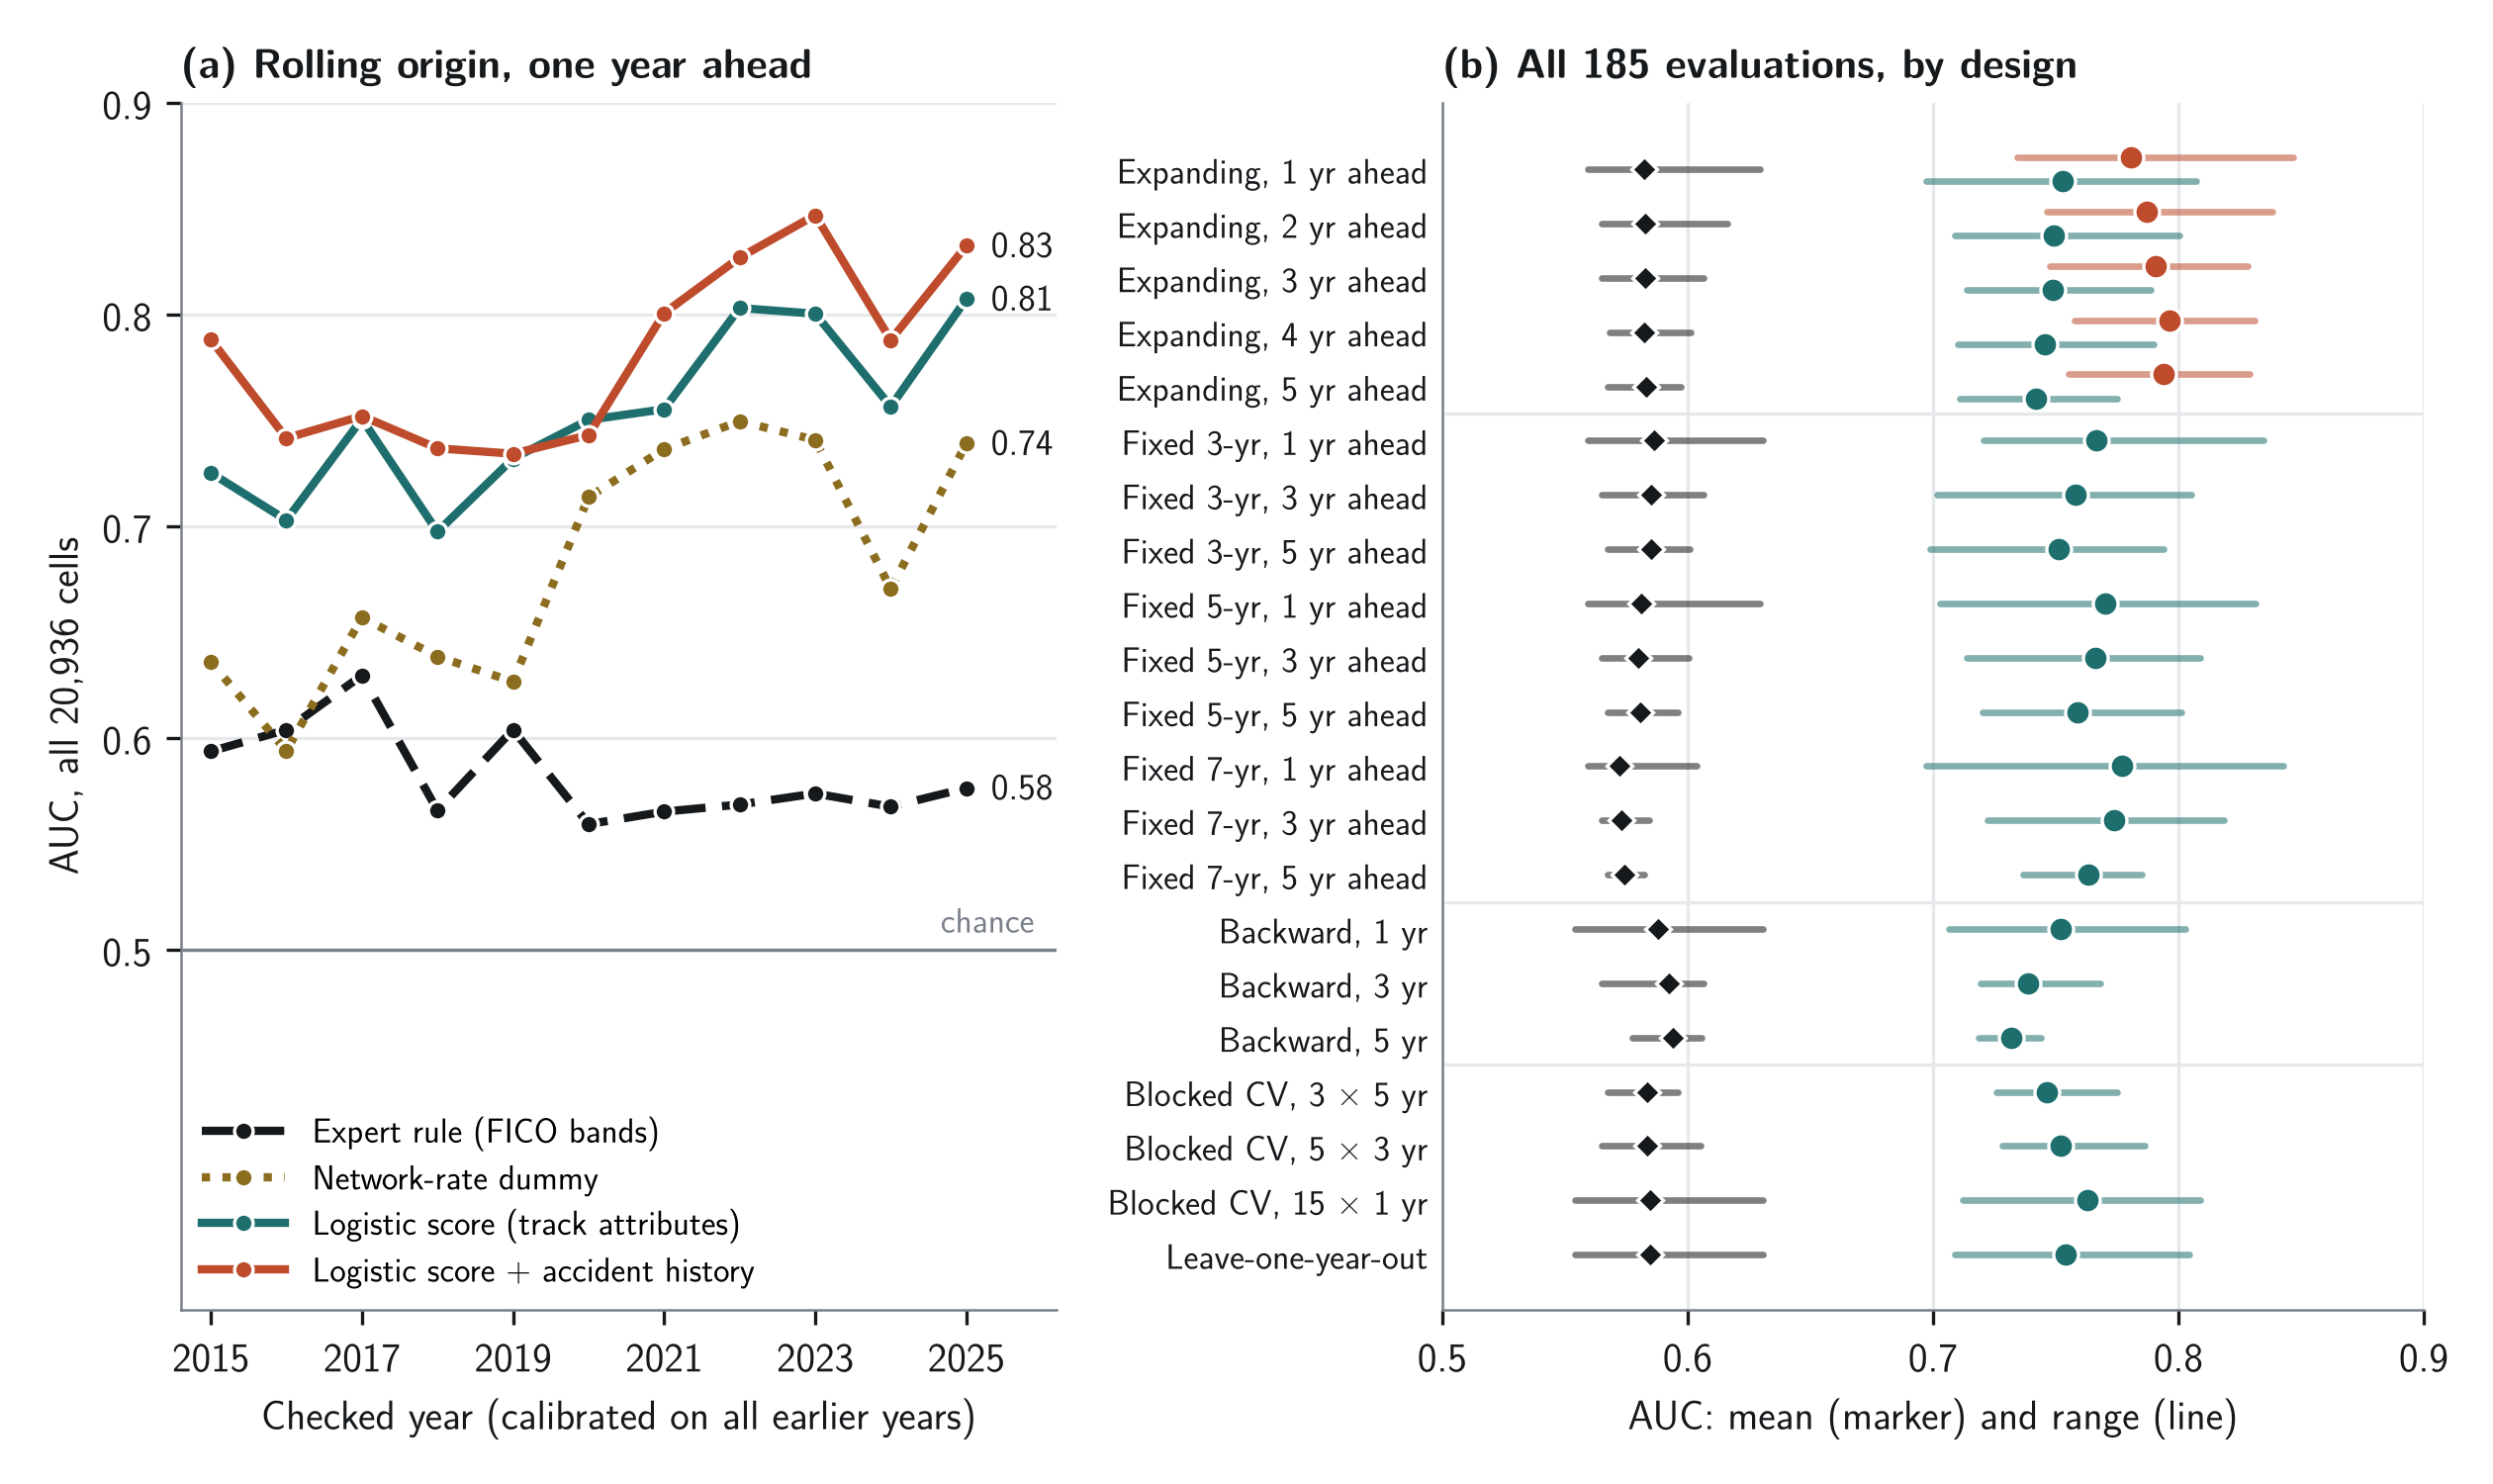

22_mapa_particao_temporal.png


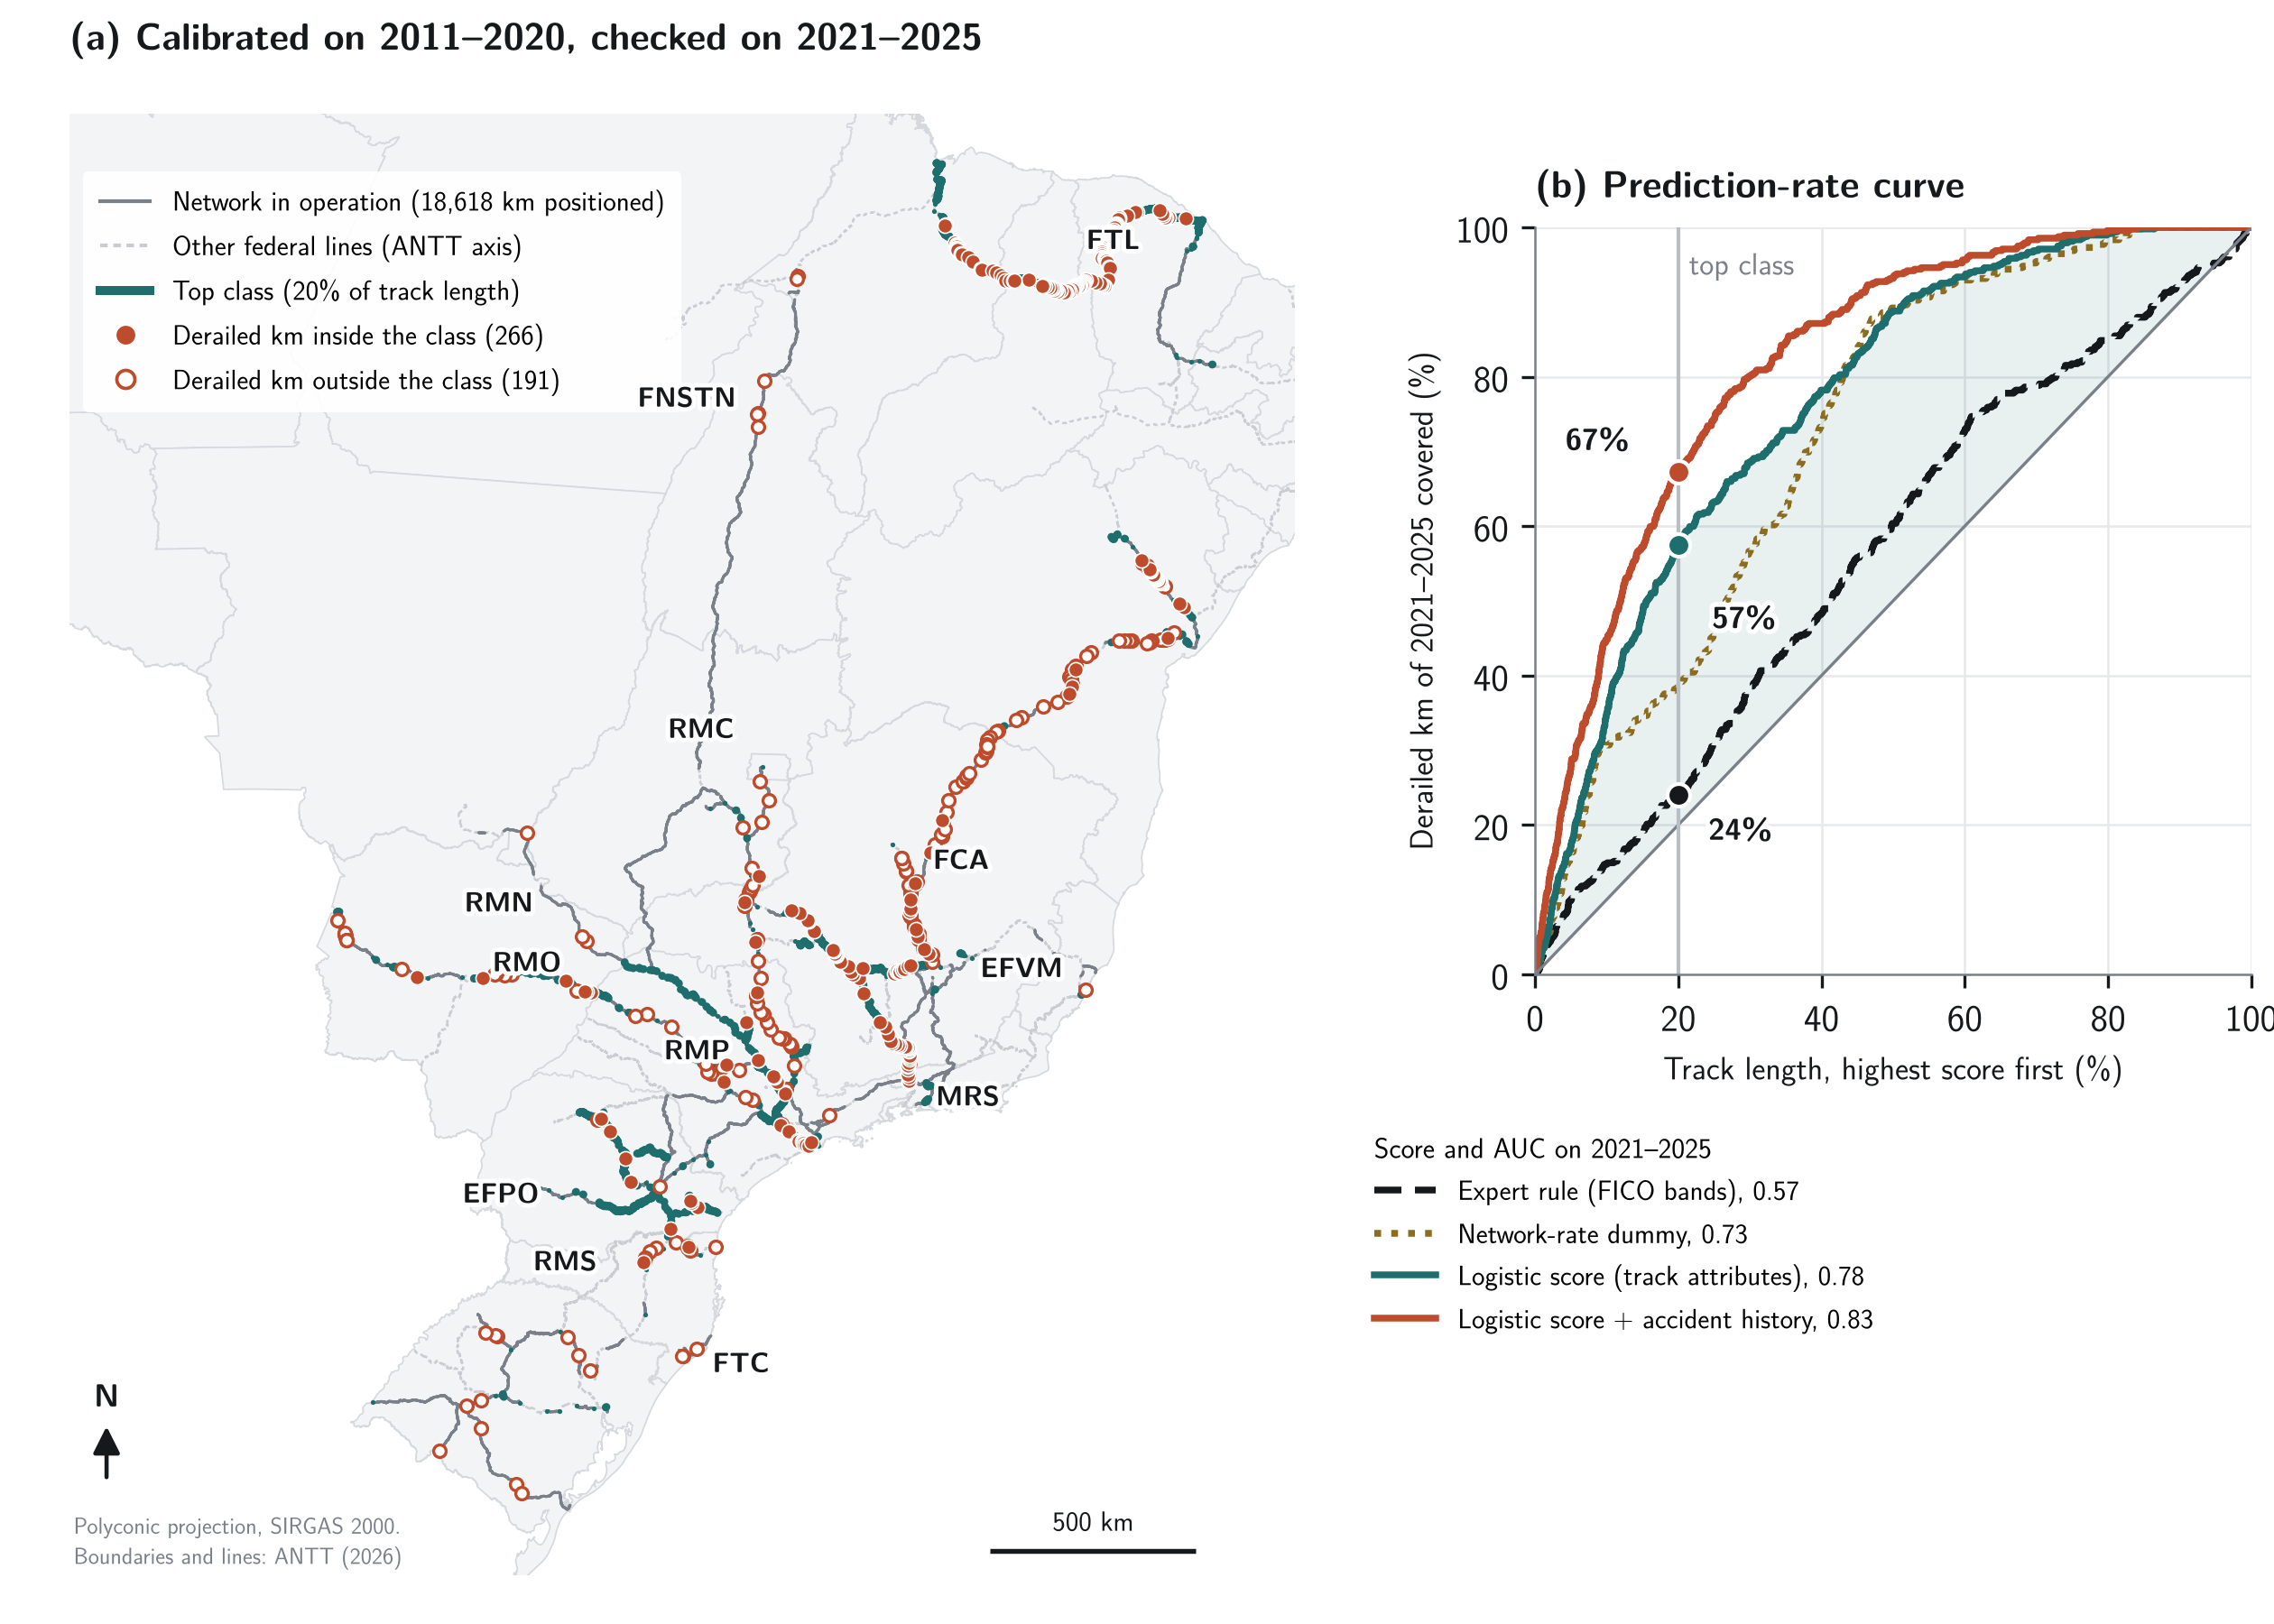

python 3.13.18 | matplotlib==3.11.2; numpy==2.5.3; pandas==3.0.5; scikit-learn==1.9.1; scipy==1.18.1
fim: 2026-11-23T00:35:24 | tempo total: 55.2 min


In [93]:
from IPython.display import Image, display as _d
for f in ("21_validacao_temporal.png", "22_mapa_particao_temporal.png"):
    print(f); _d(Image(f"{FIG}/{f}", width=900))
import subprocess
vers = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout.splitlines()
print("python", sys.version.split()[0], "|", "; ".join(v for v in vers if v.split("==")[0].lower() in ("numpy", "pandas", "scikit-learn", "scipy", "matplotlib")))
print("fim:", dt.datetime.now().isoformat(timespec="seconds"), "| tempo total:", round((time.time() - T0_GERAL) / 60, 1), "min")

---
## Limites desta sequência

Os atributos da via são os da Declaração de Rede de 2025 em todos os anos. O passo 9 (teste geral) mede se a nota vale para trechos não vistos, não se antecipa o futuro. As avaliações do passo 7 se sobrepõem no tempo e não são independentes. Os rótulos dos modelos de linguagem foram gravados em 15/11/2026 e aqui são só relidos; a versão exata e a temperatura dos modelos não foram controladas. O mapa mostra 88,9% das células, as que têm posição no eixo da ANTT.

**Declaração de uso de IA (regra da disciplina, três partes).** Ferramentas: Claude (Anthropic), usado pelo autor como assistente de programação a partir das especificações FOCUS registradas neste notebook, e Gemini do Colab quando indicado. Parte do trabalho: geração do código de cada passo e revisão do texto das células. Responsável pelo conteúdo: o autor, que definiu o problema, as fontes, as especificações, os gates e a verificação, e executou o notebook do zero antes de reportar qualquer número.